# Classifying albuminuria level (NORMAL – MICRO – MACRO) from paired albumin and creatinine micro-paper images

**Notebook:** `UACR_Pipeline.ipynb` — one dataset, two analysis pipelines, one comparison.
Companion code of the article *“Enabling AI on a Paper-Based Point-of-Care Device for UACR: Classical Machine Learning versus Deep Learning on Micropad Images”* (see the repository `README.md` and `CITATION.cff`).

**Research question.** Can the UACR category (NORMAL – MICRO – MACRO) be classified from a pair of micro-paper images (albumin assay + creatinine assay), and which way of reading the images is better: hand-crafted colour/texture features with five machine-learning models (**Path A**), or convolutional neural networks that read the pixels (**Path B**)?

## Organisation

| Part | Stages | Content |
|---|---|---|
| I · Shared foundation | 1–6 | environment, image inventory and pairing, labels, shared image module (ROI detection and feature extraction), feature catalogue |
| I · Exploration and cleansing | 7–9 | EDA, data cleansing, common analysis set and the grouped fold plan used by **both** paths |
| II · Path A (classical ML) | 11–16 | measurement-quality audit, feature selection, five models, repeated nested CV, analysis of the selected model, deployment bundle |
| III · Path B (CNN) | 17–27 | image tensors, frozen embeddings, fine-tuning, comparison with Path A, interpretation (Grad-CAM, perturbation) |
| IV · Comparison | 28–30 | unified leaderboard, error overlap, decision rule |

Both paths are evaluated on the **same tests, the same samples and the same cross-validation folds** (sample-grouped, class-stratified, 5 × 2 nested CV, macro-F1 as primary metric).

## How to run

1. Place the data as described in `data/README.md` (images + label table) and, optionally, set `UACR_DATA_DIR`.
2. Install `requirements.txt`. A GPU is needed for Part III (CNN fine-tuning); Parts I, II and IV run on CPU.
3. *Run all.* Intermediate results are cached in `outputs/`, so an interrupted run resumes where it stopped.
4. `UACR_FAST=1` runs a drastically reduced configuration (tiny images, few epochs, no pretrained weights) that only checks that the code runs end-to-end — **its numbers are not reportable**.

> This is a research prototype. It is not a validated medical device and must not be used for clinical decisions.

> **About the outputs in this file.** Figures and tables shown here were produced by the reported run of the original working notebook (full dataset). This version differs from the original only in path handling, removal of legacy-cache and manuscript-helper cells, and the output folder name (`outputs/`). The cleaned code was re-executed end-to-end only in fast smoke-test mode; to regenerate the numbers run `UACR_Pipeline.ipynb` on the full dataset. Outputs that displayed free-text source notes with patient identifiers were removed.


# Stage 1 · Environment Setup and Data *Mounting*

**Purpose.** Prepare the libraries, the global parameters, the GPU, the connection to Google Drive and the **output scopes**.

**How it works.** All parameters live in one dictionary `CFG` (documented in the report and saved in every output scope). One seed (42) controls the folds and, through derived seeds, the network initialisation and the mini-batch order. GPU kernels are not bit-wise deterministic, so repeated Path-B runs may differ in the third decimal.

**Output scopes.** Results are written to **`outputs/`** with four sub-folders — `0_Shared`, `A_ML`, `B_CNN`, `C_Comparison` — each containing `figures`, `tables`, `model`, `report` and `cache`. A scope is selected with `use_scope('S' | 'A' | 'B' | 'C')`; it redirects `save_fig`, `save_table`, `put` (the numbers registry) and all cache/model paths. On Colab, results are first written to the local disk (fast and safe if the Drive mount drops) and copied to the data folder on Drive after every major stage; at start-up anything already saved there is restored, which is what makes the notebook resumable. Locally, the folder `outputs/` is used directly.

In [2]:
import os, sys, re, json, math, time, glob, hashlib, warnings, subprocess, importlib, random, shutil, platform, datetime
from pathlib import Path
warnings.filterwarnings('ignore')
T_NOTEBOOK_START = time.time()

def _ensure(pkg, mod):
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f'Installing {pkg} ...')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)

for _pkg, _mod in [('scikit-image', 'skimage'), ('opencv-python-headless', 'cv2'), ('openpyxl', 'openpyxl'),
                   ('seaborn', 'seaborn'), ('tqdm', 'tqdm'), ('joblib', 'joblib')]:
    _ensure(_pkg, _mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy import stats as sps
from scipy.stats import rankdata
from joblib import Parallel, delayed, dump, load
from tqdm.auto import tqdm
from IPython.display import display, Markdown

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, label_binarize
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest, RandomForestRegressor, GradientBoostingClassifier
try:
    from sklearn.ensemble import HistGradientBoostingClassifier
except Exception:
    HistGradientBoostingClassifier = None
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, GroupKFold, learning_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score, roc_curve, auc,
                             confusion_matrix, classification_report, r2_score, silhouette_score)

import torch
import torch.nn as nn
import torch.nn.functional as Fn          # (named Fn because the variable F is used for ANOVA statistics in Path A)
import torchvision

SEED = 42

CFG = dict(
    # ---- files
    EXCEL_NAME   = os.environ.get('UACR_LABEL_FILE', 'UACR_labels_deidentified.xlsx'),   # label table (see data/README.md)
    SHEET_NAME   = 'Data Sampel',
    ID_COL       = 'No Sampel',
    LABEL_COL    = 'Label Kelas',            # class-label column
    MANUAL_ROOT  = '',                       # optional: folder with the images and the label table (otherwise see find_root())
    IMG_EXT      = ('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'),
    CLASS_ORDER  = ['NORMAL', 'MICRO', 'MACRO'],   # ordinal order (English class names)
    LABEL_MAP    = {'MIKRO': 'MICRO', 'MAKRO': 'MACRO'},   # the label table uses the Indonesian names; they are translated when the labels are read
    # ---- ROI preprocessing (shared by both paths; also stored in the deployment bundle)
    BG_DIST        = 18.0,    # minimum colour distance (BGR) from the background for a pixel to count as ROI
    ROI_ERODE_FRAC = 0.10,    # ROI edge erosion (fraction of the radius) to remove edge artefacts
    MAX_SIDE       = 512,     # maximum side of the ROI image used for feature computation (efficiency)
    SPEC_V         = 0.985,   # threshold for specular pixels (high V & low S) that are excluded
    SPEC_S         = 0.10,
    USE_CACHE      = True,
    # ---- validation (the SAME numbers for both paths)
    OUTER_FOLDS    = 5,
    OUTER_REPEATS  = 2,
    INNER_FOLDS    = 3,
    BOOT_N         = 1000,    # cluster-bootstrap resamples
    # ---- Path A: cleansing, selection, robustness
    ICC_MIN        = 0.50,    # minimum repeat-to-repeat reliability
    CORR_THR       = 0.90,    # redundancy filter (features with |r| above this are dropped)
    K_GRID         = [5, 10, 20],   # number of selected features tried inside every tuning loop
    CURVE_FOLDS    = 5,       # folds for the descriptive k-curve and the ablations
    DIAG_REPS      = 3,       # repetitions of the grouped CV in the measurement-quality audit
    SEED_SENS_N    = 5,       # extra nested-CV runs with different outer-split seeds for the selected model
    PERM_N         = 100,     # label permutations for the permutation test
    ABL_REPEATS    = 3,       # repetitions for the ablation analyses
    ABSTAIN_MIN_COVERAGE = 0.60,   # minimum share of samples that must receive a decision when choosing the 'UNCERTAIN' threshold
    # ---- Path B: network input and backbones (torchvision, ImageNet weights)
    IMG_SIZE     = 224,
    BACKBONES    = ['resnet18', 'efficientnet_b0', 'mobilenet_v3_large', 'convnext_tiny'],
    PRETRAINED   = True,                    # False = random initialisation (only for offline smoke tests)
    # ---- Path B: pre-specified fine-tuning recipe (Strategy B)
    EPOCHS       = 15,
    BATCH        = 32,
    LR_BACKBONE  = 1e-4,
    LR_HEAD      = 1e-3,
    WEIGHT_DECAY = 1e-2,
    WARMUP_EPOCHS= 1,
    LABEL_SMOOTH = 0.1,
    DROPOUT      = 0.3,
    AUG_BRIGHT   = 0.03,
    FREEZE_BN    = True,
    INCLUDE_SCRATCH = True,                 # a tiny CNN trained from scratch (lower bound)
    # ---- Path B: Strategy A (frozen embeddings)
    EMB_PCA      = [8, 16, 32],
    EMB_C        = [0.01, 0.1, 1.0],
    OUTER_REPEATS_CNN = 2,                  # repeats evaluated for the CNN (<= OUTER_REPEATS; the first repeats are used)
    GRADCAM_PER_CLASS = 2,
    FINAL_FIT    = True,
    FAST_MODE    = bool(int(os.environ.get('UACR_FAST', '0'))),   # 1 = trimmed grids, tiny images, few epochs (smoke test only)
)
if CFG['FAST_MODE']:
    CFG.update(K_GRID=[5, 10], OUTER_REPEATS=1, DIAG_REPS=2, SEED_SENS_N=2, PERM_N=20, ABL_REPEATS=1, BOOT_N=300,
               IMG_SIZE=64, BACKBONES=['resnet18', 'mobilenet_v3_large'], PRETRAINED=False, EPOCHS=2, OUTER_REPEATS_CNN=1,
               EMB_PCA=[8], EMB_C=[0.1], GRADCAM_PER_CLASS=1)
CFG['OUTER_REPEATS_FINAL'] = CFG['OUTER_REPEATS']        # name used by the Path-B code for "repeats of the common fold plan"
assert CFG['OUTER_REPEATS_CNN'] <= CFG['OUTER_REPEATS']

CLASSES   = CFG['CLASS_ORDER']
CLASS2ID  = {c: i for i, c in enumerate(CLASSES)}
COLORS    = {'NORMAL': '#2E7D32', 'MICRO': '#F9A825', 'MACRO': '#C62828'}
PALETTE   = [COLORS[c] for c in CLASSES]
SRC_COL   = {'Albumin': '#1565C0', 'Creatinine': '#EF6C00', 'Cross-image': '#2E7D32'}
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11, 'savefig.bbox': 'tight'})

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)

print('Python        :', sys.version.split()[0])
print('numpy/pandas  :', np.__version__, '/', pd.__version__)
print('scikit-learn  :', sklearn.__version__, '| OpenCV:', cv2.__version__)
print('torch / vision:', torch.__version__, '/', torchvision.__version__)
print('Device        :', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU only', '| AMP:', USE_AMP)
if DEVICE.type == 'cpu' and not CFG['FAST_MODE']:
    print('NOTE: no GPU detected. Parts I, II and IV run on CPU, but Part III (CNN fine-tuning) will be extremely slow. In Colab: Runtime > Change runtime type > T4 GPU.')
print('Fast mode     :', CFG['FAST_MODE'], '(must be False for reportable results)')

Python        : 3.13.16
numpy/pandas  : 2.1.3 / 2.2.3
scikit-learn  : 1.6.1 | OpenCV: 5.0.0
torch / vision: 2.11.0+cu130 / 0.26.0+cu130
Device        : cuda | Tesla T4 | AMP: True
Fast mode     : False (must be False for reportable results)


In [3]:
# ---------- Mounting (Colab) / local path (Jupyter) ----------
IN_COLAB = False
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    print('Not Google Colab -> using local paths.')

if IN_COLAB:
    drive.mount('/content/drive')   # click 'Connect to Google Drive' -> choose account -> 'Allow'; do not interrupt this cell
    if not os.path.isdir('/content/drive/MyDrive'):
        raise RuntimeError('Google Drive is not mounted. Re-run this cell and allow access in the window that appears.')

def ensure_drive():
    """Reconnect the Drive if the connection (FUSE) drops in the middle of a run."""
    if IN_COLAB and not os.path.isdir(ROOT):
        print('Drive connection lost -> reconnecting ...')
        drive.mount('/content/drive', force_remount=True)

def _bounded_find(base, name, max_depth=4):
    """Look for the file `name` below `base` with limited depth (fast; does not scan the whole My Drive)."""
    base = Path(base)
    if not base.exists():
        return None
    base_depth = len(base.parts)
    for dp, dn, fn in os.walk(base):
        if name in fn:
            return Path(dp)
        if len(Path(dp).parts) - base_depth >= max_depth:
            dn[:] = []
    return None

def find_root():
    cands = []
    if CFG['MANUAL_ROOT']:
        cands.append(Path(CFG['MANUAL_ROOT']))
    if os.environ.get('UACR_DATA_DIR'):
        cands.append(Path(os.environ['UACR_DATA_DIR']))
    if IN_COLAB:
        my = Path('/content/drive/MyDrive')
        cands += [my / 'UACR', my]
    cands += [Path.cwd() / 'data', Path.cwd().parent / 'data', Path.cwd()]
    for c in cands:
        hit = _bounded_find(c, CFG['EXCEL_NAME'])
        if hit is not None:
            return hit
    raise FileNotFoundError(f'Label file {CFG["EXCEL_NAME"]} not found. Put it (with the images) in ./data, set the environment variable '
                            'UACR_DATA_DIR, or set CFG["MANUAL_ROOT"]. See data/README.md.')

ROOT       = find_root()
EXCEL_PATH = ROOT / CFG['EXCEL_NAME']

# ---------- Output scopes ----------
OUT_ROOT_NAME = 'outputs'
DRIVE_ROOT = Path(os.environ.get('UACR_OUT_DIR', ROOT / OUT_ROOT_NAME)) if not IN_COLAB else ROOT / OUT_ROOT_NAME   # final destination (Drive on Colab)
TEMP_ROOT  = Path(f'/content/{OUT_ROOT_NAME}') if IN_COLAB else DRIVE_ROOT
SCOPES = {'S': ('0_Shared',     'Part I - shared data foundation'),
          'A': ('A_ML',         'Part II - Path A: hand-crafted features + machine learning'),
          'B': ('B_CNN',        'Part III - Path B: convolutional neural networks'),
          'C': ('C_Comparison', 'Part IV - comparison and synthesis')}
SCOPE_PATH = {s: TEMP_ROOT / d for s, (d, _) in SCOPES.items()}
DRIVE_PATH = {s: DRIVE_ROOT / d for s, (d, _) in SCOPES.items()}
for _s in SCOPES:
    for _sub in ('figures', 'tables', 'model', 'report', 'cache'):
        (SCOPE_PATH[_s] / _sub).mkdir(parents=True, exist_ok=True)

def _copy_tree_incremental(src, dst):
    """Copy only new or changed files (size / modification time), so that repeated synchronisation is cheap."""
    n = 0
    for p in Path(src).rglob('*'):
        if p.is_file():
            q = Path(dst) / p.relative_to(src)
            if (not q.exists()) or q.stat().st_size != p.stat().st_size or q.stat().st_mtime + 2 < p.stat().st_mtime:
                q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n += 1
    return n

def sync_to_drive(verbose=True):
    """Copy the local results folder to Drive. A failure does not stop the notebook."""
    try:
        if TEMP_ROOT.resolve() == DRIVE_ROOT.resolve():
            return
        ensure_drive()
        n = _copy_tree_incremental(TEMP_ROOT, DRIVE_ROOT)
        if verbose: print(f'Results copied to Drive: {DRIVE_ROOT} ({n} new/changed files)')
    except Exception as e:
        print('Copy to Drive postponed (', repr(e)[:120], ') -> results remain safe in', TEMP_ROOT)

# resume support: bring back everything that an earlier (disconnected) session already saved on Drive
try:
    if TEMP_ROOT.resolve() != DRIVE_ROOT.resolve() and DRIVE_ROOT.exists():
        n_back = _copy_tree_incremental(DRIVE_ROOT, TEMP_ROOT)
        print(f'Restored {n_back} files from Drive (earlier session):', DRIVE_ROOT)
except Exception as e:
    print('Could not restore earlier results (ignored):', repr(e)[:100])

IMG_FILES = sorted(p for p in ROOT.rglob('*')
                   if p.suffix.lower() in CFG['IMG_EXT'] and re.search(r'(albumin|creatinin|kreatinin)', p.name, re.I)
                   and OUT_ROOT_NAME not in p.parts)
IMG_BY_NAME = {p.name: p for p in IMG_FILES}

print('Data folder          :', ROOT)
print('Excel file           :', EXCEL_PATH.name)
print('Output (temporary)   :', TEMP_ROOT, '| final destination:', DRIVE_ROOT)
print('Image files detected :', len(IMG_FILES))

# ---------- Numbers registry, figure/table registries (one set per scope) ----------
def _jsonable(o):
    if isinstance(o, dict):  return {str(k): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)): return [_jsonable(v) for v in o]
    if isinstance(o, np.ndarray): return _jsonable(o.tolist())
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (np.floating,)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, float): return None if not np.isfinite(o) else o
    if isinstance(o, (pd.Series,)): return _jsonable(o.to_dict())
    if isinstance(o, (pd.DataFrame,)): return _jsonable(o.to_dict(orient='list'))
    if isinstance(o, (Path,)): return str(o)
    return o

REG = {s: dict(fig=[], tab=[], num={}) for s in SCOPES}
SCOPE = None

def put(path, value):
    """put('nested.best_model', 'SVM') -> NUM['nested']['best_model'] = 'SVM' (NUM = numbers registry of the active scope)"""
    d = NUM; parts = path.split('.')
    for p_ in parts[:-1]:
        d = d.setdefault(p_, {})
    d[parts[-1]] = _jsonable(value)

def dump_numbers():
    (REPORT_DIR / 'report_numbers.json').write_text(json.dumps(NUM, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
    allnum = {s: REG[s]['num'] for s in SCOPES if REG[s]['num']}
    (TEMP_ROOT / 'report_numbers_all.json').write_text(json.dumps(allnum, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

def use_scope(s):
    """Redirect all output helpers (figures, tables, numbers, caches, model folder) to scope s: 'S', 'A', 'B' or 'C'."""
    global SCOPE, OUT_DIR, DRIVE_OUT, FIG_DIR, TAB_DIR, MODEL_DIR, REPORT_DIR, CACHE_DIR, FIG_REG, TAB_REG, NUM
    SCOPE = s
    OUT_DIR, DRIVE_OUT = SCOPE_PATH[s], DRIVE_PATH[s]
    FIG_DIR, TAB_DIR, MODEL_DIR, REPORT_DIR, CACHE_DIR = [OUT_DIR / d for d in ('figures', 'tables', 'model', 'report', 'cache')]
    FIG_REG, TAB_REG, NUM = REG[s]['fig'], REG[s]['tab'], REG[s]['num']
    if not NUM:
        put('environment', dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__, torch=torch.__version__,
                                torchvision=torchvision.__version__, device=str(DEVICE), gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
                                platform=platform.platform(), colab=IN_COLAB, fast_mode=CFG['FAST_MODE'], started=datetime.datetime.now().isoformat(timespec='seconds')))
        put('config', {k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()})
    display(Markdown(f'**Output scope → `{OUT_DIR.name}`** — {SCOPES[s][1]} (figures and tables are numbered {s}1, {s}2, …)'))

def save_fig(fig, name, caption):
    n = len(FIG_REG) + 1
    path = FIG_DIR / f'Fig{SCOPE}{n:02d}_{name}.png'
    fig.savefig(path, dpi=300, bbox_inches='tight')
    FIG_REG.append(dict(number=f'{SCOPE}{n}', file=path.name, caption=caption))
    plt.show()
    display(Markdown(f'**Figure {SCOPE}{n}.** {caption}'))

def save_table(df, name, caption, index=True, show=True, max_rows=60):
    n = len(TAB_REG) + 1
    path = TAB_DIR / f'Tab{SCOPE}{n:02d}_{name}.csv'
    df.to_csv(path, index=index, encoding='utf-8-sig')
    TAB_REG.append(dict(number=f'{SCOPE}{n}', file=path.name, caption=caption))
    display(Markdown(f'**Table {SCOPE}{n}.** {caption}'))
    if show:
        display(df.head(max_rows) if len(df) > max_rows else df)
    return n

STAGE_T = {}
def stage_done(name):
    STAGE_T[name] = round(time.time() - T_NOTEBOOK_START, 1)
    put('runtime.cumulative_seconds_at_end_of_stage', STAGE_T); dump_numbers()

use_scope('S')


Mounted at /content/drive
Restored 131 files from Drive (earlier session): data 2026/outputs
Data folder          : data 2026
Excel file           : Data_Sampel_Penelitian_UACR_With_Label.xlsx
Output (temporary)   : /content/outputs | final destination: data 2026/outputs
Image files detected : 1002


**Output scope → `0_Shared`** — Part I - shared data foundation (figures and tables are numbered S1, S2, …)

Workflow figure saved: /content/outputs/0_Shared/figures/Workflow_two_pipelines.png


# Stage 2 · Image Inventory and Albumin–Creatinine Pairing

**Purpose.** Parse the file names into structured metadata, then pair the albumin and creatinine images that come from the same test.

**Naming scheme** `NNN_LUX_SAMPLE_Assay_HighRes.ext`:

| Segment | Meaning |
|---|---|
| `NNN` | test sequence number (`seq`) |
| `LUX` | illumination when the image was taken (lux) |
| `SAMPLE` | sample number (key that links to the Excel column *No Sampel*) |
| `Albumin` / `Creatinin` | assay type → role `alb` / `cre` |
| `HighRes` | ignored |

A test pair is identified by the key `(seq, sample)`. Incomplete pairs (only one of the two images) are reported and excluded, because cross-image features need both. Because **one sample is tested more than once**, the number of repeats per sample must be inspected, since it determines the *splitting* strategy later.

In [4]:
FN_RE = re.compile(r'^(?P<seq>\d+)_(?P<lux>\d+(?:\.\d+)?)_(?P<sample>\d+)_(?P<assay>[A-Za-z]+)', re.I)

rows, bad_names = [], []
for p in IMG_FILES:
    m = FN_RE.match(p.stem)
    if not m:
        bad_names.append(p.name); continue
    a = m['assay'].lower()
    role = 'alb' if a.startswith('alb') else ('cre' if a.startswith(('cre', 'kre')) else None)
    if role is None:
        bad_names.append(p.name); continue
    rows.append(dict(seq=int(m['seq']), lux=float(m['lux']), sample=int(m['sample']), role=role, path=str(p), name=p.name))

df_files = pd.DataFrame(rows)
print(f'Files parsed: {len(df_files)} | failed to parse: {len(bad_names)}')
if bad_names:
    print('Examples of names that do not match the pattern:', bad_names[:5])

dup_key = df_files.duplicated(['seq', 'sample', 'role'], keep=False)
if dup_key.any():
    print(f'WARNING: {dup_key.sum()} files share the same (seq, sample, role) key; only the first is used.')
    display(df_files[dup_key].sort_values(['seq', 'sample', 'role']).head(10))
    df_files = df_files.drop_duplicates(['seq', 'sample', 'role'], keep='first')

alb = df_files[df_files.role == 'alb'].drop(columns='role')
cre = df_files[df_files.role == 'cre'].drop(columns='role')
pairs = alb.merge(cre, on=['seq', 'sample'], how='outer', suffixes=('_alb', '_cre'), indicator=True)

unpaired = pairs[pairs['_merge'] != 'both']
print(f'Complete pairs: {(pairs["_merge"] == "both").sum()} | incomplete: {len(unpaired)}')
if len(unpaired):
    display(unpaired[['seq', 'sample', 'name_alb', 'name_cre']].head(20))

df_pairs = pairs[pairs['_merge'] == 'both'].drop(columns='_merge').copy()
lux_gap = (df_pairs['lux_alb'] - df_pairs['lux_cre']).abs()
print(f'Lux difference albumin vs creatinine within pairs: max = {lux_gap.max():.2f} lux ({(lux_gap > 0.05).sum()} pairs differ)')
df_pairs['lux'] = df_pairs[['lux_alb', 'lux_cre']].mean(axis=1)
df_pairs = df_pairs.drop(columns=['lux_alb', 'lux_cre']).sort_values(['sample', 'seq']).reset_index(drop=True)

rep = df_pairs.groupby('sample').size()
inv = pd.DataFrame({
    'Parameter': ['Albumin image files', 'Creatinine image files', 'Complete test pairs', 'Unique samples',
                  'Repeats per sample (min / median / max)', 'Lux (min / mean / max)'],
    'Value': [len(alb), len(cre), len(df_pairs), df_pairs['sample'].nunique(),
              f'{rep.min()} / {rep.median():.0f} / {rep.max()}',
              f'{df_pairs.lux.min():.1f} / {df_pairs.lux.mean():.1f} / {df_pairs.lux.max():.1f}']})
save_table(inv, 'image_inventory', 'Summary of the micropad image dataset inventory.', index=False)
put('data.albumin_files', len(alb)); put('data.creatinine_files', len(cre)); put('data.failed_to_parse', len(bad_names)); put('data.incomplete_pairs', len(unpaired))
put('data.complete_pairs', len(df_pairs)); put('data.samples_with_images', df_pairs['sample'].nunique())
put('data.repeats_per_sample', dict(min=int(rep.min()), median=float(rep.median()), max=int(rep.max()), mean=float(rep.mean())))
put('data.repeats_distribution', rep.value_counts().sort_index().to_dict())
put('data.lux', dict(min=df_pairs.lux.min(), mean=df_pairs.lux.mean(), max=df_pairs.lux.max(), sd=df_pairs.lux.std(), cv_percent=df_pairs.lux.std() / df_pairs.lux.mean() * 100))

Files parsed: 1000 | failed to parse: 2
Examples of names that do not match the pattern: ['003_3533 (1).3_25_Creatinin_HighRes.PNG', '005_3533 (1).3_70_Creatinin_HighRes.PNG']


,seq,lux,sample,role,path,name
795,5,3485.0,58,alb,data 2026/Dataset/005_3...,005_3485.0_58_Albumin_HighRes.PNG
797,5,3486.7,58,alb,data 2026/Dataset/005_3...,005_3486.7_58_Albumin_HighRes.PNG
796,5,3485.0,58,cre,data 2026/Dataset/005_3...,005_3485.0_58_Creatinin_HighRes.PNG
798,5,3486.7,58,cre,data 2026/Dataset/005_3...,005_3486.7_58_Creatinin_HighRes.PNG


Complete pairs: 497 | incomplete: 4


,seq,sample,name_alb,name_cre
27,1,29,NaN,001_3630.0_29_Creatinin_HighRes.PNG
397,5,7,NaN,005_3543.3_7_Creatinin_HighRes.PNG
494,10,7,010_3543.3_7_Albumin_HighRes.PNG,NaN
500,30,29,030_3630.0_29_Albumin_HighRes.PNG,NaN


Lux difference albumin vs creatinine within pairs: max = 0.00 lux (0 pairs differ)


**Table S1.** Summary of the micropad image dataset inventory.

,Parameter,Value
0,Albumin image files,499
1,Creatinine image files,499
2,Complete test pairs,497
3,Unique samples,100
4,Repeats per sample (min / median / max),4 / 5 / 5
5,Lux (min / mean / max),3369.2 / 3548.8 / 3705.0


# Stage 3 · Loading and Auditing the Label Data (Excel)

**Purpose.** Read the classification label from the **Data Sampel** sheet, column **Label Kelas**, clean the number formats, and audit the label quality.

**Class names.** The label table stores the labels in Indonesian (`NORMAL`, `MIKRO`, `MAKRO`); they are translated to the English names **NORMAL, MICRO, MACRO** at the moment they are read (`CFG['LABEL_MAP']`), so everything downstream — tables, figures, models, deployment bundle — uses the English names. The file itself is not modified. The public label table contains no names, record numbers or demographics; if present, those columns are ignored.

**Steps.**
1. Only rows with a numeric *No Sampel* are kept (summary/note rows at the bottom are dropped).
2. The numeric laboratory columns use a comma thousands separator (e.g. `1,461.54`); this format is normalised.
3. **Label consistency audit:** the label is re-derived from the Cobas UACR using the KDIGO thresholds (< 30 → NORMAL; 30–300 → MICRO; > 300 → MACRO) and compared with **Label Kelas**. Differences point to possible labelling errors.
4. **Near-threshold analysis:** how many samples have a laboratory UACR so close to 30 or 300 mg/g that even a perfect measurement error of a few tens of percent could flip the class? This quantifies the intrinsic ambiguity of the target.
5. The *Kelompok* column (Albuminuria/Normal) is **not** the target; it has only two categories and therefore does not separate MICRO from MACRO.

**Methodological warning.** Laboratory albumin, creatinine and UACR values are used **only for auditing and validation** — they are not model features, because the label is a direct function of UACR (target leakage).

In [5]:
xl = pd.ExcelFile(EXCEL_PATH)
sheet = CFG['SHEET_NAME'] if CFG['SHEET_NAME'] in xl.sheet_names else None
if sheet is None:
    for s in xl.sheet_names:
        cols = [str(c).strip() for c in xl.parse(s, nrows=1).columns]
        if CFG['LABEL_COL'] in cols:
            sheet = s; break
print('Available sheets:', xl.sheet_names, '-> used:', sheet)

raw = xl.parse(sheet)
raw.columns = [str(c).strip() for c in raw.columns]
assert CFG['LABEL_COL'] in raw.columns, f'Column {CFG["LABEL_COL"]} not found. Columns: {list(raw.columns)}'
print('Label column position (Excel letter):', chr(ord("A") + list(raw.columns).index(CFG['LABEL_COL'])))

lab = raw[pd.to_numeric(raw[CFG['ID_COL']], errors='coerce').notna()].copy()
lab['sample'] = pd.to_numeric(lab[CFG['ID_COL']]).astype(int)

def find_col(df, pattern):
    for c in df.columns:
        if re.search(pattern, c, re.I):
            return c
    return None

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(',', '', regex=False).str.replace('>=', '', regex=False)
                          .str.replace('<', '', regex=False).str.strip(), errors='coerce')

# the patterns below match the (Indonesian) column names of the Excel file
colmap = {'alb_mgL': r'^Albumin Urin', 'cre_mgdL': r'^Kreatinin Urin', 'uacr': r'^UACR Cobas', 'scr': r'^Kreatinin Serum',
          'egfr': r'^eGFR', 'age_raw': r'^Usia', 'sex': r'^JK', 'group': r'^Kelompok'}
for new, pat in colmap.items():
    c = find_col(lab, pat)
    lab[new] = (lab[c] if new in ('age_raw', 'sex', 'group') else to_num(lab[c])) if c else np.nan

lab['age'] = pd.to_numeric(lab['age_raw'].astype(str).str.extract(r'(\d+)\s*(?:th|Y)', flags=re.I)[0], errors='coerce')
lab['label'] = lab[CFG['LABEL_COL']].astype(str).str.strip().str.upper().replace(CFG['LABEL_MAP'])   # Excel: MIKRO/MAKRO -> MICRO/MACRO
unk = set(lab['label']) - set(CLASSES)
assert not unk, f'Unknown labels: {unk}'
lab['y'] = lab['label'].map(CLASS2ID)

# audit of label consistency vs UACR thresholds (KDIGO)
def uacr_class(v):
    if pd.isna(v): return np.nan
    return 'NORMAL' if v < 30 else ('MICRO' if v <= 300 else 'MACRO')
lab['label_uacr'] = lab['uacr'].map(uacr_class)
mis = lab[(lab['label_uacr'].notna()) & (lab['label_uacr'] != lab['label'])]
agree = 1 - len(mis) / lab['label_uacr'].notna().sum()
print(f'Labelled samples: {len(lab)} | consistency of Label Kelas vs Cobas UACR thresholds: {agree * 100:.1f}% ({len(mis)} differ)')
if len(mis):
    display(mis[['sample', 'uacr', 'label', 'label_uacr']])

labels = lab[['sample', 'label', 'y', 'uacr', 'alb_mgL', 'cre_mgdL', 'scr', 'egfr', 'age', 'sex', 'group']].reset_index(drop=True)
labels['log10_uacr'] = np.log10(labels['uacr'].clip(lower=0.1))

cnt = labels['label'].value_counts().reindex(CLASSES)
tab_cnt = pd.DataFrame({'Number of samples': cnt, 'Proportion (%)': (cnt / cnt.sum() * 100).round(1)})
save_table(tab_cnt, 'class_distribution_samples', 'Class distribution at the sample level (classification target).')
put('labels.n_samples_in_excel', len(labels)); put('labels.class_counts', cnt.to_dict()); put('labels.consistency_with_uacr_percent', agree * 100)
put('labels.n_inconsistent', len(mis)); put('labels.inconsistent_samples', mis[['sample', 'uacr', 'label', 'label_uacr']].to_dict(orient='records'))

xt = pd.crosstab(labels['group'], labels['label']).reindex(columns=CLASSES)
xt.index.name = 'Clinical group (Kelompok)'
save_table(xt, 'group_vs_label', 'Cross-tabulation of the Kelompok column (Albuminuria/Normal) against Label Kelas; shows why Kelompok is not used as the target.')

notes = lab.loc[lab.get('Catatan', pd.Series(index=lab.index, dtype=object)).notna(), ['sample', 'Catatan']] if 'Catatan' in lab.columns else pd.DataFrame()
if len(notes):
    save_table(notes.rename(columns={'Catatan': 'Data-quality note in the source file'}), 'source_data_notes',
               'Data-quality notes recorded in the source file (copied verbatim from the PDF); they must be considered when interpreting results.', index=False, max_rows=40)
    put('labels.n_samples_with_source_notes', len(notes))

Available sheets: ['Data Sampel', 'Ringkasan', 'Catatan Data'] -> used: Data Sampel
Label column position (Excel letter): Q
Labelled samples: 100 | consistency of Label Kelas vs Cobas UACR thresholds: 100.0% (0 differ)


**Table S2.** Class distribution at the sample level (classification target).

,Number of samples,Proportion (%)
label,,
NORMAL,25,25.0
MICRO,25,25.0
MACRO,50,50.0


**Table S3.** Cross-tabulation of the Kelompok column (Albuminuria/Normal) against Label Kelas; shows why Kelompok is not used as the target.

label,NORMAL,MICRO,MACRO
Clinical group (Kelompok),,,
Albuminuria,2,18,50
Normal,23,7,0


**Table S4.** Data-quality notes recorded in the source file (copied verbatim from the PDF); they must be considered when interpreting results.

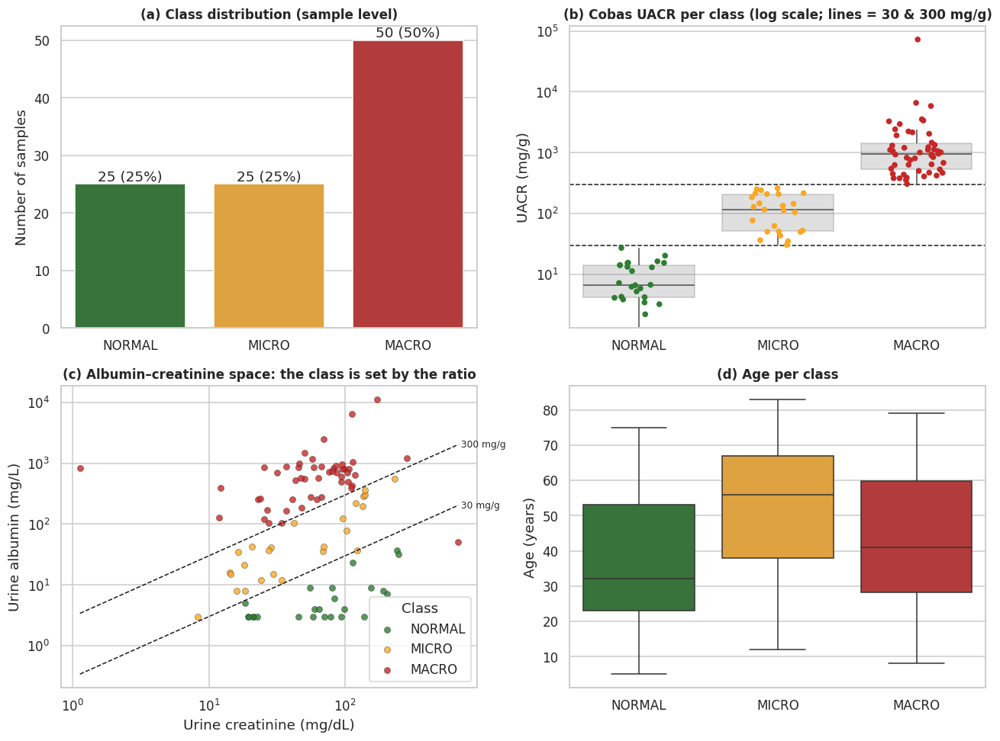

**Figure S1.** Label data audit: (a) class distribution, (b) UACR per class, (c) urine albumin–creatinine space with iso-UACR lines at 30 and 300 mg/g, (d) age distribution.

**Table S5.** Clinical-laboratory characteristics per class (median [Q1–Q3]) and Kruskal-Wallis test.

,Variable,NORMAL,MICRO,MACRO,p (Kruskal-Wallis)
0,UACR (mg/g),6.7 [4.2–14.1],115.4 [50.7–208.1],944.6 [533.2–1431.5],7.24e-19
1,Urine albumin (mg/L),4.0 [3.0–8.0],37.0 [15.0–123.0],670.5 [279.0–864.8],1.21e-16
2,Urine creatinine (mg/dL),70.5 [45.4–114.0],34.4 [18.5–120.0],62.8 [37.8–94.9],3.83e-01
3,eGFR,102.0 [79.4–122.7],80.7 [48.0–109.1],70.4 [25.0–102.0],5.21e-03
4,Age (years),32.0 [23.0–53.0],56.0 [38.0–67.0],41.0 [28.2–59.8],4.67e-02


**Table S6.** Share of samples whose laboratory UACR lies within a given distance (log10) of the 30 or 300 mg/g threshold. Samples inside these windows are intrinsically ambiguous: a small measurement error changes their class.

,Window (log10 units around a threshold),Equivalent fold-change,Samples inside the window,Share of samples (%)
0,±0.1,×/÷ 1.26,9,9.0
1,±0.2,×/÷ 1.58,24,24.0
2,±0.3,×/÷ 2.00,36,36.0
3,±0.5,×/÷ 3.16,61,61.0


In [6]:
# ---------- Visualisation of the label data ----------
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
sns.barplot(x=cnt.index, y=cnt.values, palette=PALETTE, ax=ax[0, 0])
for i, v in enumerate(cnt.values):
    ax[0, 0].text(i, v + 0.5, f'{v} ({v / cnt.sum() * 100:.0f}%)', ha='center')
ax[0, 0].set_title('(a) Class distribution (sample level)'); ax[0, 0].set_ylabel('Number of samples'); ax[0, 0].set_xlabel('')

sns.stripplot(data=labels, x='label', y='uacr', order=CLASSES, palette=PALETTE, jitter=0.2, size=5, ax=ax[0, 1])
sns.boxplot(data=labels, x='label', y='uacr', order=CLASSES, showcaps=False, boxprops=dict(alpha=.25), showfliers=False, ax=ax[0, 1], color='gray')
ax[0, 1].set_yscale('log'); ax[0, 1].axhline(30, ls='--', c='k', lw=1); ax[0, 1].axhline(300, ls='--', c='k', lw=1)
ax[0, 1].set_title('(b) Cobas UACR per class (log scale; lines = 30 & 300 mg/g)'); ax[0, 1].set_ylabel('UACR (mg/g)'); ax[0, 1].set_xlabel('')

d = labels.dropna(subset=['alb_mgL', 'cre_mgdL'])
d = d[(d.alb_mgL > 0) & (d.cre_mgdL > 0)]
for c in CLASSES:
    s = d[d.label == c]; ax[1, 0].scatter(s.cre_mgdL, s.alb_mgL, c=COLORS[c], label=c, s=28, alpha=.8, edgecolor='k', lw=.3)
xx = np.logspace(np.log10(d.cre_mgdL.min()), np.log10(d.cre_mgdL.max()), 50)
for u in (30, 300):
    ax[1, 0].plot(xx, u * xx / 100, 'k--', lw=1); ax[1, 0].text(xx[-1], u * xx[-1] / 100, f' {u} mg/g', fontsize=8, va='center')
ax[1, 0].set_xscale('log'); ax[1, 0].set_yscale('log'); ax[1, 0].legend(title='Class')
ax[1, 0].set_xlabel('Urine creatinine (mg/dL)'); ax[1, 0].set_ylabel('Urine albumin (mg/L)')
ax[1, 0].set_title('(c) Albumin–creatinine space: the class is set by the ratio')

if labels['age'].notna().any():
    sns.boxplot(data=labels.dropna(subset=['age']), x='label', y='age', order=CLASSES, palette=PALETTE, ax=ax[1, 1])
    ax[1, 1].set_title('(d) Age per class'); ax[1, 1].set_xlabel(''); ax[1, 1].set_ylabel('Age (years)')
else:   # the public label table contains no demographic columns -> show eGFR instead
    sns.boxplot(data=labels.dropna(subset=['egfr']), x='label', y='egfr', order=CLASSES, palette=PALETTE, ax=ax[1, 1])
    ax[1, 1].set_title('(d) eGFR per class'); ax[1, 1].set_xlabel(''); ax[1, 1].set_ylabel('eGFR (mL/min/1.73 m²)')
fig.tight_layout()
save_fig(fig, 'label_audit', 'Label data audit: (a) class distribution, (b) UACR per class, (c) urine albumin–creatinine space with iso-UACR lines at 30 and 300 mg/g, (d) age distribution (or eGFR when the public label table without demographics is used).')

# descriptive tests: do the classes differ on clinical variables (context information)?
desc = []
for var, nm in [('uacr', 'UACR (mg/g)'), ('alb_mgL', 'Urine albumin (mg/L)'), ('cre_mgdL', 'Urine creatinine (mg/dL)'), ('egfr', 'eGFR'), ('age', 'Age (years)')]:
    g = [labels.loc[labels.label == c, var].dropna() for c in CLASSES]
    row = {'Variable': nm}
    for c, v in zip(CLASSES, g):
        row[c] = f'{v.median():.1f} [{v.quantile(.25):.1f}–{v.quantile(.75):.1f}]' if len(v) else '-'
    try:
        row['p (Kruskal-Wallis)'] = f'{sps.kruskal(*g).pvalue:.2e}'
    except Exception:
        row['p (Kruskal-Wallis)'] = '-'
    desc.append(row)
save_table(pd.DataFrame(desc), 'clinical_descriptives', 'Clinical-laboratory characteristics per class (median [Q1–Q3]) and Kruskal-Wallis test.', index=False)

# ---------- near-threshold analysis: intrinsic ambiguity of the target ----------
dist_thr = labels['uacr'].dropna().map(lambda u: min(abs(np.log10(max(u, .1) / 30)), abs(np.log10(max(u, .1) / 300))))
near_rows = []
for w in (0.1, 0.2, 0.3, 0.5):
    near_rows.append({'Window (log10 units around a threshold)': f'±{w}', 'Equivalent fold-change': f'×/÷ {10 ** w:.2f}', 'Samples inside the window': int((dist_thr <= w).sum()),
                      'Share of samples (%)': round((dist_thr <= w).mean() * 100, 1)})
near_tab = pd.DataFrame(near_rows)
save_table(near_tab, 'near_threshold', 'Share of samples whose laboratory UACR lies within a given distance (log10) of the 30 or 300 mg/g threshold. Samples inside these windows are intrinsically ambiguous: a small measurement error changes their class.', index=False)
put('labels.near_threshold', {str(r['Window (log10 units around a threshold)']): dict(n=r['Samples inside the window'], percent=r['Share of samples (%)']) for r in near_rows})

# Stage 4 · Merging Images and Labels

**Purpose.** Link every image pair to its label through the sample number and make sure there are no orphan samples (images without a label or labels without images).

The output of this stage is `df_pairs` — one row per **test** (albumin–creatinine pair) — which is then enriched with image features in the next stages.

Samples with images but no label : []
Labelled samples without images  : []


**Table S7.** Unified image–label dataset: number of samples and tests (image pairs) per class.

,Samples,Tests,Median tests per sample,Mean lux
label,,,,
NORMAL,25.0,125.0,5.0,3535.2
MICRO,25.0,123.0,5.0,3559.5
MACRO,50.0,249.0,5.0,3550.3
Total,100.0,497.0,5.0,3548.8


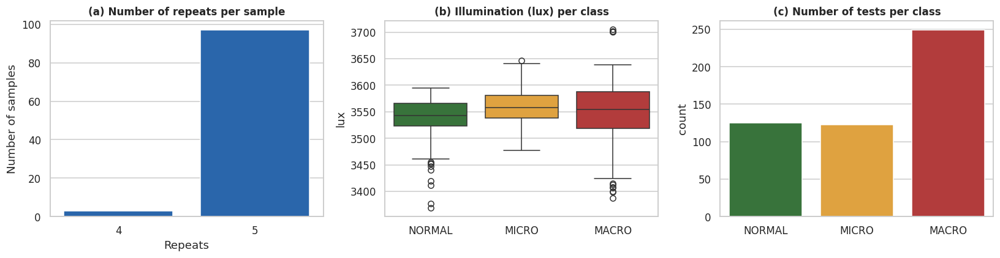

**Figure S2.** Characteristics of the unified dataset: (a) repeats per sample, (b) illumination per class, (c) number of tests per class.

Kruskal-Wallis test of lux across classes (sample level): H = 2.77, p = 0.25
-> No evidence that lux is confounded with the class (p >= 0.05).


In [7]:
img_samples, lab_samples = set(df_pairs['sample']), set(labels['sample'])
print('Samples with images but no label :', sorted(img_samples - lab_samples))
print('Labelled samples without images  :', sorted(lab_samples - img_samples))
put('data.samples_images_without_label', sorted(img_samples - lab_samples)); put('data.samples_label_without_images', sorted(lab_samples - img_samples))

df_pairs = df_pairs.merge(labels[['sample', 'label', 'y', 'uacr', 'log10_uacr']], on='sample', how='inner')
sm = df_pairs.groupby('sample').agg(label=('label', 'first'), n_tests=('seq', 'size'), lux_mean=('lux', 'mean')).reset_index()
tab = (sm.groupby('label').agg(samples=('sample', 'size'), tests=('n_tests', 'sum'), median_tests_per_sample=('n_tests', 'median'),
                               mean_lux=('lux_mean', 'mean')).reindex(CLASSES)).round(1)
tab.columns = ['Samples', 'Tests', 'Median tests per sample', 'Mean lux']
tab.loc['Total'] = [tab['Samples'].sum(), tab['Tests'].sum(), sm.n_tests.median(), df_pairs.lux.mean().round(1)]
save_table(tab, 'unified_dataset', 'Unified image–label dataset: number of samples and tests (image pairs) per class.')
put('data.after_merge', dict(samples=int(tab.loc['Total', 'Samples']), tests=int(tab.loc['Total', 'Tests'])))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='n_tests', data=sm, color='#1565C0', ax=ax[0]); ax[0].set_title('(a) Number of repeats per sample'); ax[0].set_xlabel('Repeats'); ax[0].set_ylabel('Number of samples')
sns.boxplot(data=df_pairs, x='label', y='lux', order=CLASSES, palette=PALETTE, ax=ax[1]); ax[1].set_title('(b) Illumination (lux) per class'); ax[1].set_xlabel('')
sns.countplot(x='label', data=df_pairs, order=CLASSES, palette=PALETTE, ax=ax[2]); ax[2].set_title('(c) Number of tests per class'); ax[2].set_xlabel('')
fig.tight_layout()
save_fig(fig, 'inventory', 'Characteristics of the unified dataset: (a) repeats per sample, (b) illumination per class, (c) number of tests per class.')

# is lux confounded with the class?
g = [sm.loc[sm.label == c, 'lux_mean'] for c in CLASSES]
H, p = sps.kruskal(*g)
put('data.lux_vs_class_kruskal', dict(H=H, p=p))
print(f'Kruskal-Wallis test of lux across classes (sample level): H = {H:.2f}, p = {p:.3g}')
print('-> ' + ('Lux differs significantly between classes: there is a risk of acquisition confounding; lux is NOT used as a feature and the features are colour-normalised.'
               if p < 0.05 else 'No evidence that lux is confounded with the class (p >= 0.05).'))

# Stage 5 · Shared Image-Analysis Module and ROI Detection

**Purpose.** Make sure the features are computed only from pixels that really lie inside the circular micropad ROI, free from background, edges and light reflections (*specular highlights*) — and make sure that **the study and the diagnosis device use exactly the same image-analysis code**.

**One source of truth.** The next cell contains the complete image-analysis code as a text block (`MODULE_SRC`). The notebook writes it to `outputs/0_Shared/model/uacr_features.py`, imports it, and uses it for every feature in this study; the very same file is shipped in the deployment bundle and imported by `uacr_inference.py`. A feature computed on the device therefore cannot differ from a feature used in training because of a code difference. Its SHA-256 is stored in the bundle.

**Algorithm `prepare_roi`** (automatic, no manual coordinates needed):
1. The image is read with `cv2.imdecode` (safe for Windows/Unicode paths). If it is RGBA with a transparent alpha channel, the alpha channel is used directly as the mask.
2. If there is no alpha channel, the background colour is estimated from the median of the frame-border pixels; pixels whose colour distance (BGR) from the background is > `BG_DIST` are treated as ROI. The mask is cleaned with morphological operations (*opening/closing*), the largest connected component is kept, and its holes are filled.
3. If the mask is implausible (< 5 % or > 97 % of the frame), the **largest circle inscribed in the frame** (`fallback_circle`) is used, which suits images that are already cropped exactly to the ROI.
4. The mask is **eroded** by `ROI_ERODE_FRAC` × radius to remove the circle edge (boundary effects and *halo*).
5. *Specular* pixels (very high brightness & very low saturation) are removed when their proportion is reasonable.
6. The ROI is cropped, downsized if a side exceeds `MAX_SIDE` (`INTER_AREA` interpolation), and the **largest square inscribed in the circle** is prepared specifically for texture features (so that GLCM/LBP are not contaminated by the mask edge).

The detection method and the ROI area are recorded per image for quality control.

In [8]:
MODULE_SRC = r'''"""
uacr_features.py - image analysis shared by the research notebook and the deployed device.

ONE source of truth: the notebook UACR_Integrated_Pipeline.ipynb writes this file, imports it, and uses it to extract
the features for the study; the very same file is shipped in the deployment bundle and used by uacr_inference.py.

Content
  read_image / detect_roi_mask / prepare_roi : circular-ROI detection and preprocessing
  image_features                              : 118 quantitative features of one ROI image
  process_pair                                : features of an albumin + creatinine image pair
                                                (alb__*, cre__*, and cross-image x__* features)
"""
import hashlib
import math

import cv2
import numpy as np
from scipy import ndimage as ndi
from scipy import stats as sps
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

MODULE_VERSION = "1.0"
EPS = 1e-6

DEFAULT_PARAMS = dict(BG_DIST=18.0, ROI_ERODE_FRAC=0.10, MAX_SIDE=512, SPEC_V=0.985, SPEC_S=0.10)


def _P(params):
    p = dict(DEFAULT_PARAMS)
    if params:
        p.update({k: params[k] for k in DEFAULT_PARAMS if k in params})
    return p


# ----------------------------------------------------------------------------------------------------------------
# ROI detection
# ----------------------------------------------------------------------------------------------------------------
def read_image(path):
    data = np.fromfile(str(path), dtype=np.uint8)
    img = cv2.imdecode(data, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise ValueError(f"Failed to read image: {path}")
    if img.dtype == np.uint16:
        img = (img / 257.0).astype(np.uint8)
    alpha = None
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    elif img.shape[2] == 4:
        alpha, img = img[..., 3], img[..., :3]
    return np.ascontiguousarray(img), alpha


def _largest_component(m):
    n, lab_, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    if n <= 1:
        return m
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    return lab_ == k


def detect_roi_mask(bgr, alpha=None, params=None):
    P = _P(params)
    h, w = bgr.shape[:2]
    method, mask = None, None
    if alpha is not None and (alpha < 10).mean() > 0.02:
        mask, method = alpha > 127, "alpha"
    if mask is None:
        b = 5
        border = np.concatenate([bgr[:b].reshape(-1, 3), bgr[-b:].reshape(-1, 3),
                                 bgr[:, :b].reshape(-1, 3), bgr[:, -b:].reshape(-1, 3)]).astype(np.float32)
        bg = np.median(border, axis=0)
        dist = np.linalg.norm(bgr.astype(np.float32) - bg, axis=2)
        m = (dist > P["BG_DIST"]).astype(np.uint8)
        k = max(3, int(min(h, w) * 0.01) | 1)
        ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ker)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ker)
        m = ndi.binary_fill_holes(_largest_component(m.astype(bool)))
        mask, method = m, "background"
    frac = mask.mean()
    if frac < 0.05 or frac > 0.97:
        yy, xx = np.ogrid[:h, :w]
        r = min(h, w) / 2.0
        mask = (yy - (h - 1) / 2.0) ** 2 + (xx - (w - 1) / 2.0) ** 2 <= r ** 2
        method = "fallback_circle"
    return mask.astype(bool), method


def prepare_roi(path, params=None, keep_full=False):
    P = _P(params)
    bgr0, alpha = read_image(path)
    mask0, method = detect_roi_mask(bgr0, alpha, P)
    area = mask0.sum()
    r_eq = math.sqrt(area / math.pi)
    dt = cv2.distanceTransform(mask0.astype(np.uint8), cv2.DIST_L2, 5)
    core = dt > P["ROI_ERODE_FRAC"] * r_eq
    if core.sum() < 200:
        core = mask0
    hsv0 = cv2.cvtColor(bgr0, cv2.COLOR_BGR2HSV)
    spec = (hsv0[..., 2] > P["SPEC_V"] * 255) & (hsv0[..., 1] < P["SPEC_S"] * 255)
    spec_frac = float(spec[core].mean())
    if spec_frac < 0.25:
        core = core & ~spec
    ys, xs = np.where(core)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    crop, m = bgr0[y0:y1, x0:x1], core[y0:y1, x0:x1]
    s = P["MAX_SIDE"] / max(crop.shape[:2])
    if s < 1:
        crop = cv2.resize(crop, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        m = cv2.resize(m.astype(np.uint8), (crop.shape[1], crop.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool)
    cy, cx = [float(v.mean()) for v in np.where(m)]
    r_core = math.sqrt(m.sum() / math.pi)
    half = int(r_core / math.sqrt(2) * 0.98)
    if half >= 8:
        ya, yb = max(0, int(cy) - half), min(crop.shape[0], int(cy) + half)
        xa, xb = max(0, int(cx) - half), min(crop.shape[1], int(cx) + half)
        square = crop[ya:yb, xa:xb]
    else:
        square = crop
    out = dict(bgr=crop, mask=m, square=square, method=method, r_eq=float(r_eq), area_frac=float(area / mask0.size),
               spec_frac=spec_frac, center=(cx, cy), r_core=r_core)
    if keep_full:
        out.update(orig=bgr0, full_mask=mask0, core_full=core)
    return out


# ----------------------------------------------------------------------------------------------------------------
# Feature extraction (118 features per image)
# ----------------------------------------------------------------------------------------------------------------
def _stats(v, p, out):
    v = np.asarray(v, dtype=np.float64)
    q = np.percentile(v, [10, 25, 50, 75, 90])
    sd = v.std()
    out[f"{p}_mean"] = v.mean(); out[f"{p}_std"] = sd; out[f"{p}_median"] = q[2]
    out[f"{p}_p10"] = q[0]; out[f"{p}_p90"] = q[4]; out[f"{p}_iqr"] = q[3] - q[1]
    out[f"{p}_skew"] = float(sps.skew(v)) if sd > 1e-9 else 0.0
    out[f"{p}_kurt"] = float(sps.kurtosis(v)) if sd > 1e-9 else 0.0


def image_features(d):
    bgr, m, sq = d["bgr"], d["mask"], d["square"]
    f32 = bgr.astype(np.float32) / 255.0
    rgb = f32[..., ::-1]
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(f32, cv2.COLOR_BGR2Lab)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    chan = {"R": rgb[..., 0], "G": rgb[..., 1], "B": rgb[..., 2], "S": hsv[..., 1] / 255.0, "V": hsv[..., 2] / 255.0,
            "L": lab[..., 0], "a": lab[..., 1], "b": lab[..., 2], "gray": gray / 255.0}
    out = {}
    for nm, arr in chan.items():
        _stats(arr[m], nm, out)
    # circular hue
    ang = np.deg2rad(hsv[..., 0][m].astype(np.float64) * 2.0)
    hc, hs = np.cos(ang).mean(), np.sin(ang).mean()
    out["hue_cos"], out["hue_sin"], out["hue_R"] = hc, hs, math.hypot(hc, hs)
    # colour indices
    mR, mG, mB = out["R_mean"], out["G_mean"], out["B_mean"]
    tot = mR + mG + mB + EPS
    out.update(chr_r=mR / tot, chr_g=mG / tot, chr_b=mB / tot,
               ratio_RG=mR / (mG + EPS), ratio_GB=mG / (mB + EPS), ratio_RB=mR / (mB + EPS),
               abs_R=-math.log10(max(mR, 1e-4)), abs_G=-math.log10(max(mG, 1e-4)), abs_B=-math.log10(max(mB, 1e-4)),
               abs_gray=-math.log10(max(out["gray_mean"], 1e-4)), exg=2 * mG - mR - mB)
    La, aa, bb = out["L_mean"], out["a_mean"], out["b_mean"]
    ch = math.hypot(aa, bb)
    out.update(chroma=ch, lab_hue_sin=bb / (ch + EPS), lab_hue_cos=aa / (ch + EPS),
               dE_white=math.sqrt((100 - La) ** 2 + aa ** 2 + bb ** 2))
    Lp, ap, bp = lab[..., 0][m], lab[..., 1][m], lab[..., 2][m]
    out["dE_spread"] = float(np.sqrt((Lp - La) ** 2 + (ap - aa) ** 2 + (bp - bb) ** 2).mean())
    out["gray_cv"] = out["gray_std"] / (out["gray_mean"] + EPS)
    # texture on the inscribed square
    g8 = cv2.cvtColor(sq, cv2.COLOR_BGR2GRAY)
    q = (g8 // 8).astype(np.uint8)
    glcm = graycomatrix(q, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=32, symmetric=True, normed=True)
    for pr in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation"):
        val = np.nan_to_num(graycoprops(glcm, pr), nan=1.0 if pr == "correlation" else 0.0)
        out[f"glcm_{pr}"] = float(val.mean())
    ents = []
    for di in range(glcm.shape[2]):
        for ai in range(glcm.shape[3]):
            g = glcm[:, :, di, ai]; g = g[g > 0]
            ents.append(float(-(g * np.log2(g)).sum()))
    out["glcm_entropy"] = float(np.mean(ents))
    hist, _ = np.histogram(gray[m], bins=64, range=(0, 255)); p = hist / max(hist.sum(), 1); p = p[p > 0]
    out["gray_entropy"] = float(-(p * np.log2(p)).sum())
    lbp = local_binary_pattern(g8, 8, 1, "uniform")
    lh = np.bincount(lbp.astype(int).ravel(), minlength=10)[:10].astype(float); lh /= max(lh.sum(), 1)
    for i, v in enumerate(lh):
        out[f"lbp_{i}"] = float(v)
    gf = g8.astype(np.float32)
    gx, gy = cv2.Sobel(gf, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(gf, cv2.CV_32F, 0, 1, ksize=3)
    gm = np.hypot(gx, gy)
    out["grad_mean"], out["grad_std"] = float(gm.mean()), float(gm.std())
    out["lap_var"] = float(cv2.Laplacian(gf, cv2.CV_32F).var())
    # radial profile & asymmetry
    yy, xx = np.indices(m.shape)
    cx, cy = d["center"]
    rho = np.hypot(xx - cx, yy - cy) / max(d["r_core"], 1.0)
    gn = gray / 255.0
    rings = []
    for lo, hi in [(0, 1 / 3), (1 / 3, 2 / 3), (2 / 3, 1.01)]:
        mm = m & (rho >= lo) & (rho < hi)
        rings.append(float(gn[mm].mean()) if mm.sum() > 20 else float(gn[m].mean()))
    out["ring_in"], out["ring_mid"], out["ring_out"] = rings
    out["ring_grad"] = rings[2] - rings[0]
    lm, rm = m & (xx < cx), m & (xx >= cx)
    tm, bm = m & (yy < cy), m & (yy >= cy)
    out["asym_lr"] = float(gn[lm].mean() - gn[rm].mean()) if lm.sum() > 20 and rm.sum() > 20 else 0.0
    out["asym_tb"] = float(gn[tm].mean() - gn[bm].mean()) if tm.sum() > 20 and bm.sum() > 20 else 0.0
    return out


POS_KEYS = ["R_mean", "G_mean", "B_mean", "S_mean", "V_mean", "L_mean", "gray_mean", "chr_r", "chr_g", "chr_b",
            "abs_R", "abs_G", "abs_B", "abs_gray", "chroma", "dE_white", "gray_std", "glcm_contrast", "glcm_homogeneity"]
SIGNED_KEYS = ["a_mean", "b_mean", "exg"]


def md5_file(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for blk in iter(lambda: fh.read(chunk), b""):
            h.update(blk)
    return h.hexdigest()


def process_pair(row, params=None):
    """Features of one test (albumin image + creatinine image). `row` needs path_alb and path_cre
    (seq, sample, lux are copied to the result when present)."""
    res = dict(seq=row.get("seq", 0), sample=row.get("sample", 0), lux=row.get("lux", float("nan")), ok=True, err="")
    feats = {}
    try:
        for role, key in (("alb", "path_alb"), ("cre", "path_cre")):
            d = prepare_roi(row[key], params)
            f = image_features(d)
            feats[role] = f
            res[f"{role}__roi_method"] = d["method"]; res[f"{role}__roi_area"] = d["area_frac"]
            res[f"{role}__spec_frac"] = d["spec_frac"]; res[f"md5_{role}"] = md5_file(row[key])
        for role in ("alb", "cre"):
            for k, v in feats[role].items():
                res[f"{role}__{k}"] = v
        for k in POS_KEYS:
            res[f"x__{k}_diff"] = feats["alb"][k] - feats["cre"][k]
            res[f"x__{k}_lr"] = math.log(feats["alb"][k] + EPS) - math.log(feats["cre"][k] + EPS)
        for k in SIGNED_KEYS:
            res[f"x__{k}_diff"] = feats["alb"][k] - feats["cre"][k]
    except Exception as e:
        res["ok"], res["err"] = False, repr(e)
    return res
'''

MODULE_PATH = MODEL_DIR / 'uacr_features.py'
with open(MODULE_PATH, 'w', encoding='utf-8', newline='\n') as fh:
    fh.write(MODULE_SRC)
MODULE_SHA = hashlib.sha256(MODULE_PATH.read_bytes()).hexdigest()
sys.path.insert(0, str(MODEL_DIR))
os.environ['PYTHONPATH'] = str(MODEL_DIR) + os.pathsep + os.environ.get('PYTHONPATH', '')   # so that parallel workers can import the module
import uacr_features as uf
importlib.reload(uf)
ROI_PARAMS = {k: CFG[k] for k in ('BG_DIST', 'ROI_ERODE_FRAC', 'MAX_SIDE', 'SPEC_V', 'SPEC_S')}

def prepare_roi(path, keep_full=False):
    return uf.prepare_roi(path, ROI_PARAMS, keep_full)

print('Image-analysis module written to :', MODULE_PATH)
print('Module version / SHA-256         :', uf.MODULE_VERSION, '/', MODULE_SHA[:16], '...')
print('ROI parameters                   :', ROI_PARAMS)

Image-analysis module written to : /content/outputs/0_Shared/model/uacr_features.py
Module version / SHA-256         : 1.0 / 0dd35f167e79ae41 ...
ROI parameters                   : {'BG_DIST': 18.0, 'ROI_ERODE_FRAC': 0.1, 'MAX_SIDE': 512, 'SPEC_V': 0.985, 'SPEC_S': 0.1}


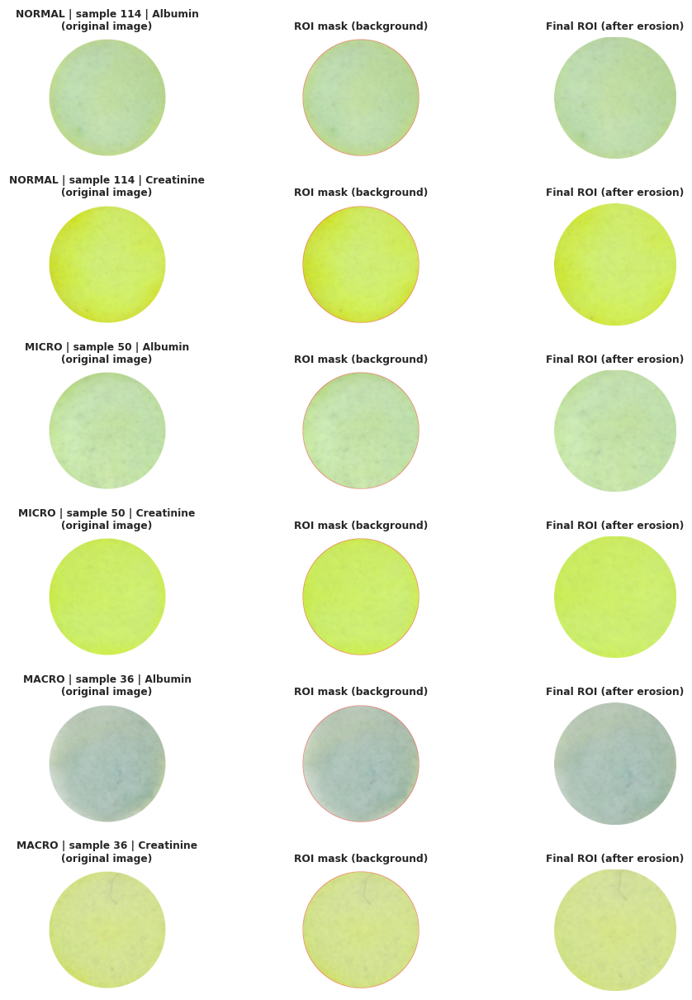

**Figure S3.** Visual verification of ROI detection on example albumin–creatinine image pairs from each class: original image, ROI mask contour, and the final ROI used for quantification.

In [9]:
# ---------- Visual ROI verification: one example pair per class ----------
ex_rows = []
for c in CLASSES:
    sub = df_pairs[df_pairs.label == c]
    if len(sub):
        ex_rows.append(sub.iloc[len(sub) // 2])

fig, axs = plt.subplots(len(ex_rows) * 2, 3, figsize=(9.5, 3.0 * len(ex_rows) * 2 * 0.62))
axs = np.atleast_2d(axs)
for i, r in enumerate(ex_rows):
    for j, (role, path) in enumerate([('Albumin', r['path_alb']), ('Creatinine', r['path_cre'])]):
        d = prepare_roi(path, keep_full=True)
        row = i * 2 + j
        orig = cv2.cvtColor(d['orig'], cv2.COLOR_BGR2RGB)
        axs[row, 0].imshow(orig); axs[row, 0].set_title(f'{r.label} | sample {r["sample"]} | {role}\n(original image)', fontsize=8)
        ov = orig.copy()
        edge = d['full_mask'] ^ cv2.erode(d['full_mask'].astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
        ov[edge] = (255, 0, 0)
        axs[row, 1].imshow(ov); axs[row, 1].set_title(f'ROI mask ({d["method"]})', fontsize=8)
        crop = cv2.cvtColor(d['bgr'], cv2.COLOR_BGR2RGB).copy()
        crop[~d['mask']] = 255
        axs[row, 2].imshow(crop); axs[row, 2].set_title('Final ROI (after erosion)', fontsize=8)
        for a in axs[row]:
            a.axis('off')
fig.tight_layout()
save_fig(fig, 'roi_verification', 'Visual verification of ROI detection on example albumin–creatinine image pairs from each class: original image, ROI mask contour, and the final ROI used for quantification.')
stage_done('1-5 setup, inventory, labels, merge, ROI')

# Stage 6 · Feature Extraction (Multi-Method Image Quantification)

**Purpose.** Convert each ROI into a numeric feature vector describing *intensity and colour* (the colorimetric response to analyte concentration) as well as *texture and spatial distribution* (homogeneity of reagent spreading).

For **each image** (albumin `alb__*` and creatinine `cre__*`) 118 features are computed from five groups of methods, and 41 cross-image features are derived from the pair (277 in total):

| Group | Quantification method | Count per image | Rationale |
|---|---|---|---|
| Colour-channel statistics | mean, SD, median, P10, P90, IQR, *skewness*, *kurtosis* on the R, G, B, S, V, L\*, a\*, b\*, gray channels | 72 | Reagent colour change caused by the analyte; pixel-to-pixel variability |
| *Hue* | circular cos/sin components and resultant length of the *hue* | 3 | *Hue* is cyclic, so it must not be averaged linearly |
| Colour indices | chromaticity r,g,b; ratios R/G, G/B, R/B; **absorbance** −log₁₀(I/I₀) per channel; ExG; CIELAB *chroma* & *hue* angle; colour distance ΔE to white; ΔE spread; gray CV | 17 | Standard colorimetric quantities; absorbance is more linearly related to concentration (Beer–Lambert) |
| Texture & spatial | GLCM (contrast, dissimilarity, homogeneity, energy, correlation, entropy) at 2 distances × 4 angles; histogram entropy; *uniform* LBP (10 bins); Sobel gradient; Laplacian variance; 3-ring radial profile; left–right/top–bottom asymmetry | 26 | Pattern of urine/reagent spreading, smoothness and chromatographic gradients |
| **Cross-image** `x__*` | differences and log-ratios of key albumin features relative to creatinine | 41 (per pair) | Mimics the UACR = albumin / creatinine concept: normalisation to urine concentration |

Cross-image features matter conceptually: urine albumin alone is affected by how dilute the urine is, whereas the ratio to creatinine normalises it.

**Reproducibility and cache.** The extraction result is *cached* (`outputs/0_Shared/cache`) under a key that depends on the file list and the ROI parameters. A cache is reused **only after a consistency check**: three test pairs are re-extracted with the module of Stage 5 and must reproduce the cached numbers; otherwise the whole extraction is recomputed. This guarantees that all features come from the code that is shipped in the deployment bundle. Extraction runs in parallel (`joblib`).

In [10]:
# ---------- Run the extraction (parallel + cache with consistency check) ----------
cache_key = hashlib.md5(json.dumps(dict(
    files=[(r.name_alb, r.name_cre) for r in df_pairs.itertuples()],
    cfg={k: CFG[k] for k in ('BG_DIST', 'ROI_ERODE_FRAC', 'MAX_SIDE', 'SPEC_V', 'SPEC_S')}), default=str).encode()).hexdigest()[:12]
cache_file = CACHE_DIR / f'features_{cache_key}.pkl'
cache_cands = [cache_file, DRIVE_OUT / 'cache' / f'features_{cache_key}.pkl']

META_NONFEAT = ('seq', 'sample', 'lux', 'ok', 'err')
def split_cols(cols):
    meta = [c for c in cols if c in META_NONFEAT or c.startswith('md5_') or c.endswith(('__roi_method', '__roi_area', '__spec_frac'))]
    return meta, [c for c in cols if c not in meta]

# probe: features of three pairs computed with the shipped module (also defines the expected feature names)
probe_idx = sorted({0, len(df_pairs) // 2, len(df_pairs) - 1})
probe = {i: uf.process_pair(df_pairs.iloc[i].to_dict(), ROI_PARAMS) for i in probe_idx}
assert all(p_['ok'] for p_ in probe.values()), 'The probe pairs could not be processed: ' + str([p_['err'] for p_ in probe.values()])
_, EXPECTED_FEATS = split_cols(list(probe[probe_idx[0]].keys()))
print(f'The module produces {len(EXPECTED_FEATS)} features per test.')

def cache_consistent(fr):
    if not set(EXPECTED_FEATS).issubset(fr.columns) or not {'seq', 'sample', 'ok'}.issubset(fr.columns):
        return False
    key = fr.set_index(['seq', 'sample'])
    if key.index.duplicated().any():
        return False
    need = set(map(tuple, df_pairs[['seq', 'sample']].values))
    if not need.issubset(set(key.index)):
        return False
    for i, new in probe.items():
        r = df_pairs.iloc[i]; old = key.loc[(r['seq'], r['sample'])]
        for c in EXPECTED_FEATS:
            if not np.isclose(float(new[c]), float(old[c]), rtol=1e-4, atol=1e-6, equal_nan=True):
                return False
    return True

def _run_extraction(records, n_jobs):
    return Parallel(n_jobs=n_jobs, backend='loky', verbose=0)(delayed(uf.process_pair)(r, ROI_PARAMS) for r in tqdm(records, desc='Feature extraction'))

feat_raw, cache_source = None, None
if CFG['USE_CACHE']:
    for cand in cache_cands:
        try:
            if cand.exists():
                fr = pd.read_pickle(cand)
                if cache_consistent(fr):
                    feat_raw, cache_source = fr, str(cand); print('Feature cache accepted after the consistency check:', cand); break
                else:
                    print('Feature cache found but NOT consistent with the shipped module -> ignored:', cand)
        except Exception as e:
            print('Cache unreadable:', cand, repr(e)[:80])

if feat_raw is None:
    t0 = time.time(); ensure_drive()
    recs = df_pairs.to_dict('records')
    results = _run_extraction(recs, n_jobs=min(4, os.cpu_count() or 2))   # limited parallelism so the Drive mount is not overloaded
    for attempt in range(2):   # retry failures caused by Drive I/O (e.g. "Transport endpoint is not connected")
        bad = [i for i, r in enumerate(results) if (not r['ok']) and ('OSError' in r['err'] or 'Errno' in r['err'] or 'Failed to read image' in r['err'])]
        if not bad:
            break
        print(f'Retrying {len(bad)} pairs that failed because of I/O (attempt {attempt + 1}) ...')
        ensure_drive(); time.sleep(5)
        redo = _run_extraction([recs[i] for i in bad], n_jobs=2)
        for i, r in zip(bad, redo):
            results[i] = r
    feat_raw = pd.DataFrame(results); cache_source = 'computed in this run'
    print(f'Finished in {time.time() - t0:.1f} s.')

if CFG['USE_CACHE'] and not cache_file.exists():
    try:
        feat_raw.to_pickle(cache_file)
    except OSError as e:
        print('Cache could not be saved (ignored, does not affect the results):', e)

failed = feat_raw[~feat_raw.ok.astype(bool)]
print(f'Pairs succeeded: {int(feat_raw.ok.astype(bool).sum())} | failed: {len(failed)}')
if len(failed):
    display(failed[['seq', 'sample', 'err']].head(10))

keep_cols = ['seq', 'sample'] + [c for c in feat_raw.columns if c.startswith('md5_') or c.endswith(('__roi_method', '__roi_area', '__spec_frac'))] + EXPECTED_FEATS
df_all = df_pairs[['seq', 'sample', 'lux', 'label', 'y', 'uacr', 'log10_uacr', 'name_alb', 'name_cre']].merge(
    feat_raw[feat_raw.ok.astype(bool)][keep_cols], on=['seq', 'sample'], how='inner')

META_COLS = ['seq', 'sample', 'lux', 'label', 'y', 'uacr', 'log10_uacr', 'name_alb', 'name_cre', 'md5_alb', 'md5_cre'] + \
            [c for c in df_all.columns if c.endswith(('__roi_method', '__roi_area', '__spec_frac'))]
FEAT_ALL = [c for c in df_all.columns if c not in META_COLS]
assert set(FEAT_ALL) == set(EXPECTED_FEATS)
print(f'Feature matrix dimensions: {len(df_all)} tests x {len(FEAT_ALL)} features | source of the features: {cache_source}')
put('features.cache_source', cache_source); put('features.cache_key', cache_key); put('features.module_sha256', MODULE_SHA)
put('features.n_generated', len(FEAT_ALL)); put('features.n_tests_extracted', len(df_all)); put('features.n_failed_pairs', len(failed))

The module produces 277 features per test.
Feature cache accepted after the consistency check: /content/outputs/0_Shared/cache/features_91614d0a03ef.pkl
Pairs succeeded: 497 | failed: 0
Feature matrix dimensions: 497 tests x 277 features | source of the features: /content/outputs/0_Shared/cache/features_91614d0a03ef.pkl


**Table S8.** Catalogue of all generated features (name, image source, method group).

**Table S9.** Number of generated features by method group and image source.

source,Albumin,Creatinine,Cross-image,Total
group,,,,
Colour indices,17,17,0,34
Colour-channel statistics,72,72,0,144
Cross-image,0,0,41,41
Hue,3,3,0,6
Texture & spatial,26,26,0,52
Total,118,118,41,277


**Table S10.** Quality control of ROI detection per image type.

,Image,method background,Median ROI area (% of frame),Median specular (%)
0,Albumin,497,71.2,0.0
1,Creatinine,497,71.2,0.0


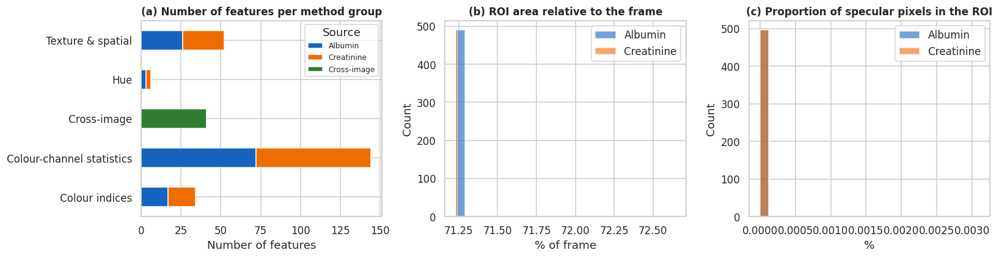

**Figure S4.** Feature extraction summary: (a) feature composition, (b) distribution of ROI area, (c) proportion of specular pixels.

In [11]:
# ---------- Feature catalogue ----------
IDX_NAMES = {'chr_r', 'chr_g', 'chr_b', 'ratio_RG', 'ratio_GB', 'ratio_RB', 'abs_R', 'abs_G', 'abs_B', 'abs_gray', 'exg', 'chroma',
             'lab_hue_sin', 'lab_hue_cos', 'dE_white', 'dE_spread', 'gray_cv'}
TEX_PREFIX = ('glcm_', 'lbp_', 'grad_', 'lap_', 'ring_', 'asym_', 'gray_entropy')
GROUPS = ['Colour-channel statistics', 'Hue', 'Colour indices', 'Texture & spatial', 'Cross-image']

def source_of(c):
    return {'alb': 'Albumin', 'cre': 'Creatinine', 'x': 'Cross-image'}[c.split('__')[0]]

def family_of(c):
    src, nm = c.split('__', 1)
    if src == 'x': return 'Cross-image'
    if nm.startswith(TEX_PREFIX): return 'Texture & spatial'
    if nm.startswith('hue_'): return 'Hue'
    if nm in IDX_NAMES: return 'Colour indices'
    return 'Colour-channel statistics'

catalog = pd.DataFrame({'feature': FEAT_ALL})
catalog['source'] = catalog.feature.map(source_of)
catalog['group'] = catalog.feature.map(family_of)
save_table(catalog, 'feature_catalogue', 'Catalogue of all generated features (name, image source, method group).', index=False, show=False)

pivot = catalog.groupby(['group', 'source']).size().unstack(fill_value=0)
pivot['Total'] = pivot.sum(axis=1); pivot.loc['Total'] = pivot.sum()
save_table(pivot, 'feature_summary', 'Number of generated features by method group and image source.')
put('features.by_source', catalog.source.value_counts().to_dict()); put('features.by_group', catalog.group.value_counts().to_dict())

# ROI quality control
qc = []
for role, nm in (('alb', 'Albumin'), ('cre', 'Creatinine')):
    vc = df_all[f'{role}__roi_method'].value_counts()
    qc.append({'Image': nm, **{f'method {k}': v for k, v in vc.items()},
               'Median ROI area (% of frame)': round(df_all[f'{role}__roi_area'].median() * 100, 1),
               'Median specular (%)': round(df_all[f'{role}__spec_frac'].median() * 100, 2)})
save_table(pd.DataFrame(qc).fillna(0), 'roi_quality_control', 'Quality control of ROI detection per image type.', index=False)
put('features.roi_qc', pd.DataFrame(qc).fillna(0).to_dict(orient='records'))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
cat_cnt = catalog.groupby(['group', 'source']).size().unstack(fill_value=0)
cat_cnt.plot(kind='barh', stacked=True, ax=ax[0], color=[SRC_COL[c] for c in cat_cnt.columns])
ax[0].set_title('(a) Number of features per method group'); ax[0].set_xlabel('Number of features'); ax[0].set_ylabel(''); ax[0].legend(title='Source', fontsize=8)
for role, col, nm in (('alb', '#1565C0', 'Albumin'), ('cre', '#EF6C00', 'Creatinine')):
    ax[1].hist(df_all[f'{role}__roi_area'] * 100, bins=25, alpha=.6, color=col, label=nm)
    ax[2].hist(df_all[f'{role}__spec_frac'] * 100, bins=25, alpha=.6, color=col, label=nm)
ax[1].set_title('(b) ROI area relative to the frame'); ax[1].set_xlabel('% of frame'); ax[1].set_ylabel('Count'); ax[1].legend()
ax[2].set_title('(c) Proportion of specular pixels in the ROI'); ax[2].set_xlabel('%'); ax[2].set_ylabel('Count'); ax[2].legend()
fig.tight_layout()
save_fig(fig, 'extraction_summary', 'Feature extraction summary: (a) feature composition, (b) distribution of ROI area, (c) proportion of specular pixels.')
stage_done('6 feature extraction')

# Stage 7 · *Exploratory Data Analysis* (EDA)

**Purpose.** Understand the structure of the feature matrix before cleaning and modelling, and test the **construct validity** of the image quantification: do the features from the albumin image really correlate with laboratory urine albumin, the creatinine-image features with urine creatinine, and the cross-image features with UACR?

**Sub-stages.**
1. Distribution of key features across classes (test level).
2. Correlation structure between features (*clustered heatmap*) to see redundancy.
3. PCA projection: do the classes separate naturally in feature space?
4. **Construct validity** against laboratory values (sample-level Spearman correlation).
5. Feature sensitivity to illumination (lux).

**Note on analysis ethics.** This EDA is descriptive and run on all data only to understand the data. **Feature selection and model settings do not use these EDA results**; the formal selection is done inside the training folds (Stages 11–13).

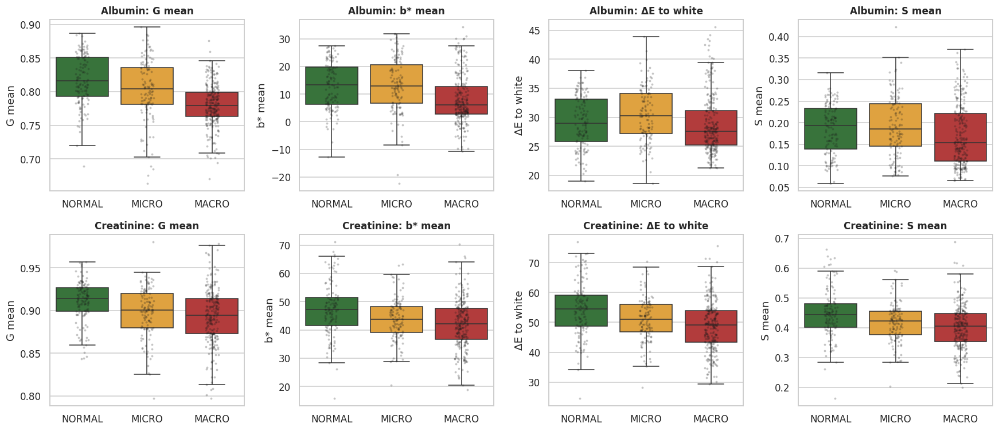

**Figure S5.** Distribution of key colorimetric features (mean G, CIELAB b*, ΔE to white, saturation) in the albumin (top) and creatinine (bottom) images by class.

In [12]:
# 7.1 Distribution of key features across classes (features fixed a priori from colorimetric principles, not from labels)
KEY_SHOW = ['G_mean', 'b_mean', 'dE_white', 'S_mean']
KEY_LABEL = {'G_mean': 'G mean', 'b_mean': 'b* mean', 'dE_white': 'ΔE to white', 'S_mean': 'S mean'}
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for i, (role, nm) in enumerate((('alb', 'Albumin'), ('cre', 'Creatinine'))):
    for j, k in enumerate(KEY_SHOW):
        sns.boxplot(data=df_all, x='label', y=f'{role}__{k}', order=CLASSES, palette=PALETTE, ax=axs[i, j], showfliers=False)
        sns.stripplot(data=df_all, x='label', y=f'{role}__{k}', order=CLASSES, color='k', alpha=.25, size=2.5, ax=axs[i, j])
        axs[i, j].set_title(f'{nm}: {KEY_LABEL[k]}'); axs[i, j].set_xlabel(''); axs[i, j].set_ylabel(KEY_LABEL[k])
fig.tight_layout()
save_fig(fig, 'key_feature_distributions', 'Distribution of key colorimetric features (mean G, CIELAB b*, ΔE to white, saturation) in the albumin (top) and creatinine (bottom) images by class.')

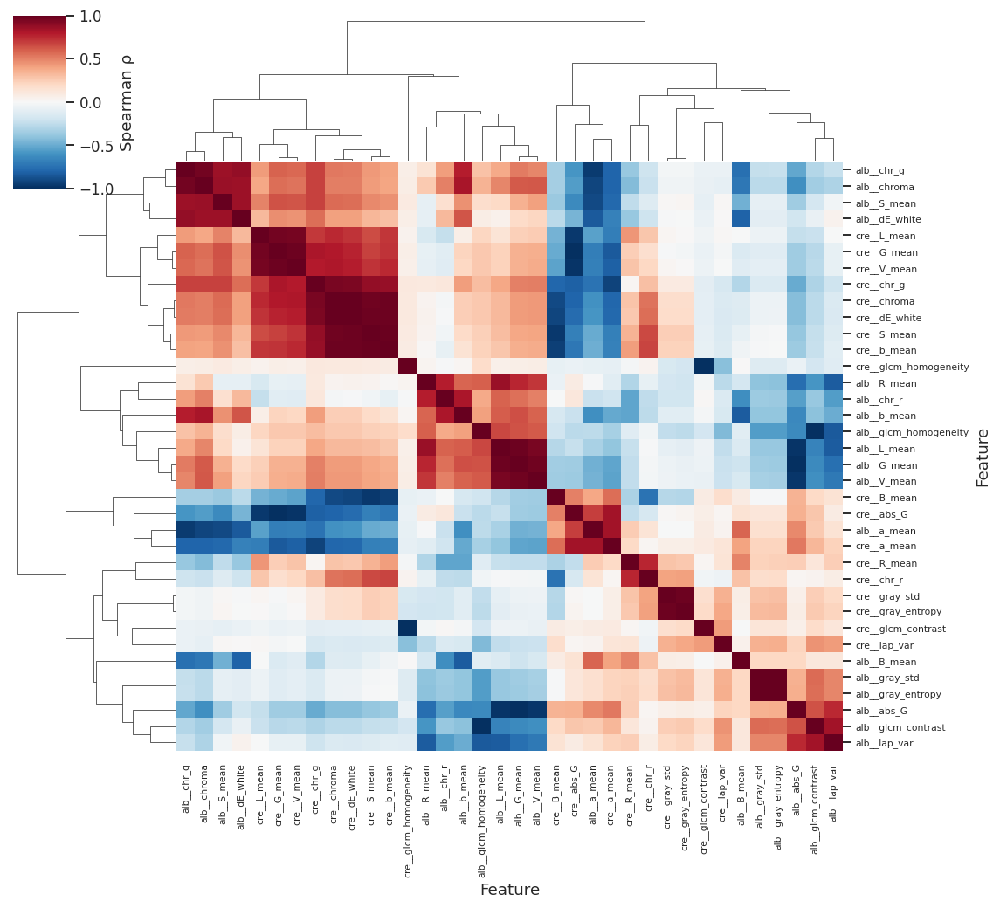

**Figure S6.** Hierarchically clustered Spearman correlation map between key albumin (alb__) and creatinine (cre__) features; red blocks indicate redundant features.

Feature pairs with |ρ| > 0.90: 890 of 38226 (2.3%) -> high redundancy, a correlation filter is needed in feature selection.


In [13]:
# 7.2 Correlation structure between key features
key_cols = [f'{r}__{k}' for r in ('alb', 'cre') for k in ['R_mean', 'G_mean', 'B_mean', 'S_mean', 'V_mean', 'L_mean', 'a_mean', 'b_mean',
            'chr_r', 'chr_g', 'abs_G', 'chroma', 'dE_white', 'gray_std', 'glcm_contrast', 'glcm_homogeneity', 'gray_entropy', 'lap_var']]
corr = df_all[key_cols].corr(method='spearman')
cg = sns.clustermap(corr, cmap='RdBu_r', vmin=-1, vmax=1, figsize=(11, 10), xticklabels=True, yticklabels=True,
                    cbar_kws={'label': 'Spearman ρ'})
cg.ax_heatmap.tick_params(labelsize=7)
cg.ax_heatmap.set_xlabel('Feature'); cg.ax_heatmap.set_ylabel('Feature')
save_fig(cg.fig, 'feature_correlation', 'Hierarchically clustered Spearman correlation map between key albumin (alb__) and creatinine (cre__) features; red blocks indicate redundant features.')

allc = df_all[FEAT_ALL].corr(method='spearman').abs().values
iu = np.triu_indices_from(allc, k=1)
put('eda.pairs_abs_rho_gt_0.9', dict(n=int((allc[iu] > 0.90).sum()), of=int(len(iu[0])), percent=float((allc[iu] > 0.90).mean() * 100)))
print(f'Feature pairs with |ρ| > 0.90: {(allc[iu] > 0.90).sum()} of {len(iu[0])} ({(allc[iu] > 0.90).mean() * 100:.1f}%) -> high redundancy, a correlation filter is needed in feature selection.')

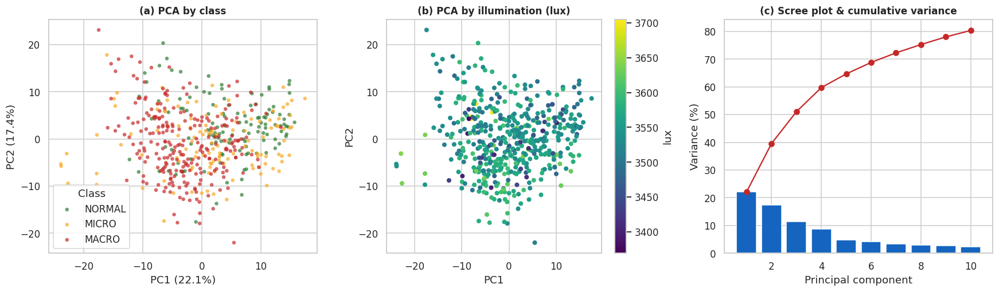

**Figure S7.** PCA projection of all features: (a) by class, (b) by lux, (c) explained variance. Class silhouette on the first 5 PCs = 0.029.

Silhouette (5 PCs) against the labels = 0.029  (values close to 0 mean the classes overlap without supervised modelling)


In [14]:
# 7.3 PCA
Xp = SimpleImputer(strategy='median').fit_transform(df_all[FEAT_ALL])
Xp = StandardScaler().fit_transform(Xp)
Xp = np.nan_to_num(Xp)
pca = PCA(n_components=min(10, Xp.shape[1])).fit(Xp)
Z = pca.transform(Xp)
try:
    sil = silhouette_score(Z[:, :5], df_all['y'])
except Exception:
    sil = float('nan')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for c in CLASSES:
    mk = (df_all.label == c).values
    ax[0].scatter(Z[mk, 0], Z[mk, 1], s=18, alpha=.7, c=COLORS[c], label=c, edgecolor='none')
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)'); ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)')
ax[0].set_title('(a) PCA by class'); ax[0].legend(title='Class')
sc = ax[1].scatter(Z[:, 0], Z[:, 1], s=18, c=df_all['lux'], cmap='viridis'); plt.colorbar(sc, ax=ax[1], label='lux')
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2'); ax[1].set_title('(b) PCA by illumination (lux)')
ev = pca.explained_variance_ratio_
ax[2].bar(range(1, len(ev) + 1), ev * 100, color='#1565C0'); ax[2].plot(range(1, len(ev) + 1), np.cumsum(ev) * 100, 'o-', c='#C62828')
ax[2].set_xlabel('Principal component'); ax[2].set_ylabel('Variance (%)'); ax[2].set_title('(c) Scree plot & cumulative variance')
fig.tight_layout()
save_fig(fig, 'pca', f'PCA projection of all features: (a) by class, (b) by lux, (c) explained variance. Class silhouette on the first 5 PCs = {sil:.3f}.')
put('eda.pca', dict(var_pc1=ev[0] * 100, var_pc2=ev[1] * 100, var_first5=float(ev[:5].sum() * 100), silhouette_5pc=sil))
print(f'Silhouette (5 PCs) against the labels = {sil:.3f}  (values close to 0 mean the classes overlap without supervised modelling)')

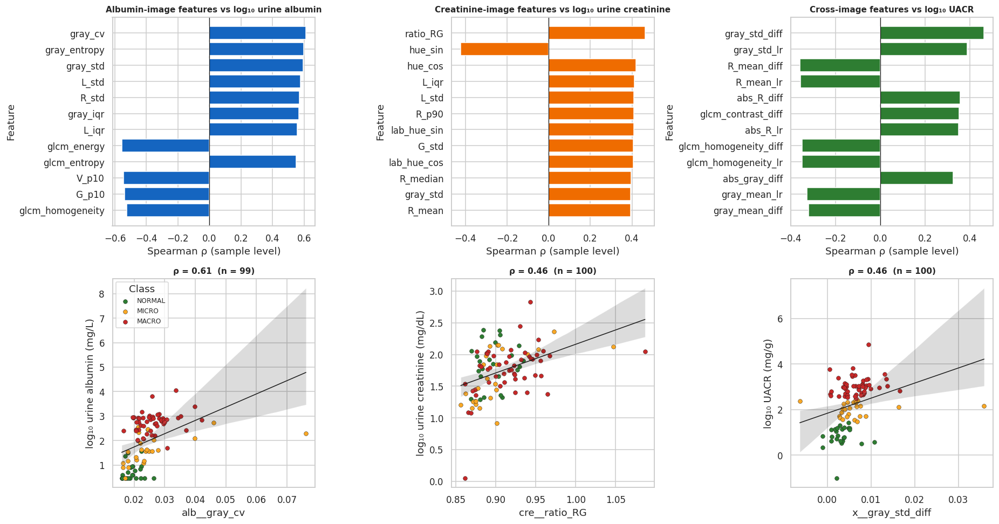

**Figure S8.** Construct validity: (top) the 12 features with the highest Spearman correlation to laboratory values; (bottom) scatter plots of the best feature. Descriptive sample-level analysis (mean of repeats).

**Table S11.** Summary of the construct validity of image features against laboratory values (Spearman, sample level).

,Feature–reference pair,Best feature,Best ρ,Number with |ρ| > 0.5,Features tested
0,Albumin image ↔ log urine albumin,alb__gray_cv,0.612,18,118
1,Creatinine image ↔ log urine creatinine,cre__ratio_RG,0.463,0,118
2,Cross-image ↔ log UACR,x__gray_std_diff,0.464,0,41


In [15]:
# 7.4 Construct validity: sample-level Spearman correlation against laboratory values
samp_mean = df_all.groupby('sample')[FEAT_ALL].mean()
samp = samp_mean.join(labels.set_index('sample')[['label', 'alb_mgL', 'cre_mgdL', 'uacr', 'log10_uacr']])
samp['log_alb'] = np.log10(samp['alb_mgL'].where(samp['alb_mgL'] > 0))
samp['log_cre'] = np.log10(samp['cre_mgdL'].where(samp['cre_mgdL'] > 0))

def spearman_vs(cols, target):
    d = samp[cols + [target]].dropna(subset=[target])
    res = []
    for c in cols:
        v = d[[c, target]].dropna()
        if len(v) > 5 and v[c].nunique() > 2:
            r, p = sps.spearmanr(v[c], v[target]); res.append((c, r, p, len(v)))
    out = pd.DataFrame(res, columns=['feature', 'rho', 'p', 'n'])
    out['abs_rho'] = out.rho.abs()
    return out.sort_values('abs_rho', ascending=False).reset_index(drop=True)

alb_cols = [c for c in FEAT_ALL if c.startswith('alb__')]
cre_cols = [c for c in FEAT_ALL if c.startswith('cre__')]
x_cols = [c for c in FEAT_ALL if c.startswith('x__')]
val_alb = spearman_vs(alb_cols, 'log_alb')
val_cre = spearman_vs(cre_cols, 'log_cre')
val_x = spearman_vs(x_cols, 'log10_uacr')

fig, axs = plt.subplots(2, 3, figsize=(17, 9))
for j, (tab_, ttl, col) in enumerate([(val_alb, 'Albumin-image features vs log₁₀ urine albumin', '#1565C0'),
                                       (val_cre, 'Creatinine-image features vs log₁₀ urine creatinine', '#EF6C00'),
                                       (val_x, 'Cross-image features vs log₁₀ UACR', '#2E7D32')]):
    top = tab_.head(12).iloc[::-1]
    axs[0, j].barh(top.feature.str.replace(r'^(alb|cre|x)__', '', regex=True), top.rho, color=col)
    axs[0, j].set_title(ttl, fontsize=10); axs[0, j].set_xlabel('Spearman ρ (sample level)'); axs[0, j].set_ylabel('Feature'); axs[0, j].axvline(0, c='k', lw=.8)
pairs_plot = [(val_alb, 'log_alb', 'log₁₀ urine albumin (mg/L)', '#1565C0'), (val_cre, 'log_cre', 'log₁₀ urine creatinine (mg/dL)', '#EF6C00'),
              (val_x, 'log10_uacr', 'log₁₀ UACR (mg/g)', '#2E7D32')]
for j, (tab_, tgt, lbl, col) in enumerate(pairs_plot):
    if len(tab_) == 0:
        continue
    best = tab_.feature.iloc[0]
    d = samp[[best, tgt, 'label']].dropna()
    for c in CLASSES:
        s = d[d.label == c]; axs[1, j].scatter(s[best], s[tgt], c=COLORS[c], s=26, label=c, edgecolor='k', lw=.3)
    sns.regplot(data=d, x=best, y=tgt, scatter=False, color='k', ax=axs[1, j], line_kws=dict(lw=1))
    axs[1, j].set_xlabel(best); axs[1, j].set_ylabel(lbl)
    axs[1, j].set_title(f'ρ = {tab_.rho.iloc[0]:.2f}  (n = {len(d)})', fontsize=10)
    if j == 0: axs[1, j].legend(title='Class', fontsize=8)
fig.tight_layout()
save_fig(fig, 'construct_validity', 'Construct validity: (top) the 12 features with the highest Spearman correlation to laboratory values; (bottom) scatter plots of the best feature. Descriptive sample-level analysis (mean of repeats).')

summ = pd.DataFrame({
    'Feature–reference pair': ['Albumin image ↔ log urine albumin', 'Creatinine image ↔ log urine creatinine', 'Cross-image ↔ log UACR'],
    'Best feature': [t.feature.iloc[0] if len(t) else '-' for t in (val_alb, val_cre, val_x)],
    'Best ρ': [round(t.rho.iloc[0], 3) if len(t) else np.nan for t in (val_alb, val_cre, val_x)],
    'Number with |ρ| > 0.5': [int((t.abs_rho > .5).sum()) for t in (val_alb, val_cre, val_x)],
    'Features tested': [len(t) for t in (val_alb, val_cre, val_x)]})
save_table(summ, 'construct_validity', 'Summary of the construct validity of image features against laboratory values (Spearman, sample level).', index=False)
put('eda.construct_validity', summ.to_dict(orient='records'))

Lux range: 3369 – 3705 (SD 49, CV 1.4%)
Features with |ρ| against lux > 0.5: 0 of 277


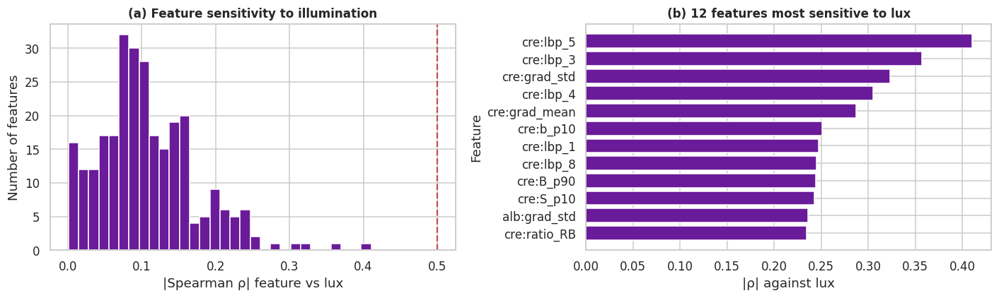

**Figure S9.** Feature sensitivity to illumination (lux): (a) distribution of |ρ| over all features, (b) the 12 most sensitive features. Lux-sensitive features risk carrying acquisition variation rather than chemical information.

**Table S12.** The 15 features most sensitive to lux.

,|ρ| vs lux
Feature,
cre__lbp_5,0.410558
cre__lbp_3,0.357079
cre__grad_std,0.322957
cre__lbp_4,0.305209
cre__grad_mean,0.287057
cre__b_p10,0.250954
cre__lbp_1,0.247492
cre__lbp_8,0.245260
cre__B_p90,0.243994


In [16]:
# 7.5 Sensitivity to lux (test level)
lux_rho = {}
for c in FEAT_ALL:
    v = df_all[[c, 'lux']].dropna()
    lux_rho[c] = abs(sps.spearmanr(v[c], v['lux'])[0]) if v[c].nunique() > 2 and v['lux'].nunique() > 2 else np.nan
lux_rho = pd.Series(lux_rho).dropna().sort_values(ascending=False)
print(f'Lux range: {df_all.lux.min():.0f} – {df_all.lux.max():.0f} (SD {df_all.lux.std():.0f}, CV {df_all.lux.std() / df_all.lux.mean() * 100:.1f}%)')
print(f'Features with |ρ| against lux > 0.5: {(lux_rho > .5).sum()} of {len(lux_rho)}')
put('eda.lux', dict(min=df_all.lux.min(), max=df_all.lux.max(), sd=df_all.lux.std(), cv_percent=df_all.lux.std() / df_all.lux.mean() * 100,
                    n_features_abs_rho_gt_0_5=int((lux_rho > .5).sum()), n_features_tested=len(lux_rho), median_abs_rho=float(lux_rho.median())))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(lux_rho.values, bins=30, color='#6A1B9A'); ax[0].axvline(0.5, c='r', ls='--')
ax[0].set_xlabel('|Spearman ρ| feature vs lux'); ax[0].set_ylabel('Number of features'); ax[0].set_title('(a) Feature sensitivity to illumination')
top = lux_rho.head(12).iloc[::-1]
ax[1].barh(top.index.str.replace(r'^(alb|cre|x)__', lambda m_: m_.group(1) + ':', regex=True), top.values, color='#6A1B9A')
ax[1].set_xlabel('|ρ| against lux'); ax[1].set_ylabel('Feature'); ax[1].set_title('(b) 12 features most sensitive to lux')
fig.tight_layout()
save_fig(fig, 'lux_sensitivity', 'Feature sensitivity to illumination (lux): (a) distribution of |ρ| over all features, (b) the 12 most sensitive features. Lux-sensitive features risk carrying acquisition variation rather than chemical information.')
save_table(lux_rho.head(15).rename('|ρ| vs lux').to_frame().rename_axis('Feature'), 'lux_sensitive_features', 'The 15 features most sensitive to lux.')
stage_done('7 EDA')

# Stage 8 · *Data Cleansing*

**Purpose.** Produce a reliable feature dataset. Cleaning is done **sequentially and documented** (attrition table), and does not use the label except for reporting.

| Step | Treatment | Reason |
|---|---|---|
| 1 | Drop tests whose extraction failed; replace `±inf` with `NaN` | Numerical integrity |
| 2 | **Duplicate images** (identical MD5 hash): within the same sample → keep one; across **different** samples → drop all | Identical images in different samples imply conflicting labels or a file naming/copying error |
| 3 | Drop features with > 20 % missing data or constant (unique values ≤ 2) | Uninformative |
| 4 | Multivariate outlier detection per class (*Isolation Forest* on 10 PCs, contamination 3 %), provided every sample keeps ≥ 1 test | Acquisition failures (focus, shadow, contamination) |
| 5 | **Repeat reliability**: one-way ICC(1) per feature; drop features with ICC < `ICC_MIN` | Features whose between-repeat variation outweighs between-sample variation cannot generalise |

**ICC(1)** (*intraclass correlation*, one-way random model, unbalanced design) = (MSB − MSW) / (MSB + (n₀ − 1)·MSW), where n₀ is the effective number of repeats per sample. General interpretation: < 0.5 poor, 0.5–0.75 moderate, 0.75–0.9 good, > 0.9 excellent. The ICC uses **no label**, only the repeat structure, so applying it to all samples before cross-validation does not leak the target. Remaining missing values are **not** imputed here but inside the *pipeline* (from training data only) to prevent leakage.

In [17]:
attr = []   # attrition table
def log_step(name, d, feats):
    attr.append({'Step': name, 'Tests': len(d), 'Samples': d['sample'].nunique(), 'Features': len(feats)})

d0 = df_all.copy()
feats = list(FEAT_ALL)
log_step('0. Initial (all extracted pairs)', d0, feats)

# Step 1
d0[feats] = d0[feats].replace([np.inf, -np.inf], np.nan)
d1 = d0[d0[feats].notna().mean(axis=1) > 0.5].copy()
log_step('1. Drop failed extractions / ±inf', d1, feats)

# Step 2 - duplicate images
dup_rows = []
for role in ('alb', 'cre'):
    g = d1.groupby(f'md5_{role}')['sample'].nunique()
    cross = g[g > 1].index
    if len(cross):
        dup_rows.append(d1[d1[f'md5_{role}'].isin(cross)].assign(type=f'{role}: identical hash across samples'))
drop_idx = set()
if dup_rows:
    dup_x = pd.concat(dup_rows)
    drop_idx |= set(dup_x.index)
    print(f'WARNING: {dup_x.index.nunique()} tests have identical images in DIFFERENT SAMPLES -> dropped.')
    display(dup_x[['seq', 'sample', 'label', 'type']].sort_values(['type', 'sample']).head(15))
same = d1.drop(index=list(drop_idx)).duplicated(['sample', 'md5_alb', 'md5_cre'], keep='first')
drop_idx |= set(same[same].index)
d2 = d1.drop(index=list(drop_idx)).copy()
print(f'Duplicates dropped: {len(drop_idx)} tests.')
log_step('2. Drop duplicate images (MD5)', d2, feats)

# Step 3 - features
miss = d2[feats].isna().mean()
nun = d2[feats].nunique(dropna=True)
bad_feat = sorted(set(miss[miss > 0.20].index) | set(nun[nun <= 2].index))
feats = [f for f in feats if f not in bad_feat]
print(f'Features dropped (missing > 20% or constant): {len(bad_feat)}')
log_step('3. Drop missing/constant features', d2, feats)

# Step 4 - outliers per class (IsolationForest on PCs)
Xi = SimpleImputer(strategy='median').fit_transform(d2[feats])
Xi = np.nan_to_num(StandardScaler().fit_transform(Xi))
Zi = PCA(n_components=min(10, Xi.shape[1]), random_state=SEED).fit_transform(Xi)
out_flag = np.zeros(len(d2), bool)
for c in CLASSES:
    ix = np.where((d2.label == c).values)[0]
    if len(ix) >= 20:
        iso = IsolationForest(contamination=0.03, random_state=SEED, n_estimators=300).fit(Zi[ix])
        out_flag[ix[iso.predict(Zi[ix]) == -1]] = True
tmp = d2.assign(_out=out_flag)
for s_, g in tmp.groupby('sample'):   # make sure every sample keeps >= 1 test
    if g._out.all():
        tmp.loc[g.index[0], '_out'] = False
out_flag = tmp['_out'].values
d3 = d2[~out_flag].copy()
print(f'Outliers dropped: {out_flag.sum()} tests ({out_flag.mean() * 100:.1f}%)')
log_step('4. Drop multivariate outliers (per class)', d3, feats)

# Step 5 - ICC(1)
def icc1_matrix(d, cols, group='sample'):
    n_i = d.groupby(group).size()
    keep = n_i[n_i >= 2].index
    dd = d[d[group].isin(keep)]
    X = dd[cols]
    gmean = X.groupby(dd[group]).transform('mean')
    N, a = len(dd), dd[group].nunique()
    grand = X.mean()
    gm_unique = X.groupby(dd[group]).mean()
    n_g = dd.groupby(group).size().reindex(gm_unique.index).values
    ssb = (n_g[:, None] * (gm_unique.values - grand.values) ** 2).sum(axis=0)
    ssw = ((X.values - gmean.values) ** 2).sum(axis=0)
    msb, msw = ssb / (a - 1), ssw / max(N - a, 1)
    n0 = (N - (n_g ** 2).sum() / N) / (a - 1)
    return pd.Series((msb - msw) / (msb + (n0 - 1) * msw + 1e-12), index=cols)

icc = icc1_matrix(d3, feats)
thr = CFG['ICC_MIN']
if (icc >= thr).sum() < 20:
    thr = float(icc.quantile(0.5)); print(f'Too few features pass the ICC filter; threshold automatically lowered to {thr:.2f}')
feats_icc = [f for f in feats if icc[f] >= thr]
print(f'Features with ICC ≥ {thr:.2f}: {len(feats_icc)} of {len(feats)}')
FEATS = feats_icc
log_step(f'5. Drop features with ICC < {thr:.2f}', d3, FEATS)

df_clean = d3.reset_index(drop=True)
attr_df = pd.DataFrame(attr)
save_table(attr_df, 'cleansing_attrition', 'Attrition table: number of tests, samples and features after each data-cleaning step.', index=False)

n_by_class = df_clean.groupby('label')['sample'].nunique().reindex(CLASSES)
put('cleansing.attrition', attr_df.to_dict(orient='records')); put('cleansing.icc_threshold', thr)
put('cleansing.duplicates_dropped', len(drop_idx)); put('cleansing.outliers_dropped', int(out_flag.sum())); put('cleansing.features_dropped_missing_or_constant', len(bad_feat))
put('cleansing.final', dict(tests=len(df_clean), samples=df_clean['sample'].nunique(), features=len(FEATS), samples_per_class=n_by_class.to_dict(),
                            tests_per_class=df_clean.groupby('label').size().reindex(CLASSES).to_dict()))
put('cleansing.icc_by_source', {s_: dict(n_features=int(sum(source_of(c) == s_ for c in feats)), n_pass=int(sum(source_of(c) == s_ for c in FEATS)),
                                          median_icc=float(icc[[c for c in feats if source_of(c) == s_]].median())) for s_ in SRC_COL})
put('cleansing.icc_overall', dict(median=float(icc.median()), share_pass_percent=float((icc >= thr).mean() * 100)))

Duplicates dropped: 3 tests.
Features dropped (missing > 20% or constant): 0
Outliers dropped: 16 tests (3.2%)
Features with ICC ≥ 0.50: 163 of 277


**Table S13.** Attrition table: number of tests, samples and features after each data-cleaning step.

,Step,Tests,Samples,Features
0,0. Initial (all extracted pairs),497,100,277
1,1. Drop failed extractions / ±inf,497,100,277
2,2. Drop duplicate images (MD5),494,100,277
3,3. Drop missing/constant features,494,100,277
4,4. Drop multivariate outliers (per class),478,100,277
5,5. Drop features with ICC < 0.50,478,100,163


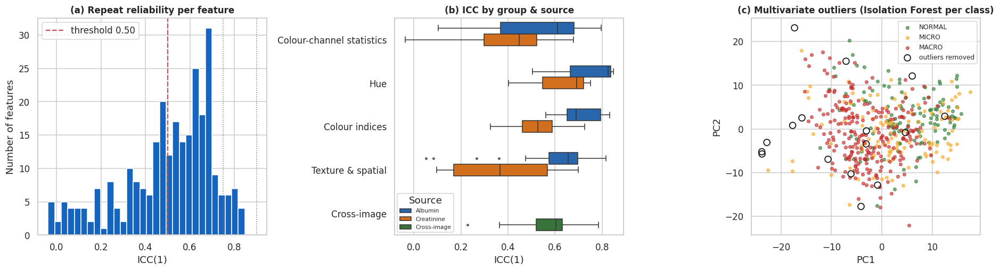

**Figure S10.** Data cleansing: (a) distribution of feature ICC and the reliability threshold, (b) ICC by method group and image source, (c) multivariate outliers in PCA space.

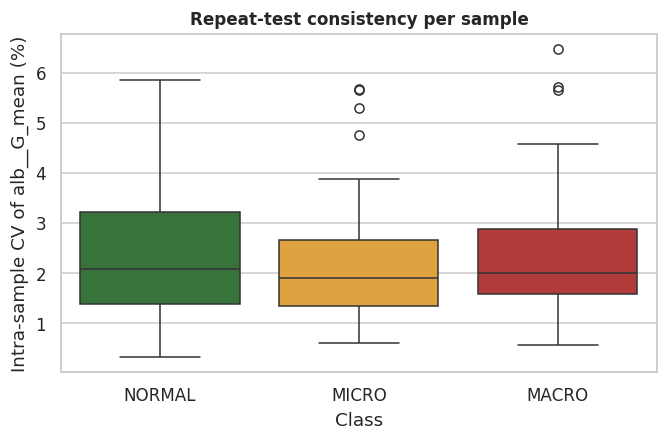

**Figure S11.** Intra-sample coefficient of variation of feature alb__G_mean across repeats, by class; overall median = 2.03%.

**Table S14.** Number of features per method group before and after the reliability (ICC) filter.

,before ICC,after ICC
Method group,,
Colour indices,34,26
Colour-channel statistics,144,71
Cross-image,41,32
Hue,6,5
Texture & spatial,52,29


Samples per class after cleansing: {'NORMAL': 25, 'MICRO': 25, 'MACRO': 50} | total tests: 478 | features: 163


In [18]:
# ---------- Cleansing visualisation ----------
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].hist(icc.values, bins=30, color='#1565C0'); ax[0].axvline(thr, c='r', ls='--', label=f'threshold {thr:.2f}')
for v in (0.5, 0.75, 0.9):
    ax[0].axvline(v, c='gray', ls=':', lw=1)
ax[0].set_xlabel('ICC(1)'); ax[0].set_ylabel('Number of features'); ax[0].set_title('(a) Repeat reliability per feature'); ax[0].legend()

icc_f = pd.DataFrame({'icc': icc, 'group': [family_of(c) for c in icc.index], 'source': [source_of(c) for c in icc.index]})
sns.boxplot(data=icc_f, y='group', x='icc', hue='source', palette=[SRC_COL[s_] for s_ in ('Albumin', 'Creatinine', 'Cross-image')], ax=ax[1], fliersize=2)
ax[1].set_title('(b) ICC by group & source'); ax[1].set_ylabel(''); ax[1].set_xlabel('ICC(1)'); ax[1].legend(title='Source', fontsize=7)

for c in CLASSES:
    mk = (d2.label == c).values & ~out_flag
    ax[2].scatter(Zi[mk, 0], Zi[mk, 1], s=14, c=COLORS[c], alpha=.6, label=c)
ax[2].scatter(Zi[out_flag, 0], Zi[out_flag, 1], s=60, facecolor='none', edgecolor='k', lw=1.2, label='outliers removed')
ax[2].set_xlabel('PC1'); ax[2].set_ylabel('PC2'); ax[2].set_title('(c) Multivariate outliers (Isolation Forest per class)'); ax[2].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, 'cleansing', 'Data cleansing: (a) distribution of feature ICC and the reliability threshold, (b) ICC by method group and image source, (c) multivariate outliers in PCA space.')

# repeat consistency at the sample level (intra-sample CV of one key feature)
kf = 'alb__G_mean' if 'alb__G_mean' in df_clean.columns else FEATS[0]
cvs = df_clean.groupby('sample')[kf].agg(lambda s: s.std() / (abs(s.mean()) + 1e-9) * 100 if len(s) > 1 else np.nan).dropna()
lab_by_sample = labels.set_index('sample')['label']
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x=lab_by_sample.reindex(cvs.index), y=cvs.values, order=CLASSES, palette=PALETTE, ax=ax)
ax.set_xlabel('Class'); ax.set_ylabel(f'Intra-sample CV of {kf} (%)'); ax.set_title('Repeat-test consistency per sample')
save_fig(fig, 'intra_sample_cv', f'Intra-sample coefficient of variation of feature {kf} across repeats, by class; overall median = {cvs.median():.2f}%.')
put('cleansing.intra_sample_cv_median_percent', dict(feature=kf, median=float(cvs.median())))

fam = pd.DataFrame({'before ICC': pd.Series([family_of(c) for c in feats]).value_counts(),
                    'after ICC': pd.Series([family_of(c) for c in FEATS]).value_counts()}).fillna(0).astype(int)
fam.index.name = 'Method group'
save_table(fam, 'features_after_icc', 'Number of features per method group before and after the reliability (ICC) filter.')

print('Samples per class after cleansing:', n_by_class.to_dict(), '| total tests:', len(df_clean), '| features:', len(FEATS))
df_clean.to_csv(TAB_DIR / 'cleaned_dataset_all_features.csv', index=False, encoding='utf-8-sig')
sync_to_drive(verbose=False)
stage_done('8 cleansing')

# Stage 9 · The Common Analysis Set and the Grouped Fold Plan

**Purpose.** Freeze, once and before any model is trained, (i) **which tests are analysed** and (ii) **how they are split** into outer training/test folds. Both pipelines receive exactly this and nothing else.

**What is frozen.**
* *Analysis set:* the tests that survived Stage 8 — the file `cleaned_dataset_all_features.csv` in `0_Shared/tables`. Path B uses only its bookkeeping columns (sample, label, file names, MD5 hashes); Path A also uses its feature columns.
* *Fold plan:* `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 100 + repeat)` for repeat = 0, 1 — class-stratified, **grouped by sample number**, so that all repeated tests of one sample are on the same side of every split. The split depends only on labels and sample numbers, never on feature values or pixels. The test indices of every fold are saved in `fold_plan_test_indices.csv`; Part III rebuilds the folds independently and **asserts** that they are identical.

**Why this matters for the comparison.** A difference between two models can only be attributed to the models if both are scored on the same test folds. Fixing the plan here also makes it impossible for either path to influence the split.

10 outer folds (5 folds x 2 repeats) | leakage check passed: no sample appears in both the training and the test part of any fold.


**Table S15.** Fold plan - composition of the outer test folds (samples per class). Each sample is in exactly one test fold per repeat; class proportions are preserved by stratification.

,Repeat,Fold,Train samples,Test samples,Test tests,Test NORMAL (samples),Test MICRO (samples),Test MACRO (samples)
0,1,1,80,20,96,6,5,9
1,1,2,80,20,96,6,6,8
2,1,3,80,20,93,6,3,11
3,1,4,80,20,93,4,3,13
4,1,5,80,20,100,3,8,9
5,2,1,80,20,93,6,4,10
6,2,2,80,20,98,4,5,11
7,2,3,80,20,99,4,6,10
8,2,4,80,20,93,5,5,10
9,2,5,80,20,95,6,5,9


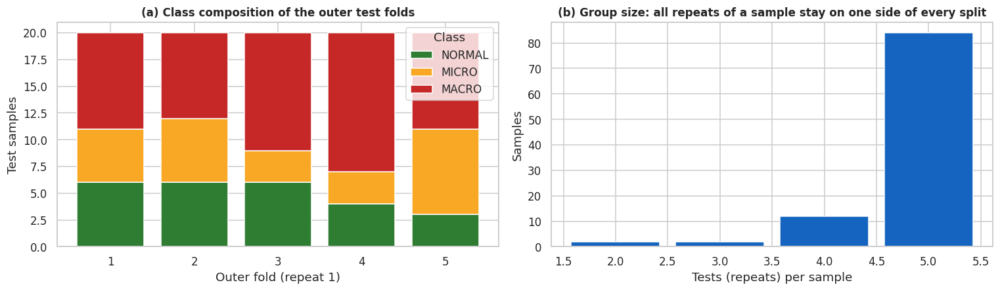

**Figure S12.** Fold plan: (a) class composition of the outer test folds (repeat 1); (b) distribution of the number of repeats per sample, which is why splits are made by sample.

Fold plan saved: 956 test assignments | analysis set: 478 tests, 100 samples.


In [19]:
# ---------- Outer folds (the fold plan shared by BOTH pipelines) ----------
y_all = df_clean['y'].values.astype(int)
g_all = df_clean['sample'].values
outer = []
for rep in range(CFG['OUTER_REPEATS']):
    for fold, (tri, tei) in enumerate(StratifiedGroupKFold(n_splits=CFG['OUTER_FOLDS'], shuffle=True, random_state=SEED + 100 + rep).split(np.zeros((len(y_all), 1)), y_all, g_all)):
        assert set(g_all[tri]).isdisjoint(set(g_all[tei])), 'Leakage: the same sample is in both train and test!'
        outer.append((rep, fold, tri, tei))
print(f'{len(outer)} outer folds ({CFG["OUTER_FOLDS"]} folds x {CFG["OUTER_REPEATS"]} repeats) | leakage check passed: no sample appears in both the training and the test part of any fold.')
cover = np.zeros(len(y_all), int)
for rep, fold, tri, tei in outer:
    if rep == 0: cover[tei] += 1
assert (cover == 1).all(), 'In repeat 1 every test must be predicted exactly once.'

comp_rows = []
for rep, fold, tri, tei in outer:
    d_ = df_clean.iloc[tei]; dtr = df_clean.iloc[tri]
    row = {'Repeat': rep + 1, 'Fold': fold + 1, 'Train samples': dtr['sample'].nunique(), 'Test samples': d_['sample'].nunique(), 'Test tests': len(d_)}
    for c in CLASSES: row[f'Test {c} (samples)'] = d_[d_.label == c]['sample'].nunique()
    comp_rows.append(row)
comp = pd.DataFrame(comp_rows)
save_table(comp, 'outer_fold_composition', 'Fold plan - composition of the outer test folds (samples per class). Each sample is in exactly one test fold per repeat; class proportions are preserved by stratification.', index=False)


fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
c1 = comp[comp.Repeat == 1]
bot = np.zeros(len(c1))
for c in CLASSES:
    ax[0].bar(c1.Fold.astype(str), c1[f'Test {c} (samples)'], bottom=bot, color=COLORS[c], label=c); bot += c1[f'Test {c} (samples)'].values
ax[0].set_xlabel('Outer fold (repeat 1)'); ax[0].set_ylabel('Test samples'); ax[0].set_title('(a) Class composition of the outer test folds'); ax[0].legend(title='Class')
gsz = df_clean.groupby('sample').size()
ax[1].hist(gsz.values, bins=np.arange(gsz.min() - .5, gsz.max() + 1.5, 1), color='#1565C0', rwidth=.85)
ax[1].set_xlabel('Tests (repeats) per sample'); ax[1].set_ylabel('Samples'); ax[1].set_title('(b) Group size: all repeats of a sample stay on one side of every split')
fig.tight_layout()
save_fig(fig, 'fold_plan', 'Fold plan: (a) class composition of the outer test folds (repeat 1); (b) distribution of the number of repeats per sample, which is why splits are made by sample.')



# ---------- save the fold plan (test indices of every outer fold) and summarise the analysis set ----------
plan = pd.DataFrame([{'rep': rep, 'fold': fold, 'row': int(r_), 'sample': int(g_all[r_])} for rep, fold, tri, tei in outer for r_ in tei])
plan.to_csv(TAB_DIR / 'fold_plan_test_indices.csv', index=False, encoding='utf-8-sig')
put('analysis_set', dict(tests=len(df_clean), samples=int(df_clean['sample'].nunique()),
                         samples_per_class=df_clean.groupby('label')['sample'].nunique().reindex(CLASSES).to_dict(),
                         tests_per_class=df_clean.groupby('label').size().reindex(CLASSES).to_dict(),
                         outer_folds=CFG['OUTER_FOLDS'], outer_repeats=CFG['OUTER_REPEATS'], fold_seed='SEED + 100 + repeat',
                         min_test_samples_per_fold=int(comp['Test samples'].min()), max_test_samples_per_fold=int(comp['Test samples'].max())))
print(f'Fold plan saved: {len(plan)} test assignments | analysis set: {len(df_clean)} tests, {df_clean["sample"].nunique()} samples.')
sync_to_drive(verbose=False); stage_done('9 analysis set and fold plan')

In [20]:
import copy
use_scope('A')
# the deployment bundle (Stage 15) must contain the image-analysis module -> copy it from the shared scope
shutil.copy2(SCOPE_PATH['S'] / 'model' / 'uacr_features.py', MODEL_DIR / 'uacr_features.py')
# numbers of Part I (inventory, labels, features, cleansing ...) are inherited so that Path A's summary can quote them; the authoritative copy stays in 0_Shared
for _k, _v in REG['S']['num'].items():
    if _k not in ('environment', 'config', 'runtime'): NUM[_k] = copy.deepcopy(_v)
print('Path A starts from the common analysis set:', len(df_clean), 'tests,', df_clean['sample'].nunique(), 'samples,', len(FEATS), 'features after the ICC filter.')

**Output scope → `A_ML`** — Part II - Path A: hand-crafted features + machine learning (figures and tables are numbered A1, A2, …)

Path A starts from the common analysis set: 478 tests, 100 samples, 163 features after the ICC filter.


# Stage 11 · Measurement-Quality Audit: How Much Analyte Information Do the Images Carry?

**Purpose.** Before modelling, test *quantitatively* whether the image features carry enough information about the analytes. This stage does not tune any classifier; it explains the **ceiling** that any classifier will meet, and it becomes the “limits of image information” section of the report.

**Important.** Laboratory albumin, creatinine and UACR values are used **only here, as diagnostic references** (targets of regressions and of correlations). They are never features of the classification models.

| Sub-stage | Question | Method |
|---|---|---|
| 9.1 | How well can the image features predict the analytes? | Sample-grouped cross-validated regression (Ridge and Random Forest) of log₁₀ albumin ← albumin-image features, log₁₀ creatinine ← creatinine-image features, log₁₀ UACR ← all features; R², RMSE, Spearman ρ |
| 9.2 | Does the albumin image respond *within* a clinical band (e.g. 30–300 mg/L), or only between bands? | Dose–response plots; Spearman ρ of every albumin feature with log₁₀ albumin **inside** each band, compared with a **permutation null** for the maximum |ρ| (so that picking the best of ~90 features is not mistaken for signal) |
| 9.3 | Are the features reproducible and independent of illumination? | ICC(1) and |ρ| against lux, by image source |
| 9.4 | What accuracy could be reached if one analyte were measured perfectly (error budget)? | Replace the predicted albumin or creatinine by its laboratory value, re-compute UACR, and classify at 30/300 mg/g; simulation of macro-F1 as a function of the error of log₁₀ UACR |

**Reading rule (stated in advance).** If R² for log albumin is close to 0 or the within-band maxima stay below the permutation null, the images do not resolve concentration inside a clinical band; the classification then relies on between-band contrasts, and no choice of classifier can compensate for it.

Diagnostic table: 478 tests / 100 samples with complete laboratory values


Diagnostic regressions:   0%|          | 0/90 [00:00<?, ?it/s]

**Table A1.** Measurement audit: grouped cross-validated prediction of the laboratory analytes from image features. 3 × 5-fold, folds are grouped by sample.

,Target,Model,Features,R²,RMSE (log₁₀),Spearman ρ,SD of target (log₁₀)
5,log UACR,Random Forest,163,0.198,0.868,0.476,0.969
4,log UACR,Ridge,163,0.204,0.864,0.504,0.969
1,log albumin,Random Forest,90,0.300,0.807,0.550,0.965
0,log albumin,Ridge,90,0.254,0.833,0.539,0.965
3,log creatinine,Random Forest,41,0.158,0.360,0.386,0.393
2,log creatinine,Ridge,41,0.127,0.367,0.379,0.393


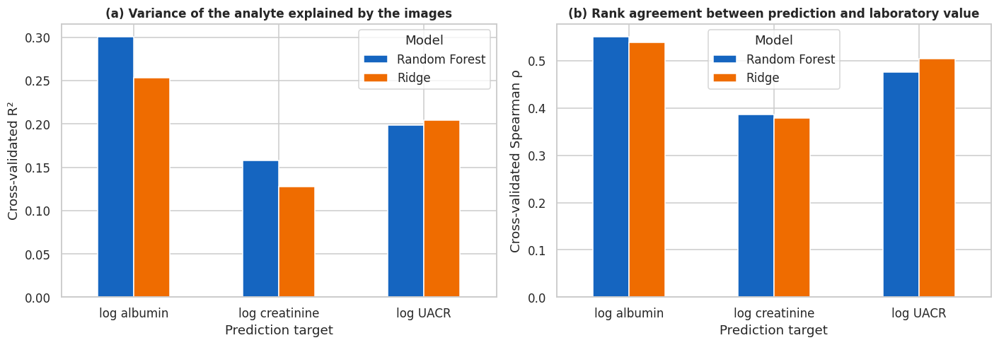

**Figure A1.** Measurement audit: cross-validated R² (a) and Spearman ρ (b) for predicting log₁₀ urine albumin (albumin-image features), log₁₀ urine creatinine (creatinine-image features) and log₁₀ UACR (all features). R² near 0 means no usable information.

RMSE (log₁₀)     R²  Spearman ρ
Target         Model                                         
log UACR       Random Forest         0.868  0.198       0.476
               Ridge                 0.864  0.204       0.504
log albumin    Random Forest         0.807  0.300       0.550
               Ridge                 0.833  0.254       0.539
log creatinine Random Forest         0.360  0.158       0.386
               Ridge                 0.367  0.127       0.379

In [21]:
class UnivariateTopKReg(BaseEstimator, TransformerMixin):
    """Feature selection for regression: |Spearman rho| with the continuous target + greedy correlation redundancy filter."""
    def __init__(self, k=10, corr_thr=0.90):
        self.k = k; self.corr_thr = corr_thr
    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
        Xr, yr = rankdata(X, axis=0), rankdata(y)
        Xc, yc = Xr - Xr.mean(0), yr - yr.mean()
        rho = np.nan_to_num((Xc * yc[:, None]).sum(0) / (np.sqrt((Xc ** 2).sum(0) * (yc ** 2).sum()) + 1e-12))
        order = np.argsort(-np.abs(rho))
        Z = (X - X.mean(0)) / (X.std(0) + 1e-12)
        sel = []
        for j in order:
            if len(sel) >= self.k: break
            if not sel:
                sel.append(j); continue
            if (np.abs(Z[:, sel].T @ Z[:, j]) / len(Z)).max() < self.corr_thr:
                sel.append(j)
        self.support_ = np.array(sel, dtype=int); self.rho_ = rho
        return self
    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.support_]

def _imputer():
    try: return SimpleImputer(strategy='median', keep_empty_features=True)
    except TypeError: return SimpleImputer(strategy='median')

# ---- the diagnostic data table (laboratory values: diagnostics only) ----
lab_i = labels.set_index('sample')
d8 = df_clean.copy()
d8['alb_mgL'] = d8['sample'].map(lab_i['alb_mgL']); d8['cre_mgdL'] = d8['sample'].map(lab_i['cre_mgdL'])
d8['log_alb'] = np.log10(d8.alb_mgL.clip(lower=1)); d8['log_cre'] = np.log10(d8.cre_mgdL.clip(lower=1)); d8['log_uacr'] = np.log10(d8.uacr.clip(lower=1))
D8 = d8.dropna(subset=['log_alb', 'log_cre', 'log_uacr']).reset_index(drop=True)
print(f'Diagnostic table: {len(D8)} tests / {D8["sample"].nunique()} samples with complete laboratory values')
put('audit.n_tests', len(D8)); put('audit.n_samples', D8['sample'].nunique())

DIAG_MODELS = {
    'Ridge': lambda: Pipeline([('imp', _imputer()), ('rs', RobustScaler()), ('sel', UnivariateTopKReg(k=20, corr_thr=CFG['CORR_THR'])), ('sc', StandardScaler()), ('m', Ridge(alpha=30.0))]),
    'Random Forest': lambda: Pipeline([('imp', _imputer()), ('sel', UnivariateTopKReg(k=20, corr_thr=CFG['CORR_THR'])),
                                       ('m', RandomForestRegressor(n_estimators=150, min_samples_leaf=3, random_state=SEED, n_jobs=1))]),
}
DIAG_REPS = CFG['DIAG_REPS']
DIAG_SPLITS = [list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 300 + r).split(D8, D8['y'], D8['sample'])) for r in range(DIAG_REPS)]
DIAG_SETS = {'log albumin': ('log_alb', 'alb__'), 'log creatinine': ('log_cre', 'cre__'), 'log UACR': ('log_uacr', '')}

def _src(prefix):
    return [c for c in FEATS if c.startswith(prefix)] if prefix else list(FEATS)

def _job(j):
    tn, mn, rep, fi = j
    target, prefix = DIAG_SETS[tn]; tri, tei = DIAG_SPLITS[rep][fi]
    X, yv = D8[_src(prefix)].values, D8[target].values
    m = DIAG_MODELS[mn](); m.fit(X[tri], yv[tri])
    return m.predict(X[tei])

jobs = [(tn, mn, rep, fi) for tn in DIAG_SETS for mn in DIAG_MODELS for rep in range(DIAG_REPS) for fi in range(5)]
outs = Parallel(n_jobs=-1)(delayed(_job)(j) for j in tqdm(jobs, desc='Diagnostic regressions'))
PRED = {}
for j, o in zip(jobs, outs):
    tn, mn, rep, fi = j
    arr = PRED.setdefault((tn, mn), np.zeros((DIAG_REPS, len(D8))))
    arr[rep, DIAG_SPLITS[rep][fi][1]] = o

rows = []
for (tn, mn), arr in PRED.items():
    yv = D8[DIAG_SETS[tn][0]].values
    rows.append({'Target': tn, 'Model': mn, 'Features': len(_src(DIAG_SETS[tn][1])),
                 'R²': np.mean([r2_score(yv, a) for a in arr]), 'RMSE (log₁₀)': np.mean([np.sqrt(np.mean((yv - a) ** 2)) for a in arr]),
                 'Spearman ρ': np.mean([sps.spearmanr(yv, a)[0] for a in arr]), 'SD of target (log₁₀)': yv.std()})
diag_reg = pd.DataFrame(rows).sort_values(['Target', 'Model'])
save_table(diag_reg.round(3), 'diagnostic_regression', f'Measurement audit: grouped cross-validated prediction of the laboratory analytes from image features. {DIAG_REPS} × 5-fold, folds are grouped by sample.', index=False)
put('audit.regression', diag_reg.round(4).to_dict(orient='records'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
pv = diag_reg.pivot(index='Target', columns='Model', values='R²').reindex(list(DIAG_SETS))
pv.plot(kind='bar', ax=ax[0], color=['#1565C0', '#EF6C00'], rot=0)
ax[0].axhline(0, c='k', lw=.8); ax[0].set_ylabel('Cross-validated R²'); ax[0].set_xlabel('Prediction target'); ax[0].set_title('(a) Variance of the analyte explained by the images'); ax[0].legend(title='Model')
pr_ = diag_reg.pivot(index='Target', columns='Model', values='Spearman ρ').reindex(list(DIAG_SETS))
pr_.plot(kind='bar', ax=ax[1], color=['#1565C0', '#EF6C00'], rot=0)
ax[1].axhline(0, c='k', lw=.8); ax[1].set_ylabel('Cross-validated Spearman ρ'); ax[1].set_xlabel('Prediction target'); ax[1].set_title('(b) Rank agreement between prediction and laboratory value'); ax[1].legend(title='Model')
fig.tight_layout()
save_fig(fig, 'diagnostic_regression', 'Measurement audit: cross-validated R² (a) and Spearman ρ (b) for predicting log₁₀ urine albumin (albumin-image features), log₁₀ urine creatinine (creatinine-image features) and log₁₀ UACR (all features). R² near 0 means no usable information.')
display(diag_reg.pivot_table(index=['Target', 'Model'], values=['R²', 'Spearman ρ', 'RMSE (log₁₀)']).round(3))

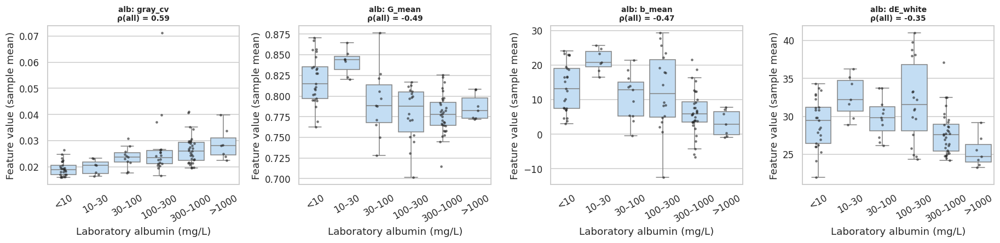

**Figure A2.** Dose–response of four pre-specified albumin-image features across laboratory albumin bins. A monotonic trend within and across bins indicates a usable analytical response.

**Table A2.** Within-band response: Spearman |ρ| between albumin-image features and log₁₀ laboratory albumin inside each albumin band; the permutation null (95th percentile of the maximum |ρ| over all features when the target is shuffled) shows what the best feature would reach by chance.

,Albumin band,Samples,Features,median |ρ|,P90 |ρ|,max |ρ|,null 95% of max |ρ|,max exceeds null
0,< 30 mg/L,32,90,0.261,0.446,0.490,0.495,False
1,30–300 mg/L,29,90,0.094,0.224,0.406,0.565,False
2,> 300 mg/L,39,90,0.186,0.376,0.432,0.471,False


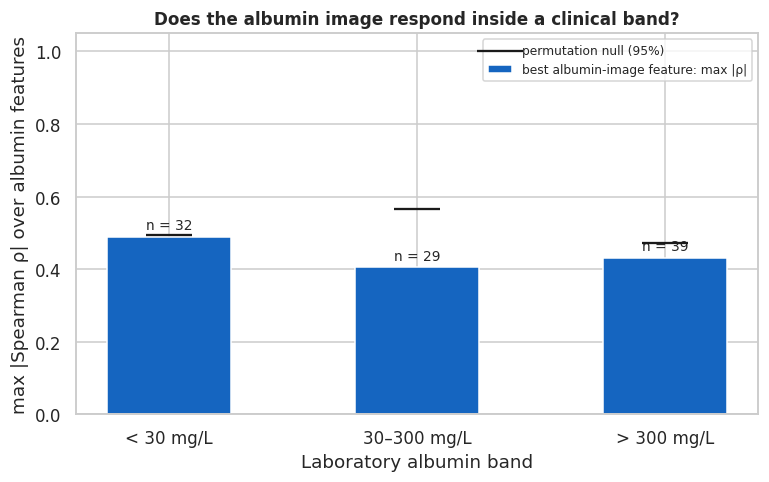

**Figure A3.** Within-band response of the best albumin-image feature compared with the permutation null; bars at or below the black marks are indistinguishable from chance.

In [22]:
# ---------- 9.2 Dose–response and within-band analysis (albumin image vs laboratory albumin) ----------
SAMP = D8.groupby('sample').mean(numeric_only=True)
SAMP['alb_bin'] = pd.cut(SAMP.alb_mgL, [-1, 10, 30, 100, 300, 1000, np.inf], labels=['<10', '10–30', '30–100', '100–300', '300–1000', '>1000'])
SHOW = [c for c in ['alb__gray_cv', 'alb__G_mean', 'alb__b_mean', 'alb__dE_white'] if c in SAMP.columns]   # pre-specified, colorimetrically motivated
fig, axs = plt.subplots(1, len(SHOW), figsize=(4.2 * len(SHOW), 4.2))
axs = np.atleast_1d(axs)
for ax, c in zip(axs, SHOW):
    sns.boxplot(data=SAMP, x='alb_bin', y=c, color='#BBDEFB', showfliers=False, ax=ax); sns.stripplot(data=SAMP, x='alb_bin', y=c, color='k', size=3, alpha=.6, ax=ax)
    rho_all = sps.spearmanr(SAMP[c], SAMP['log_alb'], nan_policy='omit')[0]
    ax.set_title(f'{c.replace("__", ": ")}\nρ(all) = {rho_all:.2f}', fontsize=9); ax.set_xlabel('Laboratory albumin (mg/L)'); ax.set_ylabel('Feature value (sample mean)'); ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
save_fig(fig, 'dose_response_bins', 'Dose–response of four pre-specified albumin-image features across laboratory albumin bins. A monotonic trend within and across bins indicates a usable analytical response.')

BANDS = {'< 30 mg/L': (0, 30), '30–300 mg/L': (30, 300), '> 300 mg/L': (300, np.inf)}
def band_rho(feats_, lo, hi, nperm=300):
    s = SAMP[(SAMP.alb_mgL >= lo) & (SAMP.alb_mgL < hi)]
    Xr = rankdata(SimpleImputer(strategy='median').fit_transform(s[feats_]), axis=0); Xc = Xr - Xr.mean(0); Xn = Xc / (np.sqrt((Xc ** 2).sum(0)) + 1e-12)
    yr = rankdata(s['log_alb']); yc = yr - yr.mean(); yn = yc / np.sqrt((yc ** 2).sum())
    rho = np.abs(Xn.T @ yn); rng = np.random.default_rng(SEED)
    null_max = np.array([np.abs(Xn.T @ rng.permutation(yn)).max() for _ in range(nperm)])
    return len(s), rho, float(np.percentile(null_max, 95))
rows = []
alb_feats = [c for c in FEATS if c.startswith('alb__')]
for bn, (lo, hi) in BANDS.items():
    n_, rho, nul = band_rho(alb_feats, lo, hi)
    rows.append({'Albumin band': bn, 'Samples': n_, 'Features': len(alb_feats), 'median |ρ|': np.median(rho), 'P90 |ρ|': np.percentile(rho, 90),
                 'max |ρ|': rho.max(), 'null 95% of max |ρ|': nul, 'max exceeds null': bool(rho.max() > nul)})
band_tab = pd.DataFrame(rows)
save_table(band_tab.round(3), 'within_band_response', 'Within-band response: Spearman |ρ| between albumin-image features and log₁₀ laboratory albumin inside each albumin band; the permutation null (95th percentile of the maximum |ρ| over all features when the target is shuffled) shows what the best feature would reach by chance.', index=False)
put('audit.within_band', band_tab.round(4).to_dict(orient='records'))

fig, ax = plt.subplots(figsize=(8, 4.5))
xb = np.arange(len(BANDS))
ax.bar(xb, band_tab['max |ρ|'], 0.5, color='#1565C0', label='best albumin-image feature: max |ρ|')
ax.scatter(xb, band_tab['null 95% of max |ρ|'], marker='_', s=900, c='k', zorder=5, label='permutation null (95%)')
for i_, r_ in band_tab.iterrows():
    ax.text(i_, r_['max |ρ|'] + 0.02, f'n = {r_["Samples"]}', ha='center', fontsize=9)
ax.set_xticks(xb); ax.set_xticklabels(list(BANDS)); ax.set_xlabel('Laboratory albumin band'); ax.set_ylabel('max |Spearman ρ| over albumin features'); ax.set_ylim(0, 1.05); ax.legend(loc='upper right', fontsize=8)
ax.set_title('Does the albumin image respond inside a clinical band?')
save_fig(fig, 'within_band_response', 'Within-band response of the best albumin-image feature compared with the permutation null; bars at or below the black marks are indistinguishable from chance.')

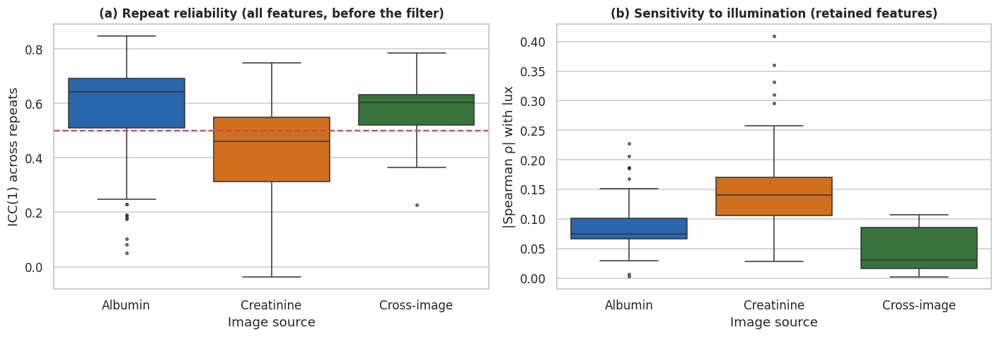

**Figure A4.** Reliability and illumination sensitivity by image source: (a) ICC(1) across repeated tests (red line = filter threshold), (b) |ρ| with lux of the retained features (lower is better).

**Table A3.** Reliability (ICC) before the filter and illumination sensitivity after the filter, by image source.

,features,median_ICC,pct_ICC_ok,median |ρ| lux (retained)
source,,,,
Albumin,118,0.643,76.271,0.075
Creatinine,118,0.461,34.746,0.141
Cross-image,41,0.603,78.049,0.031


**Table A4.** Error budget: macro-F1 obtained when an analyte is replaced by its laboratory value (oracle rows) versus predicted from images (Random Forest regressors, grouped cross-validation). Oracle rows are upper bounds, not achievable results.

,Macro-F1
Scenario (macro-F1 at 30 / 300 mg/g),
True albumin + true creatinine (reference check),0.990
True albumin + constant creatinine (median),0.727
True albumin + creatinine predicted from image,0.799
Albumin predicted from image + true creatinine,0.520
Albumin predicted from image + constant creatinine,0.478
Albumin and creatinine both predicted from images,0.467
log UACR predicted directly from images,0.470


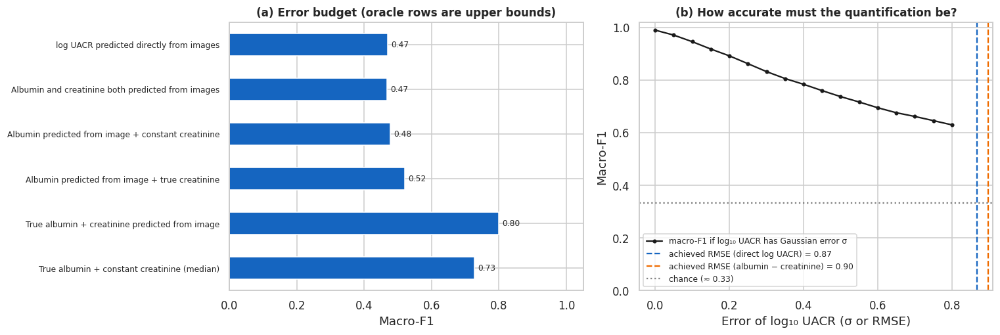

**Figure A5.** (a) Error budget: macro-F1 when albumin or creatinine is replaced by laboratory values; (b) simulated macro-F1 against the error of log₁₀ UACR, with the RMSE actually achieved by the image features (dashed lines).

Audit summary: {'r2_log_albumin_RF': 0.3, 'r2_log_creatinine_RF': 0.158, 'r2_log_uacr_RF': 0.198, 'rmse_log_uacr_direct': 0.868, 'rmse_log_uacr_alb_minus_cre': 0.898, 'sigma_grid': '...', 'macro_f1_vs_sigma': '...'}


In [23]:
# ---------- 9.3 Reproducibility and illumination sensitivity by source ----------
rel = pd.DataFrame({'feature': icc.index, 'ICC': icc.values})
rel['source'] = rel.feature.map(source_of); rel['group'] = rel.feature.map(family_of)
lux_abs = {}
for c in FEATS:
    v = df_clean[[c, 'lux']].dropna()
    lux_abs[c] = abs(sps.spearmanr(v[c], v['lux'])[0]) if v[c].nunique() > 2 and v['lux'].nunique() > 2 else np.nan
lx = pd.DataFrame({'feature': list(lux_abs), '|ρ| lux': list(lux_abs.values())}); lx['source'] = lx.feature.map(source_of)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=rel, x='source', y='ICC', palette=[SRC_COL[s_] for s_ in ('Albumin', 'Creatinine', 'Cross-image')], order=['Albumin', 'Creatinine', 'Cross-image'], ax=axs[0], fliersize=2)
axs[0].axhline(CFG['ICC_MIN'], c='r', ls='--'); axs[0].set_xlabel('Image source'); axs[0].set_ylabel('ICC(1) across repeats'); axs[0].set_title('(a) Repeat reliability (all features, before the filter)')
sns.boxplot(data=lx, x='source', y='|ρ| lux', palette=[SRC_COL[s_] for s_ in ('Albumin', 'Creatinine', 'Cross-image')], order=['Albumin', 'Creatinine', 'Cross-image'], ax=axs[1], fliersize=2)
axs[1].set_xlabel('Image source'); axs[1].set_ylabel('|Spearman ρ| with lux'); axs[1].set_title('(b) Sensitivity to illumination (retained features)')
fig.tight_layout()
save_fig(fig, 'reliability_by_source', 'Reliability and illumination sensitivity by image source: (a) ICC(1) across repeated tests (red line = filter threshold), (b) |ρ| with lux of the retained features (lower is better).')
rel_tab = rel.groupby('source').agg(features=('ICC', 'size'), median_ICC=('ICC', 'median'), pct_ICC_ok=('ICC', lambda s: (s >= CFG['ICC_MIN']).mean() * 100)).join(
    lx.groupby('source')['|ρ| lux'].median().rename('median |ρ| lux (retained)')).round(3)
save_table(rel_tab, 'reliability_by_source', 'Reliability (ICC) before the filter and illumination sensitivity after the filter, by image source.')
put('audit.reliability_by_source', rel_tab.reset_index().to_dict(orient='records'))

# ---------- 9.4 Error budget: what if one analyte were known exactly? ----------
def cls_log(v): return np.where(v < np.log10(30), 0, np.where(v <= np.log10(300), 1, 2))
yD = D8['y'].values; la, lc, lu = D8.log_alb.values, D8.log_cre.values, D8.log_uacr.values
cre_const = np.median(lc)
def f1c(p): return f1_score(yD, cls_log(p), average='macro')
scen = {}
scen['True albumin + true creatinine (reference check)'] = f1c(la - lc + 2)
scen['True albumin + constant creatinine (median)'] = f1c(la - cre_const + 2)
PA, PC, PU = (PRED[(t, 'Random Forest')] for t in ('log albumin', 'log creatinine', 'log UACR'))
for lbl, fn in [('True albumin + creatinine predicted from image', lambda pa, pc, pu: la - pc + 2),
                ('Albumin predicted from image + true creatinine', lambda pa, pc, pu: pa - lc + 2),
                ('Albumin predicted from image + constant creatinine', lambda pa, pc, pu: pa - cre_const + 2),
                ('Albumin and creatinine both predicted from images', lambda pa, pc, pu: pa - pc + 2),
                ('log UACR predicted directly from images', lambda pa, pc, pu: pu)]:
    scen[lbl] = np.mean([f1c(fn(PA[r], PC[r], PU[r])) for r in range(DIAG_REPS)])
ob = pd.DataFrame({'Macro-F1': scen}); ob.index.name = 'Scenario (macro-F1 at 30 / 300 mg/g)'
save_table(ob.round(3), 'error_budget', 'Error budget: macro-F1 obtained when an analyte is replaced by its laboratory value (oracle rows) versus predicted from images (Random Forest regressors, grouped cross-validation). Oracle rows are upper bounds, not achievable results.')
put('audit.error_budget', {k: float(v) for k, v in scen.items()})

rng_ = np.random.default_rng(SEED); true_u = la - lc + 2
sig_grid = np.arange(0, 0.85, 0.05)
f1_sig = [np.mean([f1c(true_u + rng_.normal(0, s, len(yD))) for _ in range(100)]) for s in sig_grid]
rmse_u = float(np.mean([np.sqrt(np.mean((PU[r] - lu) ** 2)) for r in range(DIAG_REPS)]))
rmse_ab = float(np.mean([np.sqrt(np.mean(((PA[r] - PC[r] + 2) - true_u) ** 2)) for r in range(DIAG_REPS)]))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
ob.iloc[1:].plot(kind='barh', ax=axs[0], color='#1565C0', legend=False); axs[0].set_xlabel('Macro-F1'); axs[0].set_ylabel(''); axs[0].set_title('(a) Error budget (oracle rows are upper bounds)'); axs[0].set_xlim(0, 1.05); axs[0].tick_params(axis='y', labelsize=8)
for i_, v_ in enumerate(ob['Macro-F1'].iloc[1:]): axs[0].text(v_ + .01, i_, f'{v_:.2f}', va='center', fontsize=8)
axs[1].plot(sig_grid, f1_sig, 'k-o', ms=3, label='macro-F1 if log₁₀ UACR has Gaussian error σ')
axs[1].axvline(rmse_u, c='#1565C0', ls='--', label=f'achieved RMSE (direct log UACR) = {rmse_u:.2f}')
axs[1].axvline(rmse_ab, c='#EF6C00', ls='--', label=f'achieved RMSE (albumin − creatinine) = {rmse_ab:.2f}')
axs[1].axhline(1 / 3, c='gray', ls=':', label='chance (≈ 0.33)'); axs[1].set_xlabel('Error of log₁₀ UACR (σ or RMSE)'); axs[1].set_ylabel('Macro-F1'); axs[1].set_ylim(0, 1.02); axs[1].legend(fontsize=8)
axs[1].set_title('(b) How accurate must the quantification be?')
fig.tight_layout()
save_fig(fig, 'error_budget', '(a) Error budget: macro-F1 when albumin or creatinine is replaced by laboratory values; (b) simulated macro-F1 against the error of log₁₀ UACR, with the RMSE actually achieved by the image features (dashed lines).')

put('audit.summary', dict(r2_log_albumin_RF=float(diag_reg[(diag_reg.Target == 'log albumin') & (diag_reg.Model == 'Random Forest')]['R²'].iloc[0]),
                          r2_log_creatinine_RF=float(diag_reg[(diag_reg.Target == 'log creatinine') & (diag_reg.Model == 'Random Forest')]['R²'].iloc[0]),
                          r2_log_uacr_RF=float(diag_reg[(diag_reg.Target == 'log UACR') & (diag_reg.Model == 'Random Forest')]['R²'].iloc[0]),
                          rmse_log_uacr_direct=rmse_u, rmse_log_uacr_alb_minus_cre=rmse_ab, sigma_grid=sig_grid, macro_f1_vs_sigma=f1_sig))
print('Audit summary:', {k: (round(v, 3) if isinstance(v, float) else '...') for k, v in NUM['audit']['summary'].items()})
stage_done('9 measurement audit')

# Stage 12 · Significance Testing and Feature Selection

**Purpose.** From the 163 reliable features, identify those that statistically and predictively separate NORMAL–MICRO–MACRO, and define the **selection procedure** that is used inside every cross-validation fold and for the final model.

**Two roles, kept separate.**
* **Descriptive role (this stage).** The significance tests are run once on all samples (sample level = mean of repeats, so the observations are independent and *p*-values are not inflated by pseudo-replication). The result is a table for the report: which features carry class information, how large the effects are, and which method groups are most informative. These results **do not** feed any model.
* **Operational role (Stages 12–15).** The same selection rule is implemented as the pipeline step `UnivariateTopK` and is **recomputed inside every training fold**, so validation data never help determine the features.

**Significance measures used (complementary):**

| Measure | Question answered | Note |
|---|---|---|
| ANOVA *F* | Do the feature means differ between classes? | Parametric |
| Kruskal–Wallis *H* + ε² | Does the feature distribution differ between classes? | Non-parametric; ε² = H/(n−1) as effect size |
| Spearman ρ against the ordinal class (0,1,2) | Does the feature change monotonically with severity? | Suitable because NORMAL < MICRO < MACRO is ordered |
| *Mutual information* | Is there a non-linear dependence on the class? | Makes no assumption about the form of the relation |
| Pairwise Mann–Whitney test (NORMAL–MICRO, MICRO–MACRO) | At which threshold does the feature discriminate? | Holm correction |

The Kruskal–Wallis *p*-values are corrected for **multiple testing** with the **Benjamini–Hochberg (FDR)** procedure to obtain *q-values*.

**Operational selector (`UnivariateTopK`).** Composite rank = mean of the ANOVA-*F* rank and the |ordinal ρ| rank. Features are selected **greedily** by rank, skipping any feature whose |r| > `CORR_THR` with an already selected feature (redundancy filter). The number of features *k* is a hyperparameter chosen from `K_GRID` by the inner cross-validation. At the end of the stage, a **k-curve** shows how performance depends on *k* with default hyperparameters (descriptive; the actual choice is made by tuning).

Significance tests use 100 samples (mean of repeats).
Significant features (q-FDR < 0.05): 116 of 163 (71.2%)


,significant,tested
source,,
Albumin,67,90
Creatinine,28,41
Cross-image,21,32


**Table A5.** Significance test results for all features (sample level, descriptive): ANOVA, Kruskal–Wallis (q-FDR), ε², ordinal Spearman, mutual information, pairwise tests (Holm).

**Table A6.** The 20 features with the highest composite rank and their significance statistics (all samples, descriptive).

,feature,F_anova,epsilon2,rho_ordinal,MI,q_FDR,p_NORMAL_vs_MICRO,p_MICRO_vs_MACRO
0,alb__V_p10,13.260,0.255,-0.505,0.186,7.20e-05,1.00e+00,6.45e-01
1,alb__G_p10,12.972,0.247,-0.497,0.184,7.20e-05,1.00e+00,1.00e+00
2,alb__V_median,13.491,0.222,-0.471,0.140,1.47e-04,1.00e+00,5.59e-01
3,alb__glcm_homogeneity,13.174,0.245,-0.471,0.083,7.20e-05,6.87e-01,1.00e+00
4,alb__L_p10,12.602,0.236,-0.486,0.138,9.21e-05,1.00e+00,1.00e+00
5,alb__glcm_dissimilarity,13.032,0.246,0.472,0.079,7.20e-05,6.87e-01,1.00e+00
6,alb__V_mean,13.258,0.221,-0.469,0.150,1.47e-04,1.00e+00,6.45e-01
7,alb__lbp_6,15.937,0.229,0.459,0.192,1.24e-04,6.56e-01,1.00e+00
8,alb__gray_entropy,11.565,0.283,0.512,0.105,6.79e-05,2.89e-01,1.00e+00
9,alb__G_median,13.101,0.215,-0.463,0.136,1.54e-04,1.00e+00,1.00e+00


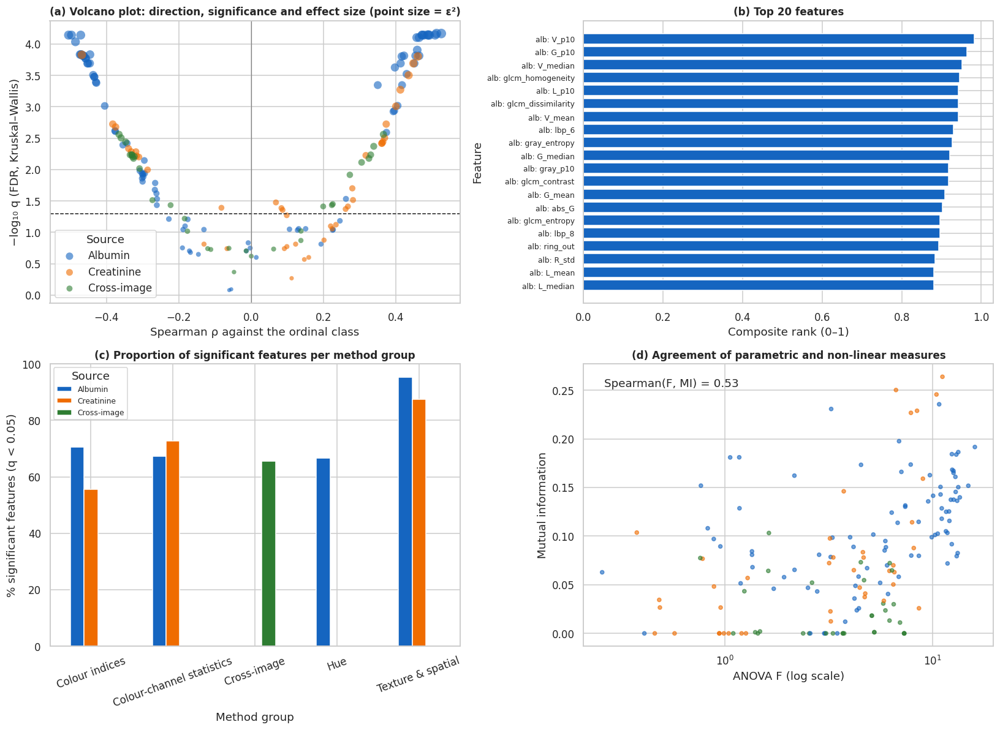

**Figure A6.** Feature significance tests (all samples, descriptive): (a) volcano plot, (b) top 20 features, (c) proportion of significant features per method group, (d) agreement between ANOVA-F and mutual information.

In [24]:
class UnivariateTopK(BaseEstimator, TransformerMixin):
    """Feature selection: composite rank (ANOVA-F + |ordinal Spearman|) with a greedy correlation redundancy filter."""
    def __init__(self, k=10, corr_thr=0.90):
        self.k = k; self.corr_thr = corr_thr

    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y)
        F, _ = f_classif(X, y); F = np.nan_to_num(F)
        Xr, yr = rankdata(X, axis=0), rankdata(y)
        Xc, yc = Xr - Xr.mean(0), yr - yr.mean()
        rho = np.nan_to_num((Xc * yc[:, None]).sum(0) / (np.sqrt((Xc ** 2).sum(0) * (yc ** 2).sum()) + 1e-12))
        score = (rankdata(F) + rankdata(np.abs(rho))) / 2.0
        order = np.argsort(-score)
        Z = (X - X.mean(0)) / (X.std(0) + 1e-12)
        sel = []
        for j in order:
            if len(sel) >= self.k: break
            if not sel:
                sel.append(j); continue
            c = np.abs(Z[:, sel].T @ Z[:, j]) / len(Z)
            if c.max() < self.corr_thr:
                sel.append(j)
        self.support_ = np.array(sel, dtype=int); self.scores_ = score; self.F_ = F; self.rho_ = rho
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.support_]

def make_pipe(clf, k=10):
    return Pipeline([('imp', _imputer()), ('rs', RobustScaler()), ('sel', UnivariateTopK(k=k, corr_thr=CFG['CORR_THR'])),
                     ('sc', StandardScaler()), ('clf', clf)])

# ---------- Sample-level significance tests (descriptive; all samples) ----------
S = df_clean.groupby('sample')[FEATS].mean()
yS = df_clean.groupby('sample')['y'].first().loc[S.index].values
n_s = len(S)
print(f'Significance tests use {n_s} samples (mean of repeats).')

Sv = SimpleImputer(strategy='median').fit_transform(S)
F, pF = f_classif(Sv, yS)
H = np.zeros(len(FEATS)); pK = np.ones(len(FEATS)); rho_o = np.zeros(len(FEATS))
pw_nm = np.ones(len(FEATS)); pw_mm = np.ones(len(FEATS))
for j in range(Sv.shape[1]):
    grp = [Sv[yS == c, j] for c in range(3)]
    try:
        H[j], pK[j] = sps.kruskal(*grp)
    except ValueError:
        H[j], pK[j] = 0.0, 1.0
    rho_o[j] = sps.spearmanr(Sv[:, j], yS)[0] if np.std(Sv[:, j]) > 0 else 0.0
    try: pw_nm[j] = sps.mannwhitneyu(grp[0], grp[1], alternative='two-sided').pvalue
    except ValueError: pass
    try: pw_mm[j] = sps.mannwhitneyu(grp[1], grp[2], alternative='two-sided').pvalue
    except ValueError: pass
mi = mutual_info_classif(Sv, yS, random_state=SEED, n_neighbors=3)

def bh(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p); q = np.empty(n)
    q[o] = np.minimum.accumulate((p[o] * n / (np.arange(n) + 1))[::-1])[::-1]
    return np.clip(q, 0, 1)

def holm(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p); q = np.empty(n)
    q[o] = np.minimum(1, np.maximum.accumulate((n - np.arange(n)) * p[o])); return q

sig = pd.DataFrame({'feature': FEATS, 'source': [source_of(c) for c in FEATS], 'group': [family_of(c) for c in FEATS],
                    'F_anova': F, 'p_anova': pF, 'H_kruskal': H, 'p_kruskal': pK, 'epsilon2': H / (n_s - 1),
                    'rho_ordinal': rho_o, 'MI': mi, 'p_NORMAL_vs_MICRO': holm(pw_nm), 'p_MICRO_vs_MACRO': holm(pw_mm)})
sig['q_FDR'] = bh(sig.p_kruskal)
sig['composite_rank'] = (rankdata(sig.F_anova) + rankdata(sig.rho_ordinal.abs())) / 2.0
sig = sig.sort_values('composite_rank', ascending=False).reset_index(drop=True)
sig['significant_FDR05'] = sig.q_FDR < 0.05

print(f'Significant features (q-FDR < 0.05): {sig.significant_FDR05.sum()} of {len(sig)} ({sig.significant_FDR05.mean() * 100:.1f}%)')
by_src = sig.groupby('source').significant_FDR05.agg(['sum', 'count']).rename(columns={'sum': 'significant', 'count': 'tested'})
display(by_src)
save_table(sig.round(6), 'feature_significance_full', 'Significance test results for all features (sample level, descriptive): ANOVA, Kruskal–Wallis (q-FDR), ε², ordinal Spearman, mutual information, pairwise tests (Holm).', index=False, show=False)
top_tab = sig.head(20)[['feature', 'F_anova', 'epsilon2', 'rho_ordinal', 'MI', 'q_FDR', 'p_NORMAL_vs_MICRO', 'p_MICRO_vs_MACRO']].copy()
for c in ('F_anova', 'epsilon2', 'rho_ordinal', 'MI'): top_tab[c] = top_tab[c].round(3)
for c in ('q_FDR', 'p_NORMAL_vs_MICRO', 'p_MICRO_vs_MACRO'): top_tab[c] = top_tab[c].map(lambda v: f'{v:.2e}')
save_table(top_tab, 'top20_significant_features', 'The 20 features with the highest composite rank and their significance statistics (all samples, descriptive).', index=False)
put('significance', dict(n_samples=n_s, n_tested=len(sig), n_significant_q05=int(sig.significant_FDR05.sum()), percent_significant=float(sig.significant_FDR05.mean() * 100),
                         by_source=by_src.to_dict(orient='index'), top20=sig.head(20)[['feature', 'F_anova', 'epsilon2', 'rho_ordinal', 'MI', 'q_FDR']].to_dict(orient='records'),
                         by_group=sig.groupby('group').significant_FDR05.agg(['sum', 'count']).to_dict(orient='index'),
                         n_pairwise_NM_p05=int((sig.p_NORMAL_vs_MICRO < .05).sum()), n_pairwise_MM_p05=int((sig.p_MICRO_vs_MACRO < .05).sum())))

# ---------- Significance visualisation ----------
fig, axs = plt.subplots(2, 2, figsize=(15, 11))
for s_, g in sig.groupby('source'):
    axs[0, 0].scatter(g.rho_ordinal, -np.log10(g.q_FDR.clip(lower=1e-30)), s=18 + 300 * g.epsilon2.clip(0, 1), alpha=.6, c=SRC_COL[s_], label=s_, edgecolor='none')
axs[0, 0].axhline(-np.log10(0.05), c='k', ls='--', lw=1); axs[0, 0].axvline(0, c='gray', lw=.8)
axs[0, 0].set_xlabel('Spearman ρ against the ordinal class'); axs[0, 0].set_ylabel('−log₁₀ q (FDR, Kruskal–Wallis)'); axs[0, 0].legend(title='Source')
axs[0, 0].set_title('(a) Volcano plot: direction, significance and effect size (point size = ε²)')

top = sig.head(20).iloc[::-1]
axs[0, 1].barh(top.feature.str.replace('__', ': '), top.composite_rank / len(sig), color=[SRC_COL[s_] for s_ in top.source])
axs[0, 1].set_xlabel('Composite rank (0–1)'); axs[0, 1].set_ylabel('Feature'); axs[0, 1].set_title('(b) Top 20 features'); axs[0, 1].tick_params(axis='y', labelsize=8)

fam_sig = sig.groupby(['group', 'source']).significant_FDR05.mean().unstack().fillna(0) * 100
fam_sig.plot(kind='bar', ax=axs[1, 0], color=[SRC_COL[c] for c in fam_sig.columns])
axs[1, 0].set_ylabel('% significant features (q < 0.05)'); axs[1, 0].set_xlabel('Method group'); axs[1, 0].set_title('(c) Proportion of significant features per method group')
axs[1, 0].tick_params(axis='x', rotation=20); axs[1, 0].legend(title='Source', fontsize=8)

axs[1, 1].scatter(sig.F_anova, sig.MI, c=[SRC_COL[s_] for s_ in sig.source], s=16, alpha=.6)
axs[1, 1].set_xscale('log'); axs[1, 1].set_xlabel('ANOVA F (log scale)'); axs[1, 1].set_ylabel('Mutual information')
axs[1, 1].set_title('(d) Agreement of parametric and non-linear measures')
rho_fm = sps.spearmanr(sig.F_anova, sig.MI)[0]
axs[1, 1].text(0.05, 0.92, f'Spearman(F, MI) = {rho_fm:.2f}', transform=axs[1, 1].transAxes)
fig.tight_layout()
save_fig(fig, 'feature_significance', 'Feature significance tests (all samples, descriptive): (a) volcano plot, (b) top 20 features, (c) proportion of significant features per method group, (d) agreement between ANOVA-F and mutual information.')
put('significance.spearman_F_vs_MI', rho_fm)

Modelling data: 478 tests, 100 samples, 163 features | models: ['Logistic Regression', 'SVM (RBF)', 'Random Forest', 'Gradient Boosting', 'k-NN'] | k grid: [5, 10, 20]


k curve:   0%|          | 0/225 [00:00<?, ?it/s]

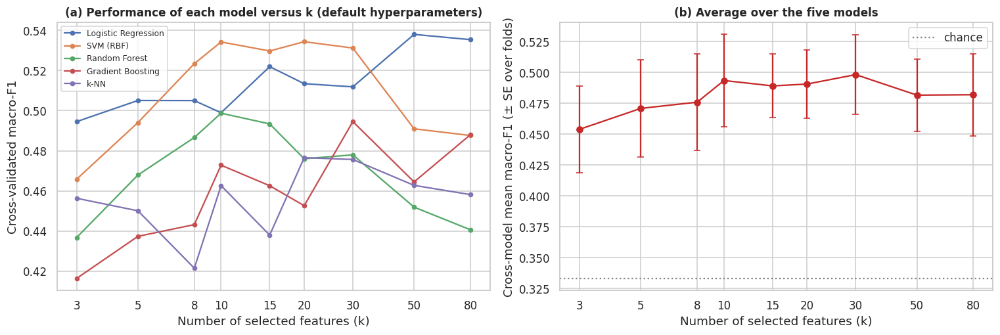

**Figure A7.** Descriptive k-curve: sample-grouped 5-fold cross-validated macro-F1 versus the number of selected features k (feature selection is recomputed inside every fold); (a) each model, (b) cross-model mean ± SE. The k used by the final model is chosen by tuning (grid [5, 10, 20]).

**Table A7.** Cross-validated macro-F1 per model for different numbers of selected features k (default hyperparameters).

model,Gradient Boosting,Logistic Regression,Random Forest,SVM (RBF),k-NN
k,,,,,
3,0.4164,0.4945,0.4368,0.4659,0.4563
5,0.4374,0.5051,0.4679,0.4941,0.4501
8,0.4432,0.5050,0.4866,0.5234,0.4215
10,0.4728,0.4990,0.4987,0.5342,0.4627
15,0.4626,0.5219,0.4934,0.5297,0.4380
20,0.4527,0.5134,0.4760,0.5343,0.4766
30,0.4945,0.5119,0.4780,0.5312,0.4757
50,0.4645,0.5380,0.4519,0.4910,0.4628
80,0.4880,0.5354,0.4407,0.4876,0.4582


In [25]:
# ---------- Model definitions (shared by the k-curve, the nested CV and the final fit) ----------
def get_models(prob=True):
    try:
        hgb = HistGradientBoostingClassifier(class_weight='balanced', random_state=SEED)
    except Exception:
        hgb = GradientBoostingClassifier(random_state=SEED)
    return {
        'Logistic Regression': LogisticRegression(max_iter=5000, class_weight='balanced', random_state=SEED),
        'SVM (RBF)': SVC(kernel='rbf', probability=prob, class_weight='balanced', random_state=SEED),
        'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=SEED, n_jobs=1),
        'Gradient Boosting': hgb,
        'k-NN': KNeighborsClassifier(),
    }
MODEL_NAMES = list(get_models().keys())
USING_HGB = isinstance(get_models()['Gradient Boosting'], HistGradientBoostingClassifier)
FAMILY = {'Logistic Regression': 'Linear', 'SVM (RBF)': 'Kernel (RBF)', 'Random Forest': 'Tree bagging', 'Gradient Boosting': 'Tree boosting', 'k-NN': 'Instance-based'}

def shrink(g):
    return {k: v[:2] for k, v in g.items()} if CFG['FAST_MODE'] else g

# Hyperparameter grids: the SAME grids are used inside the nested CV and in the final fit; k (number of selected features) is tuned too.
GRID = {
    'Logistic Regression': {'clf__C': [0.1, 1, 10]},
    'SVM (RBF)': {'clf__C': [1, 10, 100], 'clf__gamma': ['scale', 0.05]},
    'Random Forest': {'clf__max_depth': [None, 6], 'clf__min_samples_leaf': [1, 3], 'clf__n_estimators': [200]},
    'Gradient Boosting': ({'clf__learning_rate': [0.05, 0.1], 'clf__max_depth': [2, 3], 'clf__max_iter': [150]} if USING_HGB
                          else {'clf__learning_rate': [0.05, 0.1], 'clf__max_depth': [2, 3], 'clf__n_estimators': [150]}),
    'k-NN': {'clf__n_neighbors': [3, 7, 15], 'clf__weights': ['uniform', 'distance']},
}
GRID = {k: shrink(v) for k, v in GRID.items()}
K_GRID = [k for k in CFG['K_GRID'] if k <= len(FEATS)]

def full_grid(name):
    g = dict(GRID[name]); g['sel__k'] = K_GRID
    return g

# ---------- Master arrays used from here on ----------
X_all = df_clean[FEATS].copy()
y_all = df_clean['y'].values.astype(int)
g_all = df_clean['sample'].values
print(f'Modelling data: {len(X_all)} tests, {len(set(g_all))} samples, {X_all.shape[1]} features | models: {MODEL_NAMES} | k grid: {K_GRID}')

# ---------- k-curve (descriptive): sample-grouped CV with default hyperparameters ----------
def _fold_f1(args):
    mname, k, tri, vai = args
    pipe = make_pipe(get_models(prob=False)[mname], k=k)
    pipe.fit(X_all.iloc[tri], y_all[tri])
    return mname, k, f1_score(y_all[vai], pipe.predict(X_all.iloc[vai]), average='macro')

K_CURVE = [k for k in [3, 5, 8, 10, 15, 20, 30, 50, 80] if k <= len(FEATS)]
spl = list(StratifiedGroupKFold(n_splits=CFG['CURVE_FOLDS'], shuffle=True, random_state=SEED).split(X_all, y_all, g_all))
jobs = [(m, k, a, b) for m in MODEL_NAMES for k in K_CURVE for (a, b) in spl]
res_k = Parallel(n_jobs=-1)(delayed(_fold_f1)(j) for j in tqdm(jobs, desc='k curve'))
kc = pd.DataFrame(res_k, columns=['model', 'k', 'f1'])
kc['fold'] = kc.groupby(['model', 'k']).cumcount()
curve = kc.groupby(['model', 'k']).f1.agg(['mean', 'std']).reset_index()
avg_fold = kc.groupby(['k', 'fold']).f1.mean().reset_index()
avg_curve = avg_fold.groupby('k').f1.agg(['mean', 'std', 'count']); avg_curve['se'] = avg_curve['std'] / np.sqrt(avg_curve['count'])
k_best_curve = int(avg_curve['mean'].idxmax())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for m_ in MODEL_NAMES:
    cm_ = curve[curve.model == m_]; ax[0].plot(cm_.k, cm_['mean'], 'o-', label=m_, ms=4)
ax[0].set_xscale('log'); ax[0].set_xticks(K_CURVE); ax[0].set_xticklabels(K_CURVE)
ax[0].set_xlabel('Number of selected features (k)'); ax[0].set_ylabel('Cross-validated macro-F1'); ax[0].set_title('(a) Performance of each model versus k (default hyperparameters)'); ax[0].legend(fontsize=8)
ax[1].errorbar(avg_curve.index, avg_curve['mean'], yerr=avg_curve['se'], fmt='o-', c='#C62828', capsize=3)
ax[1].axhline(1 / 3, c='gray', ls=':', label='chance')
ax[1].set_xscale('log'); ax[1].set_xticks(K_CURVE); ax[1].set_xticklabels(K_CURVE)
ax[1].set_xlabel('Number of selected features (k)'); ax[1].set_ylabel('Cross-model mean macro-F1 (± SE over folds)'); ax[1].set_title('(b) Average over the five models'); ax[1].legend()
fig.tight_layout()
save_fig(fig, 'k_feature_curve', f'Descriptive k-curve: sample-grouped {CFG["CURVE_FOLDS"]}-fold cross-validated macro-F1 versus the number of selected features k (feature selection is recomputed inside every fold); (a) each model, (b) cross-model mean ± SE. The k used by the final model is chosen by tuning (grid {K_GRID}).')
ktab = curve.pivot(index='k', columns='model', values='mean').round(4); ktab.index.name = 'k'
save_table(ktab, 'k_feature_curve', 'Cross-validated macro-F1 per model for different numbers of selected features k (default hyperparameters).')
put('k_curve', dict(k_best_cross_model_mean=k_best_curve, mean_f1_by_k=avg_curve['mean'].round(4).to_dict(), k_grid_for_tuning=K_GRID))

# Stage 13 · Validation Design and the Five Models

**Purpose.** Describe the validation scheme (the outer folds were frozen in Stage 10) and fix the five competing models. Because this notebook has **no separate hold-out set**, all performance claims come from the nested cross-validation of Stage 13; this stage defines it and proves that it is leak-free.

**Why no hold-out set.** With ≈ 100 samples a 20 % hold-out contains ≈ 20 samples (≈ 5 in each minority class); its macro-F1 would vary by several tenths depending on which samples were drawn, while it would take 20 % of the data away from the final model. Nested cross-validation uses every sample for testing exactly once per repeat and every decision (features, *k*, hyperparameters) is made without the test fold.

**Design.**
* **Outer loop (performance estimate):** `StratifiedGroupKFold` with `OUTER_FOLDS` = 5 folds × `OUTER_REPEATS` = 2 differently shuffled repeats = 10 outer test sets. Groups = sample number, stratified by class. **All five models use the same outer folds**, so their fold-wise scores can be compared with paired tests.
* **Inner loop (tuning):** `GridSearchCV` with `INNER_FOLDS` = 3 sample-grouped folds on the outer training data, optimising macro-F1 over the hyperparameter grid **and** the number of features *k*.
* **Pipeline for every fit:** median imputation → `RobustScaler` → `UnivariateTopK` (*k* features) → `StandardScaler` → classifier. Everything is refitted in every fold.
* **Same procedure for the deployed model:** the final model is produced by applying the *same* `GridSearchCV` (same grids, same 3 inner folds) to all samples (Stage 15).

| No | Model | Family | Tuned hyperparameters | Why chosen |
|---|---|---|---|---|
| 1 | **Logistic Regression** (multinomial, L2) | Linear | `C` | Interpretable linear *baseline* |
| 2 | **SVM with RBF kernel** | Kernel | `C`, `gamma` | Effective on small, medium-dimensional data |
| 3 | **Random Forest** | Tree *bagging* | `max_depth`, `min_samples_leaf` | Resistant to *overfitting*, handles non-linearity and interactions |
| 4 | **Gradient Boosting** (HistGradientBoosting) | Tree *boosting* | `learning_rate`, `max_depth` | Usually the best on tabular data |
| 5 | **k-Nearest Neighbors** | Instance-based | `n_neighbors`, `weights` | Simple non-parametric comparator |

**Class imbalance** (MACRO ≈ 2× NORMAL/MICRO): `class_weight='balanced'` for models that support it; the selection metric is **macro-F1** (every class has equal weight), not accuracy. **Baselines:** a majority-class predictor and a stratified random guess, evaluated on the same outer folds.

In [26]:
put('validation_design', dict(outer_folds=CFG['OUTER_FOLDS'], outer_repeats=CFG['OUTER_REPEATS'], inner_folds=CFG['INNER_FOLDS'], n_outer=len(outer),
                              min_test_samples_per_fold=int(comp['Test samples'].min()), max_test_samples_per_fold=int(comp['Test samples'].max()),
                              min_minority_per_fold={c: int(comp[f'Test {c} (samples)'].min()) for c in CLASSES}, k_grid=K_GRID,
                              grids={k: {a: [str(x) for x in b] for a, b in v.items()} for k, v in GRID.items()}))
grid_rows = []
for m_ in MODEL_NAMES:
    n_h = int(np.prod([len(v) for v in GRID[m_].values()]))
    grid_rows.append({'Model': m_, 'Family': FAMILY[m_], 'Hyperparameter grid': json.dumps({k.replace('clf__', ''): v for k, v in GRID[m_].items()}, default=str),
                      'k grid': str(K_GRID), 'Combinations': n_h * len(K_GRID), 'Fits per inner CV': n_h * len(K_GRID) * CFG['INNER_FOLDS']})
save_table(pd.DataFrame(grid_rows), 'model_definitions', 'The five competing models and their tuning grids (identical in the nested CV and the final fit).', index=False)
stage_done('10-11 selection & validation design')

**Table A8.** The five competing models and their tuning grids (identical in the nested CV and the final fit).

,Model,Family,Hyperparameter grid,k grid,Combinations,Fits per inner CV
0,Logistic Regression,Linear,"{""C"": [0.1, 1, 10]}","[5, 10, 20]",9,27
1,SVM (RBF),Kernel (RBF),"{""C"": [1, 10, 100], ""gamma"": [""scale"", 0.05]}","[5, 10, 20]",18,54
2,Random Forest,Tree bagging,"{""max_depth"": [null, 6], ""min_samples_leaf"": [...","[5, 10, 20]",12,36
3,Gradient Boosting,Tree boosting,"{""learning_rate"": [0.05, 0.1], ""max_depth"": [2...","[5, 10, 20]",12,36
4,k-NN,Instance-based,"{""n_neighbors"": [3, 7, 15], ""weights"": [""unifo...","[5, 10, 20]",18,54


# Stage 14 · Repeated *Nested Cross-Validation* — The Main Performance Estimate

**Why nested CV.** All decisions (feature selection, number of features *k*, hyperparameters) are made **only inside the training part** of every outer iteration; the outer test fold is used once, for scoring. The result therefore estimates the performance of the **entire procedure** on samples it has never seen — and the deployed model is made by this same procedure.

**Outputs of this stage.**
1. Fold-wise metrics for the five models and two baselines (test level and sample level); mean ± SD over the 10 outer folds.
2. Statistical comparison of the models: Friedman test, Holm-corrected Wilcoxon tests, and the Nadeau–Bengio corrected resampled *t*-test (which accounts for the overlap between training sets and is the more conservative of the two).
3. Out-of-fold (OOF) predictions: confusion matrices, ROC curves, per-class recall and cluster-bootstrap confidence intervals.
4. Stability of the tuned configurations (selected *k* and hyperparameters).
5. **Sensitivity to the split seed** for the selected model (how much would the estimate change with a different random division into folds?).
6. A **label-permutation test** for the selected model (is the performance distinguishable from chance?).

**Two reporting levels.**
* *Test level* — each image pair is scored on its own: the performance of **one measurement**. This is the primary level.
* *Sample level* — the probabilities of the repeats of one sample are averaged before the decision: the performance when a sample is measured several times.

**Selection rule for the deployed model (pre-specified).** The model with the highest mean outer-fold macro-F1 at test level. If the differences between models are not significant (which is likely with ≈ 100 samples), the report states this explicitly; the rule is nevertheless applied, so that the choice is not made after seeing additional results.

Loading cached result: /content/outputs/A_ML/cache/nested_main_38b779d633.pkl


**Table A9.** Nested cross-validation, TEST level (one image pair = one measurement): mean ± SD over 10 outer folds (5 folds × 2 repeats). Chance level of macro-F1 ≈ 0.33 (the majority-class baseline is lower). PRIMARY RESULT.

,Accuracy,Balanced Acc,F1 (macro),MCC,QWK,AUC (macro OvR),Recall NORMAL,Recall MICRO,Recall MACRO
Model,,,,,,,,,
Logistic Regression,0.537 ± 0.074,0.504 ± 0.086,0.495 ± 0.078,0.279 ± 0.117,0.405 ± 0.139,0.679 ± 0.078,0.590 ± 0.167,0.327 ± 0.116,0.595 ± 0.104
SVM (RBF),0.591 ± 0.070,0.523 ± 0.098,0.510 ± 0.090,0.335 ± 0.133,0.458 ± 0.137,0.718 ± 0.068,0.563 ± 0.202,0.229 ± 0.101,0.778 ± 0.080
Random Forest,0.552 ± 0.081,0.490 ± 0.073,0.477 ± 0.077,0.286 ± 0.110,0.429 ± 0.139,0.696 ± 0.081,0.501 ± 0.145,0.232 ± 0.077,0.738 ± 0.134
Gradient Boosting,0.502 ± 0.095,0.447 ± 0.094,0.441 ± 0.088,0.212 ± 0.136,0.364 ± 0.123,0.656 ± 0.090,0.472 ± 0.159,0.233 ± 0.096,0.635 ± 0.140
k-NN,0.550 ± 0.066,0.479 ± 0.090,0.455 ± 0.075,0.267 ± 0.131,0.399 ± 0.157,0.669 ± 0.084,0.549 ± 0.198,0.133 ± 0.080,0.757 ± 0.101
Baseline: majority class,0.501 ± 0.081,0.333 ± 0.000,0.221 ± 0.023,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000
Baseline: stratified random guess,0.380 ± 0.045,0.341 ± 0.045,0.332 ± 0.043,0.002 ± 0.065,-0.048 ± 0.066,0.503 ± 0.032,0.213 ± 0.066,0.289 ± 0.089,0.522 ± 0.065


**Table A10.** Nested cross-validation, SAMPLE level (repeat probabilities averaged before the decision): mean ± SD over 10 outer folds. SECONDARY RESULT.

,Accuracy,Balanced Acc,F1 (macro),MCC,QWK,AUC (macro OvR),Recall NORMAL,Recall MICRO,Recall MACRO
Model,,,,,,,,,
Logistic Regression,0.555 ± 0.104,0.514 ± 0.108,0.507 ± 0.100,0.293 ± 0.167,0.424 ± 0.184,0.694 ± 0.109,0.593 ± 0.213,0.299 ± 0.142,0.649 ± 0.147
SVM (RBF),0.610 ± 0.070,0.540 ± 0.099,0.502 ± 0.092,0.371 ± 0.141,0.513 ± 0.164,0.764 ± 0.081,0.660 ± 0.190,0.135 ± 0.156,0.825 ± 0.106
Random Forest,0.600 ± 0.118,0.549 ± 0.129,0.513 ± 0.123,0.372 ± 0.195,0.510 ± 0.200,0.730 ± 0.106,0.632 ± 0.235,0.226 ± 0.220,0.789 ± 0.168
Gradient Boosting,0.530 ± 0.153,0.468 ± 0.157,0.460 ± 0.149,0.258 ± 0.239,0.399 ± 0.182,0.695 ± 0.131,0.487 ± 0.213,0.208 ± 0.163,0.710 ± 0.237
k-NN,0.580 ± 0.106,0.502 ± 0.135,0.462 ± 0.118,0.319 ± 0.211,0.421 ± 0.220,0.709 ± 0.119,0.590 ± 0.304,0.099 ± 0.117,0.817 ± 0.120
Baseline: majority class,0.500 ± 0.071,0.333 ± 0.000,0.221 ± 0.020,0.000 ± 0.000,0.000 ± 0.000,0.502 ± 0.026,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000
Baseline: stratified random guess,0.390 ± 0.091,0.361 ± 0.104,0.344 ± 0.106,0.017 ± 0.163,-0.085 ± 0.187,0.507 ± 0.099,0.228 ± 0.156,0.319 ± 0.204,0.535 ± 0.154


Deployment candidate by the pre-specified rule: SVM (RBF) (mean outer-fold macro-F1 = 0.510 ± 0.090)


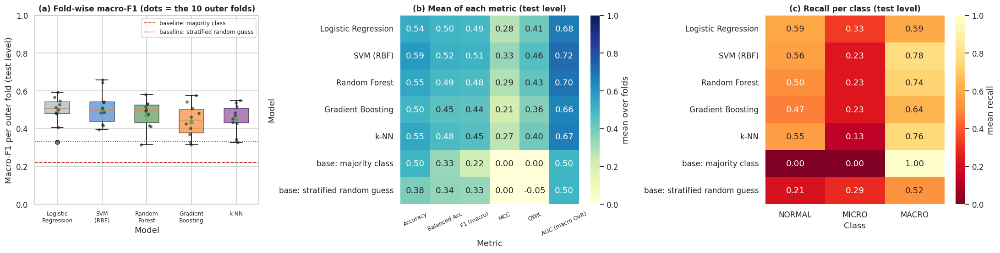

**Figure A8.** Nested cross-validation (10 outer folds): (a) fold-wise macro-F1 of the five models with the two baselines (red lines); (b) mean of the six metrics; (c) mean recall per class. The MICRO column is the critical one.

,F1 (macro),Balanced Acc,MCC,QWK,AUC (macro OvR),Recall NORMAL,Recall MICRO,Recall MACRO
Model,,,,,,,,
Logistic Regression,0.495 ± 0.078,0.504 ± 0.086,0.279 ± 0.117,0.405 ± 0.139,0.679 ± 0.078,0.590 ± 0.167,0.327 ± 0.116,0.595 ± 0.104
SVM (RBF),0.510 ± 0.090,0.523 ± 0.098,0.335 ± 0.133,0.458 ± 0.137,0.718 ± 0.068,0.563 ± 0.202,0.229 ± 0.101,0.778 ± 0.080
Random Forest,0.477 ± 0.077,0.490 ± 0.073,0.286 ± 0.110,0.429 ± 0.139,0.696 ± 0.081,0.501 ± 0.145,0.232 ± 0.077,0.738 ± 0.134
Gradient Boosting,0.441 ± 0.088,0.447 ± 0.094,0.212 ± 0.136,0.364 ± 0.123,0.656 ± 0.090,0.472 ± 0.159,0.233 ± 0.096,0.635 ± 0.140
k-NN,0.455 ± 0.075,0.479 ± 0.090,0.267 ± 0.131,0.399 ± 0.157,0.669 ± 0.084,0.549 ± 0.198,0.133 ± 0.080,0.757 ± 0.101
Baseline: majority class,0.221 ± 0.023,0.333 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000
Baseline: stratified random guess,0.332 ± 0.043,0.341 ± 0.045,0.002 ± 0.065,-0.048 ± 0.066,0.503 ± 0.032,0.213 ± 0.066,0.289 ± 0.089,0.522 ± 0.065


In [27]:
# ---------- 12.1 Metric helpers and nested-CV engine ----------
def metric_dict(y_true, y_pred, proba=None):
    d = {'Accuracy': accuracy_score(y_true, y_pred), 'Balanced Acc': balanced_accuracy_score(y_true, y_pred),
         'Precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
         'Recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
         'F1 (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
         'F1 (weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0),
         'MCC': matthews_corrcoef(y_true, y_pred), 'QWK': cohen_kappa_score(y_true, y_pred, weights='quadratic')}
    try:
        d['AUC (macro OvR)'] = roc_auc_score(y_true, proba, multi_class='ovr', average='macro')
    except Exception:
        d['AUC (macro OvR)'] = np.nan
    return d

def to_sample_level(groups, y_true, proba):
    d = pd.DataFrame(np.asarray(proba), columns=[0, 1, 2]); d['g'] = np.asarray(groups); d['y'] = np.asarray(y_true)
    a = d.groupby('g').agg({**{c: 'mean' for c in (0, 1, 2)}, 'y': 'first'})
    return a['y'].values, a[[0, 1, 2]].values, a.index.values

def recall_per_class(y_true, y_pred):
    cm_ = confusion_matrix(y_true, y_pred, labels=[0, 1, 2]); return cm_.diagonal() / cm_.sum(1).clip(min=1)

def _sig(obj): return hashlib.md5(json.dumps(obj, default=str, sort_keys=True).encode()).hexdigest()[:10]
def cached(name, builder):
    for p in (CACHE_DIR / name, DRIVE_OUT / 'cache' / name):
        try:
            if p.exists():
                print('Loading cached result:', p); return pd.read_pickle(p)
        except Exception as e:
            print('Cache unreadable (', repr(e)[:80], ') -> recomputing')
    res = builder()
    try: pd.to_pickle(res, CACHE_DIR / name)
    except Exception as e: print('Could not write cache (ignored):', repr(e)[:80])
    return res

XM = X_all.values
def nested_task(rep, fold, tri, tei, mname):
    """One outer fold for one model: tune (features k + hyperparameters) on the training part only, score on the test part."""
    pipe = make_pipe(get_models()[mname], k=K_GRID[0])
    spl_ = list(StratifiedGroupKFold(n_splits=CFG['INNER_FOLDS'], shuffle=True, random_state=SEED + rep).split(XM[tri], y_all[tri], g_all[tri]))
    gs = GridSearchCV(pipe, full_grid(mname), scoring='f1_macro', cv=spl_, n_jobs=1, refit=True).fit(XM[tri], y_all[tri])
    return dict(rep=rep, fold=fold, model=mname, tei=tei, proba=gs.predict_proba(XM[tei]), best_k=int(gs.best_params_['sel__k']), inner=float(gs.best_score_),
                params={k.replace('clf__', ''): v for k, v in gs.best_params_.items() if k != 'sel__k'},
                selected=[int(i) for i in gs.best_estimator_.named_steps['sel'].support_])

def run_nested(folds, names, tag):
    name = f'nested_{tag}_{_sig([FEATS, K_GRID, GRID, CFG["OUTER_FOLDS"], CFG["INNER_FOLDS"], [(r, f) for r, f, _, _ in folds], names, SEED, len(df_clean)])}.pkl'
    def build():
        tasks = [(rep, fold, tri, tei, m) for (rep, fold, tri, tei) in folds for m in names]
        print(f'[{tag}] {len(folds)} outer folds x {len(names)} models = {len(tasks)} tasks (k grid {K_GRID})')
        t0 = time.time()
        r = Parallel(n_jobs=-1)(delayed(nested_task)(rep, fold, tri, tei, m) for (rep, fold, tri, tei, m) in tqdm(tasks, desc=f'Nested CV {tag}'))
        print(f'[{tag}] finished in {(time.time() - t0) / 60:.1f} min'); return r
    return cached(name, build)

NRES = run_nested(outer, MODEL_NAMES, 'main')
sync_to_drive(verbose=False)

def fold_tables(nres):
    rt, rs = [], []
    for r in nres:
        yt = y_all[r['tei']]; pr = r['proba']; yp = pr.argmax(1)
        base = {'rep': r['rep'], 'fold': r['fold'], 'Model': r['model'], 'Family': FAMILY.get(r['model'], ''), 'best_k': r['best_k']}
        rec = recall_per_class(yt, yp)
        rt.append({**base, **metric_dict(yt, yp, pr), **{f'Recall {c}': rec[i] for i, c in enumerate(CLASSES)}})
        ys_, ps_, _ = to_sample_level(g_all[r['tei']], yt, pr); recs = recall_per_class(ys_, ps_.argmax(1))
        rs.append({**base, **metric_dict(ys_, ps_.argmax(1), ps_), **{f'Recall {c}': recs[i] for i, c in enumerate(CLASSES)}})
    return pd.DataFrame(rt), pd.DataFrame(rs)

# ---- baselines on exactly the same outer folds ----
def baseline_results():
    rt, rs = [], []
    for (rep, fold, tri, tei) in outer:
        for nm, strat in (('Baseline: majority class', 'prior'), ('Baseline: stratified random guess', 'stratified')):
            dm = DummyClassifier(strategy=strat, random_state=SEED + rep * 10 + fold).fit(np.zeros((len(tri), 1)), y_all[tri])
            pr = dm.predict_proba(np.zeros((len(tei), 1))); yp = dm.predict(np.zeros((len(tei), 1))); yt = y_all[tei]
            base = {'rep': rep, 'fold': fold, 'Model': nm, 'Family': 'Baseline', 'best_k': np.nan}
            rec = recall_per_class(yt, yp)
            rt.append({**base, **metric_dict(yt, yp, pr), **{f'Recall {c}': rec[i] for i, c in enumerate(CLASSES)}})
            ys_, ps_, _ = to_sample_level(g_all[tei], yt, pr); recs = recall_per_class(ys_, ps_.argmax(1))
            rs.append({**base, **metric_dict(ys_, ps_.argmax(1), ps_), **{f'Recall {c}': recs[i] for i, c in enumerate(CLASSES)}})
    return pd.DataFrame(rt), pd.DataFrame(rs)

TF_m, TS_m = fold_tables(NRES)
TF_b, TS_b = baseline_results()
TF = pd.concat([TF_m, TF_b], ignore_index=True); TS = pd.concat([TS_m, TS_b], ignore_index=True)
BASE_NAMES = ['Baseline: majority class', 'Baseline: stratified random guess']
ALL_ROWS = MODEL_NAMES + BASE_NAMES
NEST_METRICS = ['Accuracy', 'Balanced Acc', 'F1 (macro)', 'MCC', 'QWK', 'AUC (macro OvR)']
REC_COLS = [f'Recall {c}' for c in CLASSES]

def summarize(T, caption_level):
    agg = T.groupby('Model')[NEST_METRICS + REC_COLS].agg(['mean', 'std']).reindex(ALL_ROWS)
    out = pd.DataFrame({m_: [f'{agg.loc[n, (m_, "mean")]:.3f} ± {agg.loc[n, (m_, "std")]:.3f}' for n in ALL_ROWS] for m_ in NEST_METRICS + REC_COLS}, index=ALL_ROWS)
    out.index.name = 'Model'
    return agg, out

agg_t, tab_t = summarize(TF, 'test'); agg_s, tab_s = summarize(TS, 'sample')
save_table(tab_t, 'nested_cv_test_level', f'Nested cross-validation, TEST level (one image pair = one measurement): mean ± SD over {len(outer)} outer folds ({CFG["OUTER_FOLDS"]} folds × {CFG["OUTER_REPEATS"]} repeats). Chance level of macro-F1 ≈ 0.33 (the majority-class baseline is lower). PRIMARY RESULT.')
save_table(tab_s, 'nested_cv_sample_level', f'Nested cross-validation, SAMPLE level (repeat probabilities averaged before the decision): mean ± SD over {len(outer)} outer folds. SECONDARY RESULT.')

BEST_MODEL = agg_t.loc[MODEL_NAMES, ('F1 (macro)', 'mean')].idxmax()
f1_mean = agg_t[('F1 (macro)', 'mean')]; f1_sd = agg_t[('F1 (macro)', 'std')]
print(f'Deployment candidate by the pre-specified rule: {BEST_MODEL} (mean outer-fold macro-F1 = {f1_mean[BEST_MODEL]:.3f} ± {f1_sd[BEST_MODEL]:.3f})')
put('nested.best_model', BEST_MODEL)
put('nested.test_level', {n: {m_: dict(mean=float(agg_t.loc[n, (m_, 'mean')]), sd=float(agg_t.loc[n, (m_, 'std')])) for m_ in NEST_METRICS + REC_COLS} for n in ALL_ROWS})
put('nested.sample_level', {n: {m_: dict(mean=float(agg_s.loc[n, (m_, 'mean')]), sd=float(agg_s.loc[n, (m_, 'std')])) for m_ in NEST_METRICS + REC_COLS} for n in ALL_ROWS})
put('nested.f1_macro_fold_values_test_level', {n: TF[TF.Model == n].sort_values(['rep', 'fold'])['F1 (macro)'].round(4).tolist() for n in ALL_ROWS})
TF.to_csv(TAB_DIR / 'nested_cv_fold_metrics_test_level.csv', index=False, encoding='utf-8-sig'); TS.to_csv(TAB_DIR / 'nested_cv_fold_metrics_sample_level.csv', index=False, encoding='utf-8-sig')

# ---- figure: model comparison ----
fig, axs = plt.subplots(1, 3, figsize=(20, 5.2))
mcol = dict(zip(MODEL_NAMES, ['#90A4AE', '#1565C0', '#2E7D32', '#EF6C00', '#6A1B9A']))
bx = [TF[TF.Model == n]['F1 (macro)'].values for n in MODEL_NAMES]
bp = axs[0].boxplot(bx, showmeans=True, patch_artist=True, widths=.55)
for patch, n in zip(bp['boxes'], MODEL_NAMES): patch.set_facecolor(mcol[n]); patch.set_alpha(.55)
for i, n in enumerate(MODEL_NAMES):
    axs[0].scatter(np.random.default_rng(i).normal(i + 1, .05, len(bx[i])), bx[i], c='k', s=12, alpha=.5, zorder=3)
for nb_, ls_ in zip(BASE_NAMES, ('--', ':')):
    axs[0].axhline(f1_mean[nb_], c='#C62828', ls=ls_, lw=1.2, label=nb_.replace('Baseline: ', 'baseline: '))
axs[0].set_xticklabels([n.replace(' ', '\n', 1) for n in MODEL_NAMES], fontsize=8); axs[0].set_ylabel('Macro-F1 per outer fold (test level)'); axs[0].set_xlabel('Model')
axs[0].set_ylim(0, 1); axs[0].legend(fontsize=8, loc='upper right'); axs[0].set_title('(a) Fold-wise macro-F1 (dots = the 10 outer folds)')
hm = pd.DataFrame({m_: [agg_t.loc[n, (m_, 'mean')] for n in ALL_ROWS] for m_ in NEST_METRICS}, index=[n.replace('Baseline: ', 'base: ') for n in ALL_ROWS])
sns.heatmap(hm, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axs[1], cbar_kws={'label': 'mean over folds'}); axs[1].set_title('(b) Mean of each metric (test level)'); axs[1].set_ylabel('Model'); axs[1].set_xlabel('Metric')
axs[1].tick_params(axis='x', rotation=25, labelsize=8)
hr = pd.DataFrame({c: [agg_t.loc[n, (f'Recall {c}', 'mean')] for n in ALL_ROWS] for c in CLASSES}, index=[n.replace('Baseline: ', 'base: ') for n in ALL_ROWS])
sns.heatmap(hr, annot=True, fmt='.2f', cmap='YlOrRd_r', vmin=0, vmax=1, ax=axs[2], cbar_kws={'label': 'mean recall'}); axs[2].set_title('(c) Recall per class (test level)'); axs[2].set_ylabel(''); axs[2].set_xlabel('Class')
fig.tight_layout()
save_fig(fig, 'nested_cv_comparison', 'Nested cross-validation (10 outer folds): (a) fold-wise macro-F1 of the five models with the two baselines (red lines); (b) mean of the six metrics; (c) mean recall per class. The MICRO column is the critical one.')
display(tab_t[['F1 (macro)', 'Balanced Acc', 'MCC', 'QWK', 'AUC (macro OvR)'] + REC_COLS])

In [28]:
# ---------- 12.2 Statistical comparison of the models ----------
piv = TF[TF.Model.isin(MODEL_NAMES)].pivot_table(index=['rep', 'fold'], columns='Model', values='F1 (macro)')[MODEL_NAMES]
chi, p_fr = sps.friedmanchisquare(*[piv[m_].values for m_ in MODEL_NAMES])
ranks = piv.rank(axis=1, ascending=False).mean().reindex(MODEL_NAMES)
pivs = TS[TS.Model.isin(MODEL_NAMES)].pivot_table(index=['rep', 'fold'], columns='Model', values='F1 (macro)')[MODEL_NAMES]
chi_s, p_fr_s = sps.friedmanchisquare(*[pivs[m_].values for m_ in MODEL_NAMES])
print(f'Friedman test (test level): χ² = {chi:.2f}, p = {p_fr:.4g} | (sample level): χ² = {chi_s:.2f}, p = {p_fr_s:.4g}')
print('Mean rank (1 = best):', ranks.round(2).to_dict())

J = len(piv); ratio = 1.0 / (CFG['OUTER_FOLDS'] - 1)      # n_test / n_train of a K-fold split
pw = []
for i, a in enumerate(MODEL_NAMES):
    for b in MODEL_NAMES[i + 1:]:
        d = piv[a] - piv[b]
        try: p_w = sps.wilcoxon(d, zero_method='zsplit').pvalue if (d != 0).any() else 1.0
        except ValueError: p_w = 1.0
        t_nb = d.mean() / np.sqrt((1.0 / J + ratio) * d.var(ddof=1) + 1e-18)
        p_nb = 2 * sps.t.sf(abs(t_nb), df=J - 1)
        pw.append((a, b, d.mean(), p_w, t_nb, p_nb))
pw = pd.DataFrame(pw, columns=['Model A', 'Model B', 'Mean F1 difference (A−B)', 'p (Wilcoxon)', 't (Nadeau–Bengio)', 'p (Nadeau–Bengio)'])
pw['p Holm (Wilcoxon)'] = holm(pw['p (Wilcoxon)'].values); pw['p Holm (Nadeau–Bengio)'] = holm(pw['p (Nadeau–Bengio)'].values)
pw['significant (Holm<0.05)'] = (pw['p Holm (Wilcoxon)'] < 0.05) | (pw['p Holm (Nadeau–Bengio)'] < 0.05)
save_table(pw.round(4), 'model_pairwise_tests', f'Pairwise comparison of the five models by per-outer-fold macro-F1 (test level): Wilcoxon signed-rank and Nadeau–Bengio corrected resampled t-test, each Holm-corrected over the 10 pairs. Friedman χ² = {chi:.2f}, p = {p_fr:.3g}. Folds overlap, so the p-values are indicative.', index=False)
rk_tab = pd.DataFrame({'Mean rank (1 = best)': ranks, 'Mean macro-F1': piv.mean(), 'SD': piv.std(), 'Min fold': piv.min(), 'Max fold': piv.max()}).round(3)
rk_tab.index.name = 'Model'
save_table(rk_tab, 'model_ranks', 'Mean rank of each model over the outer folds (Friedman ranking) with the spread of fold-wise macro-F1.')
put('nested.friedman_test_level', dict(chi2=chi, p=p_fr)); put('nested.friedman_sample_level', dict(chi2=chi_s, p=p_fr_s)); put('nested.mean_rank', ranks.round(3).to_dict())
put('nested.pairwise', pw.round(5).to_dict(orient='records'))
put('nested.any_pairwise_significant', bool(pw['significant (Holm<0.05)'].any()))
print('Any pair significant after Holm correction:', bool(pw['significant (Holm<0.05)'].any()))

Friedman test (test level): χ² = 10.24, p = 0.03657 | (sample level): χ² = 2.67, p = 0.6138
Mean rank (1 = best): {'Logistic Regression': 2.6, 'SVM (RBF)': 2.0, 'Random Forest': 2.8, 'Gradient Boosting': 4.0, 'k-NN': 3.6}


**Table A11.** Pairwise comparison of the five models by per-outer-fold macro-F1 (test level): Wilcoxon signed-rank and Nadeau–Bengio corrected resampled t-test, each Holm-corrected over the 10 pairs. Friedman χ² = 10.24, p = 0.0366. Folds overlap, so the p-values are indicative.

,Model A,Model B,Mean F1 difference (A−B),p (Wilcoxon),t (Nadeau–Bengio),p (Nadeau–Bengio),p Holm (Wilcoxon),p Holm (Nadeau–Bengio),significant (Holm<0.05)
0,Logistic Regression,SVM (RBF),-0.0149,0.2754,-0.4779,0.6441,1.0000,1.0000,False
1,Logistic Regression,Random Forest,0.0177,0.3750,0.6435,0.5359,1.0000,1.0000,False
2,Logistic Regression,Gradient Boosting,0.0534,0.0098,1.9344,0.0851,0.0977,0.8507,False
3,Logistic Regression,k-NN,0.0401,0.0645,1.1472,0.2809,0.5156,1.0000,False
4,SVM (RBF),Random Forest,0.0326,0.3223,0.7746,0.4584,1.0000,1.0000,False
5,SVM (RBF),Gradient Boosting,0.0683,0.0371,1.3873,0.1988,0.3340,1.0000,False
6,SVM (RBF),k-NN,0.0550,0.0840,1.0434,0.3240,0.5879,1.0000,False
7,Random Forest,Gradient Boosting,0.0357,0.2324,0.8819,0.4008,1.0000,1.0000,False
8,Random Forest,k-NN,0.0224,0.1309,0.8134,0.4370,0.7852,1.0000,False
9,Gradient Boosting,k-NN,-0.0133,0.5566,-0.3490,0.7351,1.0000,1.0000,False


**Table A12.** Mean rank of each model over the outer folds (Friedman ranking) with the spread of fold-wise macro-F1.

,Mean rank (1 = best),Mean macro-F1,SD,Min fold,Max fold
Model,,,,,
Logistic Regression,2.6,0.495,0.078,0.330,0.592
SVM (RBF),2.0,0.510,0.090,0.395,0.658
Random Forest,2.8,0.477,0.077,0.315,0.580
Gradient Boosting,4.0,0.441,0.088,0.314,0.577
k-NN,3.6,0.455,0.075,0.327,0.550


Any pair significant after Holm correction: False


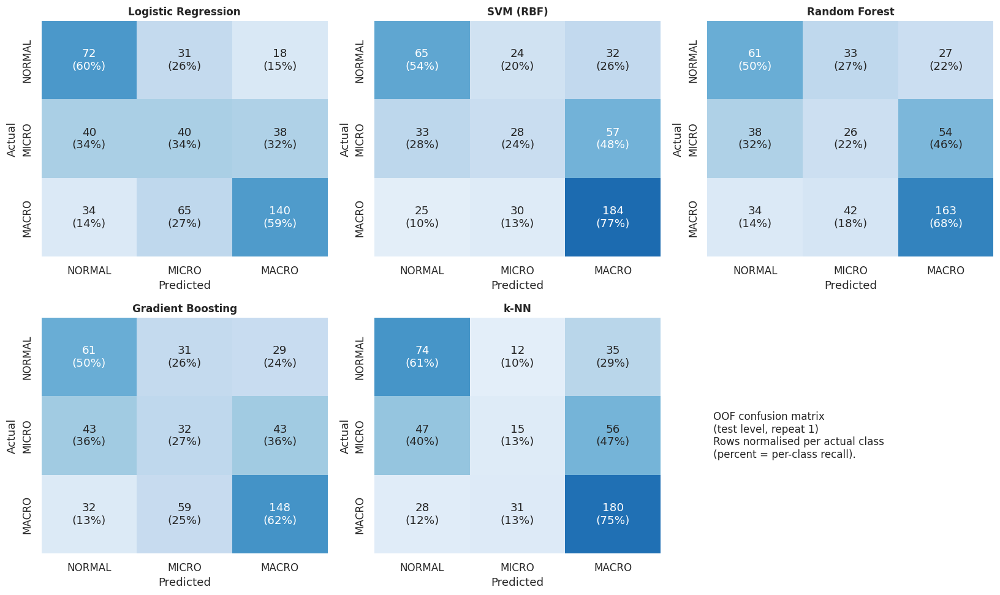

**Figure A9.** Out-of-fold confusion matrices of the five models (nested CV, repeat 1; test level). Each test is predicted once by a model that never saw its sample.

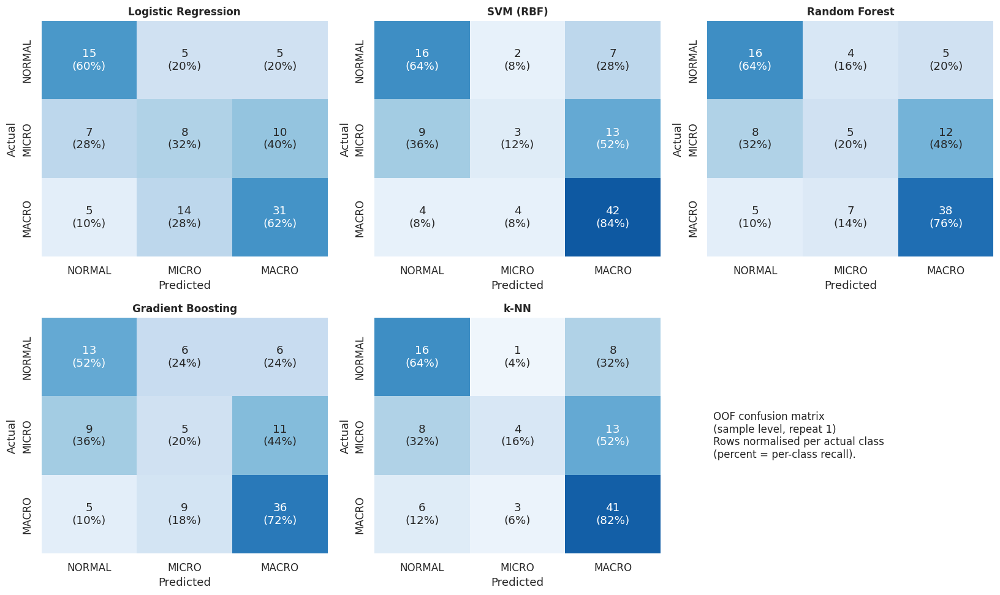

**Figure A10.** Out-of-fold confusion matrices at the sample level (repeat probabilities averaged; nested CV, repeat 1).

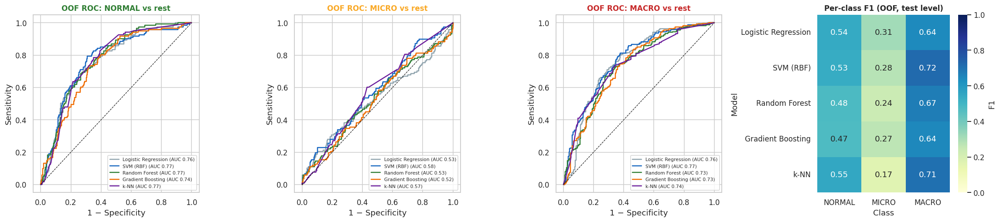

**Figure A11.** One-vs-rest ROC curves from nested-CV out-of-fold predictions (repeat 1, test level) for the five models, and per-class F1.

**Table A13.** Pooled out-of-fold precision, recall and F1 per class (nested CV repeat 1, test level).

**Table A14.** Pooled out-of-fold macro-F1 (nested CV repeat 1) with 95% cluster-bootstrap confidence intervals (1000 resamples of samples) — the uncertainty due to the small number of samples.

,Macro-F1 test level (OOF repeat 1),95% CI test level,Macro-F1 sample level,95% CI sample level,MICRO recall (test level),95% CI MICRO recall
Model,,,,,,
Logistic Regression,0.499,0.421 – 0.572,0.510,0.413 – 0.608,0.339,0.198 – 0.477
SVM (RBF),0.511,0.435 – 0.576,0.506,0.410 – 0.600,0.237,0.135 – 0.340
Random Forest,0.464,0.398 – 0.529,0.520,0.423 – 0.616,0.220,0.120 – 0.323
Gradient Boosting,0.462,0.404 – 0.518,0.474,0.380 – 0.572,0.271,0.173 – 0.368
k-NN,0.475,0.407 – 0.540,0.519,0.414 – 0.623,0.127,0.054 – 0.202


In [29]:
# ---------- 12.3 Out-of-fold predictions, confusion matrices, ROC and bootstrap CI ----------
def oof_of(nres, model, rep):
    P = np.zeros((len(y_all), 3)); seen = np.zeros(len(y_all), int)
    for r in nres:
        if r['model'] == model and r['rep'] == rep:
            P[r['tei']] = r['proba']; seen[r['tei']] += 1
    assert (seen == 1).all(), 'every test must be predicted exactly once per repeat'
    return P

OOF = {m_: oof_of(NRES, m_, 0) for m_ in MODEL_NAMES}                       # repeat 1: used for all figures below
OOF2 = {m_: oof_of(NRES, m_, 1) for m_ in MODEL_NAMES} if CFG['OUTER_REPEATS'] > 1 else None

def plot_cms(cm_func, title, name, caption, names=None):
    names = names or MODEL_NAMES
    fig, axs = plt.subplots(2, 3, figsize=(15, 9)); axs = axs.ravel()
    for i, n in enumerate(names):
        cmx = cm_func(n)
        pct = cmx / cmx.sum(1, keepdims=True).clip(min=1) * 100
        lab_ = np.array([[f'{cmx[a, b]}\n({pct[a, b]:.0f}%)' for b in range(3)] for a in range(3)])
        sns.heatmap(pct, annot=lab_, fmt='', cmap='Blues', vmin=0, vmax=100, cbar=False, ax=axs[i], xticklabels=CLASSES, yticklabels=CLASSES)
        axs[i].set_title(n); axs[i].set_xlabel('Predicted'); axs[i].set_ylabel('Actual')
    axs[5].axis('off'); axs[5].text(0.02, 0.5, title + '\nRows normalised per actual class\n(percent = per-class recall).', fontsize=11, va='center')
    fig.tight_layout(); save_fig(fig, name, caption)

plot_cms(lambda n: confusion_matrix(y_all, OOF[n].argmax(1), labels=[0, 1, 2]), 'OOF confusion matrix\n(test level, repeat 1)', 'cm_nested_test_level',
         'Out-of-fold confusion matrices of the five models (nested CV, repeat 1; test level). Each test is predicted once by a model that never saw its sample.')
def _cm_sample(n):
    ys_, ps_, _ = to_sample_level(g_all, y_all, OOF[n]); return confusion_matrix(ys_, ps_.argmax(1), labels=[0, 1, 2])
plot_cms(_cm_sample, 'OOF confusion matrix\n(sample level, repeat 1)', 'cm_nested_sample_level',
         'Out-of-fold confusion matrices at the sample level (repeat probabilities averaged; nested CV, repeat 1).')

fig, axs = plt.subplots(1, 4, figsize=(21, 4.8)); yb = label_binarize(y_all, classes=[0, 1, 2])
for ci_, c in enumerate(CLASSES):
    for n in MODEL_NAMES:
        fpr, tpr, _ = roc_curve(yb[:, ci_], OOF[n][:, ci_])
        axs[ci_].plot(fpr, tpr, lw=1.6, color=mcol[n], label=f'{n} (AUC {auc(fpr, tpr):.2f})')
    axs[ci_].plot([0, 1], [0, 1], 'k--', lw=.8); axs[ci_].set_title(f'OOF ROC: {c} vs rest', color=COLORS[c])
    axs[ci_].set_xlabel('1 − Specificity'); axs[ci_].set_ylabel('Sensitivity'); axs[ci_].legend(fontsize=7, loc='lower right')
pc = pd.DataFrame({n: f1_score(y_all, OOF[n].argmax(1), average=None, labels=[0, 1, 2], zero_division=0) for n in MODEL_NAMES}, index=CLASSES).T
sns.heatmap(pc, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axs[3], cbar_kws={'label': 'F1'}); axs[3].set_title('Per-class F1 (OOF, test level)')
axs[3].set_xlabel('Class'); axs[3].set_ylabel('Model')
fig.tight_layout()
save_fig(fig, 'roc_nested', 'One-vs-rest ROC curves from nested-CV out-of-fold predictions (repeat 1, test level) for the five models, and per-class F1.')

rep_rows = []
for n in MODEL_NAMES:
    r_ = classification_report(y_all, OOF[n].argmax(1), labels=[0, 1, 2], target_names=CLASSES, output_dict=True, zero_division=0)
    for c in CLASSES:
        rep_rows.append({'Model': n, 'Class': c, 'Precision': r_[c]['precision'], 'Recall': r_[c]['recall'], 'F1': r_[c]['f1-score'], 'Support (tests)': int(r_[c]['support'])})
save_table(pd.DataFrame(rep_rows).round(3), 'per_class_metrics', 'Pooled out-of-fold precision, recall and F1 per class (nested CV repeat 1, test level).', index=False, show=False)
put('nested.per_class_oof_repeat1', pd.DataFrame(rep_rows).round(4).to_dict(orient='records'))

# ---- cluster bootstrap over samples (resample samples, not rows) ----
rng = np.random.default_rng(SEED)
uniq = np.unique(g_all); idx_by = {s: np.where(g_all == s)[0] for s in uniq}
SAMPLE_P = {n: to_sample_level(g_all, y_all, OOF[n]) for n in MODEL_NAMES}
pos_by = {s: i for i, s in enumerate(SAMPLE_P[MODEL_NAMES[0]][2])}
B = CFG['BOOT_N']
boot = {n: {'test': [], 'sample': [], 'bacc': [], 'micro_recall': []} for n in MODEL_NAMES}
for _ in range(B):
    ss = rng.choice(uniq, size=len(uniq), replace=True)
    ii = np.concatenate([idx_by[s] for s in ss]); jj = np.array([pos_by[s] for s in ss])
    for n in MODEL_NAMES:
        yp = OOF[n][ii].argmax(1)
        boot[n]['test'].append(f1_score(y_all[ii], yp, average='macro', zero_division=0))
        boot[n]['bacc'].append(balanced_accuracy_score(y_all[ii], yp))
        boot[n]['micro_recall'].append(recall_per_class(y_all[ii], yp)[1])
        ys_, ps_, _ = SAMPLE_P[n]; boot[n]['sample'].append(f1_score(ys_[jj], ps_[jj].argmax(1), average='macro', zero_division=0))
ci_rows = []
for n in MODEL_NAMES:
    ys_, ps_, _ = SAMPLE_P[n]
    ci_rows.append({'Model': n, 'Macro-F1 test level (OOF repeat 1)': f1_score(y_all, OOF[n].argmax(1), average='macro'),
                    '95% CI test level': f'{np.percentile(boot[n]["test"], 2.5):.3f} – {np.percentile(boot[n]["test"], 97.5):.3f}',
                    'Macro-F1 sample level': f1_score(ys_, ps_.argmax(1), average='macro'),
                    '95% CI sample level': f'{np.percentile(boot[n]["sample"], 2.5):.3f} – {np.percentile(boot[n]["sample"], 97.5):.3f}',
                    'MICRO recall (test level)': recall_per_class(y_all, OOF[n].argmax(1))[1],
                    '95% CI MICRO recall': f'{np.percentile(boot[n]["micro_recall"], 2.5):.3f} – {np.percentile(boot[n]["micro_recall"], 97.5):.3f}'})
ci_tab = pd.DataFrame(ci_rows).set_index('Model')
save_table(ci_tab.round(3), 'oof_bootstrap_ci', f'Pooled out-of-fold macro-F1 (nested CV repeat 1) with 95% cluster-bootstrap confidence intervals ({B} resamples of samples) — the uncertainty due to the small number of samples.')
put('nested.bootstrap_ci_oof_repeat1', {n: dict(f1_test=ci_tab.loc[n, 'Macro-F1 test level (OOF repeat 1)'], ci_test=ci_tab.loc[n, '95% CI test level'], f1_sample=ci_tab.loc[n, 'Macro-F1 sample level'],
                                                  ci_sample=ci_tab.loc[n, '95% CI sample level'], micro_recall=ci_tab.loc[n, 'MICRO recall (test level)'], ci_micro=ci_tab.loc[n, '95% CI MICRO recall']) for n in MODEL_NAMES})
if OOF2 is not None:
    put('nested.pooled_oof_f1_test_level_by_repeat', {n: [float(f1_score(y_all, OOF[n].argmax(1), average='macro')), float(f1_score(y_all, OOF2[n].argmax(1), average='macro'))] for n in MODEL_NAMES})

**Table A15.** Stability of the tuned configuration over the 10 outer folds (chosen k, most frequent hyperparameter set) and the optimism of the inner-CV score relative to the outer-fold score.

,Model,k chosen (count over folds),Most frequent hyperparameters,Share of folds with the most frequent set,Mean inner-CV macro-F1,Outer macro-F1 (mean),Optimism (inner − outer)
0,Logistic Regression,"5: 2, 10: 1, 20: 7","{""C"": 0.1}",8/10,0.508,0.495,0.013
1,SVM (RBF),"5: 1, 10: 5, 20: 4","{""C"": 1, ""gamma"": ""scale""}",4/10,0.513,0.510,0.004
2,Random Forest,"5: 3, 10: 1, 20: 6","{""max_depth"": 6, ""min_samples_leaf"": 1, ""n_est...",4/10,0.473,0.477,-0.004
3,Gradient Boosting,"5: 1, 10: 3, 20: 6","{""learning_rate"": 0.05, ""max_depth"": 2, ""max_i...",4/10,0.477,0.441,0.035
4,k-NN,"5: 2, 10: 2, 20: 6","{""n_neighbors"": 7, ""weights"": ""uniform""}",3/10,0.473,0.455,0.019


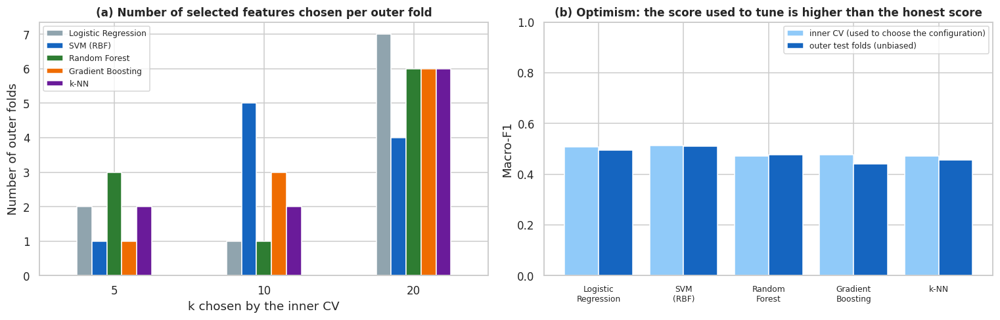

**Figure A12.** Tuning stability and optimism: (a) k chosen in each of the 10 outer folds per model; (b) mean inner-CV macro-F1 (used for tuning) versus the outer-fold macro-F1 (honest estimate).

Modal configuration of SVM (RBF): k = 10, hyperparameters = {'C': 1, 'gamma': 'scale'}


In [30]:
# ---------- 12.4 Stability of the tuned configurations ----------
tune_rows = []
for n in MODEL_NAMES:
    rr = [r for r in NRES if r['model'] == n]
    kc_ = pd.Series([r['best_k'] for r in rr]).value_counts().sort_index()
    pcount = pd.Series([json.dumps(r['params'], sort_keys=True, default=str) for r in rr]).value_counts()
    tune_rows.append({'Model': n, 'k chosen (count over folds)': ', '.join(f'{k}: {v}' for k, v in kc_.items()), 'Most frequent hyperparameters': pcount.index[0],
                      'Share of folds with the most frequent set': f'{pcount.iloc[0]}/{len(rr)}', 'Mean inner-CV macro-F1': np.mean([r['inner'] for r in rr]),
                      'Outer macro-F1 (mean)': f1_mean[n], 'Optimism (inner − outer)': np.mean([r['inner'] for r in rr]) - f1_mean[n]})
tune_tab = pd.DataFrame(tune_rows).round(3)
save_table(tune_tab, 'tuning_stability', 'Stability of the tuned configuration over the 10 outer folds (chosen k, most frequent hyperparameter set) and the optimism of the inner-CV score relative to the outer-fold score.', index=False)
put('nested.tuning', tune_tab.to_dict(orient='records'))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
kcount = pd.DataFrame({n: pd.Series([r['best_k'] for r in NRES if r['model'] == n]).value_counts() for n in MODEL_NAMES}).reindex(K_GRID).fillna(0).astype(int)
kcount.plot(kind='bar', ax=axs[0], color=[mcol[n] for n in MODEL_NAMES], rot=0); axs[0].set_xlabel('k chosen by the inner CV'); axs[0].set_ylabel('Number of outer folds'); axs[0].set_title('(a) Number of selected features chosen per outer fold'); axs[0].legend(fontsize=8)
opt = tune_tab.set_index('Model')
xx_ = np.arange(len(MODEL_NAMES))
axs[1].bar(xx_ - .2, opt['Mean inner-CV macro-F1'], .4, color='#90CAF9', label='inner CV (used to choose the configuration)')
axs[1].bar(xx_ + .2, opt['Outer macro-F1 (mean)'], .4, color='#1565C0', label='outer test folds (unbiased)')
axs[1].set_xticks(xx_); axs[1].set_xticklabels([n.replace(' ', '\n', 1) for n in MODEL_NAMES], fontsize=8); axs[1].set_ylabel('Macro-F1'); axs[1].set_ylim(0, 1); axs[1].legend(fontsize=8)
axs[1].set_title('(b) Optimism: the score used to tune is higher than the honest score')
fig.tight_layout()
save_fig(fig, 'tuning_stability', 'Tuning stability and optimism: (a) k chosen in each of the 10 outer folds per model; (b) mean inner-CV macro-F1 (used for tuning) versus the outer-fold macro-F1 (honest estimate).')

# modal configuration of the selected model (used for the permutation test and the analyses of Stage 14)
rr = [r for r in NRES if r['model'] == BEST_MODEL]
MODAL_K = int(pd.Series([r['best_k'] for r in rr]).value_counts().idxmax())
MODAL_PARAMS = json.loads(pd.Series([json.dumps(r['params'], sort_keys=True, default=str) for r in rr]).value_counts().index[0])
MODAL_PARAMS = {k: (None if v is None else v) for k, v in MODAL_PARAMS.items()}
print(f'Modal configuration of {BEST_MODEL}: k = {MODAL_K}, hyperparameters = {MODAL_PARAMS}')
put('nested.modal_configuration', dict(model=BEST_MODEL, k=MODAL_K, params=MODAL_PARAMS))

def modal_pipe(k=None):
    clf = get_models()[BEST_MODEL]
    clf.set_params(**MODAL_PARAMS)
    return make_pipe(clf, k=MODAL_K if k is None else k)

Loading cached result: /content/outputs/A_ML/cache/nested_seed_sensitivity_SVM_RBF__edb5e5389b.pkl


**Table A16.** Sensitivity of the nested-CV estimate of SVM (RBF) to the random division into folds: 5 additional 5-fold nested CVs with different split seeds, and the two repeats of the main run.

,Split seed,Mean outer-fold macro-F1,SD over folds,Pooled OOF macro-F1,MICRO recall (pooled OOF)
0,1042,0.471,0.065,0.474,0.161
1,1043,0.475,0.029,0.478,0.169
2,1044,0.504,0.095,0.510,0.203
3,1045,0.501,0.054,0.505,0.203
4,1046,0.506,0.106,0.519,0.186
5,"main run, repeat 1",0.498,0.100,0.511,0.237
6,"main run, repeat 2",0.521,0.089,0.535,0.254


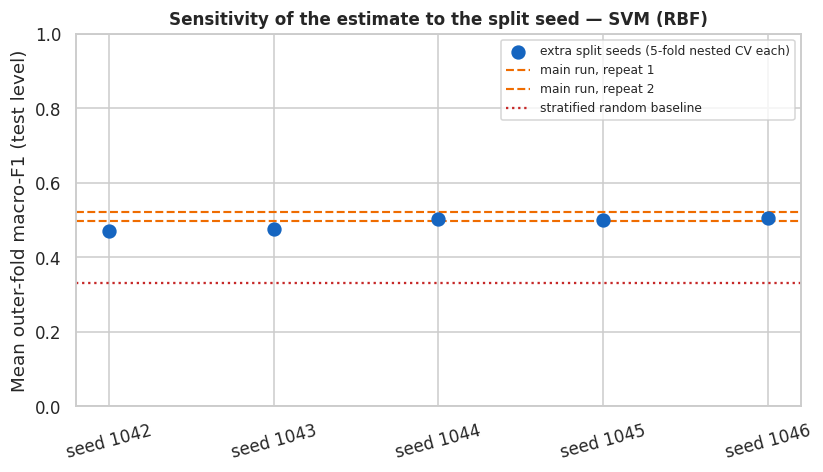

**Figure A13.** Sensitivity of the nested-CV macro-F1 of SVM (RBF) to the random division into folds. The spread across seeds is the part of the uncertainty that is due to the split alone.

Across 7 nested-CV runs: mean = 0.497, range = 0.471 – 0.521


In [31]:
# ---------- 12.5 Sensitivity to the split seed (selected model) ----------
SS_N = CFG['SEED_SENS_N']
ss_folds = []
for s_ in range(SS_N):
    for fold, (tri, tei) in enumerate(StratifiedGroupKFold(n_splits=CFG['OUTER_FOLDS'], shuffle=True, random_state=SEED + 1000 + s_).split(XM, y_all, g_all)):
        assert set(g_all[tri]).isdisjoint(set(g_all[tei]))
        ss_folds.append((100 + s_, fold, tri, tei))
safe_name = re.sub(r'[^A-Za-z0-9]+', '_', BEST_MODEL)
NRES_SS = run_nested(ss_folds, [BEST_MODEL], f'seed_sensitivity_{safe_name}')
ss_rows = []
for s_ in range(SS_N):
    rr_ = [r for r in NRES_SS if r['rep'] == 100 + s_]
    fv = [f1_score(y_all[r['tei']], r['proba'].argmax(1), average='macro') for r in rr_]
    P_ = np.zeros((len(y_all), 3))
    for r in rr_: P_[r['tei']] = r['proba']
    ss_rows.append({'Split seed': SEED + 1000 + s_, 'Mean outer-fold macro-F1': np.mean(fv), 'SD over folds': np.std(fv, ddof=1), 'Pooled OOF macro-F1': f1_score(y_all, P_.argmax(1), average='macro'),
                    'MICRO recall (pooled OOF)': recall_per_class(y_all, P_.argmax(1))[1]})
ss_tab = pd.DataFrame(ss_rows)
main_reps = [TF[(TF.Model == BEST_MODEL) & (TF.rep == r_)]['F1 (macro)'].mean() for r_ in range(CFG['OUTER_REPEATS'])]
for r_, v_ in enumerate(main_reps):
    ss_tab.loc[len(ss_tab)] = {'Split seed': f'main run, repeat {r_ + 1}', 'Mean outer-fold macro-F1': v_, 'SD over folds': TF[(TF.Model == BEST_MODEL) & (TF.rep == r_)]['F1 (macro)'].std(),
                               'Pooled OOF macro-F1': f1_score(y_all, OOF[BEST_MODEL].argmax(1), average='macro') if r_ == 0 else (f1_score(y_all, OOF2[BEST_MODEL].argmax(1), average='macro') if OOF2 else np.nan),
                               'MICRO recall (pooled OOF)': recall_per_class(y_all, (OOF[BEST_MODEL] if r_ == 0 else OOF2[BEST_MODEL]).argmax(1))[1] if (r_ == 0 or OOF2) else np.nan}
save_table(ss_tab.round(3), 'seed_sensitivity', f'Sensitivity of the nested-CV estimate of {BEST_MODEL} to the random division into folds: {SS_N} additional 5-fold nested CVs with different split seeds, and the two repeats of the main run.', index=False)
ss_vals = ss_tab['Mean outer-fold macro-F1'].astype(float).values
put('nested.seed_sensitivity', dict(model=BEST_MODEL, n_extra_seeds=SS_N, values_extra=ss_tab['Mean outer-fold macro-F1'].iloc[:SS_N].round(4).tolist(),
                                    mean_all=float(ss_vals.mean()), sd_all=float(ss_vals.std(ddof=1)) if len(ss_vals) > 1 else None, min_all=float(ss_vals.min()), max_all=float(ss_vals.max()),
                                    micro_recall_extra=ss_tab['MICRO recall (pooled OOF)'].iloc[:SS_N].round(4).tolist()))
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.scatter(range(SS_N), ss_tab['Mean outer-fold macro-F1'].iloc[:SS_N], s=70, c='#1565C0', label='extra split seeds (5-fold nested CV each)', zorder=3)
for r_, v_ in enumerate(main_reps): ax.axhline(v_, c='#EF6C00', ls='--', lw=1.4, label='main run, repeat %d' % (r_ + 1))
ax.axhline(f1_mean[BASE_NAMES[1]], c='#C62828', ls=':', label='stratified random baseline')
ax.set_xticks(range(SS_N)); ax.set_xticklabels([f'seed {SEED + 1000 + s_}' for s_ in range(SS_N)], rotation=15); ax.set_ylabel('Mean outer-fold macro-F1 (test level)'); ax.set_ylim(0, 1); ax.legend(fontsize=8)
ax.set_title(f'Sensitivity of the estimate to the split seed — {BEST_MODEL}')
save_fig(fig, 'seed_sensitivity', f'Sensitivity of the nested-CV macro-F1 of {BEST_MODEL} to the random division into folds. The spread across seeds is the part of the uncertainty that is due to the split alone.')
print(f'Across {len(ss_vals)} nested-CV runs: mean = {ss_vals.mean():.3f}, range = {ss_vals.min():.3f} – {ss_vals.max():.3f}')

Label permutations:   0%|          | 0/100 [00:00<?, ?it/s]

Real CV macro-F1 = 0.524 | null: mean = 0.306, 95th percentile = 0.379, max = 0.388 | permutation p = 0.0099 (44 s)


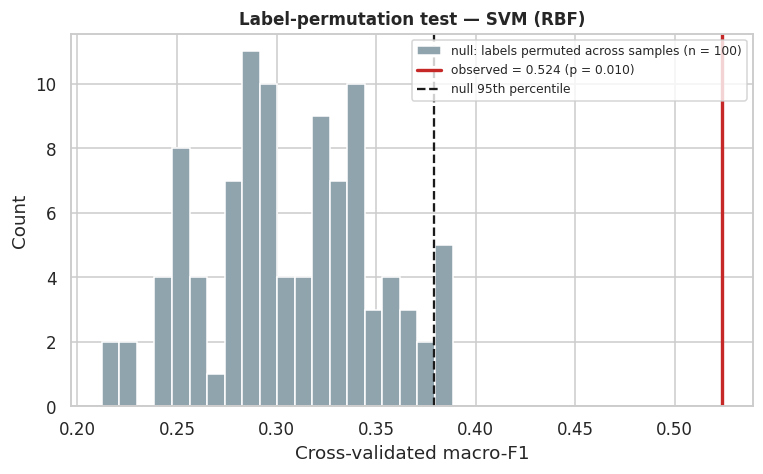

**Figure A14.** Label-permutation test for SVM (RBF) (modal configuration): distribution of cross-validated macro-F1 when class labels are shuffled across samples, and the observed value.

In [32]:
# ---------- 12.6 Label-permutation test (selected model, modal configuration) ----------
# Question: could a macro-F1 like the one observed arise from a pipeline with the same configuration if the labels carried no information?
# Procedure: permute the class labels across SAMPLES (all repeats of a sample keep the same label), re-run the sample-grouped CV, repeat PERM_N times.
PERM_SEEDS = [SEED, SEED + 1, SEED + 2]
y_by_sample = pd.Series(y_all).groupby(g_all).first()
def cv_score_labels(y_vec, seed):
    scs = []
    for tri, tei in StratifiedGroupKFold(n_splits=CFG['CURVE_FOLDS'], shuffle=True, random_state=seed).split(XM, y_vec, g_all):
        p_ = modal_pipe(); p_.fit(XM[tri], y_vec[tri])
        scs.append(f1_score(y_vec[tei], p_.predict(XM[tei]), average='macro'))
    return float(np.mean(scs))
real_score = float(np.mean([cv_score_labels(y_all, s_) for s_ in PERM_SEEDS]))
def _perm_job(i):
    rng_p = np.random.default_rng(SEED + 5000 + i)
    shuffled = pd.Series(rng_p.permutation(y_by_sample.values), index=y_by_sample.index)
    yp_ = shuffled.loc[g_all].values
    return cv_score_labels(yp_, PERM_SEEDS[i % 3])
t0 = time.time()
null_scores = np.array(Parallel(n_jobs=-1)(delayed(_perm_job)(i) for i in tqdm(range(CFG['PERM_N']), desc='Label permutations')))
p_perm = (1 + int((null_scores >= real_score).sum())) / (1 + len(null_scores))
print(f'Real CV macro-F1 = {real_score:.3f} | null: mean = {null_scores.mean():.3f}, 95th percentile = {np.percentile(null_scores, 95):.3f}, max = {null_scores.max():.3f} | permutation p = {p_perm:.4f} ({time.time() - t0:.0f} s)')
put('permutation_test', dict(model=BEST_MODEL, n_permutations=len(null_scores), real_macro_f1=real_score, null_mean=null_scores.mean(), null_sd=null_scores.std(ddof=1),
                             null_p95=float(np.percentile(null_scores, 95)), null_max=float(null_scores.max()), p_value=p_perm,
                             note='sample-level label permutation, fixed modal configuration, 5-fold grouped CV, real score = mean of 3 split seeds'))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.hist(null_scores, bins=20, color='#90A4AE', edgecolor='white', label=f'null: labels permuted across samples (n = {len(null_scores)})')
ax.axvline(real_score, c='#C62828', lw=2.2, label=f'observed = {real_score:.3f} (p = {p_perm:.3f})')
ax.axvline(np.percentile(null_scores, 95), c='k', ls='--', label='null 95th percentile')
ax.set_xlabel('Cross-validated macro-F1'); ax.set_ylabel('Count'); ax.legend(fontsize=8); ax.set_title(f'Label-permutation test — {BEST_MODEL}')
save_fig(fig, 'permutation_test', f'Label-permutation test for {BEST_MODEL} (modal configuration): distribution of cross-validated macro-F1 when class labels are shuffled across samples, and the observed value.')
sync_to_drive(verbose=False)
stage_done('12 nested CV')

# Stage 15 · Analysis of the Selected Model

This part answers the scientific questions that arise once the selected model is known. The model is the one chosen by the pre-specified rule in Stage 13 (`BEST_MODEL`), with its **modal configuration** (the most frequent *k* and hyperparameters over the 10 outer folds). All analyses are cross-validated with sample-grouped folds; none of them touches the numbers of Stage 13, and none feeds back into the model.

| Sub-stage | Question |
|---|---|
| 13.1 Ablation | Is the albumin image alone sufficient? How much do the creatinine image and the cross-image ratio features add? Which method group matters? |
| 13.2 Selection stability | Are the same features chosen in different folds (is the feature list trustworthy)? |
| 13.3 Permutation importance | Which selected features does the model really use? |
| 13.4 Learning curve | Would more samples help (is the sample size the limit)? |
| 13.5 Error analysis | Are errors concentrated near the 30 and 300 mg/g thresholds? How many are two-level errors? |
| 13.6 Calibration and the uncertain (“UNCERTAIN”) zone | Are the probabilities trustworthy? Can the device abstain on doubtful results and thereby become more accurate on the rest, and at what cost in coverage? |

Ablation:   0%|          | 0/225 [00:00<?, ?it/s]

**Table A17.** Ablation with the configuration of SVM (RBF) (k = 10; sample-grouped 5-fold × 3 cross-validation, identical folds for all subsets). Not directly comparable with the nested-CV estimate (different splits, no re-tuning); compare rows with each other.

,Subset,Features available,Macro-F1 (mean),SD,Difference to all features
0,All features,163,0.5147,0.0981,0.0000
1,Albumin only,90,0.4767,0.0822,-0.0380
2,Creatinine only,41,0.4129,0.0688,-0.1018
3,Cross-image only,32,0.4403,0.0939,-0.0744
4,Albumin + Creatinine,131,0.5169,0.0963,0.0022
5,Only: Colour-channel statistics,71,0.4829,0.0599,-0.0318
6,Without: Colour-channel statistics,92,0.5106,0.0837,-0.0041
7,Only: Hue,5,0.3908,0.0726,-0.1238
8,Without: Hue,158,0.5158,0.0992,0.0011
9,Only: Colour indices,26,0.5059,0.0744,-0.0087


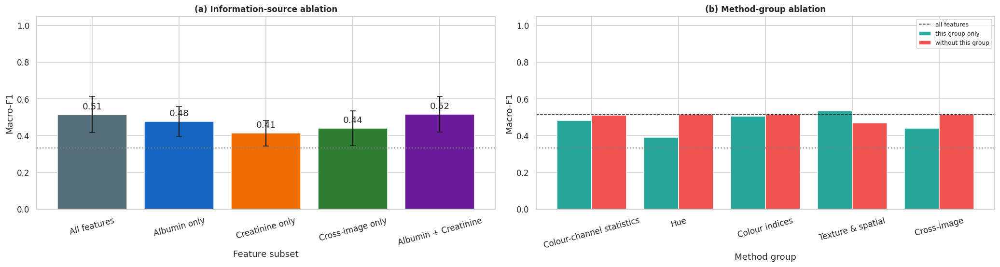

**Figure A15.** Ablation (SVM (RBF)): (a) contribution of the information sources (albumin, creatinine, cross-image) and (b) of the quantification-method groups, measured by cross-validated macro-F1 (dotted = chance).

**Table A18.** Feature-selection stability of SVM (RBF): proportion of the 10 outer folds in which the feature was selected (the k and the features are those of the tuned model of each fold).

,selection frequency,source,group
Feature,,,
alb__glcm_entropy,0.9,Albumin,Texture & spatial
alb__lbp_6,0.9,Albumin,Texture & spatial
alb__lbp_2,0.9,Albumin,Texture & spatial
alb__R_std,0.8,Albumin,Colour-channel statistics
cre__lbp_3,0.7,Creatinine,Texture & spatial
alb__glcm_homogeneity,0.6,Albumin,Texture & spatial
alb__gray_entropy,0.6,Albumin,Texture & spatial
alb__V_p10,0.6,Albumin,Colour-channel statistics
alb__grad_std,0.5,Albumin,Texture & spatial


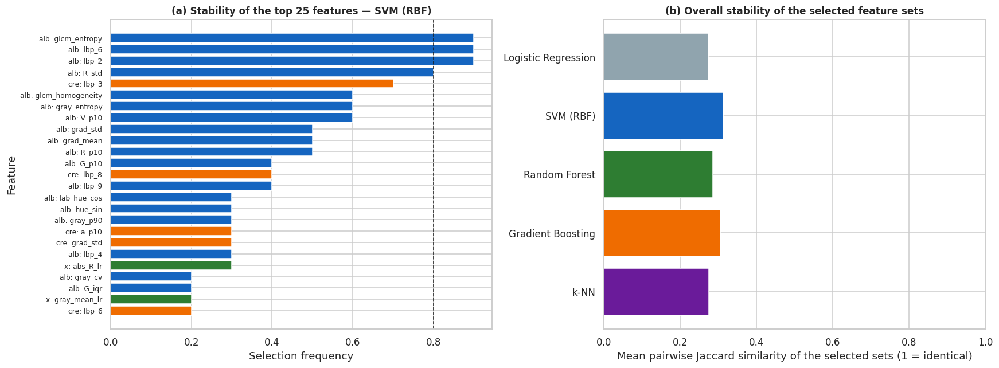

**Figure A16.** Feature-selection stability across the 10 outer folds: (a) frequency of the 25 most selected features for SVM (RBF) (dashed = 80 %); (b) mean pairwise Jaccard similarity of the selected sets for each model.

**Table A19.** Stability of the selected feature sets for the five models (over the 10 outer folds).

,Mean pairwise Jaccard of selected sets,Features selected in ≥ 80% of folds,Features selected in ≥ 50% of folds,Mean number selected
Model,,,,
Logistic Regression,0.273,3,12,16.0
SVM (RBF),0.312,4,11,13.5
Random Forest,0.287,2,14,14.5
Gradient Boosting,0.305,4,14,15.5
k-NN,0.276,4,11,15.0


In [33]:
# ---------- 13.1 Ablation (paired: same folds for every subset) ----------
ABL_SPLITS = [list(StratifiedGroupKFold(n_splits=CFG['CURVE_FOLDS'], shuffle=True, random_state=SEED + 200 + r).split(XM, y_all, g_all)) for r in range(CFG['ABL_REPEATS'])]
def _abl_job(cols, rep, fold):
    tri, tei = ABL_SPLITS[rep][fold]
    kk = max(1, min(MODAL_K, len(cols)))
    p_ = modal_pipe(k=kk); p_.fit(X_all.iloc[tri][cols].values, y_all[tri])
    return f1_score(y_all[tei], p_.predict(X_all.iloc[tei][cols].values), average='macro')

SUBSETS = {'All features': list(FEATS),
           'Albumin only': [c for c in FEATS if c.startswith('alb__')], 'Creatinine only': [c for c in FEATS if c.startswith('cre__')],
           'Cross-image only': [c for c in FEATS if c.startswith('x__')], 'Albumin + Creatinine': [c for c in FEATS if c.startswith(('alb__', 'cre__'))]}
for g_ in GROUPS:
    SUBSETS[f'Only: {g_}'] = [c for c in FEATS if family_of(c) == g_]
    SUBSETS[f'Without: {g_}'] = [c for c in FEATS if family_of(c) != g_]
SUBSETS = {k: v for k, v in SUBSETS.items() if len(v) >= 2}
jobs = [(nm, rep, fold) for nm in SUBSETS for rep in range(CFG['ABL_REPEATS']) for fold in range(CFG['CURVE_FOLDS'])]
outs = Parallel(n_jobs=-1)(delayed(_abl_job)(SUBSETS[nm], rep, fold) for (nm, rep, fold) in tqdm(jobs, desc='Ablation'))
ABL = {}
for (nm, rep, fold), v in zip(jobs, outs): ABL.setdefault(nm, {})[(rep, fold)] = v
ref = pd.Series(ABL['All features'])
abl_rows = []
for nm in SUBSETS:
    s_ = pd.Series(ABL[nm]); dlt = s_ - ref
    abl_rows.append({'Subset': nm, 'Features available': len(SUBSETS[nm]), 'Macro-F1 (mean)': s_.mean(), 'SD': s_.std(), 'Difference to all features': dlt.mean()})
abl_df = pd.DataFrame(abl_rows)
save_table(abl_df.round(4), 'ablation', f'Ablation with the configuration of {BEST_MODEL} (k = {MODAL_K}; sample-grouped {CFG["CURVE_FOLDS"]}-fold × {CFG["ABL_REPEATS"]} cross-validation, identical folds for all subsets). Not directly comparable with the nested-CV estimate (different splits, no re-tuning); compare rows with each other.', index=False)
put('ablation', abl_df.round(4).to_dict(orient='records'))

src_df = abl_df[abl_df.Subset.isin(['All features', 'Albumin only', 'Creatinine only', 'Cross-image only', 'Albumin + Creatinine'])]
fam_df = pd.DataFrame([{'Group': g_, 'Features': len(SUBSETS.get(f'Only: {g_}', [])),
                        'F1 this group only': abl_df.set_index('Subset')['Macro-F1 (mean)'].get(f'Only: {g_}', np.nan),
                        'F1 without this group': abl_df.set_index('Subset')['Macro-F1 (mean)'].get(f'Without: {g_}', np.nan)} for g_ in GROUPS])
full_f1 = abl_df.set_index('Subset').loc['All features', 'Macro-F1 (mean)']
fig, ax = plt.subplots(1, 2, figsize=(19, 5.2))
ax[0].bar(src_df.Subset, src_df['Macro-F1 (mean)'], yerr=src_df.SD, capsize=4, color=['#546E7A', '#1565C0', '#EF6C00', '#2E7D32', '#6A1B9A'][:len(src_df)])
ax[0].axhline(1 / 3, c='gray', ls=':'); ax[0].set_xlabel('Feature subset'); ax[0].set_ylabel('Macro-F1'); ax[0].set_ylim(0, 1.05); ax[0].tick_params(axis='x', rotation=15); ax[0].set_title('(a) Information-source ablation')
for i, v in enumerate(src_df['Macro-F1 (mean)']): ax[0].text(i, v + .03, f'{v:.2f}', ha='center')
xx_ = np.arange(len(fam_df))
ax[1].bar(xx_ - .2, fam_df['F1 this group only'], .4, label='this group only', color='#26A69A')
ax[1].bar(xx_ + .2, fam_df['F1 without this group'], .4, label='without this group', color='#EF5350')
ax[1].axhline(full_f1, c='k', ls='--', lw=1, label='all features'); ax[1].axhline(1 / 3, c='gray', ls=':'); ax[1].set_xticks(xx_); ax[1].set_xticklabels(fam_df.Group, rotation=15)
ax[1].set_xlabel('Method group'); ax[1].set_ylim(0, 1.05); ax[1].set_ylabel('Macro-F1'); ax[1].legend(fontsize=8); ax[1].set_title('(b) Method-group ablation')
fig.tight_layout()
save_fig(fig, 'ablation', f'Ablation ({BEST_MODEL}): (a) contribution of the information sources (albumin, creatinine, cross-image) and (b) of the quantification-method groups, measured by cross-validated macro-F1 (dotted = chance).')

# ---------- 13.2 Selection stability across the outer folds (from the nested CV itself) ----------
rr = [r for r in NRES if r['model'] == BEST_MODEL]
cnt_sel = pd.Series(0, index=FEATS, dtype=float)
for r in rr:
    for i in r['selected']: cnt_sel.iloc[i] += 1
stab = (cnt_sel / len(rr)).sort_values(ascending=False)
stab_tab = pd.DataFrame({'selection frequency': stab.head(25), 'source': [source_of(c) for c in stab.head(25).index], 'group': [family_of(c) for c in stab.head(25).index]}); stab_tab.index.name = 'Feature'
save_table(stab_tab.round(3), 'feature_stability', f'Feature-selection stability of {BEST_MODEL}: proportion of the {len(rr)} outer folds in which the feature was selected (the k and the features are those of the tuned model of each fold).')
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
top = stab.head(25).iloc[::-1]
axs[0].barh(top.index.str.replace('__', ': '), top.values, color=[SRC_COL[source_of(c)] for c in top.index]); axs[0].axvline(0.8, c='k', ls='--', lw=1)
axs[0].set_xlabel('Selection frequency'); axs[0].set_ylabel('Feature'); axs[0].set_title(f'(a) Stability of the top 25 features — {BEST_MODEL}'); axs[0].tick_params(axis='y', labelsize=8)
def jaccard_mean(sets):
    v = [len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i + 1:] if len(a | b)]; return float(np.mean(v)) if v else np.nan
stab_rows = []
for n in MODEL_NAMES:
    sets = [set(r['selected']) for r in NRES if r['model'] == n]
    cn = pd.Series(0, index=range(len(FEATS)), dtype=float)
    for s_ in sets:
        for i in s_: cn.iloc[i] += 1
    stab_rows.append({'Model': n, 'Mean pairwise Jaccard of selected sets': jaccard_mean(sets), 'Features selected in ≥ 80% of folds': int((cn / len(sets) >= .8).sum()), 'Features selected in ≥ 50% of folds': int((cn / len(sets) >= .5).sum()),
                      'Mean number selected': float(np.mean([len(s_) for s_ in sets]))})
stab_m = pd.DataFrame(stab_rows).set_index('Model')
axs[1].barh(stab_m.index[::-1], stab_m['Mean pairwise Jaccard of selected sets'].values[::-1], color=[mcol[n] for n in MODEL_NAMES[::-1]])
axs[1].set_xlim(0, 1); axs[1].set_xlabel('Mean pairwise Jaccard similarity of the selected sets (1 = identical)'); axs[1].set_title('(b) Overall stability of the selected feature sets')
fig.tight_layout()
save_fig(fig, 'feature_stability', f'Feature-selection stability across the {len(rr)} outer folds: (a) frequency of the 25 most selected features for {BEST_MODEL} (dashed = 80 %); (b) mean pairwise Jaccard similarity of the selected sets for each model.')
save_table(stab_m.round(3), 'feature_stability_by_model', 'Stability of the selected feature sets for the five models (over the 10 outer folds).')
put('stability', dict(model=BEST_MODEL, n_ge_80=int((stab >= .8).sum()), n_ge_50=int((stab >= .5).sum()), top10=stab.head(10).round(3).to_dict(), by_model=stab_m.round(4).to_dict(orient='index'),
                      top25_source_share={s_: float(np.mean([source_of(c) == s_ for c in stab.head(25).index])) for s_ in SRC_COL}))

**Table A20.** Permutation importance of the selected features of SVM (RBF) on the test part of each of the 5 grouped folds (drop of macro-F1 when a feature is shuffled; 30 shuffles), averaged over the folds in which the feature was selected.

,mean macro-F1 drop,SD across folds,folds in which selected,source,group
feature,,,,,
cre__lbp_8,0.0629,0.0336,2,Creatinine,Texture & spatial
alb__lbp_6,0.0311,0.0532,5,Albumin,Texture & spatial
alb__lab_hue_cos,0.0257,NaN,1,Albumin,Colour indices
cre__lbp_3,0.0249,0.0444,3,Creatinine,Texture & spatial
cre__lbp_6,0.0240,NaN,1,Creatinine,Texture & spatial
alb__ring_out,0.0212,0.0235,2,Albumin,Texture & spatial
alb__gray_entropy,0.0193,0.0228,4,Albumin,Texture & spatial
alb__R_std,0.0181,0.0379,5,Albumin,Colour-channel statistics
alb__grad_mean,0.0167,0.0401,4,Albumin,Texture & spatial


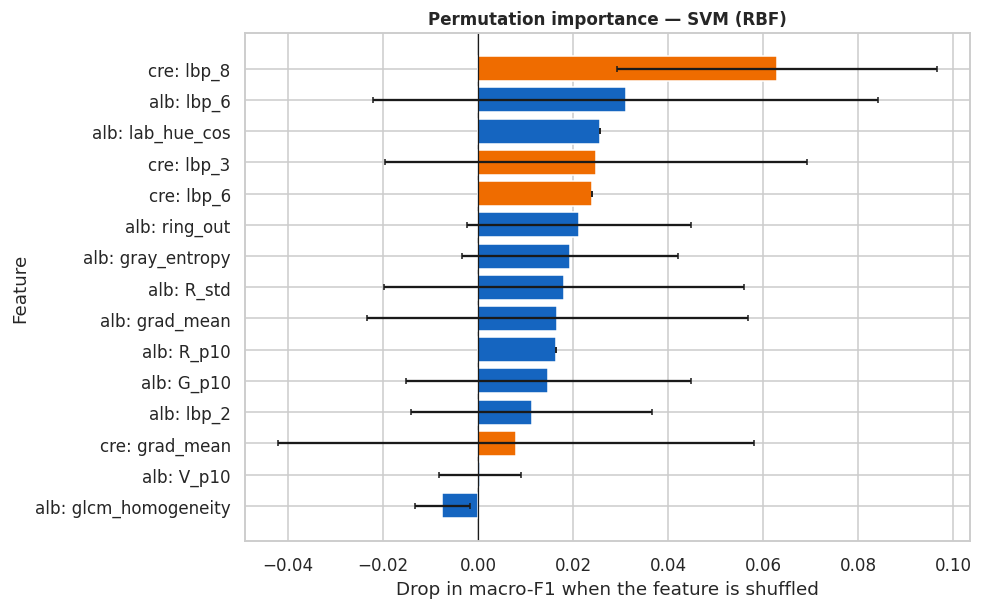

**Figure A17.** Permutation importance (mean ± SD over folds) of the 15 most important selected features of SVM (RBF); colour = image source (blue albumin, orange creatinine, green cross-image).

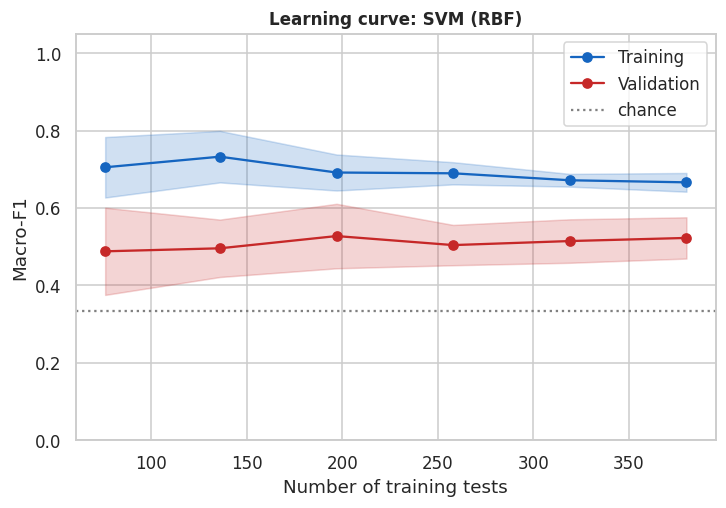

**Figure A18.** Learning curve of SVM (RBF) (sample-grouped cross-validation). A wide train–validation gap and a validation curve that is still rising indicate that additional data would help.

Train–validation gap at full size = 0.144; validation gain from 258 to 380 training tests = +0.018


In [34]:
# ---------- 13.3 Permutation importance (inside the outer-style folds) and 13.4 learning curve ----------
from sklearn.inspection import permutation_importance
R_PI = 5 if CFG['FAST_MODE'] else 30
pi_rows = []
for fi, (tri, tei) in enumerate(ABL_SPLITS[0]):
    p_ = modal_pipe(); p_.fit(XM[tri], y_all[tri])
    sel_names = [FEATS[i] for i in p_.named_steps['sel'].support_]
    Xs = p_[:-1].transform(XM[tei])
    pi = permutation_importance(p_[-1], Xs, y_all[tei], scoring='f1_macro', n_repeats=R_PI, random_state=SEED + fi)
    for n_, m_, s_ in zip(sel_names, pi.importances_mean, pi.importances_std): pi_rows.append({'fold': fi, 'feature': n_, 'drop': m_})
pi_all = pd.DataFrame(pi_rows)
pi_df = pi_all.groupby('feature').agg(**{'mean macro-F1 drop': ('drop', 'mean'), 'SD across folds': ('drop', 'std'), 'folds in which selected': ('fold', 'nunique')}).sort_values('mean macro-F1 drop', ascending=False)
pi_df['source'] = [source_of(c) for c in pi_df.index]; pi_df['group'] = [family_of(c) for c in pi_df.index]
save_table(pi_df.round(4).head(30), 'permutation_importance', f'Permutation importance of the selected features of {BEST_MODEL} on the test part of each of the {CFG["CURVE_FOLDS"]} grouped folds (drop of macro-F1 when a feature is shuffled; {R_PI} shuffles), averaged over the folds in which the feature was selected.')
put('importance', pi_df.head(15).round(4).reset_index().to_dict(orient='records'))
fig, ax = plt.subplots(figsize=(8.5, 6))
top = pi_df.head(15).iloc[::-1]
ax.barh(top.index.str.replace('__', ': '), top['mean macro-F1 drop'], xerr=top['SD across folds'].fillna(0), color=[SRC_COL[s_] for s_ in top.source], capsize=2)
ax.set_xlabel('Drop in macro-F1 when the feature is shuffled'); ax.set_ylabel('Feature'); ax.axvline(0, c='k', lw=.8); ax.set_title(f'Permutation importance — {BEST_MODEL}')
save_fig(fig, 'importance', f'Permutation importance (mean ± SD over folds) of the 15 most important selected features of {BEST_MODEL}; colour = image source (blue albumin, orange creatinine, green cross-image).')

# ---------- 13.4 Learning curve ----------
lc_splits = StratifiedGroupKFold(n_splits=CFG['CURVE_FOLDS'], shuffle=True, random_state=SEED)
sizes, trs, vas = learning_curve(modal_pipe(), X_all, y_all, groups=g_all, cv=lc_splits, scoring='f1_macro',
                                 train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1, shuffle=True, random_state=SEED)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(sizes, trs.mean(1), 'o-', c='#1565C0', label='Training'); ax.fill_between(sizes, trs.mean(1) - trs.std(1), trs.mean(1) + trs.std(1), alpha=.2, color='#1565C0')
ax.plot(sizes, vas.mean(1), 'o-', c='#C62828', label='Validation'); ax.fill_between(sizes, vas.mean(1) - vas.std(1), vas.mean(1) + vas.std(1), alpha=.2, color='#C62828')
ax.axhline(1 / 3, c='gray', ls=':', label='chance'); ax.set_xlabel('Number of training tests'); ax.set_ylabel('Macro-F1'); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title(f'Learning curve: {BEST_MODEL}')
save_fig(fig, 'learning_curve', f'Learning curve of {BEST_MODEL} (sample-grouped cross-validation). A wide train–validation gap and a validation curve that is still rising indicate that additional data would help.')
gap = trs.mean(1)[-1] - vas.mean(1)[-1]; gain = vas.mean(1)[-1] - vas.mean(1)[-3]
put('learning_curve', dict(sizes=sizes, train_mean=trs.mean(1), val_mean=vas.mean(1), val_sd=vas.std(1), gap_at_full=gap, val_gain_last_two_steps=gain))
print(f'Train–validation gap at full size = {gap:.3f}; validation gain from {sizes[-3]} to {sizes[-1]} training tests = {gain:+.3f}')

Sample level (nested-CV OOF repeat 1, SVM (RBF)): Accuracy = 0.610, Balanced Acc = 0.533, Precision (macro) = 0.521, Recall (macro) = 0.533, F1 (macro) = 0.506, F1 (weighted) = 0.567, MCC = 0.358, QWK = 0.518, AUC (macro OvR) = 0.741
Errors: 39 of 100 samples | one level: 28 | two levels (NORMAL↔MACRO): 11


**Table A21.** Samples misclassified by SVM (RBF) (nested-CV OOF repeat 1, sample level); sorted by how close the UACR is to the nearest threshold (30 or 300 mg/g).

,sample,uacr,actual,predicted,p_NORMAL,p_MICRO,p_MACRO,distance_to_threshold_log10
82,113,30.33,MICRO,NORMAL,0.378,0.275,0.347,0.005
62,63,260.00,MICRO,NORMAL,0.462,0.363,0.175,0.062
50,51,34.88,MICRO,MACRO,0.169,0.277,0.554,0.065
61,62,250.00,MICRO,NORMAL,0.443,0.182,0.376,0.079
98,129,36.32,MICRO,MACRO,0.314,0.322,0.365,0.083
6,7,239.83,MICRO,MACRO,0.118,0.361,0.521,0.097
10,11,378.18,MACRO,NORMAL,0.406,0.241,0.353,0.101
53,54,406.15,MACRO,MICRO,0.277,0.454,0.269,0.132
31,32,215.00,MICRO,MACRO,0.122,0.185,0.693,0.145
49,50,213.41,MICRO,NORMAL,0.467,0.398,0.135,0.148


**Table A22.** Error rate of SVM (RBF) (sample level, OOF repeat 1) by the distance of the laboratory UACR to the nearest class threshold; errors concentrated near thresholds indicate label ambiguity rather than model failure.

,Distance of lab UACR to nearest threshold,Samples,Errors,Error rate (%)
0,≤ 0.1 log10 from a threshold,9,6,66.7
1,0.1–0.3,27,14,51.9
2,0.3–0.6,33,12,36.4
3,> 0.6,31,7,22.6


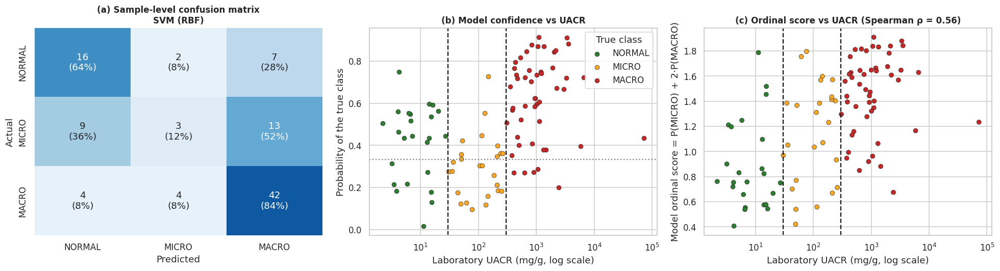

**Figure A19.** Error analysis of SVM (RBF) (nested-CV OOF predictions, repeat 1): (a) sample-level confusion matrix, (b) probability of the true class versus UACR, (c) model ordinal score versus laboratory UACR (dashed lines = 30 and 300 mg/g thresholds).

Median log10 distance to the nearest threshold — misclassified: 0.291 vs correct: 0.505 (smaller for errors = errors concentrated near the thresholds)


In [35]:
# ---------- 13.5 Error analysis (nested-CV OOF predictions, sample level, repeat 1) ----------
oof_b = OOF[BEST_MODEL]
ys_s, ps_s, gs_ids = to_sample_level(g_all, y_all, oof_b)
pred_s = ps_s.argmax(1)
err = pd.DataFrame({'sample': gs_ids, 'actual': [CLASSES[i] for i in ys_s], 'predicted': [CLASSES[i] for i in pred_s],
                    'p_NORMAL': ps_s[:, 0], 'p_MICRO': ps_s[:, 1], 'p_MACRO': ps_s[:, 2]}).merge(labels[['sample', 'uacr']], on='sample', how='left')
err['correct'] = err.actual == err.predicted
err['error_steps'] = np.abs(ys_s - pred_s)
err['distance_to_threshold_log10'] = [min(abs(np.log10(max(u, .1) / 30)), abs(np.log10(max(u, .1) / 300))) if pd.notna(u) else np.nan for u in err.uacr]

sm_metrics = metric_dict(ys_s, pred_s, ps_s)
n_err = int((~err.correct).sum())
print(f'Sample level (nested-CV OOF repeat 1, {BEST_MODEL}): ' + ', '.join(f'{k} = {v:.3f}' for k, v in sm_metrics.items()))
print(f'Errors: {n_err} of {len(err)} samples | one level: {(err.error_steps == 1).sum()} | two levels (NORMAL↔MACRO): {(err.error_steps == 2).sum()}')

err_tab = err[~err.correct].sort_values('distance_to_threshold_log10')[['sample', 'uacr', 'actual', 'predicted', 'p_NORMAL', 'p_MICRO', 'p_MACRO', 'distance_to_threshold_log10']].round(3)
save_table(err_tab, 'misclassified_samples', f'Samples misclassified by {BEST_MODEL} (nested-CV OOF repeat 1, sample level); sorted by how close the UACR is to the nearest threshold (30 or 300 mg/g).', index=False, max_rows=40)

zone_rows = []
for lab_z, lo, hi in (('≤ 0.1 log10 from a threshold', 0, .1), ('0.1–0.3', .1, .3), ('0.3–0.6', .3, .6), ('> 0.6', .6, 99)):
    z = err[(err.distance_to_threshold_log10 > lo) & (err.distance_to_threshold_log10 <= hi)] if lo > 0 else err[err.distance_to_threshold_log10 <= hi]
    zone_rows.append({'Distance of lab UACR to nearest threshold': lab_z, 'Samples': len(z), 'Errors': int((~z.correct).sum()), 'Error rate (%)': round(float((~z.correct).mean() * 100), 1) if len(z) else np.nan})
zone_tab = pd.DataFrame(zone_rows)
save_table(zone_tab, 'error_by_threshold_distance', f'Error rate of {BEST_MODEL} (sample level, OOF repeat 1) by the distance of the laboratory UACR to the nearest class threshold; errors concentrated near thresholds indicate label ambiguity rather than model failure.', index=False)
put('errors', dict(model=BEST_MODEL, n_samples=len(err), n_errors=n_err, one_level=int((err.error_steps == 1).sum()), two_level=int((err.error_steps == 2).sum()),
                   sample_level_metrics_oof_repeat1=sm_metrics, median_dist_wrong=float(err[~err.correct].distance_to_threshold_log10.median()), median_dist_correct=float(err[err.correct].distance_to_threshold_log10.median()),
                   by_zone=zone_tab.to_dict(orient='records'), confusion_sample_level=confusion_matrix(ys_s, pred_s, labels=[0, 1, 2])))

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
cm_s = confusion_matrix(ys_s, pred_s, labels=[0, 1, 2]); pct = cm_s / cm_s.sum(1, keepdims=True).clip(min=1) * 100
sns.heatmap(pct, annot=np.array([[f'{cm_s[a, b]}\n({pct[a, b]:.0f}%)' for b in range(3)] for a in range(3)]), fmt='', cmap='Blues', vmin=0, vmax=100, cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axs[0]); axs[0].set_xlabel('Predicted'); axs[0].set_ylabel('Actual'); axs[0].set_title(f'(a) Sample-level confusion matrix\n{BEST_MODEL}')
d_ = err.dropna(subset=['uacr'])
for c in CLASSES:
    s_ = d_[d_.actual == c]
    axs[1].scatter(s_.uacr, s_[f'p_{c}'], c=COLORS[c], s=34, edgecolor='k', lw=.4, label=c)
axs[1].set_xscale('log'); axs[1].axvline(30, c='k', ls='--'); axs[1].axvline(300, c='k', ls='--'); axs[1].axhline(1 / 3, c='gray', ls=':')
axs[1].set_xlabel('Laboratory UACR (mg/g, log scale)'); axs[1].set_ylabel('Probability of the true class'); axs[1].legend(title='True class'); axs[1].set_title('(b) Model confidence vs UACR')
score_ord = ps_s[:, 1] + 2 * ps_s[:, 2]
mk = err.uacr.notna().values
axs[2].scatter(err.uacr[mk], score_ord[mk], c=[PALETTE[i] for i in ys_s[mk]], s=34, edgecolor='k', lw=.4)
axs[2].set_xscale('log'); axs[2].axvline(30, c='k', ls='--'); axs[2].axvline(300, c='k', ls='--')
rho_ord = sps.spearmanr(err.uacr[mk], score_ord[mk])[0]
axs[2].set_xlabel('Laboratory UACR (mg/g, log scale)'); axs[2].set_ylabel('Model ordinal score = P(MICRO) + 2·P(MACRO)'); axs[2].set_title(f'(c) Ordinal score vs UACR (Spearman ρ = {rho_ord:.2f})')
fig.tight_layout()
save_fig(fig, 'error_analysis', f'Error analysis of {BEST_MODEL} (nested-CV OOF predictions, repeat 1): (a) sample-level confusion matrix, (b) probability of the true class versus UACR, (c) model ordinal score versus laboratory UACR (dashed lines = 30 and 300 mg/g thresholds).')
put('errors.ordinal_score_spearman_vs_uacr', rho_ord)
near = err[~err.correct]['distance_to_threshold_log10'].median(); far = err[err.correct]['distance_to_threshold_log10'].median()
print(f'Median log10 distance to the nearest threshold — misclassified: {near:.3f} vs correct: {far:.3f} (smaller for errors = errors concentrated near the thresholds)')

test level (one measurement): threshold = 0.44 -> coverage 0.89, macro-F1 on accepted 0.530, accuracy 0.611, MICRO recall 0.21
sample level (repeats averaged): threshold = 0.53 -> coverage 0.60, macro-F1 on accepted 0.589, accuracy 0.733, MICRO recall 0.14


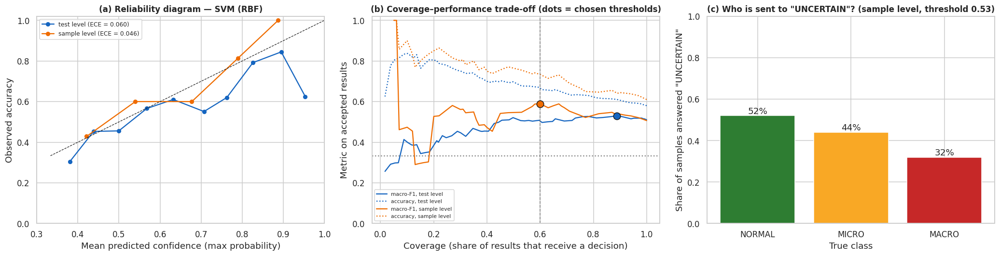

**Figure A20.** Calibration and the uncertain ("UNCERTAIN") zone for SVM (RBF) (nested-CV OOF repeat 1): (a) reliability diagram; (b) macro-F1 and accuracy on the accepted results versus coverage, thresholds chosen to maximise macro-F1 subject to coverage ≥ 60%; (c) share of samples of each true class that would be answered "UNCERTAIN". Exploratory: thresholds are tuned on the same out-of-fold predictions.

**Table A23.** The uncertain-result ("UNCERTAIN") thresholds stored in the deployment bundle and what they do to coverage and performance (SVM (RBF), OOF repeat 1). EXPLORATORY: confirm on independent data before use.

,Quantity,test level (single measurement),sample level (repeats averaged)
0,Level,test level (single measurement),sample level (repeats averaged)
1,Threshold on max probability,0.44,0.53
2,coverage,0.887,0.6
3,n_accepted,424.0,60.0
4,accuracy,0.611,0.733
5,macro_f1,0.53,0.589
6,balanced_acc,0.539,0.603
7,recall_MICRO,0.215,0.143
8,abstain_NORMAL,0.132,0.52
9,abstain_MICRO,0.093,0.44


In [36]:
# ---------- 13.6 Calibration and the uncertain ("UNCERTAIN") zone ----------
def ece_score(conf, correct, n_bins=10):
    edges = np.linspace(1 / 3, 1.0, n_bins + 1); e = 0.0; rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m_ = (conf > lo) & (conf <= hi) if lo > 1 / 3 else (conf >= lo) & (conf <= hi)
        if m_.sum(): e += m_.mean() * abs(correct[m_].mean() - conf[m_].mean()); rows.append((conf[m_].mean(), correct[m_].mean(), int(m_.sum())))
    return e, rows

def cov_curve(P, y, taus):
    conf = P.max(1); pred = P.argmax(1); rows = []
    for t in taus:
        acc = conf >= t
        if acc.sum() < 5: continue
        rec = recall_per_class(y[acc], pred[acc]); n_cls = np.bincount(y[acc], minlength=3)
        rows.append(dict(tau=t, coverage=acc.mean(), n_accepted=int(acc.sum()), accuracy=accuracy_score(y[acc], pred[acc]), macro_f1=f1_score(y[acc], pred[acc], average='macro', zero_division=0),
                         balanced_acc=balanced_accuracy_score(y[acc], pred[acc]), recall_MICRO=rec[1] if n_cls[1] else np.nan, abstain_NORMAL=1 - acc[y == 0].mean(), abstain_MICRO=1 - acc[y == 1].mean(), abstain_MACRO=1 - acc[y == 2].mean()))
    return pd.DataFrame(rows)

TAUS = np.round(np.arange(0.34, 0.951, 0.01), 2)
def choose_tau(cc):
    ok = cc[cc.coverage >= CFG['ABSTAIN_MIN_COVERAGE']]
    if not len(ok): return float(cc.tau.min())
    best = ok.macro_f1.max()
    return float(ok[ok.macro_f1 >= best - 1e-12].tau.min())      # ties -> lowest threshold (largest coverage)

P_test = OOF[BEST_MODEL]; y_test_lvl = y_all
P_samp, y_samp = ps_s, ys_s
cc_t, cc_s = cov_curve(P_test, y_test_lvl, TAUS), cov_curve(P_samp, y_samp, TAUS)
TAU_SINGLE, TAU_AVG = choose_tau(cc_t), choose_tau(cc_s)
for lvl, cc, tau in (('test level (one measurement)', cc_t, TAU_SINGLE), ('sample level (repeats averaged)', cc_s, TAU_AVG)):
    r0 = cc.iloc[(cc.tau - tau).abs().argmin()]
    print(f'{lvl}: threshold = {tau:.2f} -> coverage {r0.coverage:.2f}, macro-F1 on accepted {r0.macro_f1:.3f}, accuracy {r0.accuracy:.3f}, MICRO recall {r0.recall_MICRO:.2f}')

ece_t, rel_t = ece_score(P_test.max(1), (P_test.argmax(1) == y_test_lvl).astype(float)); ece_s, rel_s = ece_score(P_samp.max(1), (P_samp.argmax(1) == y_samp).astype(float), n_bins=5)
# uncertainty of the headline numbers at the chosen thresholds: cluster bootstrap over samples
rng = np.random.default_rng(SEED + 7)
def boot_abstain(tau_t, tau_s, B_=None):
    B_ = B_ or CFG['BOOT_N']; res = {'cov_t': [], 'f1_t': [], 'cov_s': [], 'f1_s': []}
    for _ in range(B_):
        ss = rng.choice(uniq, size=len(uniq), replace=True); ii = np.concatenate([idx_by[s] for s in ss]); jj = np.array([pos_by[s] for s in ss])
        a = P_test[ii].max(1) >= tau_t
        if a.sum() > 5: res['cov_t'].append(a.mean()); res['f1_t'].append(f1_score(y_all[ii][a], P_test[ii].argmax(1)[a], average='macro', zero_division=0))
        b = P_samp[jj].max(1) >= tau_s
        if b.sum() > 5: res['cov_s'].append(b.mean()); res['f1_s'].append(f1_score(y_samp[jj][b], P_samp[jj].argmax(1)[b], average='macro', zero_division=0))
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in res.items()}
bci = boot_abstain(TAU_SINGLE, TAU_AVG)

fig, axs = plt.subplots(1, 3, figsize=(19, 5))
for rows_, lab_, col_ in ((rel_t, 'test level', '#1565C0'), (rel_s, 'sample level', '#EF6C00')):
    arr = np.array(rows_); axs[0].plot(arr[:, 0], arr[:, 1], 'o-', c=col_, label=f'{lab_} (ECE = {ece_t if lab_ == "test level" else ece_s:.3f})', ms=5)
axs[0].plot([1 / 3, 1], [1 / 3, 1], 'k--', lw=.8); axs[0].set_xlabel('Mean predicted confidence (max probability)'); axs[0].set_ylabel('Observed accuracy'); axs[0].set_xlim(.3, 1); axs[0].set_ylim(0, 1.02)
axs[0].legend(fontsize=8); axs[0].set_title(f'(a) Reliability diagram — {BEST_MODEL}')
for cc, lab_, col_, tau in ((cc_t, 'test level', '#1565C0', TAU_SINGLE), (cc_s, 'sample level', '#EF6C00', TAU_AVG)):
    axs[1].plot(cc.coverage, cc.macro_f1, '-', c=col_, label=f'macro-F1, {lab_}'); axs[1].plot(cc.coverage, cc.accuracy, ':', c=col_, label=f'accuracy, {lab_}')
    r0 = cc.iloc[(cc.tau - tau).abs().argmin()]; axs[1].scatter([r0.coverage], [r0.macro_f1], s=90, c=col_, edgecolor='k', zorder=5)
axs[1].axvline(CFG['ABSTAIN_MIN_COVERAGE'], c='gray', ls='--', lw=1); axs[1].axhline(1 / 3, c='gray', ls=':'); axs[1].set_xlabel('Coverage (share of results that receive a decision)'); axs[1].set_ylabel('Metric on accepted results')
axs[1].set_ylim(0, 1.02); axs[1].legend(fontsize=7, loc='lower left'); axs[1].set_title('(b) Coverage–performance trade-off (dots = chosen thresholds)')
r0 = cc_s.iloc[(cc_s.tau - TAU_AVG).abs().argmin()]
axs[2].bar(CLASSES, [r0.abstain_NORMAL, r0.abstain_MICRO, r0.abstain_MACRO], color=PALETTE)
for i_, v_ in enumerate([r0.abstain_NORMAL, r0.abstain_MICRO, r0.abstain_MACRO]): axs[2].text(i_, v_ + .01, f'{v_ * 100:.0f}%', ha='center')
axs[2].set_ylim(0, 1); axs[2].set_ylabel('Share of samples answered "UNCERTAIN"'); axs[2].set_xlabel('True class'); axs[2].set_title(f'(c) Who is sent to "UNCERTAIN"? (sample level, threshold {TAU_AVG:.2f})')
fig.tight_layout()
save_fig(fig, 'calibration_abstain', f'Calibration and the uncertain ("UNCERTAIN") zone for {BEST_MODEL} (nested-CV OOF repeat 1): (a) reliability diagram; (b) macro-F1 and accuracy on the accepted results versus coverage, thresholds chosen to maximise macro-F1 subject to coverage ≥ {CFG["ABSTAIN_MIN_COVERAGE"]:.0%}; (c) share of samples of each true class that would be answered "UNCERTAIN". Exploratory: thresholds are tuned on the same out-of-fold predictions.')

tau_tab = pd.DataFrame([{'Level': 'test level (single measurement)', 'Threshold on max probability': TAU_SINGLE, **{k: v for k, v in cc_t.iloc[(cc_t.tau - TAU_SINGLE).abs().argmin()].items() if k != 'tau'}, 'ECE': ece_t,
                         'Coverage 95% CI': f'{bci["cov_t"][0]:.2f} – {bci["cov_t"][1]:.2f}', 'Macro-F1 (accepted) 95% CI': f'{bci["f1_t"][0]:.3f} – {bci["f1_t"][1]:.3f}', 'Macro-F1 without abstention': f1_score(y_test_lvl, P_test.argmax(1), average='macro')},
                        {'Level': 'sample level (repeats averaged)', 'Threshold on max probability': TAU_AVG, **{k: v for k, v in cc_s.iloc[(cc_s.tau - TAU_AVG).abs().argmin()].items() if k != 'tau'}, 'ECE': ece_s,
                         'Coverage 95% CI': f'{bci["cov_s"][0]:.2f} – {bci["cov_s"][1]:.2f}', 'Macro-F1 (accepted) 95% CI': f'{bci["f1_s"][0]:.3f} – {bci["f1_s"][1]:.3f}', 'Macro-F1 without abstention': f1_score(y_samp, P_samp.argmax(1), average='macro')}])
save_table(tau_tab.round(3).T.rename_axis('Quantity').reset_index().rename(columns={0: 'test level (single measurement)', 1: 'sample level (repeats averaged)'}), 'abstain_thresholds',
           f'The uncertain-result ("UNCERTAIN") thresholds stored in the deployment bundle and what they do to coverage and performance ({BEST_MODEL}, OOF repeat 1). EXPLORATORY: confirm on independent data before use.', index=False)
put('abstain', dict(model=BEST_MODEL, tau_single=TAU_SINGLE, tau_avg=TAU_AVG, min_coverage=CFG['ABSTAIN_MIN_COVERAGE'], ece_test_level=ece_t, ece_sample_level=ece_s, bootstrap_ci=bci,
                    test_level=tau_tab.iloc[0].to_dict(), sample_level=tau_tab.iloc[1].to_dict(),
                    curve_test_level=cc_t.round(4).to_dict(orient='list'), curve_sample_level=cc_s.round(4).to_dict(orient='list')))
# secondary check on the second repeat (different folds, same samples -> not independent evidence)
if OOF2 is not None:
    P2 = OOF2[BEST_MODEL]; a2 = P2.max(1) >= TAU_SINGLE
    put('abstain.check_repeat2_test_level', dict(coverage=float(a2.mean()), macro_f1_accepted=float(f1_score(y_all[a2], P2.argmax(1)[a2], average='macro', zero_division=0)), macro_f1_all=float(f1_score(y_all, P2.argmax(1), average='macro'))))
sync_to_drive(verbose=False)
stage_done('13 analysis of the selected model')

# Stage 16 · Final Training and the Deployment Bundle

**Purpose.** Produce the model that goes into the diagnosis device, by the **same procedure** that Stage 13 evaluated, and package it so that the device needs nothing from this notebook.

**Steps.**
1. **Train all five models on all samples** with the identical `GridSearchCV` (same grids, same 3 inner folds, macro-F1) — the “training of five models” of the project. The inner-CV scores in this table are used for tuning only; they are optimistic, and the honest performance of each model is the Stage 13 estimate.
2. **Apply the pre-specified rule:** the deployed model is `BEST_MODEL` from Stage 13.
3. **Selected features.** The features chosen by the final tuned model are listed with their significance, stability across folds and importance. They are exported together with the labels as the *selected-feature dataset*.
4. **Compact pipeline.** Imputation, `RobustScaler` and `StandardScaler` act on each feature independently, so a pipeline that receives **only the selected features** gives exactly the same predictions as the full pipeline. The compact pipeline is refitted and checked numerically against the full one. The device therefore needs only the selected features as model input.
5. **Bundle** (`outputs/A_ML/model/`): `uacr_model.joblib` (model + metadata + uncertain-zone thresholds), `uacr_features.py` (the image-analysis code of Stage 5), `uacr_inference.py` (image pair → class), `model_card.md`, `deployment_config.json`, `requirements.txt`, `selected_features.csv`.
6. **Self-test.** The bundle is copied to a clean folder and run in a separate Python process **without** this notebook's code or environment variables; its output must equal the notebook's predictions.

**What the device returns.** The most likely class, the three class probabilities, and — if the highest probability is below the threshold stored in the bundle — the decision **“UNCERTAIN”** (uncertain, repeat the measurement). One image pair gives a single-measurement result; several pairs of the same sample are averaged (the sample-level setting evaluated in Stage 13).

**What the device is not.** A research prototype. The honest performance is the nested-CV estimate of Stage 13; the model has not been validated on an independent cohort, other operators, other cameras or other reagent batches.

Logistic Regression    | best inner-CV macro-F1 = 0.5595 |   1.5 s | {'clf__C': 0.1, 'sel__k': 20}
SVM (RBF)              | best inner-CV macro-F1 = 0.5472 |   4.4 s | {'clf__C': 10, 'clf__gamma': 0.05, 'sel__k': 10}
Random Forest          | best inner-CV macro-F1 = 0.4973 |  20.9 s | {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 200, 'sel__k': 10}
Gradient Boosting      | best inner-CV macro-F1 = 0.5186 |   9.8 s | {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__max_iter': 150, 'sel__k': 20}
k-NN                   | best inner-CV macro-F1 = 0.4782 |   2.6 s | {'clf__n_neighbors': 7, 'clf__weights': 'distance', 'sel__k': 20}


**Table A24.** Final training of the five models on all samples (GridSearchCV, sample-grouped 3-fold, macro-F1). The inner-CV score is the tuning score and is optimistic; the honest estimate is the outer-fold macro-F1 of Stage 13 (last numeric column).

,Model,"Inner-CV macro-F1 (tuning score, optimistic)",SD,Training macro-F1,Train–validation gap,k selected,Combinations tested,Time (s),"Outer-fold macro-F1 (honest, Stage 13)",Best parameters
0,Logistic Regression,0.5595,0.0015,0.6296,0.0701,20,9,1.5248,0.4948,"{""C"": 0.1, ""sel__k"": 20}"
1,SVM (RBF),0.5472,0.0172,0.7284,0.1812,10,18,4.3917,0.5097,"{""C"": 10, ""gamma"": 0.05, ""sel__k"": 10}"
2,Random Forest,0.4973,0.0299,0.9478,0.4505,10,12,20.9185,0.4771,"{""max_depth"": null, ""min_samples_leaf"": 3, ""n_..."
3,Gradient Boosting,0.5186,0.0151,0.9312,0.4127,20,12,9.7919,0.4414,"{""learning_rate"": 0.05, ""max_depth"": 2, ""max_i..."
4,k-NN,0.4782,0.0242,1.0000,0.5218,20,18,2.6149,0.4547,"{""n_neighbors"": 7, ""weights"": ""distance"", ""sel..."


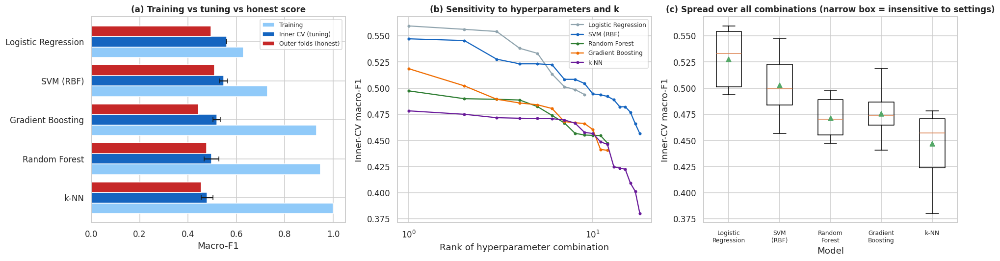

**Figure A21.** Final training on all samples: (a) training, tuning (inner CV) and honest (outer folds) macro-F1 of the five models; (b) ranked performance over all hyperparameter/k combinations; (c) spread per model.

DEPLOYED MODEL: SVM (RBF) | k = 10 | hyperparameters = {'C': 10, 'gamma': 0.05}
Modal configuration in the nested CV was k = 10, {'C': 1, 'gamma': 'scale'} -> differs (the final fit sees all samples; the evaluated procedure is the same)


**Table A25.** The 10 features used by the deployed model (SVM (RBF)), with descriptive significance (all samples), how often they were chosen in the nested-CV folds, and permutation importance.

,order,feature,source,group,F_anova,epsilon2,rho_ordinal,MI,q_FDR,selection frequency in nested CV,permutation importance (macro-F1 drop)
0,1,alb__V_p10,Albumin,Colour-channel statistics,13.2605,0.2546,-0.5046,0.1865,0.0001,0.6,0.0004
1,2,alb__lbp_6,Albumin,Texture & spatial,15.9373,0.2285,0.4586,0.1917,0.0001,0.9,0.0311
2,3,alb__glcm_homogeneity,Albumin,Texture & spatial,13.1744,0.2454,-0.4710,0.0826,0.0001,0.6,-0.0075
3,4,alb__R_std,Albumin,Colour-channel statistics,9.5005,0.2713,0.5080,0.1358,0.0001,0.8,0.0181
4,5,alb__lbp_2,Albumin,Texture & spatial,12.8464,0.1928,0.4293,0.1610,0.0003,0.9,0.0112
5,6,alb__glcm_entropy,Albumin,Texture & spatial,10.8982,0.2642,0.4871,0.1429,0.0001,0.9,-0.0080
6,7,alb__gray_entropy,Albumin,Texture & spatial,11.5653,0.2828,0.5118,0.1050,0.0001,0.6,0.0193
7,8,alb__grad_std,Albumin,Texture & spatial,8.5484,0.2019,0.4127,0.1147,0.0002,0.5,NaN
8,9,alb__gray_p90,Albumin,Colour-channel statistics,9.8821,0.1890,-0.4337,0.0989,0.0003,0.3,NaN
9,10,cre__lbp_8,Creatinine,Texture & spatial,10.4141,0.2195,-0.4680,0.2457,0.0001,0.4,0.0629


Selected dataset saved: /content/outputs/A_ML/tables/Selected_Features_Dataset.csv


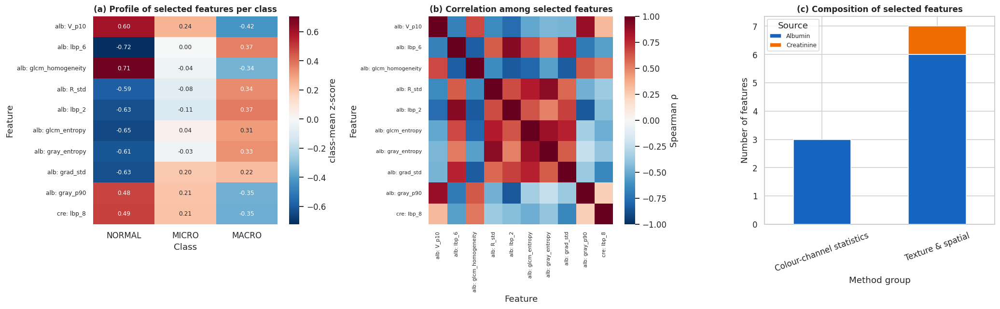

**Figure A22.** Features of the deployed model (k = 10): (a) per-class z-score profile, (b) correlation among selected features (redundancy controlled by the |r| < 0.9 filter), (c) composition by group and source.

Compact vs full pipeline on the training data: max |ΔP| = 0.00e+00, identical decisions = 100.0%


In [37]:
# ---------- 14.1 Train all five models on all samples (same procedure as in the nested CV) ----------
FINAL_SPLIT = list(StratifiedGroupKFold(n_splits=CFG['INNER_FOLDS'], shuffle=True, random_state=SEED).split(XM, y_all, g_all))
FIT, FIT_TIME = {}, {}
for name in MODEL_NAMES:
    t0 = time.time()
    gs = GridSearchCV(make_pipe(get_models()[name], k=K_GRID[0]), full_grid(name), scoring='f1_macro', cv=FINAL_SPLIT, n_jobs=-1, refit=True, return_train_score=True)
    gs.fit(XM, y_all)
    FIT[name] = gs; FIT_TIME[name] = time.time() - t0
    print(f'{name:22s} | best inner-CV macro-F1 = {gs.best_score_:.4f} | {FIT_TIME[name]:5.1f} s | {gs.best_params_}')

rows = []
for name, gs in FIT.items():
    i = gs.best_index_; cr = gs.cv_results_
    rows.append({'Model': name, 'Inner-CV macro-F1 (tuning score, optimistic)': cr['mean_test_score'][i], 'SD': cr['std_test_score'][i],
                 'Training macro-F1': cr['mean_train_score'][i], 'Train–validation gap': cr['mean_train_score'][i] - cr['mean_test_score'][i],
                 'k selected': int(gs.best_params_['sel__k']), 'Combinations tested': len(cr['params']), 'Time (s)': FIT_TIME[name],
                 'Outer-fold macro-F1 (honest, Stage 13)': f1_mean[name],
                 'Best parameters': json.dumps({k.replace('clf__', ''): v for k, v in gs.best_params_.items()}, default=str)})
tab_tune = pd.DataFrame(rows).round(4)
save_table(tab_tune, 'final_training_five_models', f'Final training of the five models on all samples (GridSearchCV, sample-grouped {CFG["INNER_FOLDS"]}-fold, macro-F1). The inner-CV score is the tuning score and is optimistic; the honest estimate is the outer-fold macro-F1 of Stage 13 (last numeric column).', index=False)
put('final_training', tab_tune.to_dict(orient='records'))

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
names_sorted = tab_tune.sort_values('Inner-CV macro-F1 (tuning score, optimistic)')['Model']
x_ = np.arange(len(names_sorted)); vv = tab_tune.set_index('Model').loc[names_sorted]
axs[0].barh(x_ - .27, vv['Training macro-F1'], .27, label='Training', color='#90CAF9')
axs[0].barh(x_, vv['Inner-CV macro-F1 (tuning score, optimistic)'], .27, xerr=vv['SD'], label='Inner CV (tuning)', color='#1565C0', capsize=3)
axs[0].barh(x_ + .27, vv['Outer-fold macro-F1 (honest, Stage 13)'], .27, label='Outer folds (honest)', color='#C62828')
axs[0].set_yticks(x_); axs[0].set_yticklabels(names_sorted); axs[0].set_xlabel('Macro-F1'); axs[0].legend(fontsize=8); axs[0].set_title('(a) Training vs tuning vs honest score'); axs[0].set_xlim(0, 1.05)
for name in MODEL_NAMES:
    s_ = np.sort(FIT[name].cv_results_['mean_test_score'])[::-1]
    axs[1].plot(np.arange(1, len(s_) + 1), s_, 'o-', ms=3, color=mcol[name], label=name)
axs[1].set_xscale('log'); axs[1].set_xlabel('Rank of hyperparameter combination'); axs[1].set_ylabel('Inner-CV macro-F1'); axs[1].legend(fontsize=8); axs[1].set_title('(b) Sensitivity to hyperparameters and k')
bp_ = [np.array(FIT[n].cv_results_['mean_test_score']) for n in MODEL_NAMES]
axs[2].boxplot(bp_, showmeans=True); axs[2].set_xticklabels([n.replace(' ', '\n', 1) for n in MODEL_NAMES], fontsize=8)
axs[2].set_xlabel('Model'); axs[2].set_ylabel('Inner-CV macro-F1'); axs[2].set_title('(c) Spread over all combinations (narrow box = insensitive to settings)')
fig.tight_layout()
save_fig(fig, 'final_training', 'Final training on all samples: (a) training, tuning (inner CV) and honest (outer folds) macro-F1 of the five models; (b) ranked performance over all hyperparameter/k combinations; (c) spread per model.')

# ---------- 14.2 The deployed model (pre-specified rule) ----------
FINAL = FIT[BEST_MODEL]
final_full = FINAL.best_estimator_
sel_idx = [int(i) for i in final_full.named_steps['sel'].support_]
SELECTED = [FEATS[i] for i in sel_idx]
FINAL_K = len(SELECTED)
FINAL_PARAMS = {k.replace('clf__', ''): v for k, v in FINAL.best_params_.items() if k != 'sel__k'}
print(f'DEPLOYED MODEL: {BEST_MODEL} | k = {FINAL_K} | hyperparameters = {FINAL_PARAMS}')
print(f'Modal configuration in the nested CV was k = {MODAL_K}, {MODAL_PARAMS} -> {"identical" if (MODAL_K == FINAL_K and {k: str(v) for k, v in MODAL_PARAMS.items()} == {k: str(v) for k, v in FINAL_PARAMS.items()}) else "differs (the final fit sees all samples; the evaluated procedure is the same)"}')
put('final_model', dict(name=BEST_MODEL, k=FINAL_K, hyperparameters=FINAL_PARAMS, selected_features=SELECTED, inner_cv_macro_f1=float(FINAL.best_score_),
                        modal_config_nested=dict(k=MODAL_K, params=MODAL_PARAMS)))

# ---------- 14.3 Selected features: significance, stability, importance ----------
sel_info = sig.set_index('feature').loc[SELECTED, ['source', 'group', 'F_anova', 'epsilon2', 'rho_ordinal', 'MI', 'q_FDR']].reset_index()
sel_info.insert(0, 'order', range(1, len(sel_info) + 1))
sel_info['selection frequency in nested CV'] = [stab.get(f, 0.0) for f in SELECTED]
sel_info['permutation importance (macro-F1 drop)'] = [pi_df['mean macro-F1 drop'].get(f, np.nan) for f in SELECTED]
save_table(sel_info.round(4), 'selected_features', f'The {FINAL_K} features used by the deployed model ({BEST_MODEL}), with descriptive significance (all samples), how often they were chosen in the nested-CV folds, and permutation importance.', index=False)
put('final_model.selected_table', sel_info.round(4).to_dict(orient='records'))
put('final_model.selected_composition', dict(by_source=sel_info.source.value_counts().to_dict(), by_group=sel_info.group.value_counts().to_dict()))

ds_sel = df_clean[['seq', 'sample', 'lux', 'label', 'y']].copy()
ds_sel = pd.concat([ds_sel, df_clean[SELECTED]], axis=1)
ds_sel.to_csv(TAB_DIR / 'Selected_Features_Dataset.csv', index=False, encoding='utf-8-sig')
try:
    ds_sel.to_excel(TAB_DIR / 'Selected_Features_Dataset.xlsx', index=False)
except Exception as e:
    print('xlsx export skipped:', e)
print('Selected dataset saved:', TAB_DIR / 'Selected_Features_Dataset.csv')

fig, axs = plt.subplots(1, 3, figsize=(19, 6))
Zs = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X_all[SELECTED]))
cm_ = pd.DataFrame(Zs, columns=[s_.replace('__', ': ') for s_ in SELECTED]).groupby(y_all).mean(); cm_.index = CLASSES
sns.heatmap(cm_.T, cmap='RdBu_r', center=0, annot=True, fmt='.2f', ax=axs[0], cbar_kws={'label': 'class-mean z-score'}, annot_kws={'size': 8})
axs[0].set_title('(a) Profile of selected features per class'); axs[0].set_xlabel('Class'); axs[0].set_ylabel('Feature'); axs[0].tick_params(axis='y', labelsize=8)
sns.heatmap(X_all[SELECTED].corr(method='spearman').rename(columns=lambda s_: s_.replace('__', ': '), index=lambda s_: s_.replace('__', ': ')),
            cmap='RdBu_r', vmin=-1, vmax=1, ax=axs[1], cbar_kws={'label': 'Spearman ρ'}); axs[1].set_title('(b) Correlation among selected features')
axs[1].set_xlabel('Feature'); axs[1].set_ylabel('Feature'); axs[1].tick_params(labelsize=7)
comp = sel_info.groupby(['group', 'source']).size().unstack(fill_value=0)
comp.plot(kind='bar', stacked=True, ax=axs[2], color=[SRC_COL[c] for c in comp.columns]); axs[2].set_ylabel('Number of features'); axs[2].set_xlabel('Method group')
axs[2].set_title('(c) Composition of selected features'); axs[2].tick_params(axis='x', rotation=20); axs[2].legend(title='Source', fontsize=8)
fig.tight_layout()
save_fig(fig, 'selected_features', f'Features of the deployed model (k = {FINAL_K}): (a) per-class z-score profile, (b) correlation among selected features (redundancy controlled by the |r| < {CFG["CORR_THR"]} filter), (c) composition by group and source.')

# ---------- 14.4 Compact pipeline (selected features only) and numerical equivalence check ----------
clf_final = clone(final_full.named_steps['clf'])
compact = Pipeline([('imp', _imputer()), ('rs', RobustScaler()), ('sc', StandardScaler()), ('clf', clf_final)])
compact.fit(X_all[SELECTED].values, y_all)
P_full = final_full.predict_proba(XM); P_comp = compact.predict_proba(X_all[SELECTED].values)
EQ_DIFF = float(np.abs(P_full - P_comp).max()); EQ_AGREE = float((P_full.argmax(1) == P_comp.argmax(1)).mean())
print(f'Compact vs full pipeline on the training data: max |ΔP| = {EQ_DIFF:.2e}, identical decisions = {EQ_AGREE * 100:.1f}%')
put('final_model.compact_equivalence', dict(max_abs_prob_difference=EQ_DIFF, identical_decisions_percent=EQ_AGREE * 100))
train_ranges = {}
for f in SELECTED:
    v = df_clean[f].dropna().values; lo, hi = float(v.min()), float(v.max()); m_ = 0.25 * (hi - lo)
    train_ranges[f] = [lo - m_, hi + m_]
put('final_model.training_resubstitution_note', dict(macro_f1_on_training_data=float(f1_score(y_all, P_comp.argmax(1), average='macro')),
    note='score on the data the model was trained on; NOT an estimate of performance (see nested CV)'))

In [38]:
# ---------- 14.5 Write the deployment bundle ----------
INFERENCE_SRC = r"""# uacr_inference.py - UACR category (NORMAL / MICRO / MACRO) from micropad images. RESEARCH PROTOTYPE.
#
# Usage (command line):
#     python uacr_inference.py ALB_1.png CRE_1.png [ALB_2.png CRE_2.png ...]
#         one image pair  -> single-measurement result
#         several pairs of the SAME sample -> probabilities are averaged
#
# Usage (library):
#     from uacr_inference import UACRModel
#     model = UACRModel()                                   # loads uacr_model.joblib next to this file
#     result = model.predict([("alb1.png", "cre1.png")])    # list of (albumin_image, creatinine_image) pairs
#     print(result["decision"], result["probabilities"])
#
# Decision rule: the class with the highest probability, unless that probability is below the stored threshold
# (single pair: tau_single, several pairs: tau_avg); then the decision is "UNCERTAIN" (uncertain: repeat the measurement).
# The thresholds are exploratory and must be confirmed on independent data before any clinical use.
import argparse
import json
import sys
from pathlib import Path

import numpy as np
from joblib import load

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))
import uacr_features as uf  # the same image-analysis code that produced the training features

UNCERTAIN_LABEL = "UNCERTAIN"
DISCLAIMER = ("Research prototype. Not validated for clinical decisions; expected performance is limited "
              "(see model_card.md). Confirm results with the laboratory method.")


class UACRModel:
    def __init__(self, model_path=None):
        self.model_path = Path(model_path) if model_path else HERE / "uacr_model.joblib"
        self.pack = load(self.model_path)
        self.classes = list(self.pack["classes"])
        self.features = list(self.pack["features_in"])
        self.pipeline = self.pack["pipeline"]
        self.roi_params = self.pack["roi_params"]
        self.ranges = self.pack.get("train_ranges", {})
        self.tau_single = float(self.pack["tau_single"])
        self.tau_avg = float(self.pack["tau_avg"])

    def _extract(self, alb, cre):
        r = uf.process_pair(dict(path_alb=str(alb), path_cre=str(cre)), self.roi_params)
        if not r["ok"]:
            raise RuntimeError("Image pair could not be analysed: " + str(r["err"]))
        return r

    def predict(self, pairs):
        if isinstance(pairs, (tuple, list)) and len(pairs) == 2 and not isinstance(pairs[0], (tuple, list)):
            pairs = [pairs]
        rows, qc = [], []
        for alb, cre in pairs:
            r = self._extract(alb, cre)
            vals = [r.get(f, np.nan) for f in self.features]
            rows.append(vals)
            flags = []
            for role, nm in (("alb", "albumin"), ("cre", "creatinine")):
                if r.get(role + "__roi_method") == "fallback_circle":
                    flags.append(nm + " image: ROI not found automatically (fallback circle used) - check the image")
            out = [f for f, v in zip(self.features, vals) if f in self.ranges and not (self.ranges[f][0] <= v <= self.ranges[f][1])]
            if out:
                flags.append("input outside the range seen in training for: " + ", ".join(out))
            if any(not np.isfinite(v) for v in vals):
                flags.append("some feature values are missing/non-finite")
            qc.append(dict(albumin_image=str(alb), creatinine_image=str(cre), flags=flags))
        P = self.pipeline.predict_proba(np.asarray(rows, dtype=float))
        p = P.mean(axis=0)
        top = int(np.argmax(p))
        tau = self.tau_single if len(rows) == 1 else self.tau_avg
        uncertain = bool(p[top] < tau)
        any_flag = any(q["flags"] for q in qc)
        return {
            "decision": UNCERTAIN_LABEL if uncertain else self.classes[top],
            "most_likely_class": self.classes[top],
            "probabilities": {c: float(v) for c, v in zip(self.classes, p)},
            "max_probability": float(p[top]),
            "uncertain": uncertain,
            "threshold_used": tau,
            "n_pairs": len(rows),
            "per_pair_probabilities": [{c: float(v) for c, v in zip(self.classes, row)} for row in P],
            "quality_flags": [q for q in qc if q["flags"]],
            "input_quality_ok": not any_flag,
            "disclaimer": DISCLAIMER,
        }


def main(argv=None):
    ap = argparse.ArgumentParser(description="UACR category from micropad images (research prototype)")
    ap.add_argument("images", nargs="+", help="albumin and creatinine image paths, in pairs: ALB1 CRE1 [ALB2 CRE2 ...]")
    ap.add_argument("--model", default=None, help="path to uacr_model.joblib (default: next to this file)")
    a = ap.parse_args(argv)
    if len(a.images) % 2:
        ap.error("images must be given as pairs: ALB CRE [ALB CRE ...]")
    pairs = [(a.images[i], a.images[i + 1]) for i in range(0, len(a.images), 2)]
    print(json.dumps(UACRModel(a.model).predict(pairs), indent=2))


if __name__ == "__main__":
    main()
"""

(MODEL_DIR / 'uacr_inference.py').write_text(INFERENCE_SRC, encoding='utf-8')
from importlib import metadata as _md
def _ver(p):
    try: return _md.version(p)
    except Exception: return None
REQ = {p_: _ver(p_) for p_ in ('numpy', 'scipy', 'scikit-learn', 'joblib', 'opencv-python-headless', 'scikit-image')}
if REQ['opencv-python-headless'] is None:
    REQ['opencv-python-headless'] = _ver('opencv-python') or cv2.__version__
(MODEL_DIR / 'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k, v in REQ.items() if v) + '\n', encoding='utf-8')

pack = dict(pipeline=compact, classes=CLASSES, features_in=SELECTED, roi_params=ROI_PARAMS, tau_single=TAU_SINGLE, tau_avg=TAU_AVG,
            model_name=BEST_MODEL, hyperparameters=FINAL_PARAMS, k=FINAL_K, train_ranges=train_ranges, sklearn_version=sklearn.__version__,
            module_version=uf.MODULE_VERSION, module_sha256=MODULE_SHA,
            trained_on=dict(samples=int(df_clean['sample'].nunique()), tests=int(len(df_clean)), samples_per_class=n_by_class.to_dict()),
            created=datetime.datetime.now().isoformat(timespec='seconds'))
dump(pack, MODEL_DIR / 'uacr_model.joblib', compress=3)
sel_info.round(5).to_csv(MODEL_DIR / 'selected_features.csv', index=False, encoding='utf-8-sig')
deploy_cfg = dict(model=BEST_MODEL, hyperparameters=FINAL_PARAMS, k=FINAL_K, selected_features=SELECTED, classes=CLASSES, roi_params=ROI_PARAMS,
                  tau_single=TAU_SINGLE, tau_avg=TAU_AVG, uncertain_label='UNCERTAIN', requirements=REQ, python=sys.version.split()[0],
                  module_sha256=MODULE_SHA, module_version=uf.MODULE_VERSION, decision_rule='class with highest mean probability unless max probability < tau',
                  training=pack['trained_on'], created=pack['created'])
(MODEL_DIR / 'deployment_config.json').write_text(json.dumps(_jsonable(deploy_cfg), indent=2, ensure_ascii=False), encoding='utf-8')
print('Bundle files:', sorted(p.name for p in MODEL_DIR.iterdir()))

Bundle files: ['README_deploy.md', '__pycache__', 'bundle_selftest.json', 'deployment_config.json', 'model_card.md', 'requirements.txt', 'selected_features.csv', 'uacr_features.py', 'uacr_inference.py', 'uacr_model.joblib']


In [39]:
# ---------- 14.6 Self-test: the bundle must reproduce the notebook's predictions from the images alone ----------
import tempfile
sys.path.insert(0, str(MODEL_DIR))
import uacr_inference as ui
importlib.reload(ui)
ui_model = ui.UACRModel(MODEL_DIR / 'uacr_model.joblib')

# test pairs: two per class (taken from the cleaned dataset, so the training feature row is available for comparison)
rng_t = np.random.default_rng(SEED)
test_rows = []
for c in CLASSES:
    sub = df_clean[df_clean.label == c]
    test_rows += [sub.iloc[i] for i in rng_t.choice(len(sub), size=min(2, len(sub)), replace=False)]
src_rows = [df_pairs[(df_pairs.seq == r['seq']) & (df_pairs['sample'] == r['sample'])].iloc[0] for r in test_rows]

tmp_bundle = Path(tempfile.mkdtemp(prefix='uacr_bundle_'))
for fn in ('uacr_model.joblib', 'uacr_features.py', 'uacr_inference.py'):
    shutil.copy2(MODEL_DIR / fn, tmp_bundle / fn)
clean_env = {k: v for k, v in os.environ.items() if k not in ('PYTHONPATH', 'UACR_DATA_DIR', 'UACR_OUT_DIR', 'UACR_FAST')}
st_rows = []
for r, s in zip(test_rows, src_rows):
    direct = compact.predict_proba(df_clean.loc[[r.name], SELECTED].values)[0]                       # training feature row -> pipeline
    inproc = ui_model.predict([(s.path_alb, s.path_cre)])                                            # images -> bundle code (this process)
    proc = subprocess.run([sys.executable, str(tmp_bundle / 'uacr_inference.py'), str(s.path_alb), str(s.path_cre)], capture_output=True, text=True,
                          cwd=tempfile.gettempdir(), env=clean_env)
    if proc.returncode != 0:
        raise RuntimeError('Bundle self-test failed in the clean process:\n' + proc.stderr[-1500:])
    sub_out = json.loads(proc.stdout)
    p_in = np.array([inproc['probabilities'][c] for c in CLASSES]); p_sub = np.array([sub_out['probabilities'][c] for c in CLASSES])
    st_rows.append({'sample': int(r['sample']), 'true class': r['label'], 'decision (clean process)': sub_out['decision'], 'max probability': round(sub_out['max_probability'], 3),
                    'max |P(images) − P(training row)|': float(np.abs(p_in - direct).max()), 'max |P(clean process) − P(this process)|': float(np.abs(p_sub - p_in).max())})
st = pd.DataFrame(st_rows)
save_table(st, 'bundle_selftest', 'Self-test of the deployment bundle on six image pairs: probabilities recomputed from the images by the bundle (in this process and in a clean Python process that has only the three bundle files) versus the probabilities from the training feature matrix.', index=False)
SELFTEST_OK = bool(st.iloc[:, -2:].max().max() < 1e-4)
# several pairs of one sample -> averaged probabilities
smp = int(test_rows[0]['sample']); pr_s = df_pairs[df_pairs['sample'] == smp]
multi = ui_model.predict([(a, b) for a, b in zip(pr_s.path_alb, pr_s.path_cre)])
print(f'Self-test passed: {SELFTEST_OK} | max difference {st.iloc[:, -2:].max().max():.2e} | sample {smp} with {multi["n_pairs"]} pairs -> {multi["decision"]} {multi["probabilities"]}')
put('bundle_selftest', dict(passed=SELFTEST_OK, max_difference=float(st.iloc[:, -2:].max().max()), n_cases=len(st), rows=st.to_dict(orient='records'), example_multi_pair=multi))
(MODEL_DIR / 'bundle_selftest.json').write_text(json.dumps(_jsonable(NUM['bundle_selftest']), indent=2, ensure_ascii=False), encoding='utf-8')
shutil.rmtree(tmp_bundle, ignore_errors=True)
assert SELFTEST_OK, 'The deployment bundle does not reproduce the notebook predictions - do not use it.'

**Table A26.** Self-test of the deployment bundle on six image pairs: probabilities recomputed from the images by the bundle (in this process and in a clean Python process that has only the three bundle files) versus the probabilities from the training feature matrix.

,sample,true class,decision (clean process),max probability,max |P(images) − P(training row)|,max |P(clean process) − P(this process)|
0,101,NORMAL,UNCERTAIN,0.410,0.0,0.0
1,124,NORMAL,UNCERTAIN,0.434,0.0,0.0
2,38,MICRO,MICRO,0.528,0.0,0.0
3,129,MICRO,MICRO,0.598,0.0,0.0
4,48,MACRO,MACRO,0.832,0.0,0.0
5,5,MACRO,MACRO,0.817,0.0,0.0


Self-test passed: True | max difference 0.00e+00 | sample 101 with 5 pairs -> UNCERTAIN {'NORMAL': 0.4599751202526178, 'MICRO': 0.33272887096511283, 'MACRO': 0.20729600878226936}


In [40]:
# ---------- 14.7 Model card (numbers are taken from this run) ----------
def _ms(model, metric, level='test_level'):
    d = NUM['nested'][level][model][metric]; return f"{d['mean']:.3f} ± {d['sd']:.3f}"
ss = NUM['nested']['seed_sensitivity']; pm = NUM['permutation_test']; ab = NUM['abstain']
card = f"""# Model card — UACR category from micropad images (research prototype)

*Generated automatically by `UACR_Integrated_Pipeline.ipynb` on {pack['created']}. Every number below comes from that run.*

## 1. Intended use and non-use
* **Intended use:** research prototype that estimates the urine albumin-to-creatinine ratio category — **NORMAL (< 30 mg/g), MICRO (30–300 mg/g), MACRO (> 300 mg/g)** — from one pair of micropad images (albumin assay + creatinine assay), as a decision-support experiment for a diagnosis device.
* **Not for:** clinical decisions on its own, screening without laboratory confirmation, other reagents, cameras, lighting set-ups or sample matrices than those of the training data.

## 2. Model
* **Algorithm:** {BEST_MODEL}, chosen by the pre-specified rule (highest mean outer-fold macro-F1 in nested cross-validation). Hyperparameters: `{FINAL_PARAMS}`.
* **Input:** {FINAL_K} image features (listed in `selected_features.csv`) computed by `uacr_features.py` from the two ROI images; pipeline = median imputation → robust scaling → standard scaling → classifier.
* **Output:** class probabilities and a decision; the decision is **UNCERTAIN** (uncertain) when the highest probability is below {TAU_SINGLE:.2f} (one pair) or {TAU_AVG:.2f} (several pairs of the same sample averaged). These thresholds are exploratory.

## 3. Training data
{pack['trained_on']['samples']} urine samples ({', '.join(f'{k}: {v}' for k, v in pack['trained_on']['samples_per_class'].items())}), {pack['trained_on']['tests']} tests (image pairs, several per sample) after cleaning; labels from the laboratory UACR (Cobas) with KDIGO thresholds. Illumination (lux) and laboratory values were **not** used as inputs.

## 4. Expected performance (nested cross-validation; NOT the training score)
Estimated by {NUM['validation_design']['outer_folds']}×{NUM['validation_design']['outer_repeats']} sample-grouped nested cross-validation, in which feature selection, k and hyperparameters were chosen without the test fold.

| Quantity (mean ± SD over {NUM['validation_design']['n_outer']} outer folds) | One measurement (test level) | Repeats averaged (sample level) |
|---|---|---|
| Macro-F1 | {_ms(BEST_MODEL, 'F1 (macro)')} | {_ms(BEST_MODEL, 'F1 (macro)', 'sample_level')} |
| Balanced accuracy | {_ms(BEST_MODEL, 'Balanced Acc')} | {_ms(BEST_MODEL, 'Balanced Acc', 'sample_level')} |
| MCC | {_ms(BEST_MODEL, 'MCC')} | {_ms(BEST_MODEL, 'MCC', 'sample_level')} |
| Recall NORMAL | {_ms(BEST_MODEL, 'Recall NORMAL')} | {_ms(BEST_MODEL, 'Recall NORMAL', 'sample_level')} |
| Recall MICRO | {_ms(BEST_MODEL, 'Recall MICRO')} | {_ms(BEST_MODEL, 'Recall MICRO', 'sample_level')} |
| Recall MACRO | {_ms(BEST_MODEL, 'Recall MACRO')} | {_ms(BEST_MODEL, 'Recall MACRO', 'sample_level')} |

* Chance level of macro-F1 is about 0.33; the stratified random baseline scored {_ms('Baseline: stratified random guess', 'F1 (macro)')} and the majority-class baseline {_ms('Baseline: majority class', 'F1 (macro)')} on the same folds.
* Sensitivity to the random division into folds: mean macro-F1 across {len(ss['values_extra']) + NUM['validation_design']['outer_repeats']} nested-CV runs = {ss['mean_all']:.3f}, range {ss['min_all']:.3f} – {ss['max_all']:.3f}.
* Label-permutation test ({pm['n_permutations']} permutations): observed macro-F1 {pm['real_macro_f1']:.3f} versus null mean {pm['null_mean']:.3f} (95th percentile {pm['null_p95']:.3f}); p = {pm['p_value']:.3f}.
* The five models were not clearly distinguishable: Friedman p = {NUM['nested']['friedman_test_level']['p']:.3g}; any pairwise difference significant after correction: {NUM['nested']['any_pairwise_significant']}.
* Uncertain zone (exploratory, out-of-fold): at the stored single-measurement threshold {ab['tau_single']:.2f}, coverage = {ab['test_level']['coverage']:.2f} and macro-F1 on the accepted results = {ab['test_level']['macro_f1']:.3f} (without abstention: {ab['test_level']['Macro-F1 without abstention']:.3f}).

## 5. Known limitations
* Small sample ({pack['trained_on']['samples']} samples; minority classes about {min(pack['trained_on']['samples_per_class'].values())}); the performance estimate has wide uncertainty and was obtained on one dataset (no external validation).
* The measurement audit (report section on the limits of image information) shows how much analyte information the images carry; classification performance cannot exceed that ceiling. MICRO (30–300 mg/g) is the weakest class.
* Samples whose laboratory UACR lies close to 30 or 300 mg/g are intrinsically ambiguous.
* Validity requires the same reagent pads, camera/lighting set-up and image framing as the training data; the device flags images whose ROI was not found or whose features fall outside the training range.
* The uncertain-zone thresholds were tuned on the same out-of-fold predictions that are used to describe them; confirm on independent data.

## 6. Reproducibility
Python {sys.version.split()[0]}, scikit-learn {sklearn.__version__} (the model file must be loaded with the same major scikit-learn version; see `requirements.txt`). `uacr_features.py` SHA-256 = `{MODULE_SHA}`. Seeds fixed (SEED = {SEED}). Bundle self-test passed: {SELFTEST_OK}.
"""
(MODEL_DIR / 'model_card.md').write_text(card, encoding='utf-8')
readme = f"""# Deployment bundle — UACR classifier (research prototype)

Files
* `uacr_model.joblib` – trained pipeline + metadata (selected features, ROI parameters, uncertain-zone thresholds, training ranges)
* `uacr_features.py` – image analysis (ROI detection + feature extraction); the SAME file produced the training features
* `uacr_inference.py` – image pair(s) → class, probabilities, "UNCERTAIN" flag, quality flags
* `model_card.md` – intended use, expected performance (nested CV), limitations
* `deployment_config.json`, `selected_features.csv`, `requirements.txt`, `bundle_selftest.json`

Quick start
```
pip install -r requirements.txt
python uacr_inference.py ALBUMIN.png CREATININE.png
python uacr_inference.py ALB1.png CRE1.png ALB2.png CRE2.png     # repeats of the same sample are averaged
```
```python
from uacr_inference import UACRModel
print(UACRModel().predict([("alb.png", "cre.png")]))
```
The three files `uacr_model.joblib`, `uacr_features.py`, `uacr_inference.py` are all the device needs.
"""
(MODEL_DIR / 'README_deploy.md').write_text(readme, encoding='utf-8')
display(Markdown(card))
sync_to_drive(verbose=False)
stage_done('14 final training & deployment bundle')

# Model card — UACR category from micropad images (research prototype)

*Generated automatically by `UACR_Integrated_Pipeline.ipynb` on 2026-10-30T16:02:32. Every number below comes from that run.*

## 1. Intended use and non-use
* **Intended use:** research prototype that estimates the urine albumin-to-creatinine ratio category — **NORMAL (< 30 mg/g), MICRO (30–300 mg/g), MACRO (> 300 mg/g)** — from one pair of micropad images (albumin assay + creatinine assay), as a decision-support experiment for a diagnosis device.
* **Not for:** clinical decisions on its own, screening without laboratory confirmation, other reagents, cameras, lighting set-ups or sample matrices than those of the training data.

## 2. Model
* **Algorithm:** SVM (RBF), chosen by the pre-specified rule (highest mean outer-fold macro-F1 in nested cross-validation). Hyperparameters: `{'C': 10, 'gamma': 0.05}`.
* **Input:** 10 image features (listed in `selected_features.csv`) computed by `uacr_features.py` from the two ROI images; pipeline = median imputation → robust scaling → standard scaling → classifier.
* **Output:** class probabilities and a decision; the decision is **UNCERTAIN** (uncertain) when the highest probability is below 0.44 (one pair) or 0.53 (several pairs of the same sample averaged). These thresholds are exploratory.

## 3. Training data
100 urine samples (NORMAL: 25, MICRO: 25, MACRO: 50), 478 tests (image pairs, several per sample) after cleaning; labels from the laboratory UACR (Cobas) with KDIGO thresholds. Illumination (lux) and laboratory values were **not** used as inputs.

## 4. Expected performance (nested cross-validation; NOT the training score)
Estimated by 5×2 sample-grouped nested cross-validation, in which feature selection, k and hyperparameters were chosen without the test fold.

| Quantity (mean ± SD over 10 outer folds) | One measurement (test level) | Repeats averaged (sample level) |
|---|---|---|
| Macro-F1 | 0.510 ± 0.090 | 0.502 ± 0.092 |
| Balanced accuracy | 0.523 ± 0.098 | 0.540 ± 0.099 |
| MCC | 0.335 ± 0.133 | 0.371 ± 0.141 |
| Recall NORMAL | 0.563 ± 0.202 | 0.660 ± 0.190 |
| Recall MICRO | 0.229 ± 0.101 | 0.135 ± 0.156 |
| Recall MACRO | 0.778 ± 0.080 | 0.825 ± 0.106 |

* Chance level of macro-F1 is about 0.33; the stratified random baseline scored 0.332 ± 0.043 and the majority-class baseline 0.221 ± 0.023 on the same folds.
* Sensitivity to the random division into folds: mean macro-F1 across 7 nested-CV runs = 0.497, range 0.471 – 0.521.
* Label-permutation test (100 permutations): observed macro-F1 0.524 versus null mean 0.306 (95th percentile 0.379); p = 0.010.
* The five models were not clearly distinguishable: Friedman p = 0.0366; any pairwise difference significant after correction: False.
* Uncertain zone (exploratory, out-of-fold): at the stored single-measurement threshold 0.44, coverage = 0.89 and macro-F1 on the accepted results = 0.530 (without abstention: 0.511).

## 5. Known limitations
* Small sample (100 samples; minority classes about 25); the performance estimate has wide uncertainty and was obtained on one dataset (no external validation).
* The measurement audit (report section on the limits of image information) shows how much analyte information the images carry; classification performance cannot exceed that ceiling. MICRO (30–300 mg/g) is the weakest class.
* Samples whose laboratory UACR lies close to 30 or 300 mg/g are intrinsically ambiguous.
* Validity requires the same reagent pads, camera/lighting set-up and image framing as the training data; the device flags images whose ROI was not found or whose features fall outside the training range.
* The uncertain-zone thresholds were tuned on the same out-of-fold predictions that are used to describe them; confirm on independent data.

## 6. Reproducibility
Python 3.13.16, scikit-learn 1.6.1 (the model file must be loaded with the same major scikit-learn version; see `requirements.txt`). `uacr_features.py` SHA-256 = `0dd35f167e79ae415b4b7f1dd7b58e9340462085756710554763206720c91362`. Seeds fixed (SEED = 42). Bundle self-test passed: True.


# Stage 16 · Report Bundle and Summary of Findings

**Purpose.** Save everything needed to write the final report, with fixed names, so that the report and the deployed model rest on the same run:

| File | Content |
|---|---|
| `report/report_numbers.json` | every number that the report may quote (data counts, cleansing, audit, significance, nested-CV results, tests, robustness, errors, calibration, final model, self-test) |
| `report/Findings_Summary.md` | automatic one-page summary computed from `report_numbers.json` |
| `report/experiment_configuration.json` | all parameters, library versions, hashes |
| `report/Figure_List.csv`, `report/Table_List.csv` | numbering and captions of all figures and tables |
| `report/file_manifest.csv` | every output file with size and SHA-256 |
| `figures/Figure_NN_*.png` (300 dpi), `tables/Table_NN_*.csv` | numbered figures and tables |
| `model/…` | the deployment bundle (Stage 15) |

The narrative report is **not** generated by the notebook: it is written from these files, so no sentence can claim more than the numbers support.

In [41]:
# ---------- 15.1 Automatic summary of findings (actual numbers from this run) ----------
N_ = NUM; nt = N_['nested']['test_level']; ns = N_['nested']['sample_level']
def mm(d, m): return f"{d[m]['mean']:.3f} ± {d[m]['sd']:.3f}"
lines = ['### Summary of findings (unified pipeline)\n']
lines.append(f"- **Data.** {N_['cleansing']['final']['samples']} samples ({', '.join(f'{k}: {v}' for k, v in N_['cleansing']['final']['samples_per_class'].items())}), "
             f"{N_['cleansing']['final']['tests']} test image pairs after cleaning; {N_['features']['n_generated']} features generated, {N_['cleansing']['final']['features']} passed the reliability filter (ICC ≥ {N_['cleansing']['icc_threshold']:.2f}).")
a = N_['audit']['summary']
lines.append(f"- **Measurement audit (grouped CV, Random Forest).** R² for log albumin = {a['r2_log_albumin_RF']:.2f}, log creatinine = {a['r2_log_creatinine_RF']:.2f}, log UACR = {a['r2_log_uacr_RF']:.2f}; RMSE of log₁₀ UACR = {a['rmse_log_uacr_direct']:.2f}.")
lines.append(f"- **Nested CV, {N_['validation_design']['n_outer']} outer folds, test level (macro-F1, mean ± SD):** " + '; '.join(f"{n} {mm(nt[n], 'F1 (macro)')}" for n in MODEL_NAMES) +
             f". Baselines: majority class {mm(nt['Baseline: majority class'], 'F1 (macro)')}, stratified random {mm(nt['Baseline: stratified random guess'], 'F1 (macro)')}.")
lines.append(f"- **Sample level (macro-F1):** " + '; '.join(f"{n} {mm(ns[n], 'F1 (macro)')}" for n in MODEL_NAMES) + '.')
lines.append(f"- **Selected by the pre-specified rule:** {BEST_MODEL}. Friedman test p = {N_['nested']['friedman_test_level']['p']:.3g}; any pairwise difference significant after Holm correction: {N_['nested']['any_pairwise_significant']}.")
lines.append(f"- **MICRO recall (test level):** " + '; '.join(f"{n} {mm(nt[n], 'Recall MICRO')}" for n in MODEL_NAMES) + '.')
ssn = N_['nested']['seed_sensitivity']
lines.append(f"- **Robustness of {BEST_MODEL}:** across {len(ssn['values_extra']) + N_['validation_design']['outer_repeats']} nested-CV runs with different splits, macro-F1 ranges {ssn['min_all']:.3f} – {ssn['max_all']:.3f}; label-permutation p = {N_['permutation_test']['p_value']:.3f} (null 95th percentile {N_['permutation_test']['null_p95']:.3f}).")
lines.append(f"- **Errors ({BEST_MODEL}, sample level, OOF repeat 1):** {N_['errors']['n_errors']} of {N_['errors']['n_samples']} wrong; {N_['errors']['two_level']} two-level errors; median log₁₀ distance to the nearest threshold: wrong {N_['errors']['median_dist_wrong']:.2f} vs correct {N_['errors']['median_dist_correct']:.2f}.")
lines.append(f"- **Uncertain zone (exploratory):** single-measurement threshold {N_['abstain']['tau_single']:.2f} → coverage {N_['abstain']['test_level']['coverage']:.2f}, macro-F1 on accepted {N_['abstain']['test_level']['macro_f1']:.3f} (without abstention {N_['abstain']['test_level']['Macro-F1 without abstention']:.3f}).")
lines.append(f"- **Deployed model:** {BEST_MODEL}, k = {FINAL_K} features, bundle self-test passed = {N_['bundle_selftest']['passed']}.")
summary_md = '\n'.join(lines); display(Markdown(summary_md))
(REPORT_DIR / 'Findings_Summary.md').write_text(summary_md, encoding='utf-8')

# ---------- 15.2 Configuration, lists, manifest ----------
put('runtime.total_minutes', (time.time() - T_NOTEBOOK_START) / 60)
exp_cfg = dict(config=NUM['config'], environment=NUM['environment'], seed=SEED, roi_params=ROI_PARAMS, module_sha256=MODULE_SHA, feature_cache_key=cache_key, feature_cache_source=cache_source,
               models=MODEL_NAMES, grids={k: {a_: [str(x) for x in b_] for a_, b_ in v.items()} for k, v in GRID.items()}, k_grid=K_GRID, selected_model=BEST_MODEL, final_params=FINAL_PARAMS,
               final_k=FINAL_K, selected_features=SELECTED, thresholds=dict(tau_single=TAU_SINGLE, tau_avg=TAU_AVG), packages=REQ)
(REPORT_DIR / 'experiment_configuration.json').write_text(json.dumps(_jsonable(exp_cfg), indent=2, ensure_ascii=False), encoding='utf-8')
pd.DataFrame(FIG_REG).to_csv(REPORT_DIR / 'Figure_List.csv', index=False, encoding='utf-8-sig')
save_table(pd.DataFrame(FIG_REG), 'figure_list', 'List of figures produced by the notebook (for numbering).', index=False, show=False)
pd.DataFrame(TAB_REG).to_csv(REPORT_DIR / 'Table_List.csv', index=False, encoding='utf-8-sig')
display(pd.DataFrame(FIG_REG)[['number', 'file', 'caption']])
dump_numbers()

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, 'rb') as fh:
        for blk in iter(lambda: fh.read(chunk), b''): h.update(blk)
    return h.hexdigest()
man = pd.DataFrame([{'file': str(p.relative_to(OUT_DIR)), 'bytes': p.stat().st_size, 'sha256': sha256_file(p)} for p in sorted(OUT_DIR.rglob('*'))
                    if p.is_file() and 'cache' not in p.relative_to(OUT_DIR).parts and p.name != 'file_manifest.csv'])
man.to_csv(REPORT_DIR / 'file_manifest.csv', index=False, encoding='utf-8-sig')
(REPORT_DIR / 'README_outputs.md').write_text(f"""# outputs/A_ML — contents

* `figures/` – {len(FIG_REG)} numbered figures (300 dpi PNG)
* `tables/` – {len(TAB_REG)} numbered tables (CSV) + cleaned dataset + selected-feature dataset
* `model/` – deployment bundle (see `model/README_deploy.md` and `model/model_card.md`)
* `report/` – `report_numbers.json`, `Findings_Summary.md`, `experiment_configuration.json`, `Figure_List.csv`, `Table_List.csv`, `file_manifest.csv`
* `cache/` – cached feature matrix and nested-CV results (safe to delete; speeds up re-runs)

Run finished: {datetime.datetime.now().isoformat(timespec='seconds')} · total {NUM['runtime']['total_minutes']:.0f} min · fast mode = {CFG['FAST_MODE']}
""", encoding='utf-8')
sync_to_drive()
print(f'Total {len(FIG_REG)} figures and {len(TAB_REG)} tables saved in: {OUT_DIR}')
print(f'Numbers, figure and table lists are in: {REPORT_DIR}')
print(f'Everything for the device is in: {MODEL_DIR}')
stage_done('15 report bundle')

### Summary of findings (unified pipeline)

- **Data.** 100 samples (NORMAL: 25, MICRO: 25, MACRO: 50), 478 test image pairs after cleaning; 277 features generated, 163 passed the reliability filter (ICC ≥ 0.50).
- **Measurement audit (grouped CV, Random Forest).** R² for log albumin = 0.30, log creatinine = 0.16, log UACR = 0.20; RMSE of log₁₀ UACR = 0.87.
- **Nested CV, 10 outer folds, test level (macro-F1, mean ± SD):** Logistic Regression 0.495 ± 0.078; SVM (RBF) 0.510 ± 0.090; Random Forest 0.477 ± 0.077; Gradient Boosting 0.441 ± 0.088; k-NN 0.455 ± 0.075. Baselines: majority class 0.221 ± 0.023, stratified random 0.332 ± 0.043.
- **Sample level (macro-F1):** Logistic Regression 0.507 ± 0.100; SVM (RBF) 0.502 ± 0.092; Random Forest 0.513 ± 0.123; Gradient Boosting 0.460 ± 0.149; k-NN 0.462 ± 0.118.
- **Selected by the pre-specified rule:** SVM (RBF). Friedman test p = 0.0366; any pairwise difference significant after Holm correction: False.
- **MICRO recall (test level):** Logistic Regression 0.327 ± 0.116; SVM (RBF) 0.229 ± 0.101; Random Forest 0.232 ± 0.077; Gradient Boosting 0.233 ± 0.096; k-NN 0.133 ± 0.080.
- **Robustness of SVM (RBF):** across 7 nested-CV runs with different splits, macro-F1 ranges 0.471 – 0.521; label-permutation p = 0.010 (null 95th percentile 0.379).
- **Errors (SVM (RBF), sample level, OOF repeat 1):** 39 of 100 wrong; 11 two-level errors; median log₁₀ distance to the nearest threshold: wrong 0.29 vs correct 0.50.
- **Uncertain zone (exploratory):** single-measurement threshold 0.44 → coverage 0.89, macro-F1 on accepted 0.530 (without abstention 0.511).
- **Deployed model:** SVM (RBF), k = 10 features, bundle self-test passed = True.

**Table A27.** List of figures produced by the notebook (for manuscript numbering).

,number,file,caption
0,A1,FigA01_diagnostic_regression.png,Measurement audit: cross-validated R² (a) and ...
1,A2,FigA02_dose_response_bins.png,Dose–response of four pre-specified albumin-im...
2,A3,FigA03_within_band_response.png,Within-band response of the best albumin-image...
3,A4,FigA04_reliability_by_source.png,Reliability and illumination sensitivity by im...
4,A5,FigA05_error_budget.png,(a) Error budget: macro-F1 when albumin or cre...
5,A6,FigA06_feature_significance.png,"Feature significance tests (all samples, descr..."
6,A7,FigA07_k_feature_curve.png,Descriptive k-curve: sample-grouped 5-fold cro...
7,A8,FigA08_nested_cv_comparison.png,Nested cross-validation (10 outer folds): (a) ...
8,A9,FigA09_cm_nested_test_level.png,Out-of-fold confusion matrices of the five mod...
9,A10,FigA10_cm_nested_sample_level.png,Out-of-fold confusion matrices at the sample l...


Results copied to Drive: data 2026/outputs (9 new/changed files)
Total 22 figures and 27 tables saved in: /content/outputs/A_ML
Everything for the report is in: /content/outputs/A_ML/report
Everything for the device is in: /content/outputs/A_ML/model


## How to read the results (decision guide, fixed in advance)

| Observation | Interpretation |
|---|---|
| Audit: R² for log albumin near 0 and within-band maxima below the permutation null | The images do not resolve albumin *inside* a clinical band; classification relies on between-band contrasts, and no classifier can exceed that ceiling. The remedy is in the assay/acquisition (pad dynamic range, reference patch, fixed lighting), not in the choice of model. |
| Nested-CV macro-F1 clearly above both baselines and the permutation null (p small) but far from 1 | The images carry real but limited class information. Report the range, not a single best value. |
| Friedman test not significant / no pair significant after correction | The five models are statistically indistinguishable on this sample size; the choice of the deployed model by the pre-specified rule is a convention, not a proof of superiority. |
| Wide spread across split seeds | The point estimate depends on the random division of ≈ 100 samples; quote the range. |
| MICRO recall low in all models | The 30–300 mg/g band is narrow (one decade) relative to the achieved error (error budget). A *screening* use (NORMAL vs ≥ MICRO), or the “UNCERTAIN” zone, is the realistic operating mode. |
| Errors concentrated near 30 and 300 mg/g | Part of the error is label ambiguity (see the near-threshold table), not model failure. |
| Accuracy on accepted results rises while coverage falls | The uncertain zone works as designed; the threshold must be confirmed on independent data. |

## Study limitations and recommendations
1. **Small sample size (≈ 100 samples; minority classes ≈ 25).** All estimates carry large uncertainty; paired tests are indicative; **external validation** on an independent cohort/day/operator/device is required before any claim of clinical performance.
2. **Labels derive from laboratory UACR at 30 and 300 mg/g.** Samples close to a threshold are intrinsically ambiguous.
3. **Data-quality notes in the source file** (swapped values, suspected duplicates, merged PDF columns) are flagged in Stage 3 and must be verified against the originals before publication.
4. **Illumination and white balance.** The features use the absolute colour of the ROI; a physical reference patch in every photo and a fixed lighting box remain the most robust improvement.
5. **Repeated tests are not independent samples.** All evaluation is group-based; test-level metrics must not be read as the number of independent samples.
6. **The uncertain-zone thresholds** are exploratory (tuned on out-of-fold predictions of the same data).
7. **Further development:** replicate-averaged measurement at inference, probability calibration on new data, a reference patch, and a screening-oriented decision analysis.

In [42]:
use_scope('B')
CKPT_DIR = CACHE_DIR / 'cnn_tasks'; CKPT_DIR.mkdir(exist_ok=True)
set_seed(SEED)
print('Path B reads the common analysis set from', SCOPE_PATH['S'] / 'tables', 'and the classical results from', SCOPE_PATH['A'])
if DEVICE.type == 'cpu' and not CFG['FAST_MODE']:
    print('WARNING: no GPU. Stage 22 (fine-tuning) will take many hours on CPU. Switch the runtime to T4 GPU.')

**Output scope → `B_CNN`** — Part III - Path B: convolutional neural networks (figures and tables are numbered B1, B2, …)

Path B reads the common analysis set from /content/outputs/0_Shared/tables and the classical results from /content/outputs/A_ML


# Stage 17 · Load the Common Analysis Set and Re-build the *Identical* Outer Folds

**Purpose.** Make sure that the CNN is evaluated on **exactly** the same tests, in the same folds, as the five classical models — otherwise a difference in score could come from a different split instead of a different model.

**What is loaded (all from files written by Part I and Part II).**
* `0_Shared/tables/cleaned_dataset_all_features.csv` — the image pairs that survived cleansing (one row per test): sample number (*group*), label `y`, file names of both images and their MD5 hashes. The hand-crafted features in this file are **not used** here (only to define the rows); the CNN sees pixels.
* `0_Shared/tables/fold_plan_test_indices.csv` — the fold plan frozen in Stage 9, used to **assert** that the folds rebuilt here are identical.
* `A_ML/tables/nested_cv_fold_metrics_test_level.csv` / `_sample_level.csv` — the fold-wise scores of the classical models and the baselines.
* `A_ML/cache/nested_main_*.pkl` — the classical out-of-fold probabilities, for the paired bootstrap in Stage 23.

**How the folds are rebuilt.** `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED+100+repeat)` on the rows of the cleaned dataset, with the label as stratum and the sample number as group — exactly the call of Stage 9. The split depends only on labels and groups, not on feature values.

In [43]:
TAB_SHARED = SCOPE_PATH['S'] / 'tables'; TAB_FINAL = SCOPE_PATH['A'] / 'tables'; FINAL_DIR = SCOPE_PATH['A']
df_img = pd.read_csv(TAB_SHARED / 'cleaned_dataset_all_features.csv')
need = ['sample', 'y', 'label', 'lux', 'name_alb', 'name_cre', 'md5_alb', 'md5_cre', 'seq']
assert all(c in df_img.columns for c in need), f'Missing columns: {[c for c in need if c not in df_img.columns]}'
df_img = df_img[need + [c for c in ('uacr', 'log10_uacr') if c in df_img.columns]].reset_index(drop=True)

y_all = df_img['y'].values.astype(int)
g_all = df_img['sample'].values.astype(int)
N = len(df_img)
n_by_class_samples = df_img.drop_duplicates('sample')['y'].value_counts().sort_index()
n_by_class_tests = df_img['y'].value_counts().sort_index()
print(f'Tests (image pairs): {N} | samples: {df_img["sample"].nunique()}')
print('Samples per class :', {CLASSES[i]: int(v) for i, v in n_by_class_samples.items()})
print('Tests per class   :', {CLASSES[i]: int(v) for i, v in n_by_class_tests.items()})
print('Tests per sample  : median', int(df_img.groupby('sample').size().median()), '| range', int(df_img.groupby('sample').size().min()), '-', int(df_img.groupby('sample').size().max()))

# ---- identical outer folds (call exactly as in Path A) ----
outer = []
for rep in range(CFG['OUTER_REPEATS_FINAL']):
    for fold, (tri, tei) in enumerate(StratifiedGroupKFold(n_splits=CFG['OUTER_FOLDS'], shuffle=True, random_state=SEED + 100 + rep)
                                      .split(np.zeros((N, 1)), y_all, g_all)):
        outer.append((rep, fold, tri, tei))

# ---- assertion 1: the rebuilt folds equal the fold plan frozen in Stage 24 ----
plan = pd.read_csv(TAB_SHARED / 'fold_plan_test_indices.csv')
for rep, fold, tri, tei in outer:
    ref_te = plan[(plan.rep == rep) & (plan.fold == fold)]['row'].values
    assert np.array_equal(np.sort(ref_te), np.sort(tei)), f'Fold {rep},{fold} differs from the fold plan of Stage 24'
mine = pd.DataFrame([{'Repeat': r + 1, 'Fold': f + 1, 'Train samples': len(np.unique(g_all[tr])), 'Test samples': len(np.unique(g_all[te])), 'Test tests': len(te)} for r, f, tr, te in outer])
print(f'[OK] Rebuilt folds identical to the fold plan of Stage 24 ({len(outer)} outer folds).')

# ---- assertion 2 (strongest): exact test indices vs. the cached out-of-fold predictions of Path A (if available) ----
FINAL_NRES = None
for pk in sorted(list((FINAL_DIR / 'cache').glob('nested_main_*.pkl'))):
    try:
        FINAL_NRES = pd.read_pickle(pk); print('Final out-of-fold cache found:', pk.name); break
    except Exception as e:
        print('Could not read', pk.name, repr(e)[:80])
if FINAL_NRES is not None:
    chk = {(r['rep'], r['fold']): r['tei'] for r in FINAL_NRES}
    for rep, fold, tri, tei in outer:
        assert np.array_equal(np.sort(chk[(rep, fold)]), np.sort(tei)), f'Test indices of fold {rep},{fold} differ from Path A'
    print('[OK] Test indices of every outer fold identical to Path A (exact check).')
else:
    print('Path-A out-of-fold cache not available -> only the fold-plan check was applied (Stage 23 will skip the paired bootstrap).')

OUTER_USE = [o for o in outer if o[0] < CFG['OUTER_REPEATS_CNN']]
put('data', dict(n_tests=N, n_samples=int(df_img['sample'].nunique()), samples_per_class={CLASSES[i]: int(v) for i, v in n_by_class_samples.items()},
                 tests_per_class={CLASSES[i]: int(v) for i, v in n_by_class_tests.items()}))
put('validation_design', dict(outer_folds=CFG['OUTER_FOLDS'], repeats_final=CFG['OUTER_REPEATS_FINAL'], repeats_cnn=CFG['OUTER_REPEATS_CNN'], seed_outer=f'{SEED}+100+repeat',
                              identical_to_fold_plan=True, identical_to_final_indices_checked=FINAL_NRES is not None))
display(mine.assign(**{'Classes in test (samples)': [dict(pd.Series(y_all[te]).groupby(g_all[te]).first().value_counts().sort_index().rename(lambda i: CLASSES[i])) for _, _, _, te in outer]}))

Tests (image pairs): 478 | samples: 100
Samples per class : {'NORMAL': 25, 'MICRO': 25, 'MACRO': 50}
Tests per class   : {'NORMAL': 121, 'MICRO': 118, 'MACRO': 239}
Tests per sample  : median 5 | range 2 - 5
[OK] Rebuilt folds identical to the fold plan of Stage 24 (10 outer folds).
Final out-of-fold cache found: nested_main_38b779d633.pkl
[OK] Test indices of every outer fold identical to Path A (exact check).


,Repeat,Fold,Train samples,Test samples,Test tests,Classes in test (samples)
0,1,1,80,20,96,"{'NORMAL': 6, 'MICRO': 5, 'MACRO': 9}"
1,1,2,80,20,96,"{'NORMAL': 6, 'MICRO': 6, 'MACRO': 8}"
2,1,3,80,20,93,"{'NORMAL': 6, 'MICRO': 3, 'MACRO': 11}"
3,1,4,80,20,93,"{'NORMAL': 4, 'MICRO': 3, 'MACRO': 13}"
4,1,5,80,20,100,"{'NORMAL': 3, 'MICRO': 8, 'MACRO': 9}"
5,2,1,80,20,93,"{'NORMAL': 6, 'MICRO': 4, 'MACRO': 10}"
6,2,2,80,20,98,"{'NORMAL': 4, 'MICRO': 5, 'MACRO': 11}"
7,2,3,80,20,99,"{'NORMAL': 4, 'MICRO': 6, 'MACRO': 10}"
8,2,4,80,20,93,"{'NORMAL': 5, 'MICRO': 5, 'MACRO': 10}"
9,2,5,80,20,95,"{'NORMAL': 6, 'MICRO': 5, 'MACRO': 9}"


In [44]:
# ---------- Results of the classical models (re-used, not re-computed) ----------
CLS_T = pd.read_csv(TAB_FINAL / 'nested_cv_fold_metrics_test_level.csv')
CLS_S = pd.read_csv(TAB_FINAL / 'nested_cv_fold_metrics_sample_level.csv')
CLASSIC_MODELS = [m for m in CLS_T['Model'].unique() if not m.startswith('Baseline')]
BASE_NAMES = [m for m in CLS_T['Model'].unique() if m.startswith('Baseline')]
CLS_T = CLS_T[CLS_T['rep'] < CFG['OUTER_REPEATS_CNN']]; CLS_S = CLS_S[CLS_S['rep'] < CFG['OUTER_REPEATS_CNN']]
cls_mean = CLS_T.groupby('Model')['F1 (macro)'].mean().sort_values(ascending=False)
REF_MODEL = cls_mean.drop(BASE_NAMES, errors='ignore').index[0]       # best classical model = pre-specified reference
print('Classical models  :', CLASSIC_MODELS)
print('Baselines         :', BASE_NAMES)
print('Reference model   :', REF_MODEL, f'(mean macro-F1 = {cls_mean[REF_MODEL]:.3f} over the folds used here)')
display(cls_mean.round(3).to_frame('Mean macro-F1 (test level)'))
FINAL_NUM = {}
try:
    FINAL_NUM = json.loads((FINAL_DIR / 'report' / 'report_numbers.json').read_text(encoding='utf-8'))
    print('Final report numbers loaded (audit R2 for comparison in Stage 21).')
except Exception as e:
    print('report_numbers.json not available (ignored):', repr(e)[:80])
put('classical_reference', dict(model=REF_MODEL, mean_macro_f1_test=float(cls_mean[REF_MODEL]), all_models={k: float(v) for k, v in cls_mean.items()}))
stage_done('2 load final')

Classical models  : ['Logistic Regression', 'SVM (RBF)', 'Random Forest', 'Gradient Boosting', 'k-NN']
Baselines         : ['Baseline: majority class', 'Baseline: stratified random guess']
Reference model   : SVM (RBF) (mean macro-F1 = 0.510 over the folds used here)


,Mean macro-F1 (test level)
Model,
SVM (RBF),0.510
Logistic Regression,0.495
Random Forest,0.477
k-NN,0.455
Gradient Boosting,0.441
Baseline: stratified random guess,0.332
Baseline: majority class,0.221


Final report numbers loaded (audit R2 for comparison in Stage 21).


In [45]:
# ---------- Laboratory values for the audit (Stage 21) — read from the Excel file, exactly as in Path A ----------
xl = pd.ExcelFile(EXCEL_PATH)
sheet = CFG['SHEET_NAME'] if CFG['SHEET_NAME'] in xl.sheet_names else xl.sheet_names[0]
raw = xl.parse(sheet); raw.columns = [str(c).strip() for c in raw.columns]
lab = raw[pd.to_numeric(raw[CFG['ID_COL']], errors='coerce').notna()].copy()
lab['sample'] = pd.to_numeric(lab[CFG['ID_COL']]).astype(int)
def _find_col(df, pat):
    for c in df.columns:
        if re.search(pat, c, re.I): return c
def _to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(',', '', regex=False).str.replace('>=', '', regex=False).str.replace('<', '', regex=False).str.strip(), errors='coerce')
for new, pat in {'alb_mgL': r'^Albumin Urin', 'cre_mgdL': r'^Kreatinin Urin', 'uacr_lab': r'^UACR Cobas'}.items():
    c = _find_col(lab, pat); lab[new] = _to_num(lab[c]) if c else np.nan
LAB = lab[['sample', 'alb_mgL', 'cre_mgdL', 'uacr_lab']].drop_duplicates('sample')
df_img = df_img.merge(LAB, on='sample', how='left')
df_img['log_alb'] = np.log10(df_img['alb_mgL'].where(df_img['alb_mgL'] > 0))
df_img['log_cre'] = np.log10(df_img['cre_mgdL'].where(df_img['cre_mgdL'] > 0))
df_img['log_uacr'] = np.log10(df_img['uacr_lab'].clip(lower=0.1)) if df_img['uacr_lab'].notna().any() else df_img.get('log10_uacr')
print(df_img[['log_alb', 'log_cre', 'log_uacr', 'lux']].describe().round(2).T)
print('NOTE: laboratory values and lux are used ONLY in the audit/diagnostic stages, never as inputs of any classifier.')

          count     mean    std      min      25%      50%      75%      max
log_alb   474.0     1.96   0.95     0.48     0.99     2.21     2.84     4.05
log_cre   478.0     1.74   0.39     0.05     1.44     1.79     1.99     2.83
log_uacr  478.0     2.22   0.99    -1.00     1.43     2.45     2.98     4.86
lux       478.0  3548.76  48.45  3369.20  3525.80  3554.20  3581.48  3705.00
NOTE: laboratory values and lux are used ONLY in the audit/diagnostic stages, never as inputs of any classifier.


# Stage 18 · Image Tensors — ROI Crops of Both Assays

**Purpose.** Convert every image pair into two small, fixed-size colour arrays that a CNN can read.

**How it works.**
1. The shared image-analysis module (`uacr_features.py`, written in Stage 20 to `0_Shared/model/`) detects the circular ROI exactly as in Path A (`prepare_roi`): background removal, edge erosion, exclusion of specular highlights.
2. From each ROI the **square inscribed in the circle** is cut out (`square`) — this contains only reagent area, no background. It is resized to `IMG_SIZE × IMG_SIZE` (area interpolation) and stored as `uint8` RGB.
3. **Integrity check.** The MD5 hash of every image file is compared with the hash stored in the cleaned dataset; any mismatch would mean that the CNN sees a different file than the classical models did, and stops the notebook.
4. The array `IMGS` of shape *(N, 2, S, S, 3)* (axis 1: 0 = albumin, 1 = creatinine) is cached.

**No information is added or removed relative to Path A** — the CNN gets the same pixels from which the hand-crafted features were derived (apart from the resizing).

In [46]:
# ---------- Load the image-analysis module of the shared module ----------
MODULE_FILE = SCOPE_PATH['S'] / 'model' / 'uacr_features.py'
assert MODULE_FILE.exists(), f'{MODULE_FILE} not found (it is written by Path A).'
sys.path.insert(0, str(MODULE_FILE.parent))
MODULE_DIR = str(MODULE_FILE.parent)
import uacr_features as uf
importlib.reload(uf)
os.environ['PYTHONPATH'] = MODULE_DIR + os.pathsep + os.environ.get('PYTHONPATH', '')    # for the parallel workers
try:
    fin_cfg = FINAL_NUM.get('config', {})
    ROI_PARAMS = {k: fin_cfg[k] for k in ('BG_DIST', 'ROI_ERODE_FRAC', 'MAX_SIDE', 'SPEC_V', 'SPEC_S')}
except Exception:
    ROI_PARAMS = dict(uf.DEFAULT_PARAMS)
print('Module version :', uf.MODULE_VERSION, '| SHA-256:', hashlib.sha256(MODULE_FILE.read_bytes()).hexdigest()[:16], '...')
print('ROI parameters :', ROI_PARAMS)
put('image_module', dict(version=uf.MODULE_VERSION, roi_params=ROI_PARAMS, sha256=hashlib.sha256(MODULE_FILE.read_bytes()).hexdigest()))

# ---------- Resolve the file paths and verify the hashes ----------
missing = [n for n in list(df_img['name_alb']) + list(df_img['name_cre']) if n not in IMG_BY_NAME]
assert not missing, f'{len(missing)} image files of the cleaned dataset were not found, e.g. {missing[:3]}'
PATH_A = [IMG_BY_NAME[n] for n in df_img['name_alb']]
PATH_C = [IMG_BY_NAME[n] for n in df_img['name_cre']]

def _md5(p): return uf.md5_file(p)
t0 = time.time()
h_a = Parallel(n_jobs=-1)(delayed(_md5)(p) for p in tqdm(PATH_A, desc='MD5 albumin'))
h_c = Parallel(n_jobs=-1)(delayed(_md5)(p) for p in tqdm(PATH_C, desc='MD5 creatinine'))
bad_a = int((np.array(h_a) != df_img['md5_alb'].values).sum()); bad_c = int((np.array(h_c) != df_img['md5_cre'].values).sum())
print(f'Integrity check: {bad_a} albumin and {bad_c} creatinine files differ from Path A ({time.time() - t0:.0f} s)')
assert bad_a == 0 and bad_c == 0, 'Image files differ from the ones used in Path A.'
put('data.md5_check', dict(mismatch_albumin=bad_a, mismatch_creatinine=bad_c))

Module version : 1.0 | SHA-256: 0dd35f167e79ae41 ...
ROI parameters : {'BG_DIST': 18.0, 'ROI_ERODE_FRAC': 0.1, 'MAX_SIDE': 512, 'SPEC_V': 0.985, 'SPEC_S': 0.1}


MD5 albumin:   0%|          | 0/478 [00:00<?, ?it/s]

MD5 creatinine:   0%|          | 0/478 [00:00<?, ?it/s]

Integrity check: 0 albumin and 0 creatinine files differ from Path A (20 s)


In [47]:
# ---------- Extract the square ROI crops and cache ----------
S = CFG['IMG_SIZE']
def _crop(path, S=S, params=ROI_PARAMS):
    r = uf.prepare_roi(path, params)
    sq = r['square']
    sq = cv2.resize(sq, (S, S), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(sq, cv2.COLOR_BGR2RGB), r['method'], r['area_frac']

key = hashlib.md5(json.dumps([list(df_img['md5_alb']), list(df_img['md5_cre']), S, ROI_PARAMS], default=str).encode()).hexdigest()[:12]
IMG_CACHE = CACHE_DIR / f'imgs_{key}.npz'
if IMG_CACHE.exists():
    z = np.load(IMG_CACHE); IMGS = z['imgs']; print('Loaded cached image tensors:', IMG_CACHE.name)
else:
    t0 = time.time()
    ra = Parallel(n_jobs=-1)(delayed(_crop)(p) for p in tqdm(PATH_A, desc='ROI albumin'))
    rc = Parallel(n_jobs=-1)(delayed(_crop)(p) for p in tqdm(PATH_C, desc='ROI creatinine'))
    IMGS = np.stack([np.stack([a[0], c[0]]) for a, c in zip(ra, rc)]).astype(np.uint8)
    np.savez_compressed(IMG_CACHE, imgs=IMGS)
    print(f'Extraction finished in {(time.time() - t0) / 60:.1f} min')
assert IMGS.shape == (N, 2, S, S, 3), IMGS.shape
print('IMGS shape:', IMGS.shape, '(tests, [albumin, creatinine], H, W, RGB) | memory:', round(IMGS.nbytes / 1e6), 'MB')
put('data.image_tensor_shape', list(IMGS.shape))
sync_to_drive(verbose=False)

Loaded cached image tensors: imgs_775a30531b84.npz
IMGS shape: (478, 2, 224, 224, 3) (tests, [albumin, creatinine], H, W, RGB) | memory: 144 MB


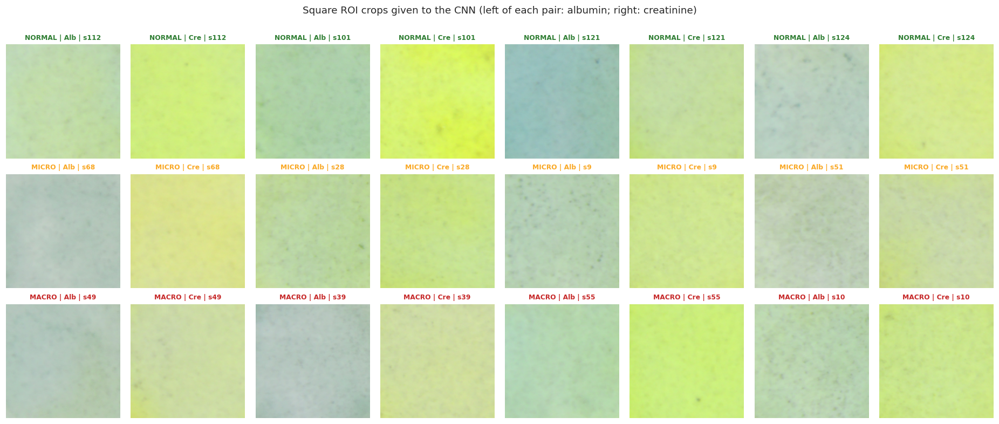

**Figure B1.** Examples of the network input: square crops inscribed in the circular ROI, albumin and creatinine assays, four random tests per class. Differences between classes are subtle and are not obvious to the eye.

**Table B1.** Mean RGB value of the ROI crops per class and assay. Small differences between classes show how little colour contrast the network can exploit.

R      G      B
Assay      Class                      
Albumin    MACRO   171.0  199.1  177.8
           MICRO   177.2  205.3  172.9
           NORMAL  180.5  208.9  177.0
Creatinine MACRO   208.9  228.6  139.9
           MICRO   205.3  229.8  136.2
           NORMAL  208.2  233.0  131.1

In [48]:
# ---------- Example gallery: two tests of each class, both assays ----------
rng = np.random.default_rng(SEED)
fig, axs = plt.subplots(3, 8, figsize=(17, 7.2))
for r_, c_ in enumerate(CLASSES):
    ids = rng.choice(np.where(y_all == r_)[0], size=4, replace=False)
    for j, i in enumerate(ids):
        for k, assay in enumerate(('Albumin', 'Creatinine')):
            ax = axs[r_, j * 2 + k]; ax.imshow(IMGS[i, k]); ax.axis('off')
            ax.set_title(f'{c_} | {assay[:3]} | s{g_all[i]}', fontsize=8, color=COLORS[c_])
fig.suptitle('Square ROI crops given to the CNN (left of each pair: albumin; right: creatinine)', y=1.0, fontsize=12)
fig.tight_layout()
save_fig(fig, 'roi_gallery', 'Examples of the network input: square crops inscribed in the circular ROI, albumin and creatinine assays, four random tests per class. Differences between classes are subtle and are not obvious to the eye.')

# mean colour per class (an intuition about how much colour information separates the classes)
mc = pd.DataFrame([{**{'Class': CLASSES[y_all[i]], 'Assay': a}, **dict(zip('RGB', IMGS[i, k].reshape(-1, 3).mean(0)))} for i in range(N) for k, a in enumerate(('Albumin', 'Creatinine'))])
mcs = mc.groupby(['Assay', 'Class'])[list('RGB')].mean().round(1)
save_table(mcs, 'mean_colour_by_class', 'Mean RGB value of the ROI crops per class and assay. Small differences between classes show how little colour contrast the network can exploit.')
stage_done('3 image tensors')

# Stage 19 · Network Definitions, Augmentation and the Training Function

**Purpose.** Define, once and for all, the pieces that Strategies A and B share, so that every backbone is treated identically.

**Components.**
1. **Backbone factory.** ImageNet-pretrained torchvision networks (ResNet-18, EfficientNet-B0, MobileNetV3-Large, ConvNeXt-Tiny) reduced to their convolutional part (feature map before global pooling), plus a **tiny CNN trained from scratch** (5 convolution blocks, ≈ 0.1 M parameters) as a lower bound: if a pretrained network cannot beat a model that knows nothing about natural images, pre-training is not helping.
2. **Two-branch network (`TwoBranch`).** The albumin crop and the creatinine crop pass through the *same* backbone (shared weights; no doubling of parameters), are globally average-pooled, concatenated (2 × *C* numbers) and sent to a small head (Dropout → Linear 256 → ReLU → Dropout → Linear 3). The head knows which half comes from which assay by position.
3. **Colour-preserving augmentation.** Random flips, random 90° rotations (the assay has no preferred orientation) and a ±3 % brightness change (illumination varies slightly between shots). Hue, saturation and contrast are **not** altered because the reagent colour is the signal.
4. **Training function (`train_cnn`)** — the pre-specified recipe: AdamW with two learning rates (small for the pretrained backbone, larger for the new head), cosine schedule with warm-up, class-weighted cross-entropy with label smoothing, frozen BatchNorm statistics (with ≈ 400 images per fold the BatchNorm running statistics of the pretrained network are more reliable than re-estimated ones), mixed precision on GPU. **The number of epochs is fixed.** The test fold is *only* used (i) once at the end for the reported prediction and (ii) per epoch as a **diagnostic log** that is never used for any decision.
5. **Test-time augmentation.** The reported probability is the mean over the image and its horizontal and vertical flips.

**Why the recipe is fixed instead of tuned.** Tuning the epoch number or learning rate per fold would require a validation split inside ≈ 80 training samples (≈ 20 per class in the smallest class), whose noise exceeds the differences being sought. A fixed, conservative recipe chosen *before* looking at results is the honest alternative; the cost is that the CNN may be slightly under-tuned, which is stated as a limitation.

In [49]:
# ---------- Metric helpers (identical definitions to Path A) ----------
def metric_dict(y_true, y_pred, proba=None):
    d = {'Accuracy': accuracy_score(y_true, y_pred), 'Balanced Acc': balanced_accuracy_score(y_true, y_pred),
         'Precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
         'Recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
         'F1 (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
         'F1 (weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0),
         'MCC': matthews_corrcoef(y_true, y_pred), 'QWK': cohen_kappa_score(y_true, y_pred, weights='quadratic')}
    try:    d['AUC (macro OvR)'] = roc_auc_score(y_true, proba, multi_class='ovr', average='macro')
    except Exception: d['AUC (macro OvR)'] = np.nan
    return d

def to_sample_level(groups, y_true, proba):
    d = pd.DataFrame(np.asarray(proba), columns=[0, 1, 2]); d['g'] = np.asarray(groups); d['y'] = np.asarray(y_true)
    a = d.groupby('g').agg({**{c: 'mean' for c in (0, 1, 2)}, 'y': 'first'})
    return a['y'].values, a[[0, 1, 2]].values, a.index.values

def recall_per_class(y_true, y_pred):
    cm_ = confusion_matrix(y_true, y_pred, labels=[0, 1, 2]); return cm_.diagonal() / cm_.sum(1).clip(min=1)

def holm(p):
    p = np.asarray(p); n = len(p); o = np.argsort(p); q = np.empty(n)
    q[o] = np.minimum(1, np.maximum.accumulate((n - np.arange(n)) * p[o])); return q

NEST_METRICS = ['Accuracy', 'Balanced Acc', 'F1 (macro)', 'MCC', 'QWK', 'AUC (macro OvR)']
REC_COLS = [f'Recall {c}' for c in CLASSES]

def fold_tables_cnn(RES, family):
    """RES: {model name: [dict(rep, fold, tei, proba), ...]} -> fold-wise metric tables (test level and sample level)."""
    rt, rs = [], []
    for name, lst in RES.items():
        for r in lst:
            yt = y_all[r['tei']]; pr = r['proba']; yp = pr.argmax(1)
            base = {'rep': r['rep'], 'fold': r['fold'], 'Model': name, 'Family': family}
            rec = recall_per_class(yt, yp)
            rt.append({**base, **metric_dict(yt, yp, pr), **{f'Recall {c}': rec[i] for i, c in enumerate(CLASSES)}})
            ys_, ps_, _ = to_sample_level(g_all[r['tei']], yt, pr); recs = recall_per_class(ys_, ps_.argmax(1))
            rs.append({**base, **metric_dict(ys_, ps_.argmax(1), ps_), **{f'Recall {c}': recs[i] for i, c in enumerate(CLASSES)}})
    return pd.DataFrame(rt), pd.DataFrame(rs)

def mean_sd_table(T, order):
    agg = T.groupby('Model')[NEST_METRICS + REC_COLS].agg(['mean', 'std']).reindex(order)
    out = pd.DataFrame({m_: [f'{agg.loc[n, (m_, "mean")]:.3f} ± {agg.loc[n, (m_, "std")]:.3f}' for n in order] for m_ in NEST_METRICS + REC_COLS}, index=order)
    out.index.name = 'Model'
    return agg, out

def oof_of(RES, name, rep):
    P = np.zeros((N, 3)); seen = np.zeros(N, int)
    for r in RES[name]:
        if r['rep'] == rep: P[r['tei']] = r['proba']; seen[r['tei']] += 1
    assert (seen == 1).all(), 'every test must be predicted exactly once per repeat'
    return P
print('Metric helpers ready.')

Metric helpers ready.


In [50]:
# ---------- Backbone factory ----------
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 1, 3, 1, 1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 1, 3, 1, 1)
PRETRAINED_OK = {}          # backbone -> whether the ImageNet weights could really be loaded

def _scratch_backbone():
    def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(blk(3, 16), blk(16, 32), blk(32, 64), blk(64, 64), blk(64, 128)), 128

def build_backbone(name, pretrained=None):
    """Return (feature extractor: image -> feature map, number of channels)."""
    pretrained = CFG['PRETRAINED'] if pretrained is None else pretrained
    tv = torchvision.models
    if name == 'scratch':
        PRETRAINED_OK[name] = False; return _scratch_backbone()
    spec = {'resnet18': (tv.resnet18, 'ResNet18_Weights'), 'efficientnet_b0': (tv.efficientnet_b0, 'EfficientNet_B0_Weights'),
            'mobilenet_v3_large': (tv.mobilenet_v3_large, 'MobileNet_V3_Large_Weights'), 'convnext_tiny': (tv.convnext_tiny, 'ConvNeXt_Tiny_Weights')}[name]
    fn, wname = spec
    m, ok = None, False
    if pretrained:
        try:
            m = fn(weights=getattr(tv, wname).DEFAULT)
            ok = True
        except Exception as e:
            print(f'WARNING: ImageNet weights of {name} could not be loaded ({repr(e)[:90]}) -> RANDOM initialisation. Results are NOT transfer learning!')
    if m is None: m = fn(weights=None)
    PRETRAINED_OK[name] = ok
    if name == 'resnet18':
        return nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3, m.layer4), 512
    if name == 'efficientnet_b0':  return m.features, 1280
    if name == 'mobilenet_v3_large': return m.features, 960
    if name == 'convnext_tiny':    return m.features, 768

class TwoBranch(nn.Module):
    """Shared backbone applied to the albumin and the creatinine crop; pooled features are concatenated and classified."""
    def __init__(self, name, dropout=0.3):
        super().__init__()
        self.name = name
        self.feat, nf = build_backbone(name)
        self.nf = nf
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * nf, 256), nn.ReLU(), nn.Dropout(dropout), nn.Linear(256, 3))
    def forward(self, x, return_maps=False):                      # x: (B, 2, 3, H, W)
        B = x.shape[0]
        maps = self.feat(x.flatten(0, 1))                          # (2B, C, h, w)
        if return_maps: maps.retain_grad()
        z = maps.mean((2, 3)).view(B, 2 * self.nf)                 # [albumin | creatinine]
        out = self.head(z)
        return (out, maps) if return_maps else out

# the images as a uint8 tensor on the device (N, 2, 3, S, S)
IMG_T = torch.from_numpy(IMGS).permute(0, 1, 4, 2, 3).contiguous().to(DEVICE)
print('Image tensor on', DEVICE, ':', tuple(IMG_T.shape), IMG_T.dtype)

def _count(m): return sum(p.numel() for p in m.parameters())
rows = []
for nm in CFG['BACKBONES'] + (['scratch'] if CFG['INCLUDE_SCRATCH'] else []):
    mdl = TwoBranch(nm); rows.append({'Backbone': nm, 'Pretrained weights loaded': PRETRAINED_OK[nm] if nm != 'scratch' else 'n/a (from scratch)',
                                      'Backbone parameters (M)': round(_count(mdl.feat) / 1e6, 2), 'Head parameters (M)': round(_count(mdl.head) / 1e6, 3),
                                      'Feature dim per assay': mdl.nf})
    del mdl
arch_tab = pd.DataFrame(rows).set_index('Backbone')
save_table(arch_tab, 'architectures', 'CNN backbones used (shared between the albumin and the creatinine branch). Trainable parameters are many times larger than the number of independent samples (100), which is why the recipe is strongly regularised and the evaluation strictly grouped by sample.')
put('architectures', arch_tab.reset_index().to_dict(orient='records'))
if CFG['PRETRAINED'] and not all(v for k, v in PRETRAINED_OK.items() if k != 'scratch'):
    print('\n*** WARNING: at least one backbone runs with random weights; check the internet connection and re-run this cell. ***')

Image tensor on cuda : (478, 2, 3, 224, 224) torch.uint8
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 171MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 176MB/s]


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 159MB/s] 


**Table B2.** CNN backbones used (shared between the albumin and the creatinine branch). Trainable parameters are many times larger than the number of independent samples (100), which is why the recipe is strongly regularised and the evaluation strictly grouped by sample.

,Pretrained weights loaded,Backbone parameters (M),Head parameters (M),Feature dim per assay
Backbone,,,,
resnet18,True,11.18,0.263,512
efficientnet_b0,True,4.01,0.656,1280
mobilenet_v3_large,True,2.97,0.493,960
convnext_tiny,True,27.82,0.394,768
scratch,n/a (from scratch),0.13,0.067,128


In [51]:
# ---------- Augmentation, mini-batch preparation, prediction, training ----------
def prep(xb, train):
    """uint8 (B,2,3,H,W) on the device -> normalised float; colour-preserving augmentation if train."""
    x = xb.float() / 255.0
    if train:
        B = x.shape[0]
        flat = x.view(B * 2, 3, x.shape[-2], x.shape[-1])
        out = []
        r = torch.randint(0, 2, (B * 2, 2)).tolist(); k = torch.randint(0, 4, (B * 2,)).tolist()
        for i in range(B * 2):
            im = flat[i]
            if r[i][0]: im = im.flip(-1)
            if r[i][1]: im = im.flip(-2)
            if k[i]: im = torch.rot90(im, k[i], (-2, -1))
            out.append(im)
        x = torch.stack(out).view(B, 2, 3, x.shape[-2], x.shape[-1])
        gain = 1.0 + (torch.rand(B, 2, 1, 1, 1, device=x.device) * 2 - 1) * CFG['AUG_BRIGHT']
        x = (x * gain).clamp(0, 1)
    return (x - IMNET_MEAN) / IMNET_STD

@torch.no_grad()
def predict_proba(model, idx, tta=True, bs=64):
    model.eval(); out = []
    for s in range(0, len(idx), bs):
        x = prep(IMG_T[torch.as_tensor(idx[s:s + bs], device=DEVICE)], False)
        views = [x, x.flip(-1), x.flip(-2)] if tta else [x]
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = torch.stack([Fn.softmax(model(v).float(), 1) for v in views]).mean(0)
        out.append(p.cpu().numpy())
    return np.concatenate(out)

def _bn_eval(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm): m.eval()

def train_cnn(name, tri, tei=None, seed=0, epochs=None, return_model=False):
    """Train the two-branch network on the tests `tri`. If `tei` is given, the diagnostic log (test loss / macro-F1 per epoch) is recorded —
    it is NEVER used to choose anything. Returns the TTA probabilities for `tei`."""
    epochs = CFG['EPOCHS'] if epochs is None else epochs
    set_seed(seed)
    model = TwoBranch(name, CFG['DROPOUT']).to(DEVICE)
    scratch = name == 'scratch'
    freeze_bn = CFG['FREEZE_BN'] and not scratch
    opt = torch.optim.AdamW([{'params': model.feat.parameters(), 'lr': CFG['LR_HEAD'] if scratch else CFG['LR_BACKBONE']},
                             {'params': model.head.parameters(), 'lr': CFG['LR_HEAD']}], weight_decay=CFG['WEIGHT_DECAY'])
    base_lrs = [g['lr'] for g in opt.param_groups]
    cnt = np.bincount(y_all[tri], minlength=3).astype(float)
    cw = torch.tensor(len(tri) / (3.0 * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=CFG['LABEL_SMOOTH'])
    try:    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    B = CFG['BATCH']; steps_per_epoch = max(1, len(tri) // B); total = steps_per_epoch * epochs; warm = steps_per_epoch * CFG['WARMUP_EPOCHS']
    yt_all = torch.as_tensor(y_all, device=DEVICE)
    g = torch.Generator().manual_seed(seed); step = 0; hist = []
    for ep in range(epochs):
        model.train()
        if freeze_bn: _bn_eval(model)
        perm = torch.as_tensor(np.asarray(tri))[torch.randperm(len(tri), generator=g)]
        tl, nb = 0.0, 0
        for s in range(0, steps_per_epoch * B, B):
            bi = perm[s:s + B].to(DEVICE)
            if len(bi) < 2: continue
            f = (step + 1) / warm if step < warm else 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
            for gi, gr in enumerate(opt.param_groups): gr['lr'] = base_lrs[gi] * f
            x = prep(IMG_T[bi], True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                loss = crit(model(x).float(), yt_all[bi])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += float(loss); nb += 1; step += 1
        rec = {'epoch': ep + 1, 'train_loss': tl / max(nb, 1)}
        if tei is not None:                                         # diagnostic only
            pr = predict_proba(model, tei, tta=False)
            rec['test_loss_diag'] = float(Fn.nll_loss(torch.log(torch.as_tensor(pr).clamp_min(1e-7)), torch.as_tensor(y_all[tei])))
            rec['test_f1_diag'] = f1_score(y_all[tei], pr.argmax(1), average='macro', zero_division=0)
        hist.append(rec)
    res = {'hist': hist}
    if tei is not None: res['proba'] = predict_proba(model, tei, tta=True)
    if return_model: res['model'] = model
    else: del model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return res

# quick functional test on one tiny fold (a few iterations) — only checks that the machinery works
_rep, _fold, _tri, _tei = OUTER_USE[0]
t0 = time.time()
_t = train_cnn(CFG['BACKBONES'][0], _tri[:64], _tei[:16], seed=0, epochs=1)
print(f'Functional test ({CFG["BACKBONES"][0]}, 64 train / 16 test images, 1 epoch): {time.time() - t0:.1f} s | proba shape {_t["proba"].shape} | rows sum to 1: {np.allclose(_t["proba"].sum(1), 1, atol=1e-4)}')
stage_done('4 definitions')

Functional test (resnet18, 64 train / 16 test images, 1 epoch): 4.2 s | proba shape (16, 3) | rows sum to 1: True


# Stage 20 · Strategy A — Frozen CNN Embeddings + a Simple Classifier

**Purpose.** Test the conservative hypothesis: *do generic ImageNet features of the micropad images contain information about the albuminuria class?* Nothing in the CNN is trained on the micropad data; only a regularised logistic regression sees labels.

**How it works.**
1. Each backbone (pretrained, evaluation mode) turns every ROI crop into a vector of *C* numbers (global average of the last feature map): 512 (ResNet-18), 1280 (EfficientNet-B0), 960 (MobileNetV3), 768 (ConvNeXt-Tiny). Albumin and creatinine vectors are concatenated.
2. Because the backbone never sees labels, extracting embeddings for all images is **not** a source of leakage.
3. On the **identical outer folds**, a pipeline *standardise → PCA → logistic regression (balanced class weights)* is fitted on the training samples only. The PCA dimension and the regularisation *C* are tuned in an **inner grouped 3-fold CV** inside each outer training set (grid: PCA ∈ {8, 16, 32}, *C* ∈ {0.01, 0.1, 1}), scored by macro-F1.
4. **Branch ablation:** the same procedure with the albumin embedding only, the creatinine embedding only, and both. This reveals whether the creatinine image adds information beyond albumin (as the UACR concept predicts).

**Reading rule (stated in advance).** If frozen embeddings reach a macro-F1 comparable to the hand-crafted SVM, generic visual features carry the same limited information; if they are clearly worse, the hand-crafted colourimetric features are better tuned to the assay than generic features.

In [52]:
# ---------- 5.1 Embedding extraction (frozen backbones) ----------
@torch.no_grad()
def extract_embeddings(name, bs=64):
    feat, nf = build_backbone(name); feat = feat.to(DEVICE).eval()
    out = []
    for s in range(0, N, bs):
        x = prep(IMG_T[s:s + bs], False); B = x.shape[0]
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            m = feat(x.flatten(0, 1))
        out.append(m.float().mean((2, 3)).view(B, 2, nf).cpu().numpy())
    del feat
    return np.concatenate(out)                                    # (N, 2, C)

EMB = {}
for nm in CFG['BACKBONES']:
    f = CACHE_DIR / f'emb_{nm}_{key}_{int(CFG["PRETRAINED"])}.npy'
    if f.exists(): EMB[nm] = np.load(f); PRETRAINED_OK.setdefault(nm, CFG['PRETRAINED'])
    else:
        t0 = time.time(); EMB[nm] = extract_embeddings(nm); np.save(f, EMB[nm])
        print(f'{nm:20s} embeddings {EMB[nm].shape} in {time.time() - t0:.0f} s | pretrained loaded: {PRETRAINED_OK[nm]}')
sync_to_drive(verbose=False)
put('strategy_A.embedding_dims', {k: int(v.shape[-1]) for k, v in EMB.items()})

In [53]:
# ---------- 5.2 Nested CV on the identical outer folds ----------
VARIANTS = {'both': [0, 1], 'albumin only': [0], 'creatinine only': [1]}
def emb_matrix(name, br): return EMB[name][:, VARIANTS[br], :].reshape(N, -1)

def emb_task(name, br, rep, fold, tri, tei):
    X = emb_matrix(name, br)
    pipe = Pipeline([('sc', StandardScaler()), ('pca', PCA(random_state=SEED)), ('clf', LogisticRegression(class_weight='balanced', max_iter=3000))])
    grid = {'pca__n_components': CFG['EMB_PCA'], 'clf__C': CFG['EMB_C']}
    inner = list(StratifiedGroupKFold(n_splits=CFG['INNER_FOLDS'], shuffle=True, random_state=SEED + rep).split(X[tri], y_all[tri], g_all[tri]))
    gs = GridSearchCV(pipe, grid, scoring='f1_macro', cv=inner, n_jobs=1, refit=True).fit(X[tri], y_all[tri])
    return dict(model=f'{name} (frozen, {br})', rep=rep, fold=fold, tei=tei, proba=gs.predict_proba(X[tei]), inner=float(gs.best_score_),
                params={k.split('__')[1]: v for k, v in gs.best_params_.items()})

sigA = hashlib.md5(json.dumps([key, CFG['EMB_PCA'], CFG['EMB_C'], CFG['BACKBONES'], CFG['PRETRAINED'], [(r, f) for r, f, _, _ in OUTER_USE], SEED], default=str).encode()).hexdigest()[:10]
fA = CACHE_DIR / f'strategyA_{sigA}.pkl'
if fA.exists():
    NRES_A = pd.read_pickle(fA); print('Loaded cached Strategy A results:', fA.name)
else:
    tasks = [(nm, br, rep, fold, tri, tei) for nm in CFG['BACKBONES'] for br in VARIANTS for (rep, fold, tri, tei) in OUTER_USE]
    print(f'{len(tasks)} tasks (backbones x branch variants x outer folds)')
    t0 = time.time()
    NRES_A = Parallel(n_jobs=-1)(delayed(emb_task)(*t) for t in tqdm(tasks, desc='Strategy A nested CV'))
    pd.to_pickle(NRES_A, fA); print(f'finished in {(time.time() - t0) / 60:.1f} min')

RES_A = {}
for r in NRES_A: RES_A.setdefault(r['model'], []).append(r)
TFa, TSa = fold_tables_cnn(RES_A, 'CNN frozen + LR')
A_BOTH = [f'{nm} (frozen, both)' for nm in CFG['BACKBONES']]
orderA = A_BOTH + BASE_NAMES
TFa_cmp = pd.concat([TFa[TFa.Model.isin(A_BOTH)], CLS_T[CLS_T.Model.isin(BASE_NAMES + [REF_MODEL])]], ignore_index=True)
aggA, tabA = mean_sd_table(TFa_cmp, A_BOTH + [REF_MODEL] + BASE_NAMES)
save_table(tabA, 'strategyA_nested_test_level', f'Strategy A (frozen ImageNet embeddings of both assays + logistic regression), nested CV, TEST level: mean ± SD over {len(OUTER_USE)} outer folds, with the best classical model ({REF_MODEL}) and the baselines for reference.')
put('strategy_A.mean_macro_f1_test', {m_: float(TFa[TFa.Model == m_]['F1 (macro)'].mean()) for m_ in TFa.Model.unique()})
display(Markdown('Tuned configuration chosen in the inner CV (counts over the outer folds):'))
cfg_tab = pd.DataFrame([{'Model': r['model'], **r['params']} for r in NRES_A if r['model'] in A_BOTH]).groupby('Model').agg(lambda s: dict(s.value_counts().sort_index()))
display(cfg_tab)

120 tasks (backbones x branch variants x outer folds)


Strategy A nested CV:   0%|          | 0/120 [00:00<?, ?it/s]

finished in 2.7 min


**Table B3.** Strategy A (frozen ImageNet embeddings of both assays + logistic regression), nested CV, TEST level: mean ± SD over 10 outer folds, with the best classical model (SVM (RBF)) and the baselines for reference.

,Accuracy,Balanced Acc,F1 (macro),MCC,QWK,AUC (macro OvR),Recall NORMAL,Recall MICRO,Recall MACRO
Model,,,,,,,,,
"resnet18 (frozen, both)",0.483 ± 0.070,0.448 ± 0.065,0.439 ± 0.059,0.193 ± 0.091,0.338 ± 0.118,0.626 ± 0.068,0.535 ± 0.130,0.270 ± 0.120,0.539 ± 0.104
"efficientnet_b0 (frozen, both)",0.488 ± 0.085,0.446 ± 0.079,0.435 ± 0.073,0.201 ± 0.108,0.370 ± 0.114,0.629 ± 0.065,0.518 ± 0.114,0.246 ± 0.153,0.574 ± 0.142
"mobilenet_v3_large (frozen, both)",0.530 ± 0.052,0.504 ± 0.042,0.488 ± 0.052,0.278 ± 0.066,0.431 ± 0.092,0.703 ± 0.055,0.563 ± 0.114,0.337 ± 0.128,0.612 ± 0.111
"convnext_tiny (frozen, both)",0.515 ± 0.088,0.465 ± 0.101,0.459 ± 0.090,0.235 ± 0.141,0.393 ± 0.156,0.650 ± 0.077,0.505 ± 0.168,0.262 ± 0.136,0.628 ± 0.112
SVM (RBF),0.591 ± 0.070,0.523 ± 0.098,0.510 ± 0.090,0.335 ± 0.133,0.458 ± 0.137,0.718 ± 0.068,0.563 ± 0.202,0.229 ± 0.101,0.778 ± 0.080
Baseline: majority class,0.501 ± 0.081,0.333 ± 0.000,0.221 ± 0.023,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000
Baseline: stratified random guess,0.380 ± 0.045,0.341 ± 0.045,0.332 ± 0.043,0.002 ± 0.065,-0.048 ± 0.066,0.503 ± 0.032,0.213 ± 0.066,0.289 ± 0.089,0.522 ± 0.065


Tuned configuration chosen in the inner CV (counts over the outer folds):

,C,n_components
Model,,
"convnext_tiny (frozen, both)","{0.01: 7, 0.1: 2, 1.0: 1}","{8: 5, 16: 2, 32: 3}"
"efficientnet_b0 (frozen, both)","{0.01: 6, 0.1: 3, 1.0: 1}","{8: 2, 16: 4, 32: 4}"
"mobilenet_v3_large (frozen, both)","{0.01: 4, 0.1: 1, 1.0: 5}","{16: 3, 32: 7}"
"resnet18 (frozen, both)","{0.01: 5, 0.1: 4, 1.0: 1}","{8: 3, 16: 4, 32: 3}"


**Table B4.** Strategy A: mean macro-F1 (test level, outer folds) using the albumin embedding only, the creatinine embedding only, or both. The bottom row is the best hand-crafted model (both assays).

Input,both,albumin only,creatinine only
Backbone,,,
resnet18,0.439,0.473,0.417
efficientnet_b0,0.435,0.458,0.415
mobilenet_v3_large,0.488,0.480,0.449
convnext_tiny,0.459,0.425,0.411
"SVM (RBF) (hand-crafted, both)",0.510,NaN,NaN


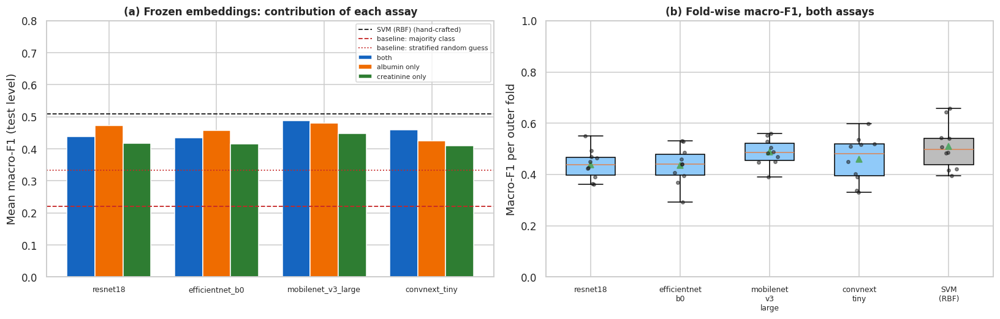

**Figure B2.** Strategy A (frozen embeddings): (a) mean macro-F1 using the albumin crop only, the creatinine crop only, or both, compared with the hand-crafted reference (dashed black) and the baselines (red); (b) fold-wise macro-F1 with both assays.

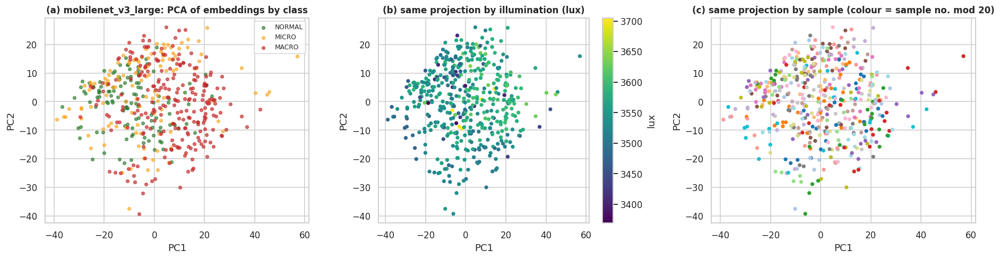

**Figure B3.** Unsupervised PCA of the frozen mobilenet_v3_large embeddings coloured by (a) class, (b) illumination and (c) sample. Spearman correlation of PC1/PC2 with lux: 0.30 / 0.19. Tight clusters in (c) show that repeats of one sample resemble each other more than they resemble their class — the reason for grouped validation.

In [54]:
# ---------- 5.3 Branch ablation and figure ----------
ab = TFa.groupby('Model')['F1 (macro)'].agg(['mean', 'std']).reset_index()
ab['Backbone'] = ab['Model'].str.replace(r' \(frozen, .*\)', '', regex=True); ab['Input'] = ab['Model'].str.extract(r'\(frozen, (.*)\)')
abp = ab.pivot(index='Backbone', columns='Input', values='mean').reindex(CFG['BACKBONES'])[list(VARIANTS)]
abp.loc[REF_MODEL + ' (hand-crafted, both)'] = [cls_mean[REF_MODEL], np.nan, np.nan]
save_table(abp.round(3), 'strategyA_branch_ablation', 'Strategy A: mean macro-F1 (test level, outer folds) using the albumin embedding only, the creatinine embedding only, or both. The bottom row is the best hand-crafted model (both assays).')
put('strategy_A.branch_ablation', abp.round(4).to_dict(orient='index'))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.9))
xx = np.arange(len(CFG['BACKBONES'])); w = 0.26
for j, (br, col) in enumerate(zip(VARIANTS, ('#1565C0', '#EF6C00', '#2E7D32'))):
    axs[0].bar(xx + (j - 1) * w, abp.loc[CFG['BACKBONES'], br], w, label=br, color=col)
axs[0].axhline(cls_mean[REF_MODEL], c='k', ls='--', lw=1.2, label=f'{REF_MODEL} (hand-crafted)')
for b_, ls_ in zip(BASE_NAMES, ('--', ':')): axs[0].axhline(cls_mean[b_], c='#C62828', ls=ls_, lw=1.2, label=b_.replace('Baseline: ', 'baseline: '))
axs[0].set_xticks(xx); axs[0].set_xticklabels(CFG['BACKBONES'], fontsize=8); axs[0].set_ylabel('Mean macro-F1 (test level)'); axs[0].set_ylim(0, 0.8)
axs[0].set_title('(a) Frozen embeddings: contribution of each assay'); axs[0].legend(fontsize=7, loc='upper right')
bx = [TFa[TFa.Model == m_]['F1 (macro)'].values for m_ in A_BOTH] + [CLS_T[CLS_T.Model == REF_MODEL]['F1 (macro)'].values]
bp = axs[1].boxplot(bx, showmeans=True, patch_artist=True, widths=.55)
for patch, c_ in zip(bp['boxes'], ['#90CAF9'] * len(A_BOTH) + ['#BDBDBD']): patch.set_facecolor(c_)
for i, v in enumerate(bx): axs[1].scatter(np.random.default_rng(i).normal(i + 1, .05, len(v)), v, c='k', s=12, alpha=.5, zorder=3)
axs[1].set_xticklabels([b.replace('_', '\n') for b in CFG['BACKBONES']] + [REF_MODEL.replace(' ', '\n', 1)], fontsize=8); axs[1].set_ylim(0, 1)
axs[1].set_ylabel('Macro-F1 per outer fold'); axs[1].set_title('(b) Fold-wise macro-F1, both assays')
fig.tight_layout()
save_fig(fig, 'strategyA', 'Strategy A (frozen embeddings): (a) mean macro-F1 using the albumin crop only, the creatinine crop only, or both, compared with the hand-crafted reference (dashed black) and the baselines (red); (b) fold-wise macro-F1 with both assays.')

# 2-D view of the embeddings of the best backbone (unsupervised PCA: no labels used)
best_emb = abp.loc[CFG['BACKBONES'], 'both'].idxmax()
Z = PCA(2, random_state=SEED).fit_transform(StandardScaler().fit_transform(emb_matrix(best_emb, 'both')))
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
for c in range(3): axs[0].scatter(*Z[y_all == c].T, s=14, c=COLORS[CLASSES[c]], alpha=.65, label=CLASSES[c])
axs[0].set_title(f'(a) {best_emb}: PCA of embeddings by class'); axs[0].legend(fontsize=8); axs[0].set_xlabel('PC1'); axs[0].set_ylabel('PC2')
sc = axs[1].scatter(*Z.T, s=14, c=df_img['lux'], cmap='viridis'); plt.colorbar(sc, ax=axs[1], label='lux'); axs[1].set_title('(b) same projection by illumination (lux)'); axs[1].set_xlabel('PC1'); axs[1].set_ylabel('PC2')
smp_ids = pd.factorize(g_all)[0]; axs[2].scatter(*Z.T, s=14, c=smp_ids % 20, cmap='tab20'); axs[2].set_title('(c) same projection by sample (colour = sample no. mod 20)'); axs[2].set_xlabel('PC1'); axs[2].set_ylabel('PC2')
fig.tight_layout()
rho_lux = [sps.spearmanr(Z[:, k], df_img['lux'])[0] for k in range(2)]
save_fig(fig, 'embedding_pca', f'Unsupervised PCA of the frozen {best_emb} embeddings coloured by (a) class, (b) illumination and (c) sample. Spearman correlation of PC1/PC2 with lux: {rho_lux[0]:.2f} / {rho_lux[1]:.2f}. Tight clusters in (c) show that repeats of one sample resemble each other more than they resemble their class — the reason for grouped validation.')
put('strategy_A.pca_lux_spearman', dict(backbone=best_emb, pc1=float(rho_lux[0]), pc2=float(rho_lux[1])))
stage_done('5 strategy A')

# Stage 21 · Measurement Audit with CNN Embeddings

**Purpose.** In Path A the hand-crafted features could explain only a small part of the laboratory values: **R² ≈ 0.30 for log albumin, 0.16 for log creatinine, 0.20 for log UACR** (Random Forest, sample-grouped CV). The conclusion was that the *image measurement* — not the classifier — limits performance. A critic could answer: *"hand-crafted features are just a poor summary of the image; a CNN would extract more."* This stage tests that objection directly.

**Method.** The same sample-grouped 5-fold CV as in the Path A audit (3 repeats, seeds `SEED+300+r`), but the regressors use the **frozen CNN embeddings** (standardise → PCA 32 → Ridge, with the Ridge penalty tuned in an inner grouped CV):
* log₁₀ albumin ← embedding of the **albumin** crop;
* log₁₀ creatinine ← embedding of the **creatinine** crop;
* log₁₀ UACR ← both;
* **lux** (illumination) ← both — a *shortcut diagnostic*: if the embeddings encode illumination well, a CNN could use illumination as a cue; lux is unrelated to the analyte, so this is information to be ignored, not exploited.

**Reading rule (stated in advance).** If CNN embeddings reach an R² clearly above the hand-crafted features for albumin, the Path A conclusion ("information-limited") must be softened; if they reach a similar or lower R², it is confirmed from a second, independent representation.

Audit regressions:   0%|          | 0/240 [00:00<?, ?it/s]

**Table B5.** Measurement audit with frozen CNN embeddings: sample-grouped cross-validated R² for predicting the laboratory analytes (and illumination) — 3 × 5-fold. The last row repeats the hand-crafted result of Path A for comparison (lux was not part of the Path A audit).

Target,log albumin,log creatinine,log UACR,lux
Backbone,,,,
resnet18,0.172,0.079,0.100,0.023
efficientnet_b0,0.267,0.084,0.169,0.060
mobilenet_v3_large,0.332,0.053,0.148,0.048
convnext_tiny,0.273,0.042,0.131,0.073
hand-crafted features + Random Forest (Path A),0.300,0.158,0.198,NaN


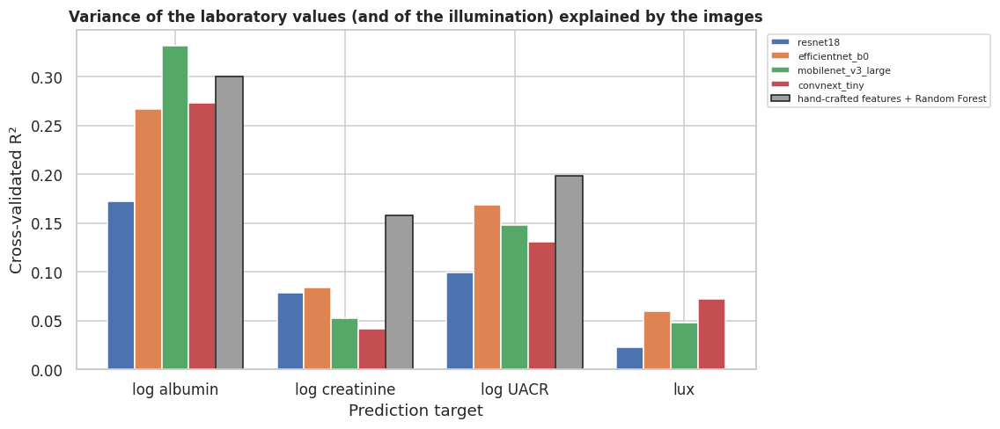

**Figure B4.** Measurement audit with CNN embeddings: cross-validated R² for log albumin (albumin crop), log creatinine (creatinine crop), log UACR (both) and lux (both). Grey bars = hand-crafted features (Path A). CNN features do not break the information limit if their bars are not clearly higher than the grey ones.

Best CNN-embedding R² for log albumin: 0.332 | hand-crafted (RF): 0.300
R² of illumination (lux) from CNN embeddings: {'resnet18': 0.02, 'efficientnet_b0': 0.06, 'mobilenet_v3_large': 0.05, 'convnext_tiny': 0.07}


In [55]:
# ---------- 6.1 Grouped CV regression from embeddings ----------
DIAG_REPS = 2 if CFG['FAST_MODE'] else 3
valid_t = {'log albumin': df_img['log_alb'].values, 'log creatinine': df_img['log_cre'].values, 'log UACR': df_img['log_uacr'].values, 'lux': df_img['lux'].values.astype(float)}
src_t = {'log albumin': 'albumin only', 'log creatinine': 'creatinine only', 'log UACR': 'both', 'lux': 'both'}
DIAG_SPLITS = [list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 300 + r).split(np.zeros((N, 1)), y_all, g_all)) for r in range(DIAG_REPS)]

def reg_task(name, tgt, rep, fi):
    X = emb_matrix(name, src_t[tgt]); yv = valid_t[tgt]
    tri, tei = DIAG_SPLITS[rep][fi]
    ok = np.isfinite(yv[tri]); tri = tri[ok]
    pipe = Pipeline([('sc', StandardScaler()), ('pca', PCA(n_components=min(32, max(2, X.shape[1] - 1)) if not CFG['FAST_MODE'] else 8, random_state=SEED)), ('ridge', Ridge())])
    gs = GridSearchCV(pipe, {'ridge__alpha': [1, 10, 100, 1000]}, cv=GroupKFold(n_splits=3), scoring='r2', n_jobs=1).fit(X[tri], yv[tri], groups=g_all[tri])
    return gs.predict(X[tei])

jobs = [(nm, tgt, rep, fi) for nm in CFG['BACKBONES'] for tgt in valid_t for rep in range(DIAG_REPS) for fi in range(5)]
outs = Parallel(n_jobs=-1)(delayed(reg_task)(*j) for j in tqdm(jobs, desc='Audit regressions'))
PRD = {}
for j, o in zip(jobs, outs):
    nm, tgt, rep, fi = j
    PRD.setdefault((nm, tgt), np.full((DIAG_REPS, N), np.nan))[rep, DIAG_SPLITS[rep][fi][1]] = o
rows = []
for (nm, tgt), arr in PRD.items():
    yv = valid_t[tgt]; ok = np.isfinite(yv)
    rows.append({'Backbone': nm, 'Target': tgt, 'Input': src_t[tgt], 'R²': np.mean([r2_score(yv[ok], a[ok]) for a in arr]),
                 'Spearman ρ': np.mean([sps.spearmanr(yv[ok], a[ok])[0] for a in arr])})
aud = pd.DataFrame(rows)
final_rf = {}
try:
    for rr in FINAL_NUM['audit']['regression']:
        if rr['Model'] == 'Random Forest': final_rf[rr['Target']] = rr['R²']
except Exception: pass
pv = aud.pivot(index='Backbone', columns='Target', values='R²').reindex(CFG['BACKBONES'])[list(valid_t)]
pv.loc['hand-crafted features + Random Forest (Path A)'] = [final_rf.get(t, np.nan) for t in valid_t]
save_table(pv.round(3), 'audit_cnn_embeddings', f'Measurement audit with frozen CNN embeddings: sample-grouped cross-validated R² for predicting the laboratory analytes (and illumination) — {DIAG_REPS} × 5-fold. The last row repeats the hand-crafted result of Path A for comparison (lux was not part of the Path A audit).')
put('audit_cnn.r2', pv.round(4).to_dict(orient='index'))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
tg = list(valid_t); w = 0.8 / (len(pv))
for j, (idx, row) in enumerate(pv.iterrows()):
    ax.bar(np.arange(len(tg)) + (j - (len(pv) - 1) / 2) * w, [row[t] for t in tg], w, label=idx.replace(' (Path A)', ''), color=('#9E9E9E' if 'hand-crafted' in idx else None), edgecolor='k' if 'hand-crafted' in idx else None)
ax.axhline(0, c='k', lw=.8); ax.set_xticks(np.arange(len(tg))); ax.set_xticklabels(tg); ax.set_ylabel('Cross-validated R²'); ax.set_xlabel('Prediction target')
ax.set_title('Variance of the laboratory values (and of the illumination) explained by the images'); ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()
save_fig(fig, 'audit_cnn_embeddings', 'Measurement audit with CNN embeddings: cross-validated R² for log albumin (albumin crop), log creatinine (creatinine crop), log UACR (both) and lux (both). Grey bars = hand-crafted features (Path A). CNN features do not break the information limit if their bars are not clearly higher than the grey ones.')
best_cnn_alb = pv.loc[CFG['BACKBONES'], 'log albumin'].max()
print(f'Best CNN-embedding R² for log albumin: {best_cnn_alb:.3f} | hand-crafted (RF): {final_rf.get("log albumin", float("nan")):.3f}')
print(f'R² of illumination (lux) from CNN embeddings: {pv.loc[CFG["BACKBONES"], "lux"].round(2).to_dict()}')
stage_done('6 audit')

# Stage 22 · Strategy B — Fine-Tuning the Two-Branch CNN (Nested Evaluation on the Identical Folds)

**Purpose.** Test the flexible hypothesis: *when the network is allowed to adapt all its weights to the micropad images, does it beat the hand-crafted features?*

**Protocol.**
* For each of the identical outer folds (5 × `OUTER_REPEATS_CNN`) and for each backbone, a network is initialised from ImageNet weights and trained on the training samples of that fold with the **fixed recipe** of the table in the introduction. The held-out fold is predicted **once**, at the end, with test-time augmentation.
* There is **no inner loop and no early stopping**: nothing is tuned on any held-out data. The only thing the held-out fold ever influences is the reported score.
* The per-epoch test loss and macro-F1 are recorded as a **diagnostic** (Stage 24) to show over-fitting behaviour; they never feed back into training.
* Seeds are derived from the repeat and the fold (`SEED + 1000·repeat + fold`), identical for all backbones.

**Resumable.** Each (backbone, repeat, fold) task is saved as soon as it finishes (`cache/cnn_tasks/*.npz`) and copied to Drive every few tasks. If Colab disconnects, simply re-run the notebook from the top: finished tasks are loaded, unfinished ones continue.

**Cost.** ≈ 15 epochs × ≈ 380 training pairs (760 images) per task, five networks per outer fold, ten outer folds. On a Colab T4 this is typically in the range of **30–90 minutes** in total (ResNet-18 is the fastest, ConvNeXt-Tiny the slowest); the notebook prints a running estimate after every finished outer fold. Reduce `CFG['OUTER_REPEATS_CNN']` to 1 to halve the time (the first repeat is then compared with the first repeat of the classical models).

In [56]:
# ---------- 7.1 Run (or resume) the fine-tuning tasks ----------
B_NAMES = CFG['BACKBONES'] + (['scratch'] if CFG['INCLUDE_SCRATCH'] else [])
def b_label(nm): return 'Small CNN (from scratch)' if nm == 'scratch' else f'{nm} (fine-tuned)'
recipe = {k: CFG[k] for k in ('IMG_SIZE', 'EPOCHS', 'BATCH', 'LR_BACKBONE', 'LR_HEAD', 'WEIGHT_DECAY', 'WARMUP_EPOCHS', 'LABEL_SMOOTH', 'DROPOUT', 'AUG_BRIGHT', 'FREEZE_BN', 'PRETRAINED')}
SIG_B = hashlib.md5(json.dumps([recipe, key, SEED], default=str).encode()).hexdigest()[:8]

def task_file(nm, rep, fold): return CKPT_DIR / f'{nm}_r{rep}_f{fold}_{SIG_B}.npz'

def sync_ckpt():
    try:
        if OUT_DIR.resolve() == DRIVE_OUT.resolve(): return
        ensure_drive()
        dst = DRIVE_OUT / 'cache' / 'cnn_tasks'; dst.mkdir(parents=True, exist_ok=True)
        for f in CKPT_DIR.glob('*.npz'):
            if not (dst / f.name).exists(): shutil.copy2(f, dst / f.name)
    except Exception as e:
        print('Checkpoint copy to Drive postponed:', repr(e)[:100])

todo = [(nm, rep, fold, tri, tei) for (rep, fold, tri, tei) in OUTER_USE for nm in B_NAMES]
done0 = sum(task_file(nm, rep, fold).exists() for nm, rep, fold, _, _ in todo)
print(f'Total tasks: {len(todo)} | already finished (cache): {done0} | recipe signature: {SIG_B}')
T_TASK = {}
t_start = time.time(); n_run = 0; fold_secs = []; fold_t0 = time.time(); ran_in_fold = 0
for i, (nm, rep, fold, tri, tei) in enumerate(tqdm(todo, desc='Fine-tuning')):
    f = task_file(nm, rep, fold)
    if not f.exists():
        t0 = time.time()
        res = train_cnn(nm, tri, tei, seed=SEED + 1000 * rep + fold)
        np.savez_compressed(f, proba=res['proba'], tei=tei, hist=json.dumps(res['hist']), seconds=time.time() - t0)
        n_run += 1; ran_in_fold += 1; T_TASK[(nm, rep, fold)] = time.time() - t0
        if n_run % 5 == 0: sync_ckpt()
    if nm == B_NAMES[-1]:                                    # one outer fold (all backbones) finished
        if ran_in_fold == len(B_NAMES):
            fold_secs.append(time.time() - fold_t0)
            left = len(OUTER_USE) - (i // len(B_NAMES) + 1)
            print(f'Outer fold {i // len(B_NAMES) + 1}/{len(OUTER_USE)} finished in {fold_secs[-1] / 60:.1f} min -> about {left * np.mean(fold_secs) / 60:.0f} min remaining')
        fold_t0 = time.time(); ran_in_fold = 0
sync_ckpt(); sync_to_drive(verbose=False)
print(f'Finished. {n_run} tasks run in this session ({(time.time() - t_start) / 60:.1f} min).')

# ---------- load all results ----------
RES_B, HIST = {}, []
for nm, rep, fold, tri, tei in todo:
    z = np.load(task_file(nm, rep, fold), allow_pickle=True)
    assert np.array_equal(z['tei'], tei)
    RES_B.setdefault(b_label(nm), []).append(dict(rep=rep, fold=fold, tei=tei, proba=z['proba'], seconds=float(z['seconds'])))
    for h in json.loads(str(z['hist'])): HIST.append({**h, 'Model': b_label(nm), 'rep': rep, 'fold': fold})
HIST = pd.DataFrame(HIST)
TFb, TSb = fold_tables_cnn(RES_B, 'CNN fine-tuned')
put('strategy_B.mean_macro_f1_test', {m_: float(TFb[TFb.Model == m_]['F1 (macro)'].mean()) for m_ in TFb.Model.unique()})
put('strategy_B.seconds_per_task_mean', {m_: float(np.mean([r['seconds'] for r in RES_B[m_]])) for m_ in RES_B})
put('strategy_B.recipe', recipe)
stage_done('7 strategy B')

Total tasks: 50 | already finished (cache): 15 | recipe signature: 864413fe


Fine-tuning:   0%|          | 0/50 [00:00<?, ?it/s]

Outer fold 4/10 finished in 2.7 min -> about 16 min remaining
Outer fold 5/10 finished in 2.3 min -> about 13 min remaining
Outer fold 6/10 finished in 2.5 min -> about 10 min remaining
Outer fold 7/10 finished in 2.3 min -> about 7 min remaining
Outer fold 8/10 finished in 2.3 min -> about 5 min remaining
Outer fold 9/10 finished in 2.5 min -> about 2 min remaining
Outer fold 10/10 finished in 2.3 min -> about 0 min remaining
Finished. 35 tasks run in this session (17.1 min).


In [57]:
# ---------- 7.2 Results of Strategy B alone ----------
B_ORDER = [b_label(nm) for nm in B_NAMES]
aggB, tabB = mean_sd_table(pd.concat([TFb, CLS_T[CLS_T.Model.isin(BASE_NAMES + [REF_MODEL])]], ignore_index=True), B_ORDER + [REF_MODEL] + BASE_NAMES)
save_table(tabB, 'strategyB_nested_test_level', f'Strategy B (fine-tuned two-branch CNNs), nested evaluation on the identical outer folds, TEST level: mean ± SD over {len(OUTER_USE)} folds, with the best classical model ({REF_MODEL}) and the baselines.')
_, tabBs = mean_sd_table(pd.concat([TSb, CLS_S[CLS_S.Model.isin(BASE_NAMES + [REF_MODEL])]], ignore_index=True), B_ORDER + [REF_MODEL] + BASE_NAMES)
save_table(tabBs, 'strategyB_nested_sample_level', 'Strategy B, SAMPLE level (repeat probabilities averaged before the decision). Secondary result.', show=False)
display(Markdown('Parameter and time budget per fold: ' + ', '.join(f'{m_}: {np.mean([r["seconds"] for r in RES_B[m_]]):.0f} s' for m_ in RES_B)))

**Table B6.** Strategy B (fine-tuned two-branch CNNs), nested evaluation on the identical outer folds, TEST level: mean ± SD over 10 folds, with the best classical model (SVM (RBF)) and the baselines.

,Accuracy,Balanced Acc,F1 (macro),MCC,QWK,AUC (macro OvR),Recall NORMAL,Recall MICRO,Recall MACRO
Model,,,,,,,,,
resnet18 (fine-tuned),0.515 ± 0.062,0.476 ± 0.055,0.456 ± 0.052,0.239 ± 0.095,0.364 ± 0.117,0.690 ± 0.071,0.608 ± 0.161,0.222 ± 0.118,0.599 ± 0.124
efficientnet_b0 (fine-tuned),0.566 ± 0.089,0.524 ± 0.082,0.508 ± 0.081,0.323 ± 0.131,0.514 ± 0.139,0.725 ± 0.068,0.676 ± 0.137,0.241 ± 0.109,0.654 ± 0.118
mobilenet_v3_large (fine-tuned),0.556 ± 0.076,0.522 ± 0.078,0.505 ± 0.071,0.313 ± 0.116,0.484 ± 0.125,0.723 ± 0.066,0.645 ± 0.181,0.295 ± 0.133,0.627 ± 0.118
convnext_tiny (fine-tuned),0.567 ± 0.088,0.518 ± 0.085,0.505 ± 0.080,0.322 ± 0.130,0.511 ± 0.120,0.727 ± 0.063,0.608 ± 0.212,0.265 ± 0.137,0.681 ± 0.133
Small CNN (from scratch),0.466 ± 0.057,0.432 ± 0.057,0.422 ± 0.051,0.168 ± 0.078,0.279 ± 0.105,0.620 ± 0.057,0.468 ± 0.137,0.297 ± 0.119,0.530 ± 0.126
SVM (RBF),0.591 ± 0.070,0.523 ± 0.098,0.510 ± 0.090,0.335 ± 0.133,0.458 ± 0.137,0.718 ± 0.068,0.563 ± 0.202,0.229 ± 0.101,0.778 ± 0.080
Baseline: majority class,0.501 ± 0.081,0.333 ± 0.000,0.221 ± 0.023,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000
Baseline: stratified random guess,0.380 ± 0.045,0.341 ± 0.045,0.332 ± 0.043,0.002 ± 0.065,-0.048 ± 0.066,0.503 ± 0.032,0.213 ± 0.066,0.289 ± 0.089,0.522 ± 0.065


**Table B7.** Strategy B, SAMPLE level (repeat probabilities averaged before the decision). Secondary result.

Parameter and time budget per fold: resnet18 (fine-tuned): 19 s, efficientnet_b0 (fine-tuned): 34 s, mobilenet_v3_large (fine-tuned): 21 s, convnext_tiny (fine-tuned): 62 s, Small CNN (from scratch): 9 s

# Stage 23 · Results and Statistical Comparison with the Classical Models

**Purpose.** Answer the research question with the same statistical care as in Path A.

**What is compared.** On each of the identical outer folds the fold-wise macro-F1 (test level) of
* the five classical models and the two baselines (re-used from Path A),
* the frozen-embedding classifiers (Strategy A, both assays),
* the fine-tuned CNNs and the small CNN trained from scratch (Strategy B).

**Tests (all paired over folds).**
1. *Friedman test* over the finalists: the reference model and every CNN-based model — is there any difference at all?
2. *Pre-specified contrasts*: every CNN-based model **against the reference model** (the best classical model): Wilcoxon signed-rank test and the Nadeau–Bengio corrected resampled *t*-test (which accounts for the overlap between training sets and is more conservative), both **Holm-corrected** over the family of contrasts.
3. *Cluster bootstrap over samples* (1000 resamples of the 100 samples, not of the 478 rows) of the pooled out-of-fold macro-F1, and of the **paired difference** CNN − reference when the classical out-of-fold probabilities are available. This expresses the uncertainty that comes from having only 100 samples.
4. *Decision rule (pre-specified):* a CNN replaces the classical pipeline (Path A) only if its mean macro-F1 is higher **and** the Holm-corrected paired test is significant at 0.05. Otherwise the classical pipeline (Path A) remains the primary method.

**Table B8.** All models on the identical outer folds, TEST level, sorted by mean macro-F1: mean ± SD over 10 outer folds.

,Family,Accuracy,Balanced Acc,F1 (macro),MCC,QWK,AUC (macro OvR),Recall NORMAL,Recall MICRO,Recall MACRO
Model,,,,,,,,,,
SVM (RBF),Classical (hand-crafted features),0.591 ± 0.070,0.523 ± 0.098,0.510 ± 0.090,0.335 ± 0.133,0.458 ± 0.137,0.718 ± 0.068,0.563 ± 0.202,0.229 ± 0.101,0.778 ± 0.080
efficientnet_b0 (fine-tuned),CNN fine-tuned,0.566 ± 0.089,0.524 ± 0.082,0.508 ± 0.081,0.323 ± 0.131,0.514 ± 0.139,0.725 ± 0.068,0.676 ± 0.137,0.241 ± 0.109,0.654 ± 0.118
mobilenet_v3_large (fine-tuned),CNN fine-tuned,0.556 ± 0.076,0.522 ± 0.078,0.505 ± 0.071,0.313 ± 0.116,0.484 ± 0.125,0.723 ± 0.066,0.645 ± 0.181,0.295 ± 0.133,0.627 ± 0.118
convnext_tiny (fine-tuned),CNN fine-tuned,0.567 ± 0.088,0.518 ± 0.085,0.505 ± 0.080,0.322 ± 0.130,0.511 ± 0.120,0.727 ± 0.063,0.608 ± 0.212,0.265 ± 0.137,0.681 ± 0.133
Logistic Regression,Classical (hand-crafted features),0.537 ± 0.074,0.504 ± 0.086,0.495 ± 0.078,0.279 ± 0.117,0.405 ± 0.139,0.679 ± 0.078,0.590 ± 0.167,0.327 ± 0.116,0.595 ± 0.104
"mobilenet_v3_large (frozen, both)",CNN frozen + LR,0.530 ± 0.052,0.504 ± 0.042,0.488 ± 0.052,0.278 ± 0.066,0.431 ± 0.092,0.703 ± 0.055,0.563 ± 0.114,0.337 ± 0.128,0.612 ± 0.111
Random Forest,Classical (hand-crafted features),0.552 ± 0.081,0.490 ± 0.073,0.477 ± 0.077,0.286 ± 0.110,0.429 ± 0.139,0.696 ± 0.081,0.501 ± 0.145,0.232 ± 0.077,0.738 ± 0.134
"convnext_tiny (frozen, both)",CNN frozen + LR,0.515 ± 0.088,0.465 ± 0.101,0.459 ± 0.090,0.235 ± 0.141,0.393 ± 0.156,0.650 ± 0.077,0.505 ± 0.168,0.262 ± 0.136,0.628 ± 0.112
resnet18 (fine-tuned),CNN fine-tuned,0.515 ± 0.062,0.476 ± 0.055,0.456 ± 0.052,0.239 ± 0.095,0.364 ± 0.117,0.690 ± 0.071,0.608 ± 0.161,0.222 ± 0.118,0.599 ± 0.124


**Table B9.** All models, SAMPLE level (repeat probabilities averaged). Secondary result.

Best CNN-based model     : efficientnet_b0 (fine-tuned) (macro-F1 0.508)
Best fine-tuned model    : efficientnet_b0 (fine-tuned) (macro-F1 0.508)
Reference (classical)    : SVM (RBF) (macro-F1 0.510)


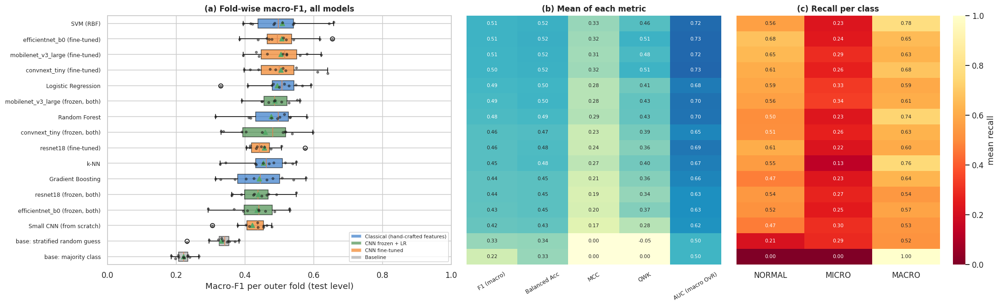

**Figure B5.** All models on the identical outer folds: (a) fold-wise macro-F1 (dots = folds; colour = model family), (b) mean of five metrics, (c) mean recall per class. The MICRO column is the critical one.

In [58]:
# ---------- 8.1 All models on the same folds ----------
TF_all = pd.concat([CLS_T, TFa[TFa.Model.isin(A_BOTH)], TFb], ignore_index=True)
TS_all = pd.concat([CLS_S, TSa[TSa.Model.isin(A_BOTH)], TSb], ignore_index=True)
FAMILY_OF = {**{m_: 'Classical (hand-crafted features)' for m_ in CLASSIC_MODELS}, **{m_: 'Baseline' for m_ in BASE_NAMES},
             **{m_: 'CNN frozen + LR' for m_ in A_BOTH}, **{m_: 'CNN fine-tuned' for m_ in B_ORDER}}
ORDER_ALL = list(CLASSIC_MODELS) + A_BOTH + B_ORDER + BASE_NAMES
ORDER_ALL = [m_ for m_ in ORDER_ALL if m_ in TF_all.Model.unique()]
f1_mean = TF_all.groupby('Model')['F1 (macro)'].mean()
agg_all, tab_all = mean_sd_table(TF_all, sorted(ORDER_ALL, key=lambda m_: -f1_mean[m_]))
tab_all.insert(0, 'Family', [FAMILY_OF[m_] for m_ in tab_all.index])
save_table(tab_all, 'all_models_test_level', f'All models on the identical outer folds, TEST level, sorted by mean macro-F1: mean ± SD over {len(OUTER_USE)} outer folds.')
_, tab_all_s = mean_sd_table(TS_all, sorted(ORDER_ALL, key=lambda m_: -f1_mean[m_]))
tab_all_s.insert(0, 'Family', [FAMILY_OF[m_] for m_ in tab_all_s.index])
save_table(tab_all_s, 'all_models_sample_level', 'All models, SAMPLE level (repeat probabilities averaged). Secondary result.', show=False)
put('comparison.mean_macro_f1_test', {m_: float(v) for m_, v in f1_mean.items()})

cnn_models = A_BOTH + B_ORDER
BEST_CNN = f1_mean[cnn_models].idxmax()
BEST_FT = f1_mean[B_ORDER].idxmax()
print(f'Best CNN-based model     : {BEST_CNN} (macro-F1 {f1_mean[BEST_CNN]:.3f})')
print(f'Best fine-tuned model    : {BEST_FT} (macro-F1 {f1_mean[BEST_FT]:.3f})')
print(f'Reference (classical)    : {REF_MODEL} (macro-F1 {f1_mean[REF_MODEL]:.3f})')
put('comparison.best_cnn', dict(model=BEST_CNN, f1=float(f1_mean[BEST_CNN]))); put('comparison.best_finetuned', dict(model=BEST_FT, f1=float(f1_mean[BEST_FT])))

fam_col = {'Classical (hand-crafted features)': '#1565C0', 'CNN frozen + LR': '#2E7D32', 'CNN fine-tuned': '#EF6C00', 'Baseline': '#9E9E9E'}
ordp = sorted(ORDER_ALL, key=lambda m_: -f1_mean[m_])
fig, axs = plt.subplots(1, 3, figsize=(20, 6.2), gridspec_kw={'width_ratios': [1.35, 1, 1]})
bx = [TF_all[TF_all.Model == m_]['F1 (macro)'].values for m_ in ordp]
bp = axs[0].boxplot(bx, vert=False, showmeans=True, patch_artist=True, widths=.6)
for patch, m_ in zip(bp['boxes'], ordp): patch.set_facecolor(fam_col[FAMILY_OF[m_]]); patch.set_alpha(.6)
for i, v in enumerate(bx): axs[0].scatter(v, np.random.default_rng(i).normal(i + 1, .06, len(v)), c='k', s=9, alpha=.5, zorder=3)
axs[0].set_yticklabels([m_.replace('Baseline: ', 'base: ') for m_ in ordp], fontsize=8); axs[0].invert_yaxis(); axs[0].set_xlim(0, 1)
axs[0].set_xlabel('Macro-F1 per outer fold (test level)'); axs[0].set_title('(a) Fold-wise macro-F1, all models')
axs[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=c, alpha=.6) for c in fam_col.values()], labels=list(fam_col), fontsize=7, loc='lower right')
hm = pd.DataFrame({m_: [agg_all.loc[n, (m_, 'mean')] for n in ordp] for m_ in ['F1 (macro)', 'Balanced Acc', 'MCC', 'QWK', 'AUC (macro OvR)']}, index=[n.replace('Baseline: ', 'base: ') for n in ordp])
sns.heatmap(hm, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axs[1], cbar=False, annot_kws={'fontsize': 7}); axs[1].set_title('(b) Mean of each metric'); axs[1].set_yticklabels([]); axs[1].tick_params(axis='x', rotation=30, labelsize=8)
hr = pd.DataFrame({c: [agg_all.loc[n, (f'Recall {c}', 'mean')] for n in ordp] for c in CLASSES}, index=ordp)
sns.heatmap(hr, annot=True, fmt='.2f', cmap='YlOrRd_r', vmin=0, vmax=1, ax=axs[2], annot_kws={'fontsize': 7}, cbar_kws={'label': 'mean recall'}); axs[2].set_title('(c) Recall per class'); axs[2].set_yticklabels([])
fig.tight_layout()
save_fig(fig, 'all_models_comparison', 'All models on the identical outer folds: (a) fold-wise macro-F1 (dots = folds; colour = model family), (b) mean of five metrics, (c) mean recall per class. The MICRO column is the critical one.')

In [59]:
# ---------- 8.1b Export of the fold-wise scores and out-of-fold predictions (read by Part IV) ----------
TF_all.to_csv(TAB_DIR / 'fold_metrics_all_models_test_level.csv', index=False, encoding='utf-8-sig')
TS_all.to_csv(TAB_DIR / 'fold_metrics_all_models_sample_level.csv', index=False, encoding='utf-8-sig')
pd.to_pickle(dict(RES_A=RES_A, RES_B=RES_B, REF_MODEL=REF_MODEL, B_ORDER=B_ORDER, A_BOTH=A_BOTH), CACHE_DIR / 'oof_cnn_models.pkl')
print('Exported:', 'fold_metrics_all_models_{test,sample}_level.csv', '| oof_cnn_models.pkl  (classical + CNN scores on the identical folds)')

Exported: fold_metrics_all_models_{test,sample}_level.csv | oof_cnn_models.pkl  (classical + CNN scores on the identical folds)


In [60]:
# ---------- 8.2 Friedman test and pre-specified contrasts against the reference model ----------
finalists = [REF_MODEL] + cnn_models
piv = TF_all[TF_all.Model.isin(finalists)].pivot_table(index=['rep', 'fold'], columns='Model', values='F1 (macro)')[finalists]
chi, p_fr = sps.friedmanchisquare(*[piv[m_].values for m_ in finalists])
ranks = piv.rank(axis=1, ascending=False).mean().sort_values()
print(f'Friedman test over {len(finalists)} finalists (test level): chi2 = {chi:.2f}, p = {p_fr:.4g}')
display(ranks.round(2).to_frame('Mean rank (1 = best)'))
put('comparison.friedman', dict(chi2=chi, p=p_fr, n_models=len(finalists), mean_rank=ranks.round(3).to_dict()))

J = len(piv); ratio = 1.0 / (CFG['OUTER_FOLDS'] - 1)
rows = []
for m_ in cnn_models:
    d = piv[m_] - piv[REF_MODEL]
    try: p_w = sps.wilcoxon(d, zero_method='zsplit').pvalue if (d != 0).any() else 1.0
    except ValueError: p_w = 1.0
    t_nb = d.mean() / np.sqrt((1.0 / J + ratio) * d.var(ddof=1) + 1e-18)
    rows.append({'CNN-based model': m_, 'Family': FAMILY_OF[m_], 'Mean macro-F1': piv[m_].mean(), f'Reference ({REF_MODEL})': piv[REF_MODEL].mean(),
                 'Mean difference (CNN − reference)': d.mean(), 'Folds CNN better': int((d > 0).sum()), 'Folds (total)': J, 'p (Wilcoxon)': p_w, 'p (Nadeau–Bengio)': 2 * sps.t.sf(abs(t_nb), df=J - 1)})
contr = pd.DataFrame(rows)
contr['p Holm (Wilcoxon)'] = holm(contr['p (Wilcoxon)']); contr['p Holm (Nadeau–Bengio)'] = holm(contr['p (Nadeau–Bengio)'])
contr['CNN significantly better'] = (contr['Mean difference (CNN − reference)'] > 0) & ((contr['p Holm (Wilcoxon)'] < 0.05) | (contr['p Holm (Nadeau–Bengio)'] < 0.05))
contr['CNN significantly worse'] = (contr['Mean difference (CNN − reference)'] < 0) & ((contr['p Holm (Wilcoxon)'] < 0.05) | (contr['p Holm (Nadeau–Bengio)'] < 0.05))
save_table(contr.round(4), 'cnn_vs_reference_tests', f'Each CNN-based model against the reference ({REF_MODEL}): paired differences of fold-wise macro-F1 (test level), Wilcoxon and Nadeau–Bengio tests, Holm-corrected over {len(contr)} contrasts. Folds overlap, so the p-values are indicative.', index=False)
put('comparison.contrasts', contr.round(5).to_dict(orient='records'))
ANY_BETTER = bool(contr['CNN significantly better'].any())
best_row = contr.set_index('CNN-based model').loc[BEST_CNN]
RULE_MET = bool(best_row['CNN significantly better'])
put('comparison.decision_rule', dict(cnn_replaces_classical=RULE_MET, best_cnn=BEST_CNN, mean_difference=float(best_row['Mean difference (CNN − reference)']),
                                     p_holm_wilcoxon=float(best_row['p Holm (Wilcoxon)']), p_holm_nb=float(best_row['p Holm (Nadeau–Bengio)'])))
print('Pre-specified decision rule -> CNN replaces the classical pipeline (Path A):', RULE_MET)

# vs baselines (does the CNN learn anything at all?)
rows = []
for m_ in cnn_models:
    for b_ in BASE_NAMES:
        d = TF_all[TF_all.Model == m_].set_index(['rep', 'fold'])['F1 (macro)'] - TF_all[TF_all.Model == b_].set_index(['rep', 'fold'])['F1 (macro)']
        try: pw = sps.wilcoxon(d, zero_method='zsplit').pvalue
        except ValueError: pw = 1.0
        rows.append({'CNN-based model': m_, 'Baseline': b_, 'Mean difference (model − baseline)': d.mean(), 'p (Wilcoxon)': pw})
bt = pd.DataFrame(rows); bt['p Holm'] = holm(bt['p (Wilcoxon)'])
save_table(bt.round(4), 'cnn_vs_baselines', 'Each CNN-based model against the two trivial baselines (paired Wilcoxon over folds, Holm-corrected). A model that is not better than the majority/random baseline has learned nothing transferable.', index=False, show=False)
put('comparison.vs_baselines', bt.round(5).to_dict(orient='records'))

Friedman test over 10 finalists (test level): chi2 = 33.21, p = 0.0001229


,Mean rank (1 = best)
Model,
mobilenet_v3_large (fine-tuned),3.4
SVM (RBF),3.6
efficientnet_b0 (fine-tuned),3.8
convnext_tiny (fine-tuned),4.0
"mobilenet_v3_large (frozen, both)",4.4
"convnext_tiny (frozen, both)",6.5
resnet18 (fine-tuned),6.6
"resnet18 (frozen, both)",7.1
"efficientnet_b0 (frozen, both)",7.2


**Table B10.** Each CNN-based model against the reference (SVM (RBF)): paired differences of fold-wise macro-F1 (test level), Wilcoxon and Nadeau–Bengio tests, Holm-corrected over 9 contrasts. Folds overlap, so the p-values are indicative.

,CNN-based model,Family,Mean macro-F1,Reference (SVM (RBF)),Mean difference (CNN − reference),Folds CNN better,Folds (total),p (Wilcoxon),p (Nadeau–Bengio),p Holm (Wilcoxon),p Holm (Nadeau–Bengio),CNN significantly better,CNN significantly worse
0,"resnet18 (frozen, both)",CNN frozen + LR,0.4390,0.5097,-0.0707,1,10,0.0195,0.1121,0.1562,0.7844,False,False
1,"efficientnet_b0 (frozen, both)",CNN frozen + LR,0.4349,0.5097,-0.0748,2,10,0.0195,0.0966,0.1562,0.7730,False,False
2,"mobilenet_v3_large (frozen, both)",CNN frozen + LR,0.4877,0.5097,-0.0220,4,10,0.3223,0.6222,1.0000,1.0000,False,False
3,"convnext_tiny (frozen, both)",CNN frozen + LR,0.4593,0.5097,-0.0504,2,10,0.0645,0.2886,0.3223,1.0000,False,False
4,resnet18 (fine-tuned),CNN fine-tuned,0.4564,0.5097,-0.0533,2,10,0.0195,0.1443,0.1562,0.8657,False,False
5,efficientnet_b0 (fine-tuned),CNN fine-tuned,0.5079,0.5097,-0.0018,5,10,0.9219,0.9620,1.0000,1.0000,False,False
6,mobilenet_v3_large (fine-tuned),CNN fine-tuned,0.5051,0.5097,-0.0046,6,10,0.9219,0.8802,1.0000,1.0000,False,False
7,convnext_tiny (fine-tuned),CNN fine-tuned,0.5045,0.5097,-0.0051,4,10,0.9219,0.8960,1.0000,1.0000,False,False
8,Small CNN (from scratch),CNN fine-tuned,0.4224,0.5097,-0.0873,0,10,0.0020,0.0668,0.0176,0.6016,False,True


Pre-specified decision rule -> CNN replaces the classical pipeline (Path A): False


**Table B11.** Each CNN-based model against the two trivial baselines (paired Wilcoxon over folds, Holm-corrected). A model that is not better than the majority/random baseline has learned nothing transferable.

**Table B12.** Pooled out-of-fold macro-F1 (repeat 1) with 95% cluster-bootstrap confidence intervals (1000 resamples of samples).

,"Pooled OOF macro-F1 (repeat 1, test level)",95% CI (cluster bootstrap),MICRO recall,95% CI MICRO recall
Model,,,,
efficientnet_b0 (fine-tuned),0.535,0.461 – 0.602,0.288,0.150 – 0.425
SVM (RBF),0.511,0.435 – 0.576,0.237,0.135 – 0.340


**Table B13.** Paired cluster bootstrap of the difference in pooled out-of-fold macro-F1 between a CNN and the reference model (the same resampled samples are used for both, so the difference is paired).

,Observed difference of pooled macro-F1,95% CI of the difference,P(difference > 0),CI excludes 0
Comparison,,,,
efficientnet_b0 (fine-tuned) − SVM (RBF),0.024,-0.046 – +0.089,0.759,False


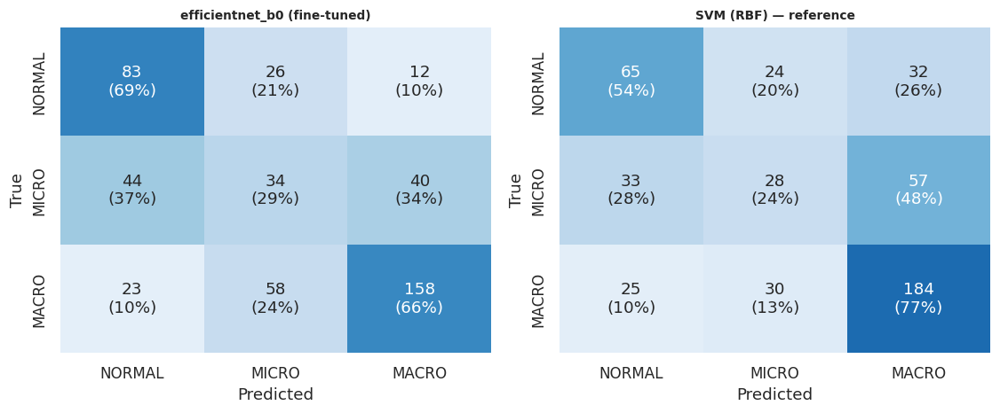

**Figure B6.** Pooled out-of-fold confusion matrices (repeat 1, test level; counts and row-normalised percentage) of the best CNN-based models and of the reference classical model.

In [61]:
# ---------- 8.3 Pooled out-of-fold predictions, confusion matrices, cluster bootstrap ----------
OOF_B = {m_: oof_of(RES_B, m_, 0) for m_ in B_ORDER}
OOF_A = {m_: oof_of(RES_A, m_, 0) for m_ in A_BOTH}
OOF_ALL = {**OOF_A, **OOF_B}
OOF_REF = None
if FINAL_NRES is not None:
    OOF_REF = np.zeros((N, 3))
    for r in FINAL_NRES:
        if r['model'] == REF_MODEL and r['rep'] == 0: OOF_REF[r['tei']] = r['proba']
    assert np.allclose(OOF_REF.sum(1), 1, atol=1e-3), 'reference out-of-fold probabilities incomplete'

rng = np.random.default_rng(SEED)
uniq = np.unique(g_all); idx_by = {s: np.where(g_all == s)[0] for s in uniq}
B_N = CFG['BOOT_N']
pairs = {BEST_CNN: OOF_ALL[BEST_CNN], BEST_FT: OOF_ALL[BEST_FT]}
if OOF_REF is not None: pairs[REF_MODEL] = OOF_REF
boot = {k: [] for k in pairs}; boot_d = {k: [] for k in pairs if k != REF_MODEL}; boot_mk = {k: [] for k in pairs}
for _ in range(B_N):
    ss = rng.choice(uniq, size=len(uniq), replace=True); ii = np.concatenate([idx_by[s] for s in ss])
    f1s = {}
    for k, P in pairs.items():
        yp = P[ii].argmax(1); f1s[k] = f1_score(y_all[ii], yp, average='macro', zero_division=0); boot[k].append(f1s[k]); boot_mk[k].append(recall_per_class(y_all[ii], yp)[1])
    if OOF_REF is not None:
        for k in boot_d: boot_d[k].append(f1s[k] - f1s[REF_MODEL])
rows = []
for k, P in pairs.items():
    ci = np.percentile(boot[k], [2.5, 97.5]); cm_ = np.percentile(boot_mk[k], [2.5, 97.5])
    rows.append({'Model': k, 'Pooled OOF macro-F1 (repeat 1, test level)': f1_score(y_all, P.argmax(1), average='macro'), '95% CI (cluster bootstrap)': f'{ci[0]:.3f} – {ci[1]:.3f}',
                 'MICRO recall': recall_per_class(y_all, P.argmax(1))[1], '95% CI MICRO recall': f'{cm_[0]:.3f} – {cm_[1]:.3f}'})
boot_tab = pd.DataFrame(rows).set_index('Model')
save_table(boot_tab.round(3), 'oof_bootstrap_ci', f'Pooled out-of-fold macro-F1 (repeat 1) with 95% cluster-bootstrap confidence intervals ({B_N} resamples of samples).')
put('comparison.bootstrap', boot_tab.round(4).reset_index().to_dict(orient='records'))
if OOF_REF is not None:
    drows = []
    for k, v in boot_d.items():
        ci = np.percentile(v, [2.5, 97.5])
        drows.append({'Comparison': f'{k} − {REF_MODEL}', 'Observed difference of pooled macro-F1': f1_score(y_all, pairs[k].argmax(1), average='macro') - f1_score(y_all, OOF_REF.argmax(1), average='macro'),
                      '95% CI of the difference': f'{ci[0]:+.3f} – {ci[1]:+.3f}', 'P(difference > 0)': float(np.mean(np.array(v) > 0)), 'CI excludes 0': bool(ci[0] > 0 or ci[1] < 0)})
    dtab = pd.DataFrame(drows).set_index('Comparison')
    save_table(dtab.round(3), 'paired_bootstrap_difference', 'Paired cluster bootstrap of the difference in pooled out-of-fold macro-F1 between a CNN and the reference model (the same resampled samples are used for both, so the difference is paired).')
    put('comparison.paired_bootstrap', dtab.round(4).reset_index().to_dict(orient='records'))

# confusion matrices
show = [BEST_CNN] + ([BEST_FT] if BEST_FT != BEST_CNN else []) + ([REF_MODEL] if OOF_REF is not None else [])
fig, axs = plt.subplots(1, len(show), figsize=(5.2 * len(show), 4.4))
axs = np.atleast_1d(axs)
for ax, k in zip(axs, show):
    cm_ = confusion_matrix(y_all, pairs[k].argmax(1), labels=[0, 1, 2]); cmn = cm_ / cm_.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f'{cm_[i, j]}\n({cmn[i, j]:.0%})' for j in range(3)] for i in range(3)]), fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(k + (' — reference' if k == REF_MODEL else ''), fontsize=9)
fig.tight_layout()
save_fig(fig, 'confusion_matrices', 'Pooled out-of-fold confusion matrices (repeat 1, test level; counts and row-normalised percentage) of the best CNN-based models and of the reference classical model.')

In [62]:
# ---------- 8.4 Exploratory: do the CNN and the hand-crafted model make complementary errors? (post-hoc, NOT part of the decision rule) ----------
if FINAL_NRES is not None:
    ref_by = {(r['rep'], r['fold']): r['proba'] for r in FINAL_NRES if r['model'] == REF_MODEL}
    cnn_by = {(r['rep'], r['fold']): r['proba'] for r in (RES_A[BEST_CNN] if BEST_CNN in RES_A else RES_B[BEST_CNN])}
    ens_rows = []
    for (rep, fold, tri, tei) in OUTER_USE:
        pe = 0.5 * ref_by[(rep, fold)] + 0.5 * cnn_by[(rep, fold)]
        ens_rows.append({'rep': rep, 'fold': fold, 'F1 ensemble': f1_score(y_all[tei], pe.argmax(1), average='macro', zero_division=0),
                         'F1 reference': f1_score(y_all[tei], ref_by[(rep, fold)].argmax(1), average='macro', zero_division=0),
                         'F1 CNN': f1_score(y_all[tei], cnn_by[(rep, fold)].argmax(1), average='macro', zero_division=0)})
    ens = pd.DataFrame(ens_rows)
    d = ens['F1 ensemble'] - ens['F1 reference']
    try: pw = sps.wilcoxon(d, zero_method='zsplit').pvalue if (d != 0).any() else 1.0
    except ValueError: pw = 1.0
    res_e = pd.DataFrame({'Mean macro-F1': [ens['F1 reference'].mean(), ens['F1 CNN'].mean(), ens['F1 ensemble'].mean()]}, index=[REF_MODEL, BEST_CNN, 'Ensemble (average of probabilities)'])
    res_e['SD over folds'] = [ens['F1 reference'].std(), ens['F1 CNN'].std(), ens['F1 ensemble'].std()]
    save_table(res_e.round(3), 'exploratory_ensemble', f'Exploratory (post-hoc): average of the probabilities of the reference model and {BEST_CNN}. Difference ensemble − reference: mean {d.mean():+.3f}, Wilcoxon p = {pw:.3g} (uncorrected, exploratory).')
    put('comparison.exploratory_ensemble', dict(f1_ref=float(ens['F1 reference'].mean()), f1_cnn=float(ens['F1 CNN'].mean()), f1_ens=float(ens['F1 ensemble'].mean()), p_wilcoxon=float(pw)))
else:
    print('Reference out-of-fold probabilities not available -> exploratory ensemble skipped.')
stage_done('8 comparison')

**Table B14.** Exploratory (post-hoc): average of the probabilities of the reference model and efficientnet_b0 (fine-tuned). Difference ensemble − reference: mean -0.006, Wilcoxon p = 0.846 (uncorrected, exploratory).

,Mean macro-F1,SD over folds
SVM (RBF),0.510,0.090
efficientnet_b0 (fine-tuned),0.508,0.081
Ensemble (average of probabilities),0.504,0.077


# Stage 24 · Training Behaviour and the Optimism of "Peeking"

**Purpose.** Show *how* the networks learn and quantify a trap: if the epoch with the best **test** score were reported, the result would look better than it is.

**Figures.**
* Mean training loss per epoch — does the network converge, and how fast?
* Diagnostic test macro-F1 per epoch (no TTA) — does the test score rise, plateau or fall (over-fitting)?
* *Optimism of peeking* = (maximum over epochs of the mean diagnostic test F1) − (diagnostic F1 at the pre-specified final epoch). A positive gap shows by how much a test-based choice of epoch would have inflated the score; the reported results use the final epoch only.

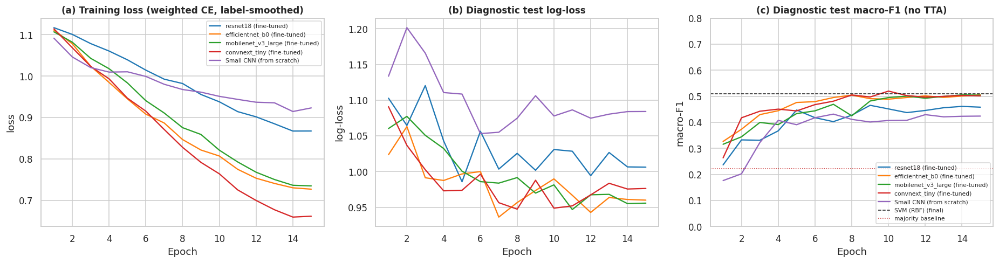

**Figure B7.** Learning curves averaged over the outer folds: (a) training loss; (b) test log-loss and (c) test macro-F1 after every epoch. The test curves are a diagnostic only — they were never used to choose the epoch, the learning rate or the model.

**Table B15.** Diagnostic: macro-F1 at the pre-specified final epoch versus the best epoch chosen on the test folds (not allowed; shown to quantify the optimism). Rising test log-loss together with falling training loss indicates over-fitting.

,Final-epoch diagnostic F1,Best-epoch diagnostic F1 (peeking),Epoch of the maximum,Optimism of peeking,Final train loss,Final test log-loss,Min test log-loss,Epoch of min test log-loss
Model,,,,,,,,
resnet18 (fine-tuned),0.458,0.466,9,0.007,0.867,1.006,0.986,5
efficientnet_b0 (fine-tuned),0.506,0.506,15,0.000,0.727,0.960,0.936,7
mobilenet_v3_large (fine-tuned),0.504,0.506,14,0.001,0.735,0.956,0.947,11
convnext_tiny (fine-tuned),0.502,0.520,10,0.018,0.662,0.976,0.947,8
Small CNN (from scratch),0.424,0.432,7,0.008,0.923,1.084,1.053,6


In [63]:
# ---------- 9.1 Learning curves ----------
H = HIST.copy()
curve = H.groupby(['Model', 'epoch'])[['train_loss', 'test_loss_diag', 'test_f1_diag']].mean().reset_index()
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
cols = plt.cm.tab10(np.arange(len(B_ORDER)))
for c_, m_ in zip(cols, B_ORDER):
    d = curve[curve.Model == m_]
    axs[0].plot(d.epoch, d.train_loss, c=c_, label=m_); axs[1].plot(d.epoch, d.test_loss_diag, c=c_, label=m_); axs[2].plot(d.epoch, d.test_f1_diag, c=c_, label=m_)
axs[0].set_title('(a) Training loss (weighted CE, label-smoothed)'); axs[1].set_title('(b) Diagnostic test log-loss'); axs[2].set_title('(c) Diagnostic test macro-F1 (no TTA)')
axs[2].axhline(cls_mean[REF_MODEL], c='k', ls='--', lw=1, label=f'{REF_MODEL} (final)'); axs[2].axhline(cls_mean[BASE_NAMES[0]], c='#C62828', ls=':', lw=1, label='majority baseline')
for a in axs: a.set_xlabel('Epoch')
axs[0].set_ylabel('loss'); axs[1].set_ylabel('log-loss'); axs[2].set_ylabel('macro-F1'); axs[2].set_ylim(0, 0.8); axs[0].legend(fontsize=7)
axs[2].legend(fontsize=7, loc='lower right')
fig.tight_layout()
save_fig(fig, 'learning_curves', 'Learning curves averaged over the outer folds: (a) training loss; (b) test log-loss and (c) test macro-F1 after every epoch. The test curves are a diagnostic only — they were never used to choose the epoch, the learning rate or the model.')

peek = []
for m_ in B_ORDER:
    d = curve[curve.Model == m_].set_index('epoch')
    peek.append({'Model': m_, 'Final-epoch diagnostic F1': d['test_f1_diag'].iloc[-1], 'Best-epoch diagnostic F1 (peeking)': d['test_f1_diag'].max(), 'Epoch of the maximum': int(d['test_f1_diag'].idxmax()),
                 'Optimism of peeking': d['test_f1_diag'].max() - d['test_f1_diag'].iloc[-1], 'Final train loss': d['train_loss'].iloc[-1], 'Final test log-loss': d['test_loss_diag'].iloc[-1],
                 'Min test log-loss': d['test_loss_diag'].min(), 'Epoch of min test log-loss': int(d['test_loss_diag'].idxmin())})
peek = pd.DataFrame(peek).set_index('Model')
save_table(peek.round(3), 'peeking_optimism', 'Diagnostic: macro-F1 at the pre-specified final epoch versus the best epoch chosen on the test folds (not allowed; shown to quantify the optimism). Rising test log-loss together with falling training loss indicates over-fitting.')
put('training_behaviour.peeking', peek.round(4).reset_index().to_dict(orient='records'))
stage_done('9 training behaviour')

# Stage 25 · Interpretation and Shortcut-Learning Check

**Purpose.** A CNN can reach a decent score for the wrong reason (*shortcut learning*): it may look at the pad border, at the overall brightness, or at features unrelated to the reagent colour. With 100 samples this risk is real. This stage asks: **what does the network look at, and what does it depend on?**

**Method (on one held-out fold, so every explained image was *not* in the training set of the explaining model).** The selected fine-tuned model is re-trained for the first outer fold (same seed and recipe as in Stage 22) and then analysed:
1. **Grad-CAM.** For each assay branch, the gradient of the predicted-class score with respect to the last feature map gives a heat map of the regions that push the decision. Heat maps are overlaid on the crops for random test images of each class.
2. **Border-versus-centre attention.** Share of the heat-map mass that falls in the outer frame of the crop (outer 20 % on each side = 64 % of the area), divided by the share expected if attention were uniform. A ratio near 1 means no preference; a ratio well above 1 would mean the network attends to the border (edge/lighting artefacts).
3. **Perturbation tests (shortcut diagnostics).** The same test images are re-scored after (i) brightness changes of ±8 % and ±15 %, and (ii) removal of colour (conversion to grey). If the score is almost unchanged by grey-scaling, the decision does not rely on colour — suspicious for a colourimetric assay. If a modest brightness change flips many predictions, the network is sensitive to illumination, which varies between shots (lux).

*These are qualitative diagnostics on a single fold (≈ 95 test images); they indicate tendencies, not precise quantities.*

Selected fine-tuned model for interpretation: efficientnet_b0 (outer fold 1, repeat 1) ...
Re-trained in 33 s | macro-F1 on this fold (with TTA): 0.654


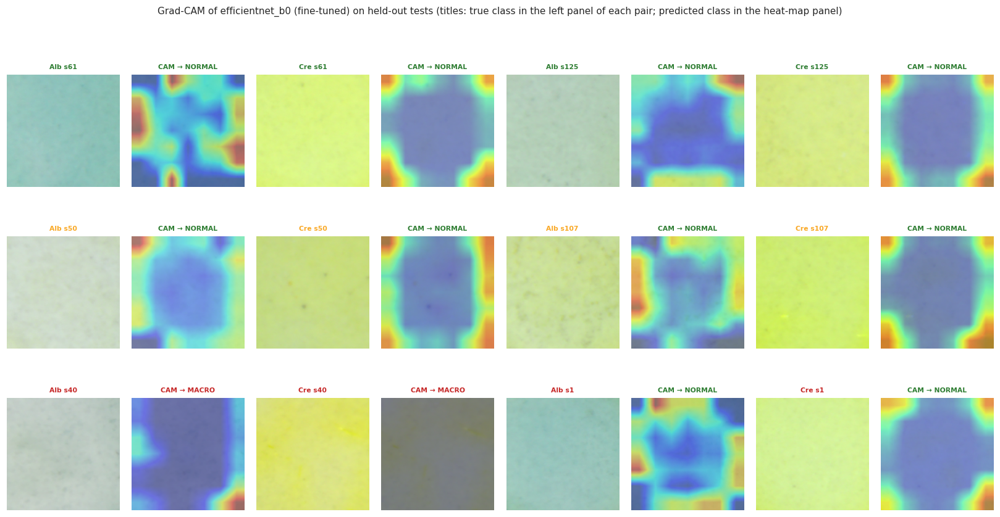

**Figure B8.** Grad-CAM of the selected fine-tuned model (efficientnet_b0 (fine-tuned)) for random held-out tests of each class (rows: NORMAL, MICRO, MACRO). Warm colours = regions that raise the score of the predicted class. Left of each pair: crop; right: overlay.

**Table B16.** Share of Grad-CAM mass in the outer frame of the crop (outer 20 % on each side) relative to its share of the area; 96 held-out tests of outer fold 1. A ratio clearly above 1 would indicate attention to the border.

,Border share of attention (mean),Border share of area,Ratio (1 = uniform)
Branch,,,
Albumin,0.852,0.631,1.349
Creatinine,0.801,0.631,1.268


In [64]:
# ---------- 10.1 Re-train the selected model on the first outer fold and compute Grad-CAM ----------
SEL = [nm for nm in B_NAMES if b_label(nm) == BEST_FT][0]
rep0, fold0, tri0, tei0 = OUTER_USE[0]
print(f'Selected fine-tuned model for interpretation: {SEL} (outer fold {fold0 + 1}, repeat {rep0 + 1}) ...')
t0 = time.time()
res_g = train_cnn(SEL, tri0, tei0, seed=SEED + 1000 * rep0 + fold0, return_model=True)
GM = res_g['model'].eval()
for _p in GM.parameters(): _p.grad = None
if DEVICE.type == 'cuda': torch.cuda.empty_cache()
print(f'Re-trained in {time.time() - t0:.0f} s | macro-F1 on this fold (with TTA): {f1_score(y_all[tei0], res_g["proba"].argmax(1), average="macro"):.3f}')

def gradcam(model, idx, target=None, chunk=8):
    """Grad-CAM in small chunks (the full graph of a 64-image batch of a large backbone does not fit in 15 GB of GPU memory)."""
    idx = np.asarray(idx); cams, preds = [], []
    model.eval()
    for s in range(0, len(idx), chunk):
        ii = idx[s:s + chunk]
        x = prep(IMG_T[torch.as_tensor(ii, device=DEVICE)], False)
        with torch.enable_grad():
            out, maps = model(x, return_maps=True)
            tgt = out.argmax(1) if target is None else torch.as_tensor(np.asarray(target)[s:s + chunk], device=DEVICE)
            model.zero_grad(set_to_none=True)
            out.gather(1, tgt[:, None]).sum().backward()
            w = maps.grad.mean((2, 3), keepdim=True)
            cam = Fn.relu((w * maps).sum(1)).detach()                       # (2B, h, w)
        cam = Fn.interpolate(cam[:, None], size=(S, S), mode='bilinear', align_corners=False)[:, 0]
        cam = cam / cam.flatten(1).max(1)[0].clamp_min(1e-8)[:, None, None]
        cams.append(cam.view(len(ii), 2, S, S).cpu().numpy()); preds.append(out.argmax(1).detach().cpu().numpy())
        del out, maps, cam, w, x
        model.zero_grad(set_to_none=True)
        if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return np.concatenate(cams), np.concatenate(preds)

rng = np.random.default_rng(SEED)
pick = []
for c in range(3):
    cand = tei0[y_all[tei0] == c]
    pick += list(rng.choice(cand, size=min(CFG['GRADCAM_PER_CLASS'], len(cand)), replace=False))
cam_p, pred_p = gradcam(GM, np.array(pick))
nper = CFG['GRADCAM_PER_CLASS']
fig, axs = plt.subplots(3, nper * 4, figsize=(3.0 * nper * 4 * 0.62, 3 * 2.7))
axs = np.atleast_2d(axs)
for j, i in enumerate(pick):
    r_, k_ = divmod(j, nper)
    for b, assay in enumerate(('Albumin', 'Creatinine')):
        a1, a2 = axs[r_, k_ * 4 + b * 2], axs[r_, k_ * 4 + b * 2 + 1]
        a1.imshow(IMGS[i, b]); a2.imshow(IMGS[i, b]); a2.imshow(cam_p[j, b], cmap='jet', alpha=.45, vmin=0, vmax=1)
        a1.set_title(f'{assay[:3]} s{g_all[i]}', fontsize=7, color=COLORS[CLASSES[y_all[i]]]); a2.set_title(f'CAM → {CLASSES[pred_p[j]]}', fontsize=7, color=COLORS[CLASSES[pred_p[j]]])
        a1.axis('off'); a2.axis('off')
fig.suptitle(f'Grad-CAM of {BEST_FT} on held-out tests (titles: true class in the left panel of each pair; predicted class in the heat-map panel)', fontsize=10, y=1.0)
fig.tight_layout()
save_fig(fig, 'gradcam', f'Grad-CAM of the selected fine-tuned model ({BEST_FT}) for random held-out tests of each class (rows: NORMAL, MICRO, MACRO). Warm colours = regions that raise the score of the predicted class. Left of each pair: crop; right: overlay.')

# ---------- 10.2 Border-versus-centre attention on all test images of the fold ----------
cam_all, pred_all = gradcam(GM, tei0)
yy, xx = np.mgrid[0:S, 0:S]; m = int(0.2 * S)
border = ~((yy >= m) & (yy < S - m) & (xx >= m) & (xx < S - m)); area_share = border.mean()
rows = []
for b, assay in enumerate(('Albumin', 'Creatinine')):
    share = np.array([c_[border].sum() / max(c_.sum(), 1e-8) for c_ in cam_all[:, b]])
    rows.append({'Branch': assay, 'Border share of attention (mean)': share.mean(), 'Border share of area': area_share, 'Ratio (1 = uniform)': share.mean() / area_share})
bc = pd.DataFrame(rows).set_index('Branch')
save_table(bc.round(3), 'gradcam_border_ratio', f'Share of Grad-CAM mass in the outer frame of the crop (outer 20 % on each side) relative to its share of the area; {len(tei0)} held-out tests of outer fold {fold0 + 1}. A ratio clearly above 1 would indicate attention to the border.')
put('interpretation.border_ratio', bc.round(4).reset_index().to_dict(orient='records'))

**Table B17.** Shortcut diagnostics for efficientnet_b0 (fine-tuned) on the held-out tests of outer fold 1: effect of brightness changes and of removing colour. Large changes under small brightness shifts indicate illumination sensitivity; little change after removing colour indicates that colour is not what the network uses.

,Macro-F1,Accuracy,Predictions changed vs original (%),Share predicted MACRO (%)
Test image variant,,,,
original,0.617,0.688,0.000,47.917
brightness −15 %,0.570,0.583,32.292,36.458
brightness −8 %,0.591,0.625,13.542,39.583
brightness +8 %,0.618,0.677,13.542,45.833
brightness +15 %,0.603,0.635,22.917,36.458
grey-scale (colour removed),0.503,0.635,23.958,50.000


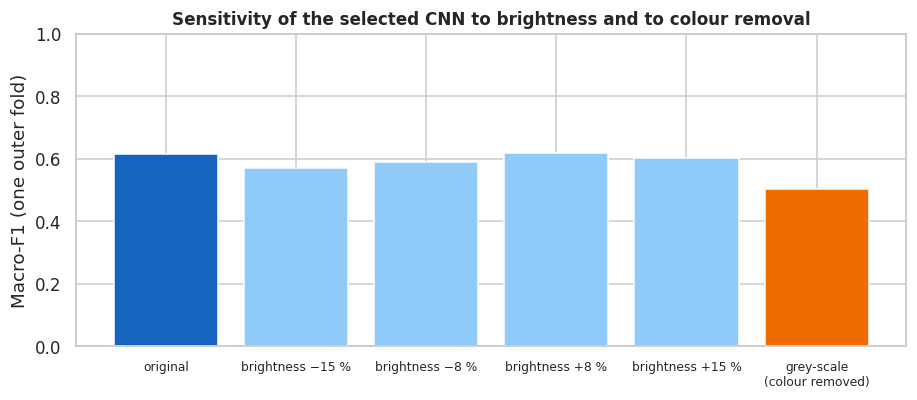

**Figure B9.** Effect of input perturbations on the macro-F1 of the selected CNN (single held-out fold, ≈ 95 tests; indicative only).

In [65]:
# ---------- 10.3 Perturbation tests: brightness and colour removal ----------
@torch.no_grad()
def predict_variant(model, idx, gain=1.0, grey=False, bs=64):
    model.eval(); out = []
    for s in range(0, len(idx), bs):
        x = IMG_T[torch.as_tensor(idx[s:s + bs], device=DEVICE)].float() / 255.0
        if grey:
            g_ = (0.299 * x[:, :, 0] + 0.587 * x[:, :, 1] + 0.114 * x[:, :, 2]).unsqueeze(2)
            x = g_.expand(-1, -1, 3, -1, -1).contiguous()
        x = (x * gain).clamp(0, 1)
        x = (x - IMNET_MEAN) / IMNET_STD
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out.append(Fn.softmax(model(x).float(), 1).cpu().numpy())
    return np.concatenate(out)

base_p = predict_variant(GM, tei0)
rows = []
for lab_, kw in [('original', {}), ('brightness −15 %', dict(gain=0.85)), ('brightness −8 %', dict(gain=0.92)), ('brightness +8 %', dict(gain=1.08)),
                 ('brightness +15 %', dict(gain=1.15)), ('grey-scale (colour removed)', dict(grey=True))]:
    p = predict_variant(GM, tei0, **kw)
    rows.append({'Test image variant': lab_, 'Macro-F1': f1_score(y_all[tei0], p.argmax(1), average='macro', zero_division=0), 'Accuracy': accuracy_score(y_all[tei0], p.argmax(1)),
                 'Predictions changed vs original (%)': 100 * float((p.argmax(1) != base_p.argmax(1)).mean()),
                 'Share predicted MACRO (%)': 100 * float((p.argmax(1) == 2).mean())})
pert = pd.DataFrame(rows).set_index('Test image variant')
save_table(pert.round(3), 'perturbation_tests', f'Shortcut diagnostics for {BEST_FT} on the held-out tests of outer fold {fold0 + 1}: effect of brightness changes and of removing colour. Large changes under small brightness shifts indicate illumination sensitivity; little change after removing colour indicates that colour is not what the network uses.')
put('interpretation.perturbation', pert.round(4).reset_index().to_dict(orient='records'))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.bar(range(len(pert)), pert['Macro-F1'], color=['#1565C0'] + ['#90CAF9'] * 4 + ['#EF6C00'])
ax.set_xticks(range(len(pert))); ax.set_xticklabels([i.replace(' (', '\n(') for i in pert.index], fontsize=8); ax.set_ylabel('Macro-F1 (one outer fold)'); ax.set_ylim(0, 1)
ax.set_title('Sensitivity of the selected CNN to brightness and to colour removal')
fig.tight_layout()
save_fig(fig, 'perturbation', 'Effect of input perturbations on the macro-F1 of the selected CNN (single held-out fold, ≈ 95 tests; indicative only).')
del GM, res_g
if DEVICE.type == 'cuda': torch.cuda.empty_cache()
stage_done('10 interpretation')

# Stage 26 · Final CNN Fit on All Samples (Optional)

**Purpose.** Provide a ready-to-use set of weights **in case** the CNN is adopted. The selected fine-tuned configuration is trained on **all 100 samples** with the same fixed recipe.

**Important.**
* The performance to quote for this model is the **nested-CV estimate** of Stage 23 — *not* its accuracy on the training images, which is optimistic by construction.
* The decision rule of Stage 23 says whether the CNN should replace the classical pipeline (Path A). If it is not met (the expected outcome with ≈ 100 samples), the weights are saved for reference and for future work (more samples), but the **classical SVM bundle of Path A remains the deployed model**.
* A round-trip self-test reloads the saved weights into a fresh network and checks that the predictions are identical.

In [66]:
FINAL_INFO = None
if CFG['FINAL_FIT']:
    allidx = np.arange(N)
    t0 = time.time()
    resF = train_cnn(SEL, allidx, allidx[:32], seed=SEED, return_model=True)
    mdl = resF['model'].eval()
    wpath = MODEL_DIR / f'cnn_{SEL}_final_weights.pt'
    torch.save(mdl.state_dict(), wpath)
    # round-trip self-test
    chk_idx = np.arange(0, N, max(1, N // 24))[:24]
    p1 = predict_proba(mdl, chk_idx, tta=False)
    mdl2 = TwoBranch(SEL, CFG['DROPOUT']).to(DEVICE); mdl2.load_state_dict(torch.load(wpath, map_location=DEVICE)); mdl2.eval()
    p2 = predict_proba(mdl2, chk_idx, tta=False)
    ok = bool(np.allclose(p1, p2, atol=1e-3))
    cfg_json = dict(model=SEL, label=b_label(SEL), classes=CLASSES, input=f'{S}x{S} RGB crop of the square inscribed in the ROI (albumin, creatinine), ImageNet normalisation',
                    roi_params=ROI_PARAMS, recipe=recipe, trained_on='all samples', n_samples=int(df_img['sample'].nunique()), n_tests=N,
                    expected_performance_nested_cv=dict(macro_f1_test_mean=float(f1_mean[BEST_FT]), macro_f1_test_sd=float(TF_all[TF_all.Model == BEST_FT]['F1 (macro)'].std()),
                                                        reference_model=REF_MODEL, reference_macro_f1=float(f1_mean[REF_MODEL]), decision_rule_met=RULE_MET),
                    pretrained_weights_loaded=PRETRAINED_OK.get(SEL, None), roundtrip_selftest_passed=ok, torch=torch.__version__, created=datetime.datetime.now().isoformat(timespec='seconds'))
    (MODEL_DIR / 'cnn_final_config.json').write_text(json.dumps(cfg_json, indent=2, default=str), encoding='utf-8')
    card = f"""# Model card — CNN ({SEL})

* **Task:** NORMAL / MICRO / MACRO from albumin + creatinine micropad images (research prototype).
* **Architecture:** shared {SEL} backbone (ImageNet pre-trained = {PRETRAINED_OK.get(SEL)}) applied to both crops; concatenated features; 2-layer head.
* **Training data:** {df_img['sample'].nunique()} samples / {N} image pairs; fixed recipe (no tuning on held-out data).
* **Expected performance (nested CV, test level):** macro-F1 {f1_mean[BEST_FT]:.3f} (SD over folds {TF_all[TF_all.Model == BEST_FT]['F1 (macro)'].std():.3f}); reference classical model {REF_MODEL}: {f1_mean[REF_MODEL]:.3f}.
* **Decision rule (CNN must be significantly better than the classical reference):** {'MET' if RULE_MET else 'NOT MET — the classical pipeline (Path A) remains the deployed model'}.
* **Limitations:** very small number of independent samples; single-device images; sensitivity to illumination should be checked (see perturbation tests); not validated externally; not for clinical use.
"""
    (MODEL_DIR / 'model_card_cnn.md').write_text(card, encoding='utf-8')
    FINAL_INFO = cfg_json
    print(f'Final fit done in {(time.time() - t0) / 60:.1f} min | weights: {wpath.name} | round-trip self-test passed: {ok}')
    assert ok, 'Reloaded weights give different predictions!'
    put('final_fit', dict(model=SEL, weights=wpath.name, roundtrip_selftest=ok))
    del mdl, mdl2, resF
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
else:
    print('FINAL_FIT is False -> skipped.')
sync_to_drive(verbose=False)
stage_done('11 final fit')

Final fit done in 0.7 min | weights: cnn_efficientnet_b0_final_weights.pt | round-trip self-test passed: True


# Stage 27 · Findings Summary and Export

**Purpose.** Collect the numbers that are quoted in the article and state the conclusion according to the pre-specified rule.

**Outputs** (in `outputs/B_CNN`): `figures/` (300 dpi PNG), `tables/` (CSV), `report/report_numbers_cnn.json` (every quoted number), `report/Findings_Summary_CNN.md`, `report/experiment_configuration_cnn.json`, `model/` (final weights, config, model card), `cache/` (embeddings, image tensors, finished fine-tuning tasks — reused if the notebook is re-run).

**How to read the verdict.** The wording is generated from the results: it says "better", "equivalent" or "worse" only when the statistics support it; otherwise it says that the evidence is insufficient to separate the approaches. Remember that with ≈ 100 samples a non-significant difference means *inconclusive*, not *equal*.

In [67]:
# ---------- Findings summary (generated from the results) ----------
ref_f1, cnn_f1, ft_f1 = f1_mean[REF_MODEL], f1_mean[BEST_CNN], f1_mean[BEST_FT]
bestA = f1_mean[A_BOTH].idxmax()
cr = contr.set_index('CNN-based model')
def verdict(m_):
    r = cr.loc[m_]
    if r['CNN significantly better']: return 'significantly better than the classical reference'
    if r['CNN significantly worse']:  return 'significantly worse than the classical reference'
    return 'not distinguishable from the classical reference (difference not significant after Holm correction)'
lines = []
lines.append('# Findings summary — CNN pipeline\n')
lines.append(f'*Generated {datetime.datetime.now():%Y-%m-%d %H:%M}; fast mode: {CFG["FAST_MODE"]}; device: {DEVICE}.*\n')
lines.append(f'- **Design.** {N} image pairs from {df_img["sample"].nunique()} samples; identical outer folds as Path A ({CFG["OUTER_FOLDS"]} folds × {CFG["OUTER_REPEATS_CNN"]} repeats, grouped by sample; identical to the Final folds: verified).')
lines.append(f'- **Reference (classical, hand-crafted features).** {REF_MODEL}: macro-F1 {ref_f1:.3f} ± {TF_all[TF_all.Model == REF_MODEL]["F1 (macro)"].std():.3f}; majority baseline {f1_mean[BASE_NAMES[0]]:.3f}.')
lines.append(f'- **Strategy A (frozen embeddings + LR).** Best: {bestA}, macro-F1 {f1_mean[bestA]:.3f}; {verdict(bestA)}.')
lines.append(f'- **Strategy B (fine-tuned).** Best: {BEST_FT}, macro-F1 {ft_f1:.3f}; {verdict(BEST_FT)}.')
sc_ = b_label('scratch') if CFG['INCLUDE_SCRATCH'] else None
if sc_ in f1_mean.index: lines.append(f'- **From scratch (lower bound).** macro-F1 {f1_mean[sc_]:.3f}.')
lines.append(f'- **MICRO recall (test level).** {BEST_CNN}: {agg_all.loc[BEST_CNN, ("Recall MICRO", "mean")]:.3f} vs {REF_MODEL}: {agg_all.loc[REF_MODEL, ("Recall MICRO", "mean")]:.3f}.')
lines.append(f'- **Friedman test over the finalists.** χ² = {chi:.2f}, p = {p_fr:.4g}.')
if OOF_REF is not None:
    dd = dtab.loc[f'{BEST_CNN} − {REF_MODEL}']
    lines.append(f'- **Paired cluster bootstrap ({BEST_CNN} − {REF_MODEL}).** ΔF1 = {dd["Observed difference of pooled macro-F1"]:+.3f}, 95 % CI {dd["95% CI of the difference"]}.')
hc_alb = final_rf.get('log albumin', float('nan'))
lines.append(f'- **Measurement audit with CNN embeddings.** Best cross-validated R² for log albumin = {best_cnn_alb:.2f} (hand-crafted features, Path A: {hc_alb:.2f}); CNN features {"do not clearly exceed" if best_cnn_alb < hc_alb + 0.10 else "exceed"} the hand-crafted features (difference {best_cnn_alb - hc_alb:+.2f}). Illumination (lux) is predictable from the embeddings with R² up to {pv.loc[CFG["BACKBONES"], "lux"].max():.2f}.')
lines.append(f'- **Shortcut check.** Border-attention ratio (Grad-CAM): albumin {bc.iloc[0]["Ratio (1 = uniform)"]:.2f}, creatinine {bc.iloc[1]["Ratio (1 = uniform)"]:.2f}; grey-scale macro-F1 {pert.loc["grey-scale (colour removed)", "Macro-F1"]:.2f} vs original {pert.loc["original", "Macro-F1"]:.2f}; brightness ±15 % changes {pert.loc[["brightness −15 %", "brightness +15 %"], "Predictions changed vs original (%)"].mean():.0f} % of predictions on average.')
lines.append('')
lines.append('## Decision (pre-specified rule)\n')
if RULE_MET:
    lines.append(f'**The CNN ({BEST_CNN}) is significantly better than {REF_MODEL}** (Holm-corrected p ≤ 0.05) and may replace it, after external validation and a shortcut review (see the interpretation stage).')
else:
    lines.append(f'**The CNN does not replace the classical pipeline (Path A).** The best CNN-based model ({BEST_CNN}, macro-F1 {cnn_f1:.3f}) is {verdict(BEST_CNN)}. With ≈ 100 independent samples this is an *inconclusive-or-negative* result, not proof of equality; the classical SVM bundle remains the primary method.')
lines.append('')
lines.append('## Limitations\n')
lines += ['- Only 100 independent samples (25 / 25 / 50); the CNN recipe was fixed, not tuned, so a better-tuned CNN could differ slightly.',
          '- The images come from one acquisition setup; no external validation set exists.',
          '- Grad-CAM and perturbation tests are qualitative and use a single fold.',
          '- GPU kernels are not bit-wise deterministic: re-running may change the third decimal.']
(REPORT_DIR / 'Findings_Summary_CNN.md').write_text('\n'.join(lines), encoding='utf-8')
(REPORT_DIR / 'experiment_configuration_cnn.json').write_text(json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}, indent=2, default=str), encoding='utf-8')
pd.DataFrame(FIG_REG).to_csv(TAB_DIR / 'figure_list.csv', index=False, encoding='utf-8-sig'); pd.DataFrame(TAB_REG).to_csv(TAB_DIR / 'table_list.csv', index=False, encoding='utf-8-sig')
put('summary.rule_met', RULE_MET); put('summary.best_cnn', BEST_CNN); put('summary.reference', REF_MODEL)
put('runtime.total_minutes', (time.time() - T_NOTEBOOK_START) / 60)
dump_numbers()
display(Markdown('\n'.join(lines)))

# Findings summary — CNN pipeline

*Generated 2026-10-30 16:26; fast mode: False; device: cuda.*

- **Design.** 478 image pairs from 100 samples; identical outer folds as Path A (5 folds × 2 repeats, grouped by sample; identical to the Final folds: verified).
- **Reference (classical, hand-crafted features).** SVM (RBF): macro-F1 0.510 ± 0.090; majority baseline 0.221.
- **Strategy A (frozen embeddings + LR).** Best: mobilenet_v3_large (frozen, both), macro-F1 0.488; not distinguishable from the classical reference (difference not significant after Holm correction).
- **Strategy B (fine-tuned).** Best: efficientnet_b0 (fine-tuned), macro-F1 0.508; not distinguishable from the classical reference (difference not significant after Holm correction).
- **From scratch (lower bound).** macro-F1 0.422.
- **MICRO recall (test level).** efficientnet_b0 (fine-tuned): 0.241 vs SVM (RBF): 0.229.
- **Friedman test over the finalists.** χ² = 33.21, p = 0.0001229.
- **Paired cluster bootstrap (efficientnet_b0 (fine-tuned) − SVM (RBF)).** ΔF1 = +0.024, 95 % CI -0.046 – +0.089.
- **Measurement audit with CNN embeddings.** Best cross-validated R² for log albumin = 0.33 (hand-crafted features, Path A: 0.30); CNN features do not clearly exceed the hand-crafted features (difference +0.03). Illumination (lux) is predictable from the embeddings with R² up to 0.07.
- **Shortcut check.** Border-attention ratio (Grad-CAM): albumin 1.35, creatinine 1.27; grey-scale macro-F1 0.50 vs original 0.62; brightness ±15 % changes 28 % of predictions on average.

## Decision (pre-specified rule)

**The CNN does not replace the classical pipeline (Path A).** The best CNN-based model (efficientnet_b0 (fine-tuned), macro-F1 0.508) is not distinguishable from the classical reference (difference not significant after Holm correction). With ≈ 100 independent samples this is an *inconclusive-or-negative* result, not proof of equality; the classical SVM bundle remains the primary method.

## Limitations

- Only 100 independent samples (25 / 25 / 50); the CNN recipe was fixed, not tuned, so a better-tuned CNN could differ slightly.
- The images come from one acquisition setup; no external validation set exists.
- Grad-CAM and perturbation tests are qualitative and use a single fold.
- GPU kernels are not bit-wise deterministic: re-running may change the third decimal.

In [68]:
# ---------- Final copy to Drive and file inventory ----------
sync_to_drive()
inv = pd.DataFrame([{'Folder': p.parent.name, 'File': p.name, 'Size (KB)': round(p.stat().st_size / 1024, 1)} for p in sorted(OUT_DIR.rglob('*')) if p.is_file() and p.parent.name != 'cnn_tasks'])
display(inv.groupby('Folder').agg(Files=('File', 'count'), Size_MB=('Size (KB)', lambda s: round(s.sum() / 1024, 1))))
print(f'Figures: {len(FIG_REG)} | Tables: {len(TAB_REG)} | total runtime: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min')
print('Done. Send Findings_Summary_CNN.md and report_numbers_cnn.json to continue with the report.')

Results copied to Drive: data 2026/outputs (6 new/changed files)


,Files,Size_MB
Folder,,
cache,7,81.5
figures,9,10.2
model,3,18.1
report,3,0.0
tables,21,0.1


Figures: 9 | Tables: 17 | total runtime: 39.6 min
Done. Send Findings_Summary_CNN.md and report_numbers_cnn.json to continue with the report.


# Stage 28 · Unified Leaderboard and Statistical Comparison

**Purpose.** Put every model — five classical models, nine CNN variants and two baselines — on one scale, using the **identical outer folds** and the **primary metric** (macro-F1 at test level).

**Statistical design (stated before looking at the numbers).**
* *Omnibus:* Friedman test over all non-baseline models (blocks = outer folds).
* *Pre-specified contrasts* (each family of questions is Holm-corrected separately; with only 10 folds, **pairwise tests among 14 models could never reach significance after correction** — the smallest possible Wilcoxon *p* with 10 folds is 0.002, which multiplied by 91 pairs exceeds 0.05 — so the questions are posed at the level at which they can be answered):
  1. *Family level* — mean fold-wise macro-F1 of the classical family vs the fine-tuned pretrained CNN family vs the frozen-embedding family (paired by fold);
  2. *Best against best* — the best CNN variant vs the reference (the best classical model), with its 95 % interval and the **minimum detectable difference** of this design;
  3. *Does fine-tuning help?* — each backbone fine-tuned vs the same backbone frozen (4 contrasts);
  4. *Does pre-training help?* — each pretrained fine-tuned backbone vs the small CNN from scratch (4 contrasts).
* *Tests:* Wilcoxon signed-rank and the Nadeau–Bengio corrected resampled *t*-test (which accounts for the overlap between training sets and is the more conservative); folds overlap, so every *p*-value is **indicative**.
* *Reading rule:* a non-significant difference is **not** evidence of equivalence. The interval and the minimum detectable difference say what the design could and could not have detected.

**Output scope → `C_Comparison`** — Part IV - comparison and synthesis (figures and tables are numbered C1, C2, …)

10 outer folds | classical: 5 | CNN variants: 9 (frozen 4, fine-tuned 4, scratch 1) | baselines: 2
Reference (best classical): SVM (RBF) 0.510 | best CNN variant: efficientnet_b0 (fine-tuned) 0.508 | best fine-tuned: efficientnet_b0 (fine-tuned)


**Table C1.** Unified leaderboard on the identical 10 outer folds, sorted by mean macro-F1 at test level (mean ± SD over folds); sample-level macro-F1 is secondary.

,Rank,Model,Family,Macro-F1 (test level),Balanced acc.,MCC,QWK,AUC (OvR),Recall MICRO,Macro-F1 (sample level)
0,1,SVM (RBF),Classical (hand-crafted features),0.510 ± 0.090,0.523,0.335,0.458,0.718,0.229,0.502
1,2,efficientnet_b0 (fine-tuned),CNN fine-tuned (pretrained),0.508 ± 0.081,0.524,0.323,0.514,0.725,0.241,0.546
2,3,mobilenet_v3_large (fine-tuned),CNN fine-tuned (pretrained),0.505 ± 0.071,0.522,0.313,0.484,0.723,0.295,0.530
3,4,convnext_tiny (fine-tuned),CNN fine-tuned (pretrained),0.505 ± 0.080,0.518,0.322,0.511,0.727,0.265,0.522
4,5,Logistic Regression,Classical (hand-crafted features),0.495 ± 0.078,0.504,0.279,0.405,0.679,0.327,0.507
5,6,"mobilenet_v3_large (frozen, both)",CNN frozen + LR,0.488 ± 0.052,0.504,0.278,0.431,0.703,0.337,0.534
6,7,Random Forest,Classical (hand-crafted features),0.477 ± 0.077,0.490,0.286,0.429,0.696,0.232,0.513
7,8,"convnext_tiny (frozen, both)",CNN frozen + LR,0.459 ± 0.090,0.465,0.235,0.393,0.650,0.262,0.498
8,9,resnet18 (fine-tuned),CNN fine-tuned (pretrained),0.456 ± 0.052,0.476,0.239,0.364,0.690,0.222,0.476
9,10,k-NN,Classical (hand-crafted features),0.455 ± 0.075,0.479,0.267,0.399,0.669,0.133,0.462


Friedman (test level, 14 models): chi2 = 40.77, p = 0.000104 | (sample level): chi2 = 17.92, p = 0.161


**Table C2.** Family-level contrasts: fold-wise mean macro-F1 of a family of models, paired by outer fold; Wilcoxon and Nadeau–Bengio tests, Holm-corrected over the 3 contrasts. The minimum detectable difference is the smallest mean difference that the Nadeau–Bengio test could call significant given the observed fold-to-fold variability.

... (6 outputs left out)

,Contrast,Mean difference,95% CI (Nadeau–Bengio),Minimum detectable difference,Folds A better,p (Wilcoxon),p (Nadeau–Bengio),p Holm (Wilcoxon),p Holm (Nadeau–Bengio),Significant (Holm < 0.05)
0,resnet18: pretrained − scratch,0.0340,-0.045 … +0.113,0.0787,8/10,0.1055,0.3542,0.1055,0.3542,False
1,efficientnet_b0: pretrained − scratch,0.0856,-0.012 … +0.183,0.0973,9/10,0.0059,0.0778,0.0176,0.2334,True
2,mobilenet_v3_large: pretrained − scratch,0.0827,+0.005 … +0.160,0.0776,9/10,0.0039,0.0392,0.0156,0.1569,True
3,convnext_tiny: pretrained − scratch,0.0822,-0.014 … +0.179,0.0965,9/10,0.0137,0.0861,0.0273,0.2334,True


**Table C6.** Pre-specified decision rule: every CNN-based model against the reference (SVM (RBF)); Holm-corrected over 9 contrasts. The CNN replaces the classical pipeline only if at least one CNN is both better on average and significantly better.

,CNN-based model,Mean difference (CNN − reference),p (Wilcoxon),p (Nadeau–Bengio),p Holm (Wilcoxon),p Holm (Nadeau–Bengio),CNN significantly better,CNN significantly worse
0,"resnet18 (frozen, both)",-0.0707,0.0195,0.1121,0.1562,0.7844,False,False
1,"efficientnet_b0 (frozen, both)",-0.0748,0.0195,0.0966,0.1562,0.7730,False,False
2,"mobilenet_v3_large (frozen, both)",-0.0220,0.3223,0.6222,1.0000,1.0000,False,False
3,"convnext_tiny (frozen, both)",-0.0504,0.0645,0.2886,0.3223,1.0000,False,False
4,resnet18 (fine-tuned),-0.0533,0.0195,0.1443,0.1562,0.8657,False,False
5,efficientnet_b0 (fine-tuned),-0.0018,0.9219,0.9620,1.0000,1.0000,False,False
6,mobilenet_v3_large (fine-tuned),-0.0046,0.9219,0.8802,1.0000,1.0000,False,False
7,convnext_tiny (fine-tuned),-0.0051,0.9219,0.8960,1.0000,1.0000,False,False
8,Small CNN (from scratch),-0.0873,0.0020,0.0668,0.0176,0.6016,False,True


PRE-SPECIFIED DECISION RULE -> a CNN replaces the classical pipeline: False
CNN variants significantly WORSE than the reference: ['Small CNN (from scratch)']


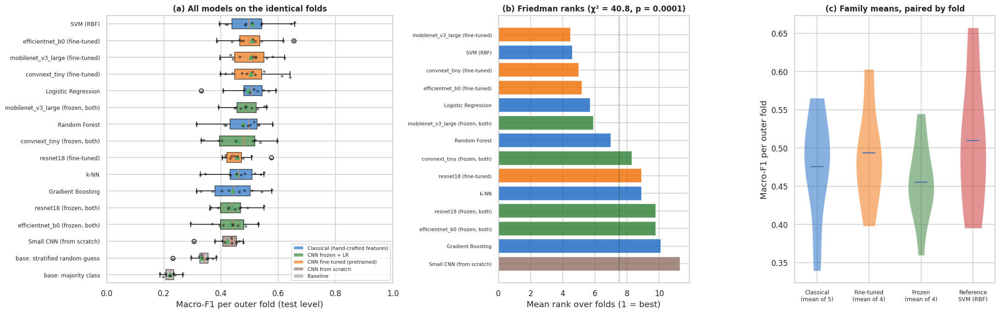

**Figure C1.** Unified comparison on the identical outer folds: (a) fold-wise macro-F1 of every model (colour = family; dots = folds), (b) Friedman mean ranks, (c) fold-wise family means and the reference model.

In [69]:
use_scope('C')
TAB_B_ = SCOPE_PATH['B'] / 'tables'; TAB_A_ = SCOPE_PATH['A'] / 'tables'; TAB_S_ = SCOPE_PATH['S'] / 'tables'
TFc = pd.read_csv(TAB_B_ / 'fold_metrics_all_models_test_level.csv')
TSc = pd.read_csv(TAB_B_ / 'fold_metrics_all_models_sample_level.csv')
BASEc = [m for m in TFc['Model'].unique() if m.startswith('Baseline')]
def family_of_model(m):
    if m.startswith('Baseline'): return 'Baseline'
    if m.endswith('(frozen, both)'): return 'CNN frozen + LR'
    if m.endswith('(fine-tuned)'): return 'CNN fine-tuned (pretrained)'
    if m.startswith('Small CNN'): return 'CNN from scratch'
    return 'Classical (hand-crafted features)'
FAMc = {m: family_of_model(m) for m in TFc['Model'].unique()}
CLASSc = [m for m in FAMc if FAMc[m].startswith('Classical')]
FROZc  = [m for m in FAMc if FAMc[m] == 'CNN frozen + LR']
FTc    = [m for m in FAMc if FAMc[m] == 'CNN fine-tuned (pretrained)']
SCRc   = [m for m in FAMc if FAMc[m] == 'CNN from scratch']
CNNc   = FROZc + FTc + SCRc
pivc  = TFc.pivot_table(index=['rep', 'fold'], columns='Model', values='F1 (macro)')
pivsc = TSc.pivot_table(index=['rep', 'fold'], columns='Model', values='F1 (macro)')
Jc = len(pivc); RATIO = 1.0 / (CFG['OUTER_FOLDS'] - 1)
REFc = pivc[CLASSc].mean().idxmax(); BEST_CNNc = pivc[CNNc].mean().idxmax(); BEST_FTc = pivc[FTc].mean().idxmax()
print(f'{Jc} outer folds | classical: {len(CLASSc)} | CNN variants: {len(CNNc)} (frozen {len(FROZc)}, fine-tuned {len(FTc)}, scratch {len(SCRc)}) | baselines: {len(BASEc)}')
print('Reference (best classical):', REFc, f'{pivc[REFc].mean():.3f} | best CNN variant:', BEST_CNNc, f'{pivc[BEST_CNNc].mean():.3f} | best fine-tuned:', BEST_FTc)

# ---------- leaderboard ----------
REC = [f'Recall {c}' for c in CLASSES]
rows = []
for m in pivc.columns:
    t = TFc[TFc.Model == m]; s_ = TSc[TSc.Model == m]
    rows.append({'Model': m, 'Family': FAMc[m], 'Macro-F1 (test level)': f'{t["F1 (macro)"].mean():.3f} ± {t["F1 (macro)"].std():.3f}',
                 'Balanced acc.': round(t['Balanced Acc'].mean(), 3), 'MCC': round(t['MCC'].mean(), 3), 'QWK': round(t['QWK'].mean(), 3),
                 'AUC (OvR)': round(t['AUC (macro OvR)'].mean(), 3), 'Recall MICRO': round(t['Recall MICRO'].mean(), 3),
                 'Macro-F1 (sample level)': round(s_['F1 (macro)'].mean(), 3), '_sort': t['F1 (macro)'].mean()})
LB = pd.DataFrame(rows).sort_values('_sort', ascending=False).drop(columns='_sort').reset_index(drop=True)
LB.insert(0, 'Rank', np.arange(1, len(LB) + 1))
save_table(LB, 'leaderboard', f'Unified leaderboard on the identical {Jc} outer folds, sorted by mean macro-F1 at test level (mean ± SD over folds); sample-level macro-F1 is secondary.', index=False)

# ---------- Friedman omnibus ----------
MODc = CLASSc + CNNc
chi_c, p_fr_c = sps.friedmanchisquare(*[pivc[m].values for m in MODc])
rk = pivc[MODc].rank(axis=1, ascending=False).mean().sort_values()
chi_s_c, p_fr_s_c = sps.friedmanchisquare(*[pivsc[m].values for m in MODc])
print(f'Friedman (test level, {len(MODc)} models): chi2 = {chi_c:.2f}, p = {p_fr_c:.3g} | (sample level): chi2 = {chi_s_c:.2f}, p = {p_fr_s_c:.3g}')
put('leaderboard.friedman_test_level', dict(chi2=chi_c, p=p_fr_c, n_models=len(MODc))); put('leaderboard.friedman_sample_level', dict(chi2=chi_s_c, p=p_fr_s_c))
put('leaderboard.mean_rank', rk.round(3).to_dict())
put('leaderboard.reference', dict(model=REFc, f1=float(pivc[REFc].mean()))); put('leaderboard.best_cnn', dict(model=BEST_CNNc, f1=float(pivc[BEST_CNNc].mean()), family=FAMc[BEST_CNNc]))
put('leaderboard.best_finetuned', dict(model=BEST_FTc, f1=float(pivc[BEST_FTc].mean())))
put('leaderboard.table', LB.to_dict(orient='records'))

# ---------- helpers for paired contrasts ----------
def holm_c(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p); q = np.empty(n)
    q[o] = np.minimum(1, np.maximum.accumulate((n - np.arange(n)) * p[o])); return q

def paired(d):
    """d = per-fold differences A - B -> dict with Wilcoxon p, Nadeau-Bengio p, 95% CI (NB), minimum detectable difference."""
    d = np.asarray(d, float); J_ = len(d)
    try: p_w = sps.wilcoxon(d, zero_method='zsplit').pvalue if (d != 0).any() else 1.0
    except ValueError: p_w = 1.0
    se = np.sqrt((1.0 / J_ + RATIO) * d.var(ddof=1) + 1e-18); tcrit = sps.t.ppf(0.975, J_ - 1)
    t_nb = d.mean() / se
    return dict(diff=d.mean(), sd_diff=d.std(ddof=1), better=int((d > 0).sum()), J=J_, p_w=p_w, p_nb=2 * sps.t.sf(abs(t_nb), J_ - 1),
                ci_lo=d.mean() - tcrit * se, ci_hi=d.mean() + tcrit * se, mdd=tcrit * se)

def contrast_table(pairs, labels):
    rows = []
    for lab_, (a, b) in zip(labels, pairs):
        r = paired(a - b)
        rows.append({'Contrast': lab_, 'Mean difference': r['diff'], '95% CI (Nadeau–Bengio)': f'{r["ci_lo"]:+.3f} … {r["ci_hi"]:+.3f}', 'Minimum detectable difference': r['mdd'],
                     'Folds A better': f'{r["better"]}/{r["J"]}', 'p (Wilcoxon)': r['p_w'], 'p (Nadeau–Bengio)': r['p_nb']})
    t = pd.DataFrame(rows)
    t['p Holm (Wilcoxon)'] = holm_c(t['p (Wilcoxon)']); t['p Holm (Nadeau–Bengio)'] = holm_c(t['p (Nadeau–Bengio)'])
    t['Significant (Holm < 0.05)'] = (t['p Holm (Wilcoxon)'] < 0.05) | (t['p Holm (Nadeau–Bengio)'] < 0.05)
    return t

# ---------- 1. family level ----------
fam_mean = pd.DataFrame({'Classical': pivc[CLASSc].mean(axis=1), 'CNN fine-tuned (pretrained)': pivc[FTc].mean(axis=1), 'CNN frozen + LR': pivc[FROZc].mean(axis=1)})
T1 = contrast_table([(fam_mean['CNN fine-tuned (pretrained)'], fam_mean['Classical']), (fam_mean['CNN frozen + LR'], fam_mean['Classical']),
                     (fam_mean['CNN fine-tuned (pretrained)'], fam_mean['CNN frozen + LR'])],
                    ['Fine-tuned CNNs (mean of 4) − Classical (mean of 5)', 'Frozen-embedding CNNs (mean of 4) − Classical (mean of 5)', 'Fine-tuned (mean of 4) − Frozen (mean of 4)'])
save_table(T1.round(4), 'contrast_family_level', 'Family-level contrasts: fold-wise mean macro-F1 of a family of models, paired by outer fold; Wilcoxon and Nadeau–Bengio tests, Holm-corrected over the 3 contrasts. The minimum detectable difference is the smallest mean difference that the Nadeau–Bengio test could call significant given the observed fold-to-fold variability.', index=False)
# ---------- 2. best vs best ----------
T2 = contrast_table([(pivc[BEST_CNNc], pivc[REFc]), (pivc[BEST_FTc], pivc[REFc])], [f'{BEST_CNNc} − {REFc}', f'{BEST_FTc} − {REFc}'])
save_table(T2.round(4), 'contrast_best_vs_reference', 'Best CNN-based model and best fine-tuned model against the reference (best classical model), paired by outer fold. The 95 % interval and the minimum detectable difference show what this design can and cannot resolve.', index=False)
# ---------- 3. fine-tuning effect ----------
bb = [m.replace(' (fine-tuned)', '') for m in FTc]
T3 = contrast_table([(pivc[f'{b} (fine-tuned)'], pivc[f'{b} (frozen, both)']) for b in bb if f'{b} (frozen, both)' in pivc.columns], [f'{b}: fine-tuned − frozen' for b in bb if f'{b} (frozen, both)' in pivc.columns])
save_table(T3.round(4), 'contrast_finetuning_effect', 'Effect of fine-tuning: each backbone fine-tuned vs the same backbone frozen (same folds), Holm-corrected over the backbones.', index=False)
# ---------- 4. pre-training effect ----------
if SCRc:
    T4 = contrast_table([(pivc[m], pivc[SCRc[0]]) for m in FTc], [f'{m.replace(" (fine-tuned)", "")}: pretrained − scratch' for m in FTc])
    save_table(T4.round(4), 'contrast_pretraining_effect', 'Effect of ImageNet pre-training: each pretrained fine-tuned backbone vs the small CNN trained from scratch (same folds), Holm-corrected.', index=False)
# ---------- decision rule on all single-model contrasts vs the reference ----------
rows = []
for m in CNNc:
    r = paired(pivc[m] - pivc[REFc]); rows.append({'CNN-based model': m, 'Mean difference (CNN − reference)': r['diff'], 'p (Wilcoxon)': r['p_w'], 'p (Nadeau–Bengio)': r['p_nb']})
TD = pd.DataFrame(rows); TD['p Holm (Wilcoxon)'] = holm_c(TD['p (Wilcoxon)']); TD['p Holm (Nadeau–Bengio)'] = holm_c(TD['p (Nadeau–Bengio)'])
TD['CNN significantly better'] = (TD['Mean difference (CNN − reference)'] > 0) & ((TD['p Holm (Wilcoxon)'] < 0.05) | (TD['p Holm (Nadeau–Bengio)'] < 0.05))
TD['CNN significantly worse'] = (TD['Mean difference (CNN − reference)'] < 0) & ((TD['p Holm (Wilcoxon)'] < 0.05) | (TD['p Holm (Nadeau–Bengio)'] < 0.05))
RULE_MET_C = bool(TD['CNN significantly better'].any())
save_table(TD.round(4), 'decision_rule_all_cnn_vs_reference', f'Pre-specified decision rule: every CNN-based model against the reference ({REFc}); Holm-corrected over {len(TD)} contrasts. The CNN replaces the classical pipeline only if at least one CNN is both better on average and significantly better.', index=False)
put('contrasts.family_level', T1.round(5).to_dict(orient='records')); put('contrasts.best_vs_reference', T2.round(5).to_dict(orient='records'))
put('contrasts.finetuning_effect', T3.round(5).to_dict(orient='records')); put('contrasts.pretraining_effect', T4.round(5).to_dict(orient='records') if SCRc else [])
put('contrasts.decision_rule_table', TD.round(5).to_dict(orient='records'))
put('decision_rule', dict(cnn_replaces_classical=RULE_MET_C, any_cnn_significantly_worse=bool(TD['CNN significantly worse'].any()), reference=REFc, best_cnn=BEST_CNNc))
print('PRE-SPECIFIED DECISION RULE -> a CNN replaces the classical pipeline:', RULE_MET_C)
print('CNN variants significantly WORSE than the reference:', TD.loc[TD['CNN significantly worse'], 'CNN-based model'].tolist())

# ---------- figure ----------
fam_col = {'Classical (hand-crafted features)': '#1565C0', 'CNN frozen + LR': '#2E7D32', 'CNN fine-tuned (pretrained)': '#EF6C00', 'CNN from scratch': '#8D6E63', 'Baseline': '#9E9E9E'}
order = pivc.mean().sort_values(ascending=False).index.tolist()
fig, axs = plt.subplots(1, 3, figsize=(20, 6.4), gridspec_kw={'width_ratios': [1.5, 1, 1.05]})
bxs = [pivc[m].values for m in order]
bp = axs[0].boxplot(bxs, vert=False, showmeans=True, patch_artist=True, widths=.6)
for patch, m in zip(bp['boxes'], order): patch.set_facecolor(fam_col[FAMc[m]]); patch.set_alpha(.65)
for i, v in enumerate(bxs): axs[0].scatter(v, np.random.default_rng(i).normal(i + 1, .06, len(v)), c='k', s=8, alpha=.45, zorder=3)
axs[0].set_yticks(range(1, len(order) + 1)); axs[0].set_yticklabels([m.replace('Baseline: ', 'base: ') for m in order], fontsize=8); axs[0].invert_yaxis(); axs[0].set_xlim(0, 1)
axs[0].set_xlabel('Macro-F1 per outer fold (test level)'); axs[0].set_title('(a) All models on the identical folds')
axs[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=c, alpha=.65) for c in fam_col.values()], labels=list(fam_col), fontsize=7, loc='lower right')
rkp = rk.reindex(rk.index)[::-1]
axs[1].barh(range(len(rkp)), rkp.values, color=[fam_col[FAMc[m]] for m in rkp.index], alpha=.8)
axs[1].set_yticks(range(len(rkp))); axs[1].set_yticklabels([m for m in rkp.index], fontsize=7); axs[1].axvline((len(MODc) + 1) / 2, c='k', ls=':', lw=1)
axs[1].set_xlabel('Mean rank over folds (1 = best)'); axs[1].set_title(f'(b) Friedman ranks (χ² = {chi_c:.1f}, p = {p_fr_c:.2g})')
fm = fam_mean.copy(); fm['Reference'] = pivc[REFc]
vp = axs[2].violinplot([fm[c].values for c in fm.columns], showmeans=True, showextrema=False)
for b_, c_ in zip(vp['bodies'], ['#1565C0', '#EF6C00', '#2E7D32', '#C62828']): b_.set_facecolor(c_); b_.set_alpha(.5)
axs[2].set_xticks(range(1, len(fm.columns) + 1)); axs[2].set_xticklabels(['Classical\n(mean of 5)', 'Fine-tuned\n(mean of 4)', 'Frozen\n(mean of 4)', f'Reference\n{REFc}'], fontsize=8)
axs[2].set_ylabel('Macro-F1 per outer fold'); axs[2].set_title('(c) Family means, paired by fold')
fig.tight_layout()
save_fig(fig, 'leaderboard', 'Unified comparison on the identical outer folds: (a) fold-wise macro-F1 of every model (colour = family; dots = folds), (b) Friedman mean ranks, (c) fold-wise family means and the reference model.')
stage_done('28 leaderboard and contrasts')

# Stage 29 · Do the Two Pipelines Make the Same Errors? Error Overlap and Class-Boundary Analysis

**Purpose.** Equal average scores can hide very different behaviour. If the best classical model and the best CNN err on *different* tests, combining them could help; if they err on the *same* tests, those tests probably carry too little information (or too much measurement noise) for **any** model. We also ask whether errors concentrate near the class boundaries (UACR 30 and 300 mg/g), where a laboratory value of, say, 28 vs 32 mg/g is a matter of measurement noise rather than of class.

**Method.** Pooled out-of-fold predictions of repeat 1 (every test predicted exactly once, by a model that never saw its sample): (i) a 2 × 2 table *classical correct / CNN correct*; (ii) exact McNemar test on the discordant tests (descriptive — tests of one sample are not independent) and a **cluster bootstrap over samples** for the difference in accuracy; (iii) the same at *sample level* (probabilities of the repeats averaged); (iv) the **error severity** (adjacent-class error vs NORMAL↔MACRO two-step error); (v) accuracy by distance of the laboratory UACR to the nearest class boundary (on a log scale, in tertiles).

Pooled OOF (repeat 1) macro-F1: reference 0.511 | efficientnet_b0 (fine-tuned) 0.535
Test level: both correct 208, only classical 69, only CNN 67, both wrong 134 | McNemar exact p = 0.932 | agreement of predicted classes (kappa) = 0.47 | oracle accuracy = 0.720
Sample level: both correct 49, only classical 12, only CNN 14, both wrong 25 | McNemar exact p = 0.845


**Table C7.** Error overlap between the reference classical model and the best CNN-based model (pooled out-of-fold predictions, repeat 1). Exact McNemar p = 0.932 (test level), 0.845 (sample level; descriptive). Cluster-bootstrap 95 % CI of the accuracy difference (CNN − classical): -0.074 … +0.061.

,Test level (n=478),Sample level (n=100)
Both correct,208,49
Only classical (SVM (RBF)) correct,69,12
Only CNN (efficientnet_b0 (fine-tuned)) correct,67,14
Both wrong,134,25


**Table C8.** Error overlap by true class (test level, repeat 1).

,True class,Tests,Both correct,Only classical,Only CNN,Both wrong
0,NORMAL,121,55,10,28,28
1,MICRO,118,17,11,17,73
2,MACRO,239,136,48,22,33


**Table C9.** Error severity (test level, repeat 1): adjacent-class errors vs two-step errors (NORMAL ↔ MACRO), which are the clinically most serious.

,errors,adjacent,two_step,two_step_share
SVM (RBF),201.0,144.0,57.0,0.284
efficientnet_b0 (fine-tuned),203.0,168.0,35.0,0.172


**Table C10.** Sample-level accuracy (repeat 1) by distance of the laboratory UACR to the nearest class boundary (30 or 300 mg/g, log scale, tertiles of the 100 samples).

,n,classical,cnn,median |log10 distance|
bin,,,,
near a boundary,33,0.455,0.515,0.158
intermediate,33,0.576,0.636,0.399
far from a boundary,34,0.794,0.735,0.851


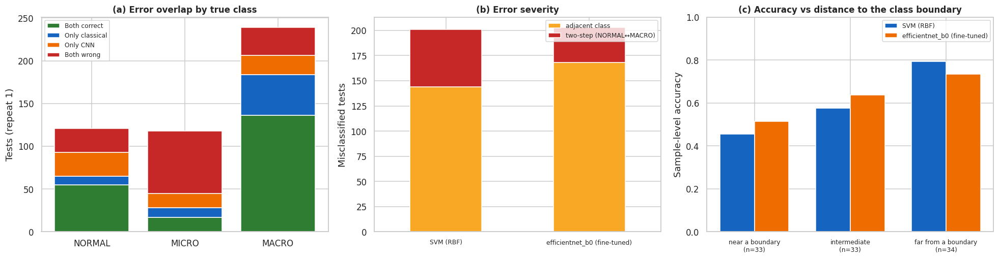

**Figure C2.** Do the two pipelines err on the same tests? (a) overlap of correct/incorrect predictions by true class, (b) adjacent vs two-step errors, (c) sample-level accuracy by distance of the laboratory UACR to the nearest class boundary.

In [70]:
# ---------- load the out-of-fold predictions of the reference and of the best CNN (repeat 1) ----------
dfc_ = pd.read_csv(TAB_S_ / 'cleaned_dataset_all_features.csv', usecols=lambda c: c in ('sample', 'y', 'label', 'lux', 'uacr'))
Nc = len(dfc_); yc = dfc_['y'].values.astype(int); gc = dfc_['sample'].values.astype(int)
nm_pk = sorted((SCOPE_PATH['A'] / 'cache').glob('nested_main_*.pkl'), key=lambda p: p.stat().st_mtime)
assert nm_pk, 'Path-A out-of-fold cache (A_ML/cache/nested_main_*.pkl) not found - run Part II first.'
NR_ = pd.read_pickle(nm_pk[-1])
OOF_REFc = np.zeros((Nc, 3)); _seen = np.zeros(Nc, int)
for r in NR_:
    if r['model'] == REFc and r['rep'] == 0: OOF_REFc[r['tei']] = r['proba']; _seen[r['tei']] += 1
assert (_seen == 1).all(), 'reference OOF incomplete'
PKc = pd.read_pickle(SCOPE_PATH['B'] / 'cache' / 'oof_cnn_models.pkl')
RES_ALL_CNN = {**PKc['RES_A'], **PKc['RES_B']}
OOF_CNNc = np.zeros((Nc, 3)); _seen = np.zeros(Nc, int)
for r in RES_ALL_CNN[BEST_CNNc]:
    if r['rep'] == 0: OOF_CNNc[r['tei']] = r['proba']; _seen[r['tei']] += 1
assert (_seen == 1).all(), 'CNN OOF incomplete'
pr_ref, pr_cnn = OOF_REFc.argmax(1), OOF_CNNc.argmax(1)
ok_ref, ok_cnn = pr_ref == yc, pr_cnn == yc
print(f'Pooled OOF (repeat 1) macro-F1: reference {f1_score(yc, pr_ref, average="macro"):.3f} | {BEST_CNNc} {f1_score(yc, pr_cnn, average="macro"):.3f}')

def overlap(ok_a, ok_b):
    return dict(both=int((ok_a & ok_b).sum()), only_a=int((ok_a & ~ok_b).sum()), only_b=int((~ok_a & ok_b).sum()), neither=int((~ok_a & ~ok_b).sum()))
ov = overlap(ok_ref, ok_cnn)
disc = ov['only_a'] + ov['only_b']
p_mcn = sps.binomtest(ov['only_a'], disc, 0.5).pvalue if disc > 0 else 1.0
kappa_pred = cohen_kappa_score(pr_ref, pr_cnn)
oracle_acc = float((ok_ref | ok_cnn).mean())
print(f'Test level: both correct {ov["both"]}, only classical {ov["only_a"]}, only CNN {ov["only_b"]}, both wrong {ov["neither"]} | McNemar exact p = {p_mcn:.3f} | agreement of predicted classes (kappa) = {kappa_pred:.2f} | oracle accuracy = {oracle_acc:.3f}')

# sample level
def to_samp(P, y, g):
    d = pd.DataFrame(P, columns=[0, 1, 2]); d['g'] = g; d['y'] = y
    a = d.groupby('g').agg({0: 'mean', 1: 'mean', 2: 'mean', 'y': 'first'}); return a['y'].values, a[[0, 1, 2]].values, a.index.values
ys_c, Ps_ref, sid = to_samp(OOF_REFc, yc, gc); _, Ps_cnn, _ = to_samp(OOF_CNNc, yc, gc)
oks_ref, oks_cnn = Ps_ref.argmax(1) == ys_c, Ps_cnn.argmax(1) == ys_c
ovs = overlap(oks_ref, oks_cnn); discs = ovs['only_a'] + ovs['only_b']
p_mcn_s = sps.binomtest(ovs['only_a'], discs, 0.5).pvalue if discs > 0 else 1.0
print(f'Sample level: both correct {ovs["both"]}, only classical {ovs["only_a"]}, only CNN {ovs["only_b"]}, both wrong {ovs["neither"]} | McNemar exact p = {p_mcn_s:.3f}')

# cluster bootstrap of the accuracy difference (samples resampled)
rng_c = np.random.default_rng(SEED); uq = np.unique(gc); idx_ = {s: np.where(gc == s)[0] for s in uq}; bd, bo = [], []
for _ in range(CFG['BOOT_N']):
    ii = np.concatenate([idx_[s] for s in rng_c.choice(uq, len(uq), replace=True)])
    bd.append(ok_cnn[ii].mean() - ok_ref[ii].mean()); bo.append((ok_ref[ii] | ok_cnn[ii]).mean())
ci_d = np.percentile(bd, [2.5, 97.5]); ci_o = np.percentile(bo, [2.5, 97.5])

tab_ov = pd.DataFrame({'Test level (n=%d)' % Nc: ov, 'Sample level (n=%d)' % len(sid): ovs}).rename(index={'both': 'Both correct', 'only_a': f'Only classical ({REFc}) correct', 'only_b': f'Only CNN ({BEST_CNNc}) correct', 'neither': 'Both wrong'})
save_table(tab_ov, 'error_overlap', f'Error overlap between the reference classical model and the best CNN-based model (pooled out-of-fold predictions, repeat 1). Exact McNemar p = {p_mcn:.3f} (test level), {p_mcn_s:.3f} (sample level; descriptive). Cluster-bootstrap 95 % CI of the accuracy difference (CNN − classical): {ci_d[0]:+.3f} … {ci_d[1]:+.3f}.')

# per true class overlap
rows = []
for k, c in enumerate(CLASSES):
    m_ = yc == k; o = overlap(ok_ref[m_], ok_cnn[m_])
    rows.append({'True class': c, 'Tests': int(m_.sum()), 'Both correct': o['both'], 'Only classical': o['only_a'], 'Only CNN': o['only_b'], 'Both wrong': o['neither']})
tab_ovc = pd.DataFrame(rows)
save_table(tab_ovc, 'error_overlap_by_class', 'Error overlap by true class (test level, repeat 1).', index=False)

# error severity: adjacent vs two-step
def severity(y, pr):
    err = pr != y; two = np.abs(pr - y) == 2
    return dict(errors=int(err.sum()), adjacent=int((err & ~two).sum()), two_step=int(two.sum()), two_step_share=float(two.sum() / max(err.sum(), 1)))
sev = pd.DataFrame({REFc: severity(yc, pr_ref), BEST_CNNc: severity(yc, pr_cnn)}).T
save_table(sev.round(3), 'error_severity', 'Error severity (test level, repeat 1): adjacent-class errors vs two-step errors (NORMAL ↔ MACRO), which are the clinically most serious.')

# boundary analysis (laboratory UACR; sample level)
ux = dfc_.groupby('sample')['uacr'].first().reindex(sid).values.astype(float)
if np.isfinite(ux).sum() >= 20:
    dist = np.minimum(np.abs(np.log10(np.clip(ux, 0.1, None) / 30.0)), np.abs(np.log10(np.clip(ux, 0.1, None) / 300.0)))
    ter = pd.qcut(pd.Series(dist), 3, labels=['near a boundary', 'intermediate', 'far from a boundary'])
    bt_ = pd.DataFrame({'bin': ter, 'ref': oks_ref, 'cnn': oks_cnn}).groupby('bin', observed=True).agg(n=('ref', 'size'), classical=('ref', 'mean'), cnn=('cnn', 'mean'))
    bt_['median |log10 distance|'] = pd.Series(dist).groupby(ter, observed=True).median()
    save_table(bt_.round(3), 'accuracy_by_boundary_distance', 'Sample-level accuracy (repeat 1) by distance of the laboratory UACR to the nearest class boundary (30 or 300 mg/g, log scale, tertiles of the 100 samples).')
    rho_b = {k: float(sps.spearmanr(dist, v.astype(float))[0]) for k, v in (('classical', oks_ref), ('cnn', oks_cnn))}
else:
    bt_ = None; rho_b = {}; dist = None
    print('Laboratory UACR not available -> boundary analysis skipped.')

fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))
bot = np.zeros(3)
for lab_, col in (('Both correct', '#2E7D32'), ('Only classical', '#1565C0'), ('Only CNN', '#EF6C00'), ('Both wrong', '#C62828')):
    axs[0].bar(tab_ovc['True class'], tab_ovc[lab_], bottom=bot, color=col, label=lab_); bot += tab_ovc[lab_].values
axs[0].set_ylabel('Tests (repeat 1)'); axs[0].set_title('(a) Error overlap by true class'); axs[0].legend(fontsize=8)
sv = sev[['adjacent', 'two_step']]
sv.plot(kind='bar', stacked=True, ax=axs[1], color=['#F9A825', '#C62828'], rot=0); axs[1].set_xticklabels([REFc, BEST_CNNc], fontsize=8)
axs[1].set_ylabel('Misclassified tests'); axs[1].set_title('(b) Error severity'); axs[1].legend(['adjacent class', 'two-step (NORMAL↔MACRO)'], fontsize=8)
if bt_ is not None:
    xx = np.arange(len(bt_)); axs[2].bar(xx - .18, bt_['classical'], .36, color='#1565C0', label=REFc); axs[2].bar(xx + .18, bt_['cnn'], .36, color='#EF6C00', label=BEST_CNNc)
    axs[2].set_xticks(xx); axs[2].set_xticklabels([f'{i}\n(n={int(r.n)})' for i, r in bt_.iterrows()], fontsize=8); axs[2].set_ylim(0, 1); axs[2].set_ylabel('Sample-level accuracy'); axs[2].legend(fontsize=8)
axs[2].set_title('(c) Accuracy vs distance to the class boundary')
fig.tight_layout()
save_fig(fig, 'error_overlap_boundary', 'Do the two pipelines err on the same tests? (a) overlap of correct/incorrect predictions by true class, (b) adjacent vs two-step errors, (c) sample-level accuracy by distance of the laboratory UACR to the nearest class boundary.')
put('error_overlap', dict(test_level=ov, sample_level=ovs, mcnemar_p_test=float(p_mcn), mcnemar_p_sample=float(p_mcn_s), kappa_predictions=float(kappa_pred), oracle_accuracy=oracle_acc,
                          oracle_accuracy_ci=[float(ci_o[0]), float(ci_o[1])], acc_diff_cnn_minus_ref=float(ok_cnn.mean() - ok_ref.mean()), acc_diff_ci=[float(ci_d[0]), float(ci_d[1])],
                          severity=sev.round(4).to_dict(orient='index'), boundary_table=None if bt_ is None else bt_.round(4).reset_index().to_dict(orient='records'), spearman_distance_correct=rho_b))
stage_done('29 error overlap')

# Stage 30 · Synthesis and the Decision

**Purpose.** State — mechanically, from the saved numbers, so that no sentence can claim more than the evidence supports — what the integrated experiment shows. The same text is saved as `C_Comparison/report/Findings_Summary_Integrated.md`, together with `report_numbers_all.json` (every number of every Part) and a map of all output files.

**How to read the synthesis.** (1) The pre-specified decision rule is applied as written. (2) “Not significant” is reported as *inconclusive*, never as equivalence, and the minimum detectable difference of the design is quoted. (3) Sample-level numbers are secondary. (4) Anything that was not tested is labelled as such.

In [71]:
b2 = T2.iloc[0]; f1_ref = pivc[REFc].mean(); f1_cnn = pivc[BEST_CNNc].mean()
fam1 = T1.set_index('Contrast')
sig_fam = [c for c, r in fam1.iterrows() if r['Significant (Holm < 0.05)']]
worse = TD.loc[TD['CNN significantly worse'], 'CNN-based model'].tolist()
sl_ref = pivsc[REFc].mean(); sl_cnn = pivsc[BEST_CNNc].mean()
lines = ['# Integrated findings summary (generated automatically; every number comes from this run)', '']
lines.append(f'- **Design.** {Nc} image pairs from {len(sid)} samples; one common analysis set and one fold plan ({CFG["OUTER_FOLDS"]} folds × {CFG["OUTER_REPEATS_CNN"]} repeat(s), grouped by sample) for both pipelines; primary metric macro-F1 at test level.')
base_txt = ', '.join(f"{b.replace('Baseline: ', 'base: ')} {pivc[b].mean():.3f}" for b in BASEc)
lines.append(f'- **Path A (hand-crafted features + machine learning).** Best classical model: {REFc}, macro-F1 {f1_ref:.3f} ± {pivc[REFc].std():.3f}; baselines {base_txt}.')
lines.append(f'- **Path B (CNN).** Best CNN-based variant: {BEST_CNNc} ({FAMc[BEST_CNNc]}), macro-F1 {f1_cnn:.3f} ± {pivc[BEST_CNNc].std():.3f}; best fine-tuned: {BEST_FTc} ({pivc[BEST_FTc].mean():.3f}).')
lines.append(f'- **Pre-specified decision rule.** A CNN replaces the classical pipeline only if it is higher on average and significantly better after Holm correction → **{"MET" if RULE_MET_C else "NOT MET"}**. Best CNN − reference = {b2["Mean difference"]:+.3f} (95 % CI {b2["95% CI (Nadeau–Bengio)"]}; Holm p Wilcoxon {b2["p Holm (Wilcoxon)"]:.3f}, Nadeau–Bengio {b2["p Holm (Nadeau–Bengio)"]:.3f}). The design cannot detect differences smaller than ≈ {b2["Minimum detectable difference"]:.3f} macro-F1.')
lines.append(f'- **Omnibus.** Friedman over {len(MODc)} models: χ² = {chi_c:.1f}, p = {p_fr_c:.3g} (test level); sample level p = {p_fr_s_c:.3g}.')
lines.append('- **Families.** ' + '; '.join(f'{c}: {r["Mean difference"]:+.3f} (Holm p = {min(r["p Holm (Wilcoxon)"], r["p Holm (Nadeau–Bengio)"]):.3f})' for c, r in fam1.iterrows()) + '.' + (f' Significant: {sig_fam}.' if sig_fam else ' None is significant after correction.'))
lines.append('- **Fine-tuning vs frozen embeddings (per backbone).** ' + '; '.join(f'{r["Contrast"].split(":")[0]} {r["Mean difference"]:+.3f}' for _, r in T3.iterrows()) + f'. Significant after Holm: {T3.loc[T3["Significant (Holm < 0.05)"], "Contrast"].tolist() or "none"}.')
if SCRc: lines.append('- **Pre-training vs scratch.** ' + '; '.join(f'{r["Contrast"].split(":")[0]} {r["Mean difference"]:+.3f}' for _, r in T4.iterrows()) + f'. Significant after Holm: {T4.loc[T4["Significant (Holm < 0.05)"], "Contrast"].tolist() or "none"}.')
if worse: lines.append(f'- **Significantly worse than the reference:** {worse}.')
lines.append(f'- **Sample level (secondary, not tested).** Reference {sl_ref:.3f} vs best CNN {sl_cnn:.3f} macro-F1 when the repeats of a sample are averaged.')
lines.append(f'- **Error overlap.** Of {Nc} tests: both correct {ov["both"]}, only classical {ov["only_a"]}, only CNN {ov["only_b"]}, both wrong {ov["neither"]}; agreement of predicted classes κ = {kappa_pred:.2f}; accuracy difference (CNN − classical) {ok_cnn.mean() - ok_ref.mean():+.3f} (cluster-bootstrap 95 % CI {ci_d[0]:+.3f} … {ci_d[1]:+.3f}); an oracle that always picks the right model would reach {oracle_acc:.3f} (CI {ci_o[0]:.3f} … {ci_o[1]:.3f}). Two-step errors: classical {sev.loc[REFc, "two_step_share"]:.0%}, CNN {sev.loc[BEST_CNNc, "two_step_share"]:.0%} of errors.')
if bt_ is not None: lines.append('- **Class-boundary effect.** Sample-level accuracy (classical / CNN) near, intermediate, far from a boundary: ' + '; '.join(f'{i}: {r.classical:.2f} / {r.cnn:.2f} (n={int(r.n)})' for i, r in bt_.iterrows()) + '.')
lines += ['', f'**What the evidence supports.** The pre-specified rule decides which pipeline is preferred; a non-significant difference between the pipelines means *inconclusive*, not *equal*. With ≈ {len(sid)} independent samples and {Jc} overlapping outer folds, differences below the minimum detectable difference quoted above cannot be resolved. A larger and more diverse sample set (more samples per class, several batches/devices) would be needed to separate pipelines whose scores differ by a few hundredths of macro-F1.',
          '', f'**Limits.** One dataset, one acquisition set-up; the CNN recipe was fixed in advance, not tuned (the classical models were tuned in inner CV, so tuning effort differs between the paths); the best of {len(CNNc)} CNN variants is compared with the best of five classical models (winner’s curse affects both sides); fold-wise tests are indicative because folds overlap; Grad-CAM and perturbation checks (Stage 25) probe reliance on illumination/edge cues; their findings are reported there, not here.']
SUMMARY_MD = '\n'.join(lines)
(REPORT_DIR / 'Findings_Summary_Integrated.md').write_text(SUMMARY_MD, encoding='utf-8')
display(Markdown(SUMMARY_MD))

# ---------- file map of the whole experiment ----------
readme = f"""# {OUT_ROOT_NAME} — map of the integrated experiment

| Folder | Content |
|---|---|
| `0_Shared/` | Part I: inventory, labels, merge, ROI module (`model/uacr_features.py`), descriptors, EDA, cleansing, **common analysis set** (`tables/cleaned_dataset_all_features.csv`) and **fold plan** (`tables/fold_plan_test_indices.csv`), workflow figure (`figures/Workflow_two_pipelines.png`) |
| `A_ML/` | Part II (Path A): audit, selection, five models, nested CV, analysis; `model/` = deployment bundle; `report/report_numbers.json` |
| `B_CNN/` | Part III (Path B): embeddings, fine-tuning, evaluation, Grad-CAM; `tables/fold_metrics_all_models_*.csv`; `report/report_numbers.json` |
| `C_Comparison/` | Part IV: leaderboard, contrasts, error overlap, `report/Findings_Summary_Integrated.md` |
| `report_numbers_all.json` | every quoted number of every Part (keys S, A, B, C) |

Figures/tables carry the scope letter: *Figure A7* = `A_ML/figures/FigA07_*.png`. Written by `UACR_Integrated_Pipeline.ipynb`; configuration in each `report/report_numbers.json` (key `config`).
"""
(TEMP_ROOT / 'README_outputs.md').write_text(readme, encoding='utf-8')
for _s in SCOPES:
    pd.DataFrame(REG[_s]['fig']).to_csv(SCOPE_PATH[_s] / 'report' / 'Figure_List.csv', index=False, encoding='utf-8-sig')
    pd.DataFrame(REG[_s]['tab']).to_csv(SCOPE_PATH[_s] / 'report' / 'Table_List.csv', index=False, encoding='utf-8-sig')
rows = [{'file': str(p.relative_to(TEMP_ROOT)), 'MB': round(p.stat().st_size / 1e6, 3)} for p in sorted(TEMP_ROOT.rglob('*')) if p.is_file() and 'cache' not in p.parts]
pd.DataFrame(rows).to_csv(TEMP_ROOT / 'file_manifest.csv', index=False)
stage_done('30 synthesis'); sync_to_drive()
print('Total notebook time: %.1f min' % ((time.time() - T_NOTEBOOK_START) / 60), '| files (without cache):', len(rows))

# Integrated findings summary (generated automatically; every number comes from this run)

- **Design.** 478 image pairs from 100 samples; one common analysis set and one fold plan (5 folds × 2 repeat(s), grouped by sample) for both pipelines; primary metric macro-F1 at test level.
- **Path A (hand-crafted features + machine learning).** Best classical model: SVM (RBF), macro-F1 0.510 ± 0.090; baselines base: majority class 0.221, base: stratified random guess 0.332.
- **Path B (CNN).** Best CNN-based variant: efficientnet_b0 (fine-tuned) (CNN fine-tuned (pretrained)), macro-F1 0.508 ± 0.081; best fine-tuned: efficientnet_b0 (fine-tuned) (0.508).
- **Pre-specified decision rule.** A CNN replaces the classical pipeline only if it is higher on average and significantly better after Holm correction → **NOT MET**. Best CNN − reference = -0.002 (95 % CI -0.083 … +0.080; Holm p Wilcoxon 1.000, Nadeau–Bengio 1.000). The design cannot detect differences smaller than ≈ 0.081 macro-F1.
- **Omnibus.** Friedman over 14 models: χ² = 40.8, p = 0.000104 (test level); sample level p = 0.161.
- **Families.** Fine-tuned CNNs (mean of 4) − Classical (mean of 5): +0.018 (Holm p = 0.375); Frozen-embedding CNNs (mean of 4) − Classical (mean of 5): -0.020 (Holm p = 0.168); Fine-tuned (mean of 4) − Frozen (mean of 4): +0.038 (Holm p = 0.012). Significant: ['Fine-tuned (mean of 4) − Frozen (mean of 4)'].
- **Fine-tuning vs frozen embeddings (per backbone).** resnet18 +0.017; efficientnet_b0 +0.073; mobilenet_v3_large +0.017; convnext_tiny +0.045. Significant after Holm: none.
- **Pre-training vs scratch.** resnet18 +0.034; efficientnet_b0 +0.086; mobilenet_v3_large +0.083; convnext_tiny +0.082. Significant after Holm: ['efficientnet_b0: pretrained − scratch', 'mobilenet_v3_large: pretrained − scratch', 'convnext_tiny: pretrained − scratch'].
- **Significantly worse than the reference:** ['Small CNN (from scratch)'].
- **Sample level (secondary, not tested).** Reference 0.502 vs best CNN 0.546 macro-F1 when the repeats of a sample are averaged.
- **Error overlap.** Of 478 tests: both correct 208, only classical 69, only CNN 67, both wrong 134; agreement of predicted classes κ = 0.47; accuracy difference (CNN − classical) -0.004 (cluster-bootstrap 95 % CI -0.074 … +0.061); an oracle that always picks the right model would reach 0.720 (CI 0.647 … 0.785). Two-step errors: classical 28%, CNN 17% of errors.
- **Class-boundary effect.** Sample-level accuracy (classical / CNN) near, intermediate, far from a boundary: near a boundary: 0.45 / 0.52 (n=33); intermediate: 0.58 / 0.64 (n=33); far from a boundary: 0.79 / 0.74 (n=34).

**What the evidence supports.** The pre-specified rule decides which pipeline is preferred; a non-significant difference between the pipelines means *inconclusive*, not *equal*. With ≈ 100 independent samples and 10 overlapping outer folds, differences below the minimum detectable difference quoted above cannot be resolved. A larger and more diverse sample set (more samples per class, several batches/devices) would be needed to separate pipelines whose scores differ by a few hundredths of macro-F1.

**Limits.** One dataset, one acquisition set-up; the CNN recipe was fixed in advance, not tuned (the classical models were tuned in inner CV, so tuning effort differs between the paths); the best of 9 CNN variants is compared with the best of five classical models (winner’s curse affects both sides); fold-wise tests are indicative because folds overlap; Grad-CAM and perturbation checks (Stage 25) probe reliance on illumination/edge cues; their findings are reported there, not here.

Results copied to Drive: data 2026/outputs (25 new/changed files)
Total notebook time: 39.6 min | files (without cache): 161
